## 1.1 Data Loading

List the contents of the Kaggle input directory to confirm the dataset is attached to the notebook.

In [1]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


Walk the input directory and list every folder that contains CSV files, to locate the dataset path.

In [2]:
import os

DATA_ROOT = "/kaggle/input"

for root, dirs, files in os.walk(DATA_ROOT):
    csv_files = [f for f in files if f.endswith(".csv")]
    if csv_files:
        print("Folder:", root)
        print("CSV files:", csv_files)

Load all 14 CSV files of the Formula 1 dataset into the `tables` dictionary (one raw DataFrame per file) and print the row and column count of each table.

In [3]:
import pandas as pd
import numpy as np
import os

# Exact Kaggle dataset path
DATA_PATH = "/kaggle/input/datasets/abdelrahmangharib7/formula-1-world-championship-1950-2024acl"

# Load all 14 tables
tables = {}

for file in sorted(os.listdir(DATA_PATH)):
    if file.endswith(".csv"):
        table_name = file.replace(".csv", "")
        tables[table_name] = pd.read_csv(
            os.path.join(DATA_PATH, file)
        )

print(f"Number of tables loaded: {len(tables)}")
print("\nTables:")
for name, df in tables.items():
    print(f"{name:25s} | rows: {len(df):>7,} | columns: {len(df.columns):>2}")

Number of tables loaded: 14

Tables:
circuits                  | rows:      77 | columns:  9
constructor_results       | rows:  12,625 | columns:  5
constructor_standings     | rows:  13,391 | columns:  7
constructors              | rows:     212 | columns:  5
driver_standings          | rows:  34,863 | columns:  7
drivers                   | rows:     861 | columns:  9
lap_times                 | rows: 589,081 | columns:  6
pit_stops                 | rows:  11,371 | columns:  7
qualifying                | rows:  10,494 | columns:  9
races                     | rows:   1,125 | columns: 18
results                   | rows:  26,759 | columns: 18
seasons                   | rows:      75 | columns:  2
sprint_results            | rows:     360 | columns: 16
status                    | rows:     139 | columns:  2


Count the literal `\N` sentinel cells in each raw table.

In [4]:
sentinel_results = []

for name, df in tables.items():
    sentinel_count = (df == r"\N").sum().sum()
    
    sentinel_results.append({
        "Table": name,
        "Sentinel \\N Count": sentinel_count
    })

sentinel_df = pd.DataFrame(sentinel_results)

sentinel_df.sort_values(
    "Sentinel \\N Count",
    ascending=False
)

,Table,Sentinel \N Count
10,results,122887
1,constructor_results,12608
8,qualifying,11600
9,races,11349
5,drivers,1559
12,sprint_results,73
4,driver_standings,0
3,constructors,0
2,constructor_standings,0
0,circuits,0


Count the real `NaN` cells in each raw table, for comparison with the `\N` sentinels above.

In [5]:
nan_results = []

for name, df in tables.items():
    nan_count = df.isna().sum().sum()
    
    nan_results.append({
        "Table": name,
        "NaN Count": nan_count
    })

nan_df = pd.DataFrame(nan_results)

nan_df.sort_values(
    "NaN Count",
    ascending=False
)

,Table,NaN Count
8,qualifying,68
0,circuits,0
2,constructor_standings,0
3,constructors,0
4,driver_standings,0
1,constructor_results,0
5,drivers,0
6,lap_times,0
7,pit_stops,0
9,races,0


Column-level missing-value audit: for every column with missing information, report the `NaN` count, the `\N` count and the total.

In [6]:
# Column-level missing-value audit
# We check both actual NaN values and the literal \N sentinel.

missing_audit = []

for name, df in tables.items():
    for column in df.columns:
        
        nan_count = df[column].isna().sum()
        sentinel_count = (df[column] == r"\N").sum()
        
        if nan_count > 0 or sentinel_count > 0:
            missing_audit.append({
                "Table": name,
                "Column": column,
                "NaN Count": nan_count,
                r"\N Count": sentinel_count,
                "Total Missing": nan_count + sentinel_count
            })

missing_audit_df = pd.DataFrame(missing_audit)

missing_audit_df.sort_values(
    "Total Missing",
    ascending=False
)

,Table,Column,NaN Count,\N Count,Total Missing
19,results,time,0,19079,19079
20,results,milliseconds,0,19079,19079
23,results,fastestLapTime,0,18507,18507
21,results,fastestLap,0,18507,18507
24,results,fastestLapSpeed,0,18507,18507
22,results,rank,0,18249,18249
0,constructor_results,status,0,12608,12608
18,results,position,0,10953,10953
5,qualifying,q3,46,6819,6865
4,qualifying,q2,22,4625,4647


### Initial EDA (before cleaning)

Imports and header for the exploratory analysis of the raw tables.

In [7]:
# ============================================================
# INITIAL EDA — BEFORE CLEANING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("INITIAL EXPLORATORY DATA ANALYSIS")
print("=" * 60)

INITIAL EXPLORATORY DATA ANALYSIS


Table sizes: rows and columns of each raw table, with a bar chart of the row counts.

,Table,Rows,Columns
0,circuits,77,9
1,constructor_results,12625,5
2,constructor_standings,13391,7
3,constructors,212,5
4,driver_standings,34863,7
5,drivers,861,9
6,lap_times,589081,6
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18


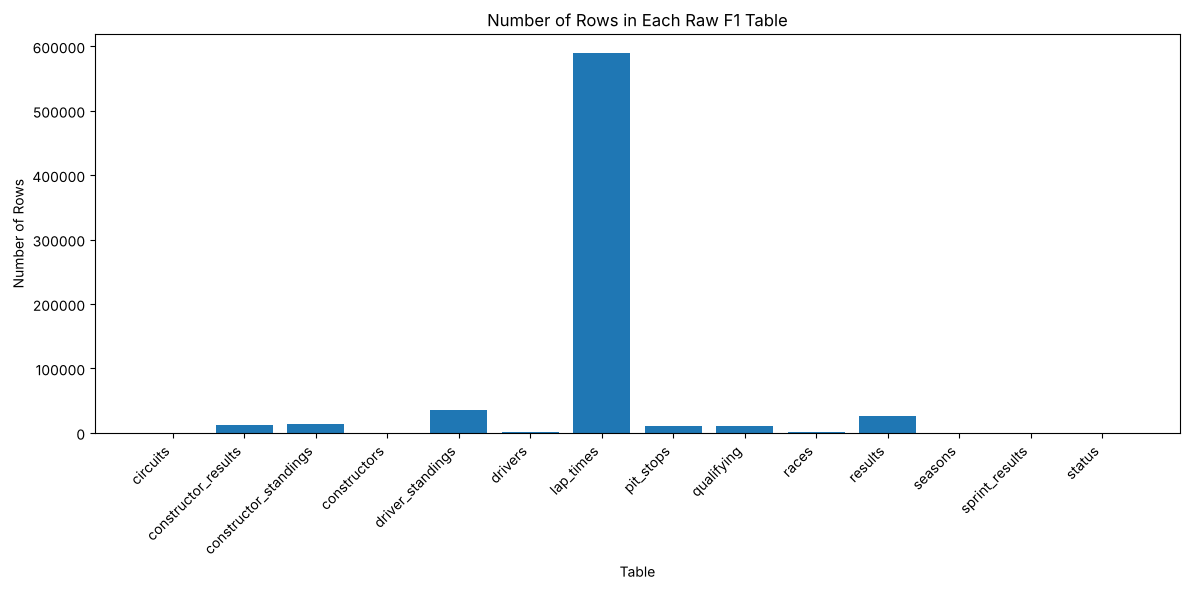

In [8]:
# Number of rows in each raw table

table_sizes = pd.DataFrame({
    "Table": list(tables.keys()),
    "Rows": [len(df) for df in tables.values()],
    "Columns": [df.shape[1] for df in tables.values()]
})

display(table_sizes)

# Visualization
plt.figure(figsize=(12, 6))

plt.bar(table_sizes["Table"], table_sizes["Rows"])

plt.title("Number of Rows in Each Raw F1 Table")
plt.xlabel("Table")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Missing information per table, split into real `NaN`s and `\N` sentinels.

In [9]:
# Count NaN and literal \N values in each table

missing_summary = []

for name, df in tables.items():

    nan_count = df.isna().sum().sum()

    sentinel_count = (
        df.astype(str)
        .apply(lambda col: col.eq(r"\N").sum())
        .sum()
    )

    missing_summary.append({
        "Table": name,
        "NaN values": nan_count,
        r"\N values": sentinel_count,
        "Total missing/sentinel": nan_count + sentinel_count
    })

missing_summary = pd.DataFrame(missing_summary)

display(missing_summary)

,Table,NaN values,\N values,Total missing/sentinel
0,circuits,0,0,0
1,constructor_results,0,12608,12608
2,constructor_standings,0,0,0
3,constructors,0,0,0
4,driver_standings,0,0,0
5,drivers,0,1559,1559
6,lap_times,0,0,0
7,pit_stops,0,0,0
8,qualifying,68,11600,11668
9,races,0,11349,11349


Chart of the `NaN` and `\N` counts per table before cleaning.

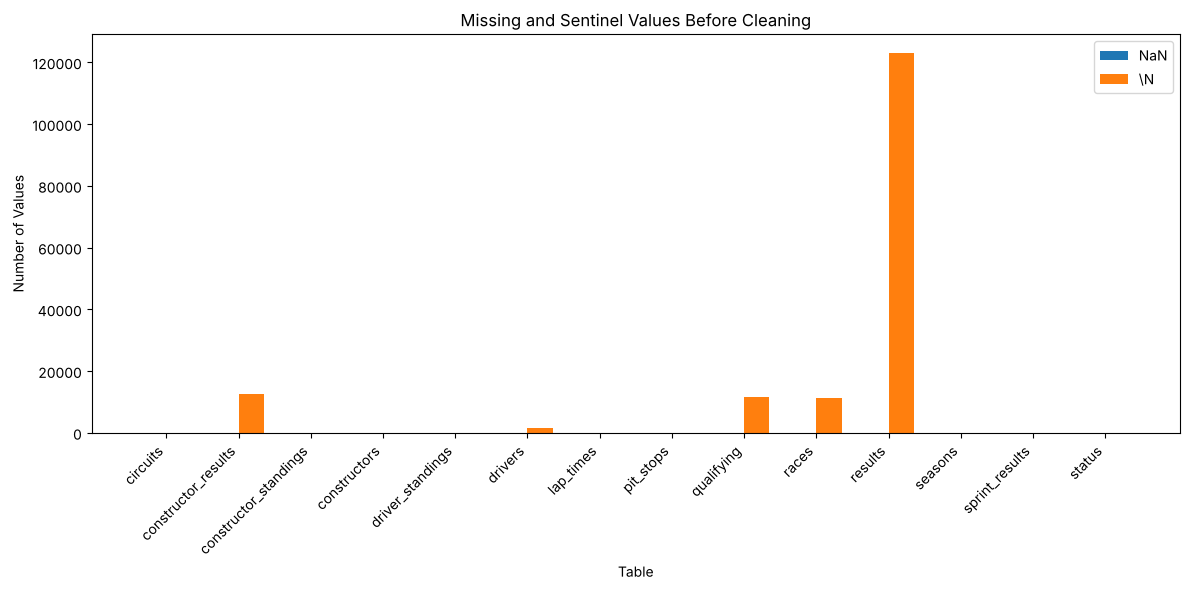

In [10]:
plt.figure(figsize=(12, 6))

x = np.arange(len(missing_summary))
width = 0.35

plt.bar(
    x - width/2,
    missing_summary["NaN values"],
    width,
    label="NaN"
)

plt.bar(
    x + width/2,
    missing_summary[r"\N values"],
    width,
    label=r"\N"
)

plt.title("Missing and Sentinel Values Before Cleaning")
plt.xlabel("Table")
plt.ylabel("Number of Values")

plt.xticks(
    x,
    missing_summary["Table"],
    rotation=45,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

Races per year, computed on a copy of `races` so the raw table is untouched.

In [11]:
# Convert only a copy for EDA purposes.
# This does NOT modify the raw tables.

races_eda = tables["races"].copy()

races_eda["year"] = pd.to_numeric(
    races_eda["year"],
    errors="coerce"
)

races_per_year = (
    races_eda
    .groupby("year")
    .size()
    .reset_index(name="number_of_races")
)

display(races_per_year.head())

,year,number_of_races
0,1950,7
1,1951,8
2,1952,8
3,1953,9
4,1954,9


Line chart of the number of F1 races per year.

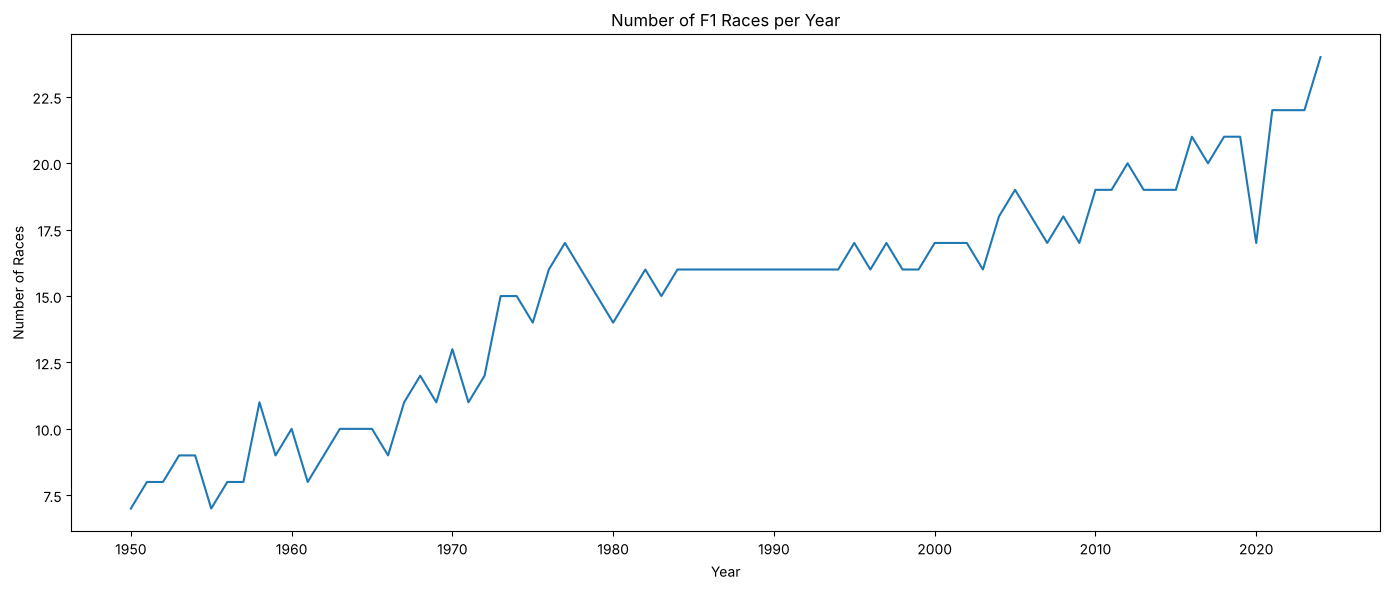

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    races_per_year["year"],
    races_per_year["number_of_races"]
)

plt.title("Number of F1 Races per Year")
plt.xlabel("Year")
plt.ylabel("Number of Races")

plt.tight_layout()
plt.show()

Distribution of starting grid positions, computed on a copy of `results`.

In [13]:
results_eda = tables["results"].copy()

results_eda["grid"] = pd.to_numeric(
    results_eda["grid"],
    errors="coerce"
)

grid_counts = (
    results_eda["grid"]
    .value_counts()
    .sort_index()
)

display(grid_counts.head(20))

grid
0     1638
1     1136
2     1125
3     1130
4     1132
5     1132
6     1125
7     1135
8     1129
9     1132
10    1130
11    1132
12    1127
13    1125
14    1120
15    1113
16    1100
17    1089
18    1050
19    1031
Name: count, dtype: int64

Histogram of the starting grid positions.

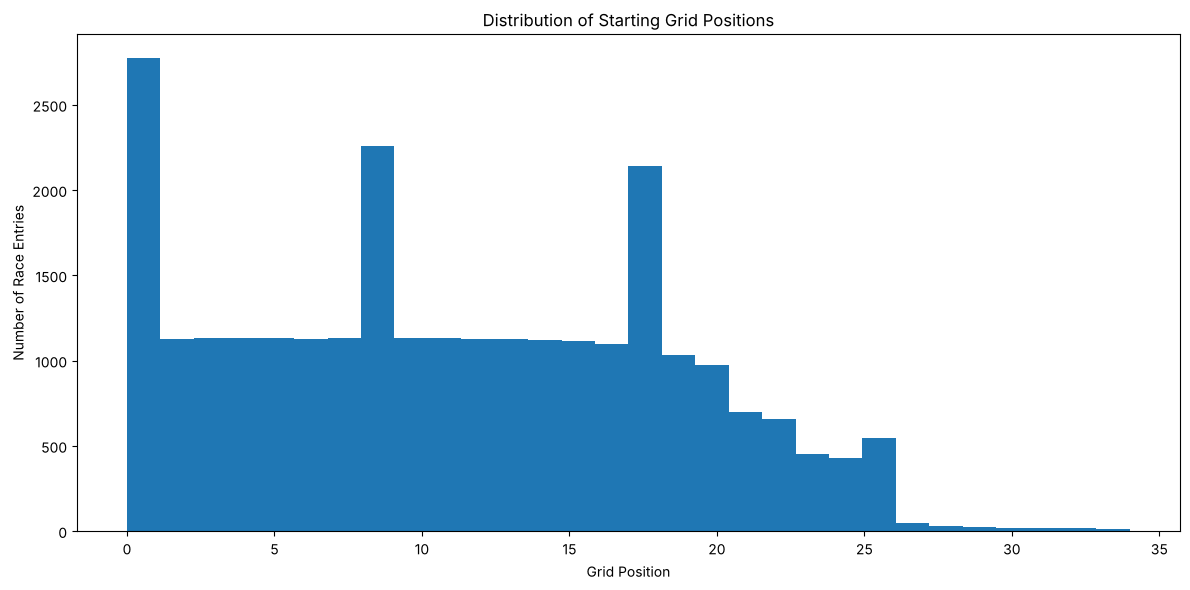

In [14]:
plt.figure(figsize=(12, 6))

plt.hist(
    results_eda["grid"].dropna(),
    bins=30
)

plt.title("Distribution of Starting Grid Positions")
plt.xlabel("Grid Position")
plt.ylabel("Number of Race Entries")

plt.tight_layout()
plt.show()

Build a provisional podium flag (`positionOrder <= 3`) on the raw results and count podium vs non-podium rows.

In [15]:
results_eda["positionOrder"] = pd.to_numeric(
    results_eda["positionOrder"],
    errors="coerce"
)

results_eda["podium"] = (
    results_eda["positionOrder"] <= 3
).astype(int)

podium_counts = (
    results_eda["podium"]
    .value_counts()
    .sort_index()
)

print("Podium distribution before duplicate resolution:")
print(podium_counts)

Podium distribution before duplicate resolution:
podium
0    23362
1     3397
Name: count, dtype: int64


Bar chart of podium vs non-podium results before cleaning.

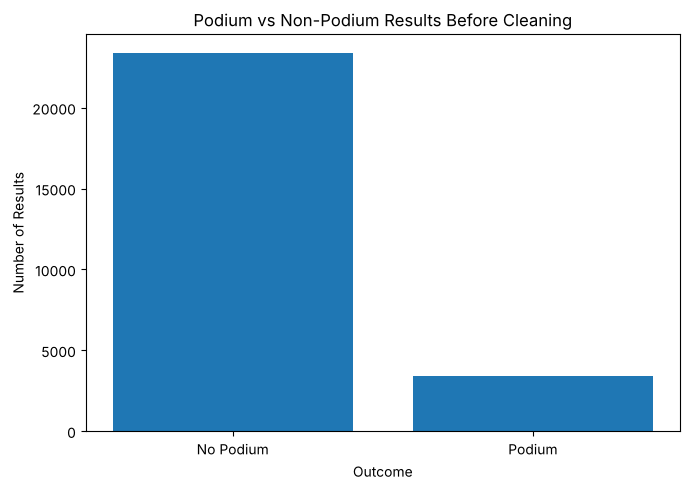

In [16]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["No Podium", "Podium"],
    [
        podium_counts.get(0, 0),
        podium_counts.get(1, 0)
    ]
)

plt.title("Podium vs Non-Podium Results Before Cleaning")
plt.xlabel("Outcome")
plt.ylabel("Number of Results")

plt.tight_layout()
plt.show()

Count the `(raceId, driverId)` combinations that appear more than once in the raw results.

In [17]:
duplicate_counts = (
    results_eda
    .groupby(["raceId", "driverId"])
    .size()
)

duplicate_groups = duplicate_counts[
    duplicate_counts > 1
]

print("Unique driver-race combinations:", len(duplicate_counts))
print("Duplicated driver-race combinations:", len(duplicate_groups))
print("Rows involved in duplicates:", duplicate_groups.sum())

Unique driver-race combinations: 26668
Duplicated driver-race combinations: 85
Rows involved in duplicates: 176


Chart of the size of the duplicated driver-race groups (2 or 3 records per driver-race).

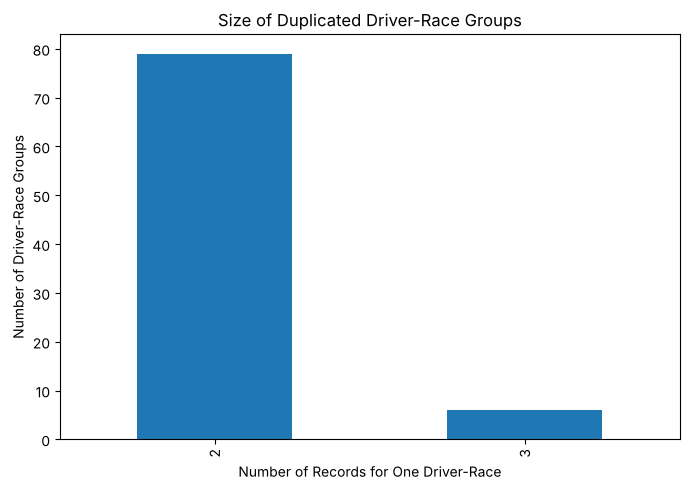

In [18]:
plt.figure(figsize=(7, 5))

duplicate_groups.value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Size of Duplicated Driver-Race Groups")
plt.xlabel("Number of Records for One Driver-Race")
plt.ylabel("Number of Driver-Race Groups")

plt.tight_layout()
plt.show()

### Initial EDA findings (before cleaning)

The plots above are computed directly from the raw tables:

- **Size.** 14 relational tables. `lap_times` is by far the largest (589,081 rows), and `results` (26,759 rows) is the
  table the modelling grain comes from.
- **Missing values.** Almost all missing information is hidden as the literal string `\N` (160,076 cells), which pandas
  does **not** recognise as missing. Only `qualifying` has 68 real `NaN`s. `results` alone holds 122,887 sentinel cells.
  This motivates converting `\N` to `NaN` before any analysis (section 1.2).
- **Races per year** grows from 7 in 1950 to 24 in 2024, so later seasons dominate the row count.
- **Grid positions** have a visible spike at `grid = 0`, which is a code rather than a starting position (investigated
  in 2.2.3).
- **Target balance.** On the raw rows, podiums are a small minority class, so the problem is imbalanced.
- **Duplicates.** 85 `(raceId, driverId)` pairs appear more than once (176 rows), which breaks the required
  one-row-per-driver-per-race grain (section 1.7).

### Initial EDA (continued): distributions, ranges and outliers

The first EDA block above counted rows and missing cells. This block looks at the **values** of the main numeric columns of the
raw tables, because ranges and outliers decide how a column may be used. Nothing is modified here.

- Histograms show the shape and range of each column (log scale where the tail is long).
- Boxplots show the spread and the extreme values.
- The **outlier audit** counts values more than twice the median of their own race, the same rule section 1.3 uses for
  qualifying times. It is report-only: `lap_times`, `pit_stops` and `results.fastestLapTime` are post-race tables and never
  become features, so an unusual value there cannot reach the model. Only `qualifying` feeds features, and it is corrected in 1.3.

In [ ]:
def to_seconds(s):
    # '1:26.572' -> 86.572, '22.123' -> 22.123; anything else (including \N) -> NaN
    parts = s.astype(str).str.extract(r"^(?:(\d+):)?(\d+(?:\.\d+)?)$")
    return pd.to_numeric(parts[1], errors="coerce") + 60 * pd.to_numeric(parts[0], errors="coerce").fillna(0)

raw_num = {
    "results.grid": pd.to_numeric(tables["results"]["grid"], errors="coerce"),
    "results.laps": pd.to_numeric(tables["results"]["laps"], errors="coerce"),
    "results.points": pd.to_numeric(tables["results"]["points"], errors="coerce"),
    "results.fastestLapSpeed (km/h)": pd.to_numeric(tables["results"]["fastestLapSpeed"], errors="coerce"),
    "lap_times (s)": pd.to_numeric(tables["lap_times"]["milliseconds"], errors="coerce") / 1000,
    "pit_stops (s)": pd.to_numeric(tables["pit_stops"]["milliseconds"], errors="coerce") / 1000,
    "qualifying.q1 (s)": to_seconds(tables["qualifying"]["q1"]),
}

summary = pd.DataFrame({
    name: {"count": s.notna().sum(), "min": s.min(), "median": s.median(), "p99": s.quantile(0.99),
           "p99.9": s.quantile(0.999), "max": s.max()}
    for name, s in raw_num.items()
}).T
display(summary.round(2))

LOG_Y = {"lap_times (s)", "pit_stops (s)", "qualifying.q1 (s)", "results.laps"}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (name, s) in zip(axes.ravel(), raw_num.items()):
    s = s.dropna()
    if name == "lap_times (s)":
        s = s[s < s.quantile(0.999)]
    elif name == "pit_stops (s)":
        s = s[s < s.quantile(0.99)]
    elif name == "qualifying.q1 (s)":
        s = s[s < s.quantile(0.999)]
    ax.hist(s, bins=40)
    if name in LOG_Y:
        ax.set_yscale("log")
    ax.set_title(name + (" (top tail cut)" if name in {"lap_times (s)", "pit_stops (s)", "qualifying.q1 (s)"} else ""))
axes.ravel()[-1].axis("off")
plt.suptitle("Raw numeric columns: histograms"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for ax, (name, s) in zip(axes.ravel(), raw_num.items()):
    ax.boxplot(s.dropna(), vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
    if name in {"lap_times (s)", "pit_stops (s)", "qualifying.q1 (s)"}:
        ax.set_xscale("log")
    ax.set_title(name); ax.set_yticks([])
axes.ravel()[-1].axis("off")
plt.suptitle("Raw numeric columns: boxplots (log x where the tail is long)"); plt.tight_layout(); plt.show()

# Outlier audit: more than 2x the median of the same race (report-only)
laps = tables["lap_times"].assign(sec=raw_num["lap_times (s)"])
pits = tables["pit_stops"].assign(sec=raw_num["pit_stops (s)"])
fl = tables["results"].assign(sec=to_seconds(tables["results"]["fastestLapTime"]))
q1t = tables["qualifying"].assign(sec=raw_num["qualifying.q1 (s)"])

rows = []
for label, df in [("lap_times", laps), ("pit_stops", pits), ("results.fastestLapTime", fl), ("qualifying.q1", q1t)]:
    ratio = df["sec"] / df.groupby("raceId")["sec"].transform("median")
    rows.append({"column": label, "non-null": int(df["sec"].notna().sum()), "> 2x race median": int((ratio > 2).sum()),
                 "share %": round(100 * (ratio > 2).sum() / df["sec"].notna().sum(), 3), "max ratio": round(ratio.max(), 1)})
display(pd.DataFrame(rows))

# Are the slow laps recording errors, or racing events?  Three signatures of a real event:
#   lap 1 (standing start), the in/out lap of a pit stop, and a lap that is slow for a large part of the field (safety car / red flag)
ratio = laps["sec"] / laps.groupby("raceId")["sec"].transform("median")
laps["slow"] = ratio > 2
laps["field_slow_share"] = laps.groupby(["raceId", "lap"])["slow"].transform("mean")
slow = laps[laps["slow"]].merge(pits[["raceId", "driverId", "lap"]].drop_duplicates().assign(pit_lap=1),
                                on=["raceId", "driverId", "lap"], how="left")
slow["pit_lap"] = slow["pit_lap"].fillna(0).astype(int)
is_lap1 = slow["lap"] == 1
is_pit = slow["pit_lap"] == 1
is_field = slow["field_slow_share"] >= 0.5
explained = is_lap1 | is_pit | is_field
print(f"Slow laps (> 2x race median): {len(slow):,} in {slow['raceId'].nunique()} races")
print(f"  lap 1: {int(is_lap1.sum()):,} | pit-stop laps: {int(is_pit.sum()):,} | slow for at least half of the field: {int(is_field.sum()):,}")
print(f"  explained by at least one of the three: {int(explained.sum()):,} ({100 * explained.mean():.1f}%) | "
      f"isolated slow laps left: {int((~explained).sum()):,} ({100 * (~explained).mean():.1f}%)")
print("Slow laps are real events (or only matter for post-race tables), so they are reported and not removed.")

top_pits = (pits.sort_values("sec", ascending=False).head(5)
            .merge(tables["races"][["raceId", "year", "name"]], on="raceId")[["year", "name", "driverId", "lap", "sec"]])
# two features of the raw histograms worth explaining
rn = tables["results"].merge(tables["races"][["raceId", "year", "name"]], on="raceId")
rn["laps_n"] = pd.to_numeric(rn["laps"], errors="coerce"); rn["points_n"] = pd.to_numeric(rn["points"], errors="coerce")
print(f"\nRows with laps >= 190: {int((rn['laps_n'] >= 190).sum())}, of which Indianapolis 500: {int(((rn['laps_n'] >= 190) & rn['name'].eq('Indianapolis 500')).sum())}")
print("Rows with points > 26:", int((rn["points_n"] > 26).sum()), "| races:", sorted(set(zip(rn.loc[rn["points_n"] > 26, "year"], rn.loc[rn["points_n"] > 26, "name"]))))

print("\nLongest pit stops (red-flag / repair stops, real events):")
display(top_pits.round(1))

**Reading the distributions.**

- `results.grid` has the `0` spike already noted (section 2.2.3) and no value above 34. `results.points` is highly zero-inflated
  (most entries score nothing). The spike at 200 laps in `results.laps` and the 50-point rows are explained by the two
  lines printed above (the Indianapolis 500 and a double-points race): real values, not errors.
- `lap_times` (median about 91 s) and `pit_stops` (median about 24 s) have very long right tails: the 99th percentile of
  `pit_stops` is about 1,850 s, so more than 1% of "stops" last over 30 minutes (red-flag waits) and 3.8% are more than twice the race median.
  The five longest, about 3,060 s each, are lap-1 stops of the 2022 British GP, which was red-flagged on lap 1.
- Of the 1,092 laps more than twice the race median, 81% are explained by lap 1, a pit-stop lap or a lap that was slow for at
  least half of the field (safety car or red flag). The remaining 203 are isolated slow laps (spin, damage, traffic); they
  are real racing events, and since `lap_times` never becomes a feature nothing is changed.
- `qualifying.q1` has one impossible value (1,002.6 s, the 1995 Japanese GP) that section 1.3 sets to `NaN`; the same rule
  finds nothing in `results.fastestLapTime`. Qualifying is the only one of these columns that reaches the features.

## 1.2 Sentinel Handling

The raw dataset uses the literal `\N` string as a placeholder for unavailable
values. These sentinel values are converted to pandas' standard missing-value
representation (`NaN`) in working copies of the raw tables. The original raw
CSV files remain unchanged.

Missing values are not automatically imputed because their meaning depends on
the semantics of each variable.

In [19]:
# Create cleaned working copies of all tables
# Raw tables in `tables` remain unchanged.

clean_tables = {}

for name, df in tables.items():
    clean_df = df.copy()
    
    # Convert the literal \N sentinel to pandas NaN
    clean_df = clean_df.replace(r"\N", np.nan)
    
    clean_tables[name] = clean_df

print("Sentinel cleaning completed.")
print(f"Raw tables preserved: {len(tables)}")
print(f"Clean working copies: {len(clean_tables)}")

Sentinel cleaning completed.
Raw tables preserved: 14
Clean working copies: 14


## 1.3 Semantic Typing

After sentinel handling, many columns are still stored as text (`object`), even when they hold dates, numbers or
lap times. Each column is converted to the type that matches its meaning:

| Kind of value | Columns | Converted to |
|---|---|---|
| Calendar dates | `drivers.dob`, `races.date`, `races.fp1/fp2/fp3/quali/sprint_date` | `datetime64` |
| Numbers stored as text | `results.number/position/fastestLap/rank/fastestLapSpeed`, `sprint_results.position/fastestLap`, `drivers.number` | numeric |
| Durations already in ms | `results.milliseconds`, `sprint_results.milliseconds` | numeric |
| Lap-time / duration strings (`"1:26.572"`, `"16:44.718"`, `"22.123"`) | `qualifying.q1/q2/q3`, `results.fastestLapTime`, `sprint_results.fastestLapTime`, `lap_times.time`, `pit_stops.duration` | numeric **seconds** |

Deliberately left as text:

- `results.time` / `sprint_results.time` mix two formats (the winner's total time `"1:34:50.616"` and gaps like
  `"+5.478"`), so they are not one quantity. Their numeric version already exists in `milliseconds`.
- `races.time`, `races.*_time` and `pit_stops.time` are **clock times of day** (`"15:10:00"`), not durations.
- Names, references, URLs, nationalities and `positionText` are categorical text.

Every conversion is checked: a value that was present before conversion but became `NaN` after it would be a silent
parsing failure, so these are counted. Durations that also exist in milliseconds are cross-checked against them.

In [20]:
# Snapshot of text columns before typing (used for the before/after comparison below)
dtypes_before = {name: df.dtypes.copy() for name, df in clean_tables.items()}

def time_to_seconds(series):
    # Convert 'm:ss.sss', 'h:mm:ss.sss' or 'ss.sss' strings to float seconds. NaN stays NaN.
    def parse(s):
        s = str(s).strip()
        try:
            parts = [float(p) for p in s.split(":")]
        except ValueError:
            return np.nan
        seconds = 0.0
        for p in parts:
            seconds = seconds * 60 + p
        return seconds
    uniques = series.dropna().unique()
    lookup = {u: parse(u) for u in uniques}
    return series.map(lookup).astype(float)

DATE_COLS = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
}
NUMERIC_COLS = {
    "results": ["number", "position", "fastestLap", "rank", "fastestLapSpeed", "milliseconds"],
    "sprint_results": ["position", "fastestLap", "milliseconds"],
    "drivers": ["number"],
}
DURATION_COLS = {
    "qualifying": ["q1", "q2", "q3"],
    "results": ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
}

typing_log = []

def log(table, col, kind, before_series, after_series):
    lost = int((before_series.notna() & after_series.isna()).sum())
    typing_log.append({
        "Table": table, "Column": col, "Kind": kind,
        "dtype before": str(before_series.dtype), "dtype after": str(after_series.dtype),
        "Non-null values": int(before_series.notna().sum()),
        "Failed conversions": lost,
    })

for table, cols in DATE_COLS.items():
    for col in cols:
        before_s = clean_tables[table][col]
        clean_tables[table][col] = pd.to_datetime(before_s, errors="coerce")
        log(table, col, "date", before_s, clean_tables[table][col])

for table, cols in NUMERIC_COLS.items():
    for col in cols:
        before_s = clean_tables[table][col]
        clean_tables[table][col] = pd.to_numeric(before_s, errors="coerce")
        log(table, col, "numeric", before_s, clean_tables[table][col])

for table, cols in DURATION_COLS.items():
    for col in cols:
        before_s = clean_tables[table][col]
        clean_tables[table][col] = time_to_seconds(before_s)
        log(table, col, "duration -> seconds", before_s, clean_tables[table][col])

typing_log_df = pd.DataFrame(typing_log)
display(typing_log_df)
print("Total failed conversions:", int(typing_log_df["Failed conversions"].sum()))

,Table,Column,Kind,dtype before,dtype after,Non-null values,Failed conversions
0,drivers,dob,date,object,datetime64[ns],861,0
1,races,date,date,object,datetime64[ns],1125,0
2,races,fp1_date,date,object,datetime64[ns],90,0
3,races,fp2_date,date,object,datetime64[ns],90,0
4,races,fp3_date,date,object,datetime64[ns],72,0
5,races,quali_date,date,object,datetime64[ns],90,0
6,races,sprint_date,date,object,datetime64[ns],18,0
7,results,number,numeric,object,float64,26753,0
8,results,position,numeric,object,float64,15806,0
9,results,fastestLap,numeric,object,float64,8252,0


Total failed conversions: 0


Cross-check the parsed durations against the official millisecond columns (`lap_times`, `pit_stops`) and sanity-check the qualifying times.

In [21]:
# Cross-check: durations parsed from text must agree with the milliseconds columns
checks = {
    "lap_times.time vs milliseconds": (clean_tables["lap_times"]["time"],
                                       clean_tables["lap_times"]["milliseconds"] / 1000),
    "pit_stops.duration vs milliseconds": (clean_tables["pit_stops"]["duration"],
                                           clean_tables["pit_stops"]["milliseconds"] / 1000),
}
for label, (a, b) in checks.items():
    diff = (a - b).abs()
    print(f"{label}: max abs difference = {diff.max():.4f} s over {diff.notna().sum():,} rows")

# Qualifying sanity: q1/q2/q3 should be plausible lap times
q = clean_tables["qualifying"][["q1", "q2", "q3"]]
display(q.describe().round(2))

lap_times.time vs milliseconds: max abs difference = 0.0000 s over 589,081 rows
pit_stops.duration vs milliseconds: max abs difference = 0.0000 s over 11,371 rows


,q1,q2,q3
count,10338.00,5847.00,3629.00
mean,88.53,87.77,87.41
std,15.39,12.11,12.26
min,53.90,53.65,53.38
25%,78.77,77.94,77.24
50%,87.14,87.12,87.04
75%,95.91,95.96,95.63
max,1002.64,132.47,129.78


Plausibility check on qualifying times: flag any lap more than twice the race median as a recording error.

,qualifyId,raceId,driverId,session,raw text,seconds,race median (s),year,name
0,2569,255,87,q1,16:42.640,1002.64,101.474,1995,Japanese Grand Prix


Implausible qualifying times set to NaN: 1


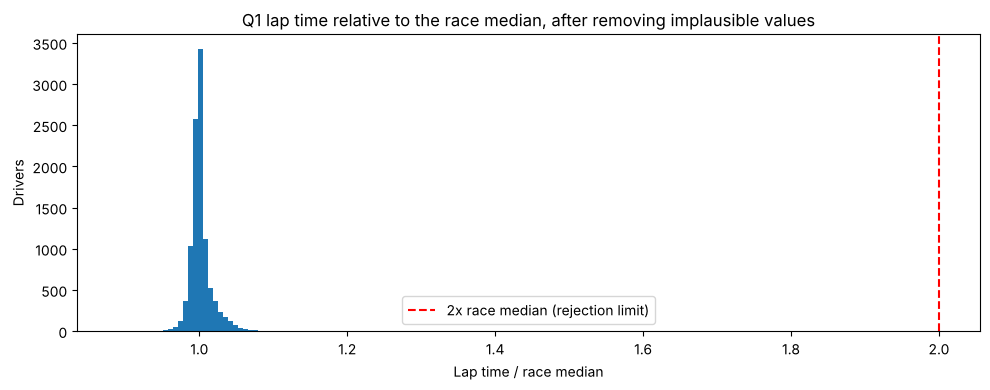

In [22]:
# Plausibility check: a qualifying lap more than twice as slow as the median lap of the same race and session
# cannot be a real flying lap (wet sessions and slow cars stay well below 2x). Such values are recording errors.
implausible = []
for c in ["q1", "q2", "q3"]:
    med = clean_tables["qualifying"].groupby("raceId")[c].transform("median")
    bad = clean_tables["qualifying"][c] > 2 * med
    for idx in clean_tables["qualifying"].index[bad]:
        row = clean_tables["qualifying"].loc[idx]
        implausible.append({"qualifyId": int(row["qualifyId"]), "raceId": int(row["raceId"]), "driverId": int(row["driverId"]),
                            "session": c, "raw text": tables["qualifying"].loc[idx, c],
                            "seconds": row[c], "race median (s)": round(med[idx], 3)})
    clean_tables["qualifying"].loc[bad, c] = np.nan
implausible_df = pd.DataFrame(implausible).merge(tables["races"][["raceId", "year", "name"]], on="raceId")
display(implausible_df)
print("Implausible qualifying times set to NaN:", len(implausible_df))

ratio = clean_tables["qualifying"]["q1"] / clean_tables["qualifying"].groupby("raceId")["q1"].transform("median")
plt.figure(figsize=(10, 4))
plt.hist(ratio.dropna(), bins=80)
plt.axvline(2, color="red", linestyle="--", label="2x race median (rejection limit)")
plt.title("Q1 lap time relative to the race median, after removing implausible values")
plt.xlabel("Lap time / race median"); plt.ylabel("Drivers"); plt.legend()
plt.tight_layout(); plt.show()

Chart of the number of text columns per table before and after semantic typing.

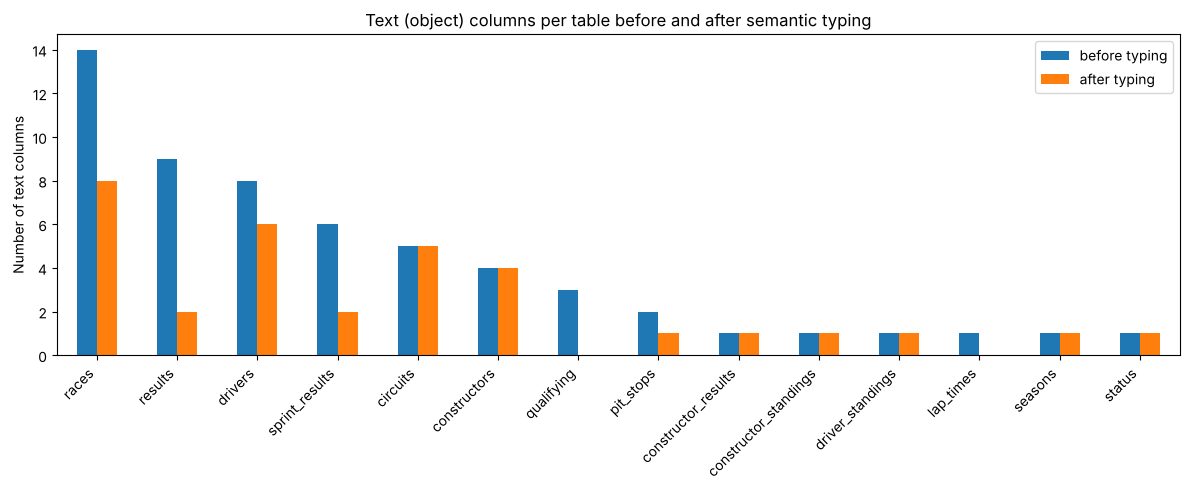

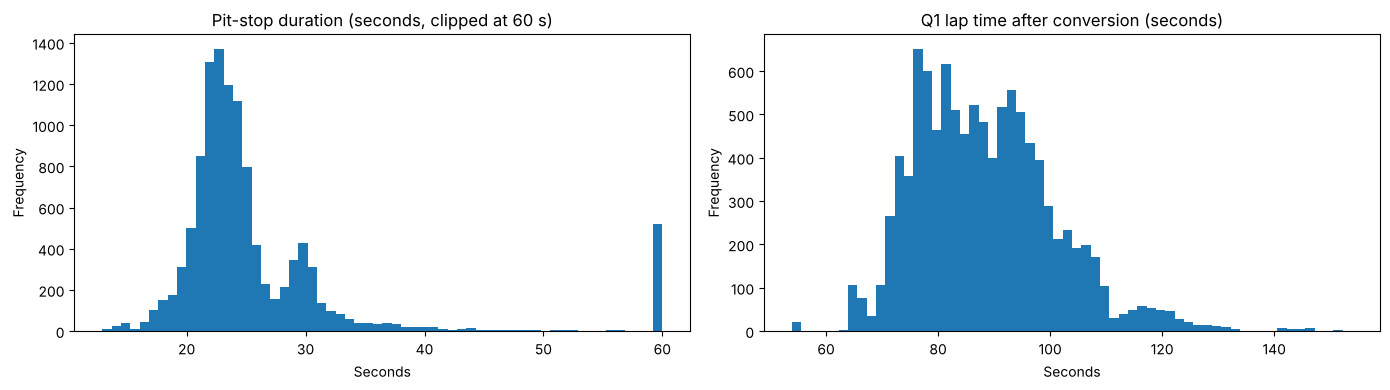

In [23]:
# Visualise the effect of typing: number of text columns per table, before vs after.
# pandas may represent text as either object (older versions) or StringDtype (newer versions).
def count_text_dtypes(dtypes):
    return int(sum(pd.api.types.is_object_dtype(dtype) or pd.api.types.is_string_dtype(dtype)
                   for dtype in dtypes))

obj_before = pd.Series({n: count_text_dtypes(d) for n, d in dtypes_before.items()})
obj_after = pd.Series({n: count_text_dtypes(df.dtypes) for n, df in clean_tables.items()})
typed = pd.DataFrame({"before typing": obj_before, "after typing": obj_after})
typed = typed[typed["before typing"] > 0].sort_values("before typing", ascending=False)

ax = typed.plot(kind="bar", figsize=(12, 5))
ax.set_title("Text (object) columns per table before and after semantic typing")
ax.set_ylabel("Number of text columns")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
clean_tables["pit_stops"]["duration"].clip(upper=60).plot(kind="hist", bins=60, ax=ax[0])
ax[0].set_title("Pit-stop duration (seconds, clipped at 60 s)")
ax[0].set_xlabel("Seconds")
clean_tables["qualifying"]["q1"].plot(kind="hist", bins=60, ax=ax[1])
ax[1].set_title("Q1 lap time after conversion (seconds)")
ax[1].set_xlabel("Seconds")
plt.tight_layout()
plt.show()

**Typing result.** All date, numeric and duration columns were converted with zero failed conversions, so no value was
lost by `errors="coerce"`. The durations parsed from text match the official millisecond columns, which confirms the
parser. The plausibility check found one impossible qualifying time (`16:42.640` in Q1 at the 1995 Japanese GP, about
11x the race median); it is a recording error and is set to `NaN` instead of being kept as a lap time. The remaining
text columns are the intentional ones listed above. The pit-stop histogram also shows that a
small number of "stops" last minutes rather than seconds: these are red-flag stoppages recorded as pit stops, which is
why `pit_stops.duration` contained values like `"16:44.718"` that a naive `float()` would have failed on.

### 1.3.1 Text standardisation

Text fields that are later used for joins or comparisons must use one spelling per meaning. Two checks are run:

1. **Whitespace.** Every text cell in every table is checked for leading or trailing spaces, which make otherwise equal
   values different.
2. **Same entity, different spelling.** The home-race feature compares `drivers.nationality` with `circuits.country`,
   so each must use one spelling per country. The check prints the circuits stored under each US spelling and the
   drivers stored under each Argentine spelling.

The fixes are applied to the working copies only.

In [24]:
# 1) Leading/trailing whitespace in any text column
ws_rows = []
for name, df in clean_tables.items():
    for col in df.columns[df.dtypes == object]:
        s = df[col]
        mask = s.notna() & (s.astype(str) != s.astype(str).str.strip())
        if mask.any():
            ws_rows.append({"Table": name, "Column": col, "Cells with extra spaces": int(mask.sum()),
                            "Examples": list(s[mask].unique()[:3])})
            clean_tables[name][col] = s.where(~mask, s.astype(str).str.strip())
display(pd.DataFrame(ws_rows) if ws_rows else "No whitespace issues found")

# 2) Spelling variants of the same country / nationality
circ = clean_tables["circuits"]
print("Circuits stored under each US spelling:")
display(circ[circ["country"].isin(["USA", "United States"])].groupby("country")["name"].apply(list).to_frame("circuits"))

drv = clean_tables["drivers"]
print("Drivers stored under each Argentine spelling:")
display(drv[drv["nationality"].str.startswith("Argentin")].groupby("nationality")["surname"].apply(list).to_frame("drivers"))

,Table,Column,Cells with extra spaces,Examples
0,drivers,nationality,1,[Argentinian ]


Circuits stored under each US spelling:


,circuits
country,
USA,"[Indianapolis Motor Speedway, Phoenix street c..."
United States,[Las Vegas Strip Street Circuit]


Drivers stored under each Argentine spelling:


,drivers
nationality,
Argentine,"[Mazzacane, Tuero, Fontana, Larrauri, Reuteman..."
Argentine-Italian,[de Tomaso]
Argentinian,[Colapinto]


Apply the spelling fixes found above: `United States` becomes `USA` for circuits and `Argentinian` becomes `Argentine` for drivers.

In [25]:
COUNTRY_FIX = {"United States": "USA"}
NATIONALITY_FIX = {"Argentinian": "Argentine"}

n_country = int(clean_tables["circuits"]["country"].isin(COUNTRY_FIX).sum())
n_nat = int(clean_tables["drivers"]["nationality"].isin(NATIONALITY_FIX).sum())

clean_tables["circuits"]["country"] = clean_tables["circuits"]["country"].replace(COUNTRY_FIX)
clean_tables["drivers"]["nationality"] = clean_tables["drivers"]["nationality"].replace(NATIONALITY_FIX)

print(f"Circuits relabelled: {n_country} | Drivers relabelled: {n_nat}")
print("Distinct circuit countries:", tables["circuits"]["country"].nunique(), "->", clean_tables["circuits"]["country"].nunique())
print("Distinct nationalities:   ", tables["drivers"]["nationality"].nunique(), "->", clean_tables["drivers"]["nationality"].nunique())

Circuits relabelled: 1 | Drivers relabelled: 1
Distinct circuit countries: 35 -> 34
Distinct nationalities:    43 -> 42


**Result.** One driver's nationality had a trailing space (`"Argentinian "`) and a different spelling from every other
Argentine driver, and one circuit (Las Vegas Strip) used `"United States"` while the other 11 US circuits use `"USA"`.
Without this fix both would silently fail the home-race match (an American driver at Las Vegas would never be "at
home"). After the fix each country and nationality has a single spelling.

In [26]:
# Step 1.4 — Primary Key Audit

primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "drivers": ["driverId"],
    "races": ["raceId"],
    "seasons": ["year"],
    "status": ["statusId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "driver_standings": ["driverStandingsId"],
    "sprint_results": ["resultId"]
}

pk_audit = []

for table_name, key_columns in primary_keys.items():
    df = clean_tables[table_name]
    
    null_count = df[key_columns].isna().any(axis=1).sum()
    duplicate_count = df.duplicated(subset=key_columns).sum()
    
    pk_audit.append({
        "Table": table_name,
        "Primary Key": ", ".join(key_columns),
        "Null Key Rows": null_count,
        "Duplicate Key Rows": duplicate_count,
        "Status": "PASS" if null_count == 0 and duplicate_count == 0 else "FAIL"
    })

pk_audit_df = pd.DataFrame(pk_audit)

pk_audit_df

,Table,Primary Key,Null Key Rows,Duplicate Key Rows,Status
0,circuits,circuitId,0,0,PASS
1,constructors,constructorId,0,0,PASS
2,drivers,driverId,0,0,PASS
3,races,raceId,0,0,PASS
4,seasons,year,0,0,PASS
5,status,statusId,0,0,PASS
6,results,resultId,0,0,PASS
7,qualifying,qualifyId,0,0,PASS
8,constructor_results,constructorResultsId,0,0,PASS
9,constructor_standings,constructorStandingsId,0,0,PASS


## 1.4 Primary Key Audit

Primary keys were checked for both null values and duplicate values.

All audited tables passed the primary-key validation, with zero null primary
keys and zero duplicate primary keys. This confirms that each row in these
tables can be uniquely identified by its designated primary key.

Tables containing naturally composite identifiers, such as `lap_times` and
`pit_stops`, are handled separately using composite-key validation.

In [27]:
# Step 1.5 — Composite Key Audit

composite_keys = {
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"]
}

composite_audit = []

for table_name, key_columns in composite_keys.items():
    df = clean_tables[table_name]

    null_count = df[key_columns].isna().any(axis=1).sum()
    duplicate_count = df.duplicated(subset=key_columns).sum()

    composite_audit.append({
        "Table": table_name,
        "Composite Key": " + ".join(key_columns),
        "Null Key Rows": null_count,
        "Duplicate Key Rows": duplicate_count,
        "Status": (
            "PASS"
            if null_count == 0 and duplicate_count == 0
            else "FAIL"
        )
    })

composite_audit_df = pd.DataFrame(composite_audit)

composite_audit_df

,Table,Composite Key,Null Key Rows,Duplicate Key Rows,Status
0,lap_times,raceId + driverId + lap,0,0,PASS
1,pit_stops,raceId + driverId + stop,0,0,PASS


## 1.5 Composite Key Audit

Some tables do not have a single column that uniquely identifies each row.
For these tables, a combination of columns was used as the composite key.

For `lap_times`, the composite key is `raceId + driverId + lap`.

For `pit_stops`, the composite key is `raceId + driverId + stop`.

Both composite keys were checked for null values and duplicate combinations.
Both tables passed the audit with zero null key rows and zero duplicate key
rows.

In [28]:
# Step 1.6 — Foreign Key Audit

foreign_keys = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
]

fk_audit = []

for child_table, child_column, parent_table, parent_column in foreign_keys:
    
    child_values = set(
        clean_tables[child_table][child_column]
        .dropna()
        .unique()
    )
    
    parent_values = set(
        clean_tables[parent_table][parent_column]
        .dropna()
        .unique()
    )
    
    missing_values = child_values - parent_values
    
    fk_audit.append({
        "Child Table": child_table,
        "Foreign Key": child_column,
        "Parent Table": parent_table,
        "Parent Key": parent_column,
        "Missing References": len(missing_values),
        "Status": "PASS" if len(missing_values) == 0 else "FAIL"
    })

fk_audit_df = pd.DataFrame(fk_audit)

fk_audit_df

,Child Table,Foreign Key,Parent Table,Parent Key,Missing References,Status
0,results,raceId,races,raceId,0,PASS
1,results,driverId,drivers,driverId,0,PASS
2,results,constructorId,constructors,constructorId,0,PASS
3,results,statusId,status,statusId,0,PASS
4,qualifying,raceId,races,raceId,0,PASS
5,qualifying,driverId,drivers,driverId,0,PASS
6,qualifying,constructorId,constructors,constructorId,0,PASS
7,lap_times,raceId,races,raceId,0,PASS
8,lap_times,driverId,drivers,driverId,0,PASS
9,pit_stops,raceId,races,raceId,0,PASS


Summary of the primary-key, composite-key and foreign-key audits (pass vs fail counts), with a chart.

,PASS,FAIL
Primary keys,12,0
Composite keys,2,0
Foreign keys,23,0


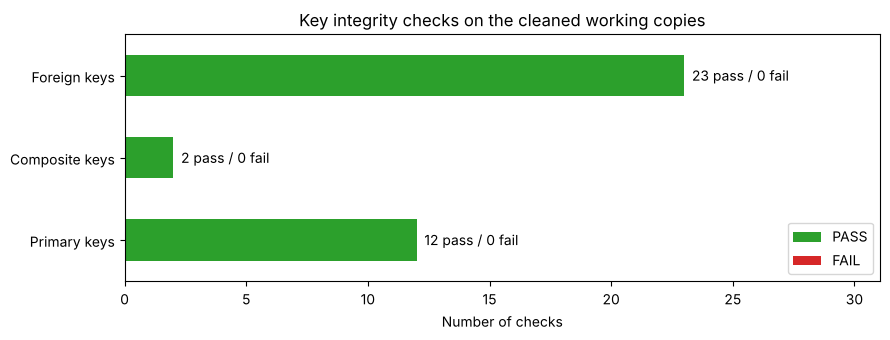

All key checks pass: True


In [29]:
key_summary = pd.DataFrame({
    "PASS": [int((pk_audit_df["Status"] == "PASS").sum()),
             int((composite_audit_df["Status"] == "PASS").sum()),
             int((fk_audit_df["Status"] == "PASS").sum())],
    "FAIL": [int((pk_audit_df["Status"] == "FAIL").sum()),
             int((composite_audit_df["Status"] == "FAIL").sum()),
             int((fk_audit_df["Status"] == "FAIL").sum())],
}, index=["Primary keys", "Composite keys", "Foreign keys"])
display(key_summary)

ax = key_summary.plot(kind="barh", stacked=True, color=["tab:green", "tab:red"], figsize=(9, 3.5))
for i, (p_, f_) in enumerate(zip(key_summary["PASS"], key_summary["FAIL"])):
    ax.text(p_ + f_, i, f"  {p_} pass / {f_} fail", va="center")
ax.set_title("Key integrity checks on the cleaned working copies")
ax.set_xlabel("Number of checks"); ax.set_xlim(0, key_summary.values.sum(axis=1).max() * 1.35)
plt.tight_layout(); plt.show()

print("All key checks pass:", bool(key_summary["FAIL"].sum() == 0))

## 1.6 Foreign Key Audit

Foreign-key relationships were validated to ensure that references between the relational tables point to existing
records in their corresponding parent tables.

A total of 23 foreign-key relationships were checked (including `races.year -> seasons.year`). All relationships
passed the audit with zero missing references, and the chart above summarises all 37 key checks (12 primary,
2 composite, 23 foreign): every one passes. The key checks were run on the cleaned working copies; the raw `tables` were never modified.

### 1.6.1 Can the key audit fail?

All 37 checks passing is only informative if the audit can actually report a failure. The cell below re-implements the same
expressions as the audit loops (null and duplicate counts for keys; the set difference between child and parent values for
foreign keys), confirms they reproduce the audit table on the real data, and then feeds them deliberately corrupted copies of
`results` and `races`. It also counts null foreign-key values, which the foreign-key loop skips with `dropna()`.

In [ ]:
def pk_check(df, cols):
    nulls = int(df[cols].isna().any(axis=1).sum()); dups = int(df.duplicated(subset=cols).sum())
    return ("PASS" if nulls == 0 and dups == 0 else "FAIL"), nulls, dups

def fk_check(child, ccol, parent, pcol):
    missing = set(child[ccol].dropna().unique()) - set(parent[pcol].dropna().unique())
    return ("PASS" if not missing else "FAIL"), len(missing)

# 1) the re-implementation agrees with the audit tables on the real data
assert [pk_check(clean_tables[t], c)[0] for t, c in primary_keys.items()] == pk_audit_df["Status"].tolist()
assert [fk_check(clean_tables[ct], cc, clean_tables[pt], pc)[0] for ct, cc, pt, pc in foreign_keys] == fk_audit_df["Status"].tolist()

# 2) deliberately broken copies must FAIL
res_bad = clean_tables["results"].copy()
dup_pk = pd.concat([res_bad, res_bad.iloc[[0]]], ignore_index=True)
null_pk = res_bad.copy(); null_pk.loc[0, "resultId"] = np.nan
orphan_fk = res_bad.copy(); orphan_fk.loc[0, "raceId"] = 999999
races_bad = clean_tables["races"].copy(); races_bad.loc[0, "circuitId"] = 999999

tests = [
    ("results: duplicated primary key", pk_check(dup_pk, ["resultId"])[0]),
    ("results: null primary key", pk_check(null_pk, ["resultId"])[0]),
    ("results: raceId not in races", fk_check(orphan_fk, "raceId", clean_tables["races"], "raceId")[0]),
    ("races: circuitId not in circuits", fk_check(races_bad, "circuitId", clean_tables["circuits"], "circuitId")[0]),
    ("results unchanged (control)", pk_check(res_bad, ["resultId"])[0]),
]
display(pd.DataFrame(tests, columns=["test", "audit says"]).assign(expected=["FAIL", "FAIL", "FAIL", "FAIL", "PASS"]))
assert [t[1] for t in tests] == ["FAIL", "FAIL", "FAIL", "FAIL", "PASS"], "the key audit failed to detect a planted error"

# 3) null foreign-key values are invisible to the loop above, so count them separately
null_fk = {f"{ct}.{cc}": int(clean_tables[ct][cc].isna().sum()) for ct, cc, pt, pc in foreign_keys}
print("Foreign-key columns containing nulls:", {k: v for k, v in null_fk.items() if v} or "none")

**Result.** The audit reports all four planted errors and passes the untouched control, and no foreign-key column contains a
null. The 37 of 37 pass is therefore informative: the audit can fail, and on this data it does not.

In [30]:
# Step 1.7 — Driver-Race Duplicate Audit

results_df = clean_tables["results"]

duplicate_mask = results_df.duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

driver_race_duplicates = results_df[duplicate_mask].sort_values(
    ["raceId", "driverId"]
)

print(
    "Number of rows involved in driver-race duplicates:",
    len(driver_race_duplicates)
)

driver_race_duplicates[
    [
        "raceId",
        "driverId",
        "constructorId",
        "number",
        "position",
        "positionOrder",
        "points",
        "laps",
        "statusId"
    ]
]

Number of rows involved in driver-race duplicates: 176


,raceId,driverId,constructorId,number,position,positionOrder,points,laps,statusId
13188,540,229,54,10.0,NaN,26,0.0,0,81
13191,540,229,57,23.0,NaN,29,0.0,0,97
17362,717,373,172,1.0,7.0,7,0.0,102,60
24298,717,373,172,2.0,NaN,12,0.0,54,98
17740,733,465,172,48.0,NaN,22,0.0,0,54
...,...,...,...,...,...,...,...,...,...
20181,838,627,154,26.0,6.0,6,0.0,56,18
20163,839,579,51,18.0,NaN,15,1.0,23,6
20183,839,579,51,60.0,NaN,13,0.0,34,5
20165,839,647,6,16.0,NaN,17,0.0,21,5


Count the unique `(raceId, driverId)` combinations involved in duplicates.

In [31]:
# Count unique driver-race combinations involved in duplicates

duplicate_combinations = (
    driver_race_duplicates[["raceId", "driverId"]]
    .drop_duplicates()
)

print(
    "Unique duplicated (raceId, driverId) combinations:",
    len(duplicate_combinations)
)

Unique duplicated (raceId, driverId) combinations: 85


Distribution of the number of rows per duplicated driver-race combination.

In [32]:
duplicate_counts = (
    results_df
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="row_count")
)

duplicate_counts = duplicate_counts[
    duplicate_counts["row_count"] > 1
]

duplicate_counts["row_count"].value_counts().sort_index()

row_count
2    79
3     6
Name: count, dtype: int64

List the duplicated driver-race combinations, largest groups first.

In [33]:
# Show the duplicated driver-race combinations

duplicate_counts.sort_values(
    ["row_count", "raceId", "driverId"],
    ascending=[False, True, True]
)

,raceId,driverId,row_count
19540,792,427,3
19545,792,501,3
19546,792,554,3
19740,800,612,3
19938,809,521,3
...,...,...,...
20501,831,642,2
20580,835,529,2
20646,838,627,2
20662,839,579,2


Attach the race year, name and date to each duplicated combination to see when the duplicates occur.

In [34]:
# Add race information to the duplicated driver-race combinations

duplicate_details = duplicate_counts.merge(
    clean_tables["races"][["raceId", "year", "name", "date"]],
    on="raceId",
    how="left"
)

duplicate_details[
    ["raceId", "year", "name", "date", "driverId", "row_count"]
].sort_values(
    ["year", "raceId", "driverId"]
)

,raceId,year,name,date,driverId,row_count
81,835,1950,Indianapolis 500,1950-05-30,529,2
82,838,1950,French Grand Prix,1950-07-02,627,2
83,839,1950,Italian Grand Prix,1950-09-03,579,2
84,839,1950,Italian Grand Prix,1950-09-03,647,2
77,828,1951,French Grand Prix,1951-07-01,579,2
...,...,...,...,...,...,...
3,742,1961,British Grand Prix,1961-07-15,475,2
4,745,1961,United States Grand Prix,1961-10-08,418,2
2,733,1962,British Grand Prix,1962-07-21,465,2
1,717,1964,United States Grand Prix,1964-10-04,373,2


Inspect the actual result rows of the duplicated driver-race combinations.

In [35]:
# Inspect the actual result rows for duplicated driver-race combinations

duplicate_result_rows = (
    results_df[
        results_df.set_index(["raceId", "driverId"]).index.isin(
            duplicate_combinations.set_index(["raceId", "driverId"]).index
        )
    ]
    .sort_values(["raceId", "driverId", "positionOrder"])
)

duplicate_result_rows[
    [
        "raceId",
        "driverId",
        "constructorId",
        "number",
        "grid",
        "position",
        "positionOrder",
        "points",
        "laps",
        "statusId"
    ]
]

,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,statusId
13188,540,229,54,10.0,0,NaN,26,0.0,0,81
13191,540,229,57,23.0,0,NaN,29,0.0,0,97
17362,717,373,172,1.0,1,7.0,7,0.0,102,60
24298,717,373,172,2.0,1,NaN,12,0.0,54,98
17740,733,465,172,48.0,0,NaN,22,0.0,0,54
...,...,...,...,...,...,...,...,...,...,...
20142,838,627,154,20.0,6,NaN,12,0.0,10,25
20183,839,579,51,60.0,7,NaN,13,0.0,34,5
20163,839,579,51,18.0,1,NaN,15,1.0,23,6
20182,839,647,6,48.0,6,2.0,2,3.0,80,1


Enrich the duplicate rows with race, driver and constructor names for manual inspection.

In [36]:
# Add race and driver information to the duplicate result rows

duplicate_investigation = (
    duplicate_result_rows
    .merge(
        clean_tables["races"][
            ["raceId", "year", "name", "date"]
        ],
        on="raceId",
        how="left"
    )
    .merge(
        clean_tables["drivers"][
            ["driverId", "forename", "surname"]
        ],
        on="driverId",
        how="left"
    )
    .merge(
        clean_tables["constructors"][
            ["constructorId", "name"]
        ],
        on="constructorId",
        how="left",
        suffixes=("", "_constructor")
    )
)

duplicate_investigation[
    [
        "raceId",
        "year",
        "name",
        "driverId",
        "forename",
        "surname",
        "constructorId",
        "name_constructor",
        "number",
        "grid",
        "position",
        "positionOrder",
        "points",
        "laps",
        "statusId"
    ]
].sort_values(
    ["year", "raceId", "driverId", "positionOrder"]
)

,raceId,year,name,driverId,forename,surname,constructorId,name_constructor,number,grid,position,positionOrder,points,laps,statusId
168,835,1950,Indianapolis 500,529,Tony,Bettenhausen,113,Kurtis Kraft,17.0,9,5.0,5,1.0,136,12
169,835,1950,Indianapolis 500,529,Tony,Bettenhausen,150,Deidt,14.0,8,NaN,31,0.0,30,67
170,838,1950,French Grand Prix,627,Louis,Rosier,154,Talbot-Lago,26.0,15,6.0,6,0.0,56,18
171,838,1950,French Grand Prix,627,Louis,Rosier,154,Talbot-Lago,20.0,6,NaN,12,0.0,10,25
172,839,1950,Italian Grand Prix,579,Juan,Fangio,51,Alfa Romeo,60.0,7,NaN,13,0.0,34,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,733,1962,British Grand Prix,465,Keith,Greene,97,Gilby,50.0,0,NaN,25,0.0,0,54
2,717,1964,United States Grand Prix,373,Jim,Clark,172,Lotus-Climax,1.0,1,7.0,7,0.0,102,60
3,717,1964,United States Grand Prix,373,Jim,Clark,172,Lotus-Climax,2.0,1,NaN,12,0.0,54,98
0,540,1978,Italian Grand Prix,229,Harald,Ertl,54,ATS,10.0,0,NaN,26,0.0,0,81


Check whether any duplicated driver-race combination contains a podium result.

In [37]:
# Check whether any duplicated driver-race combination
# contains a podium result

duplicate_podium_check = (
    duplicate_result_rows
    .assign(
        podium=lambda df: df["positionOrder"].le(3)
    )
    .groupby(["raceId", "driverId"])
    .agg(
        n_rows=("driverId", "size"),
        n_podium_rows=("podium", "sum"),
        position_orders=("positionOrder", lambda x: list(x)),
        points=("points", lambda x: list(x))
    )
    .reset_index()
)

duplicate_podium_check[
    duplicate_podium_check["n_podium_rows"] > 0
]

,raceId,driverId,n_rows,n_podium_rows,position_orders,points
5,746,475,2,1,"[3, 17]","[0.0, 0.0]"
13,780,475,2,1,"[1, 12]","[5.0, 0.0]"
14,780,479,2,1,"[1, 12]","[4.0, 0.0]"
17,784,579,2,1,"[1, 13]","[5.0, 0.0]"
18,785,579,2,1,"[2, 4]","[4.0, 1.5]"
20,787,475,2,1,"[3, 11]","[3.0, 0.0]"
24,789,581,2,1,"[2, 17]","[3.0, 0.0]"
25,789,606,2,1,"[2, 10]","[3.0, 0.0]"
27,791,579,2,1,"[2, 8]","[3.0, 0.0]"
29,792,427,3,2,"[2, 3, 11]","[2.0, 1.33, 0.0]"


Count the duplicated cases by their number of podium rows.

In [38]:
# Count duplicated driver-race cases by number of podium rows

duplicate_podium_check[
    duplicate_podium_check["n_podium_rows"] > 0
]["n_podium_rows"].value_counts().sort_index()

n_podium_rows
1    20
2     2
Name: count, dtype: int64

Count the duplicate cases by the number of distinct constructors involved.

In [39]:
# Count duplicate cases by number of distinct constructors

constructor_variation = (
    duplicate_result_rows
    .groupby(["raceId", "driverId"])
    .agg(
        n_rows=("driverId", "size"),
        n_constructors=("constructorId", "nunique"),
        constructors=("constructorId", lambda x: list(x))
    )
    .reset_index()
)

constructor_variation["n_constructors"].value_counts().sort_index()

n_constructors
1    69
2    15
3     1
Name: count, dtype: int64

Inspect the duplicate groups where both rows belong to the same constructor.

In [40]:
# Inspect duplicate groups where the constructor is the same

same_constructor_duplicates = constructor_variation[
    constructor_variation["n_constructors"] == 1
]

same_constructor_details = (
    duplicate_result_rows
    .merge(
        same_constructor_duplicates[
            ["raceId", "driverId"]
        ],
        on=["raceId", "driverId"],
        how="inner"
    )
    .merge(
        clean_tables["races"][
            ["raceId", "year", "name"]
        ],
        on="raceId",
        how="left"
    )
)

same_constructor_details[
    [
        "raceId",
        "year",
        "name",
        "driverId",
        "constructorId",
        "number",
        "grid",
        "position",
        "positionOrder",
        "points",
        "laps",
        "statusId"
    ]
].sort_values(
    ["year", "raceId", "driverId", "number"]
)

,raceId,year,name,driverId,constructorId,number,grid,position,positionOrder,points,laps,statusId
136,838,1950,French Grand Prix,627,154,20.0,6,NaN,12,0.0,10,25
135,838,1950,French Grand Prix,627,154,26.0,15,6.0,6,0.0,56,18
138,839,1950,Italian Grand Prix,579,51,18.0,1,NaN,15,1.0,23,6
137,839,1950,Italian Grand Prix,579,51,60.0,7,NaN,13,0.0,34,5
140,839,1950,Italian Grand Prix,647,6,16.0,2,NaN,17,0.0,21,5
...,...,...,...,...,...,...,...,...,...,...,...,...
4,746,1960,Argentine Grand Prix,475,170,38.0,8,3.0,3,0.0,80,1
2,745,1961,United States Grand Prix,418,172,21.0,15,11.0,11,0.0,92,18
3,745,1961,United States Grand Prix,418,172,22.0,11,NaN,17,0.0,23,6
0,717,1964,United States Grand Prix,373,172,1.0,1,7.0,7,0.0,102,60


Check the qualifying records of the duplicated driver-race combinations.

In [41]:
# Check qualifying records for the duplicated driver-race combinations

duplicate_qualifying = (
    clean_tables["qualifying"]
    .merge(
        duplicate_combinations,
        on=["raceId", "driverId"],
        how="inner"
    )
    .sort_values(["raceId", "driverId", "number"])
)

duplicate_qualifying[
    [
        "raceId",
        "driverId",
        "constructorId",
        "number",
        "position",
        "q1",
        "q2",
        "q3"
    ]
]

,raceId,driverId,constructorId,number,position,q1,q2,q3


Number of distinct car numbers within each duplicated driver-race group.

In [42]:
duplicate_number_variation = (
    duplicate_result_rows
    .groupby(["raceId", "driverId"])["number"]
    .nunique()
)

duplicate_number_variation.value_counts().sort_index()

number
2    79
3     6
Name: count, dtype: int64

Verify that every duplicated driver-race group has 2 or 3 distinct car numbers.

In [43]:
# Verify that every duplicated driver-race group
# has exactly 2 or 3 distinct car numbers

duplicate_result_rows.groupby(
    ["raceId", "driverId"]
)["number"].nunique().value_counts().sort_index()

number
2    79
3     6
Name: count, dtype: int64

### 1.7 Driver-race duplicate audit: findings

- 85 `(raceId, driverId)` pairs appear more than once (176 rows): 79 pairs with 2 rows and 6 pairs with 3 rows.
- In every pair the rows have **different car numbers**, so these are not copied rows. They are the shared drives the
  brief describes: one driver is credited with the result of more than one car in the same race.
- Section 2.2.5 shows they all come from 1950-1978.

Because each row of the modelling table is one prediction, exactly one row must be kept per pair. The cells below
gather the evidence for the rule; the rule itself is applied in section 2.3, after non-starters are removed.

#### Reference label: "podium in any of the driver's cars"

This label is built only as a reference, so that the effect of the chosen duplicate rule on the target can be measured
in section 2.3. It is not the final target.

In [44]:
# Create one podium label per driver-race combination

driver_race_target = (
    results_df
    .groupby(["raceId", "driverId"])["positionOrder"]
    .apply(lambda x: (x <= 3).any())
    .astype(int)
    .reset_index(name="podium")
)

driver_race_target.head()

,raceId,driverId,podium
0,1,1,0
1,1,2,0
2,1,3,0
3,1,4,0
4,1,5,0


Podium vs non-podium counts of the reference label.

In [45]:
driver_race_target["podium"].value_counts().sort_index()

podium
0    23273
1     3395
Name: count, dtype: int64

On the raw grain this gives 23,273 non-podium and 3,395 podium driver-race pairs.

In [46]:
duplicate_grid_variation = (
    duplicate_result_rows
    .groupby(["raceId", "driverId"])["grid"]
    .nunique(dropna=False)
)

duplicate_grid_variation.value_counts().sort_index()

grid
1     4
2    75
3     6
Name: count, dtype: int64

Count the missing `grid` values within the duplicated driver-race groups.

In [47]:
duplicate_grid_missing = (
    duplicate_result_rows
    .groupby(["raceId", "driverId"])["grid"]
    .apply(lambda x: x.isna().sum())
)

duplicate_grid_missing.value_counts().sort_index()

grid
0    85
Name: count, dtype: int64

Check whether the car the driver started in can be identified: count the rows with a real grid slot in each duplicated pair.

,duplicated pairs
case,
every row has a grid slot,82
no row has a grid slot,3


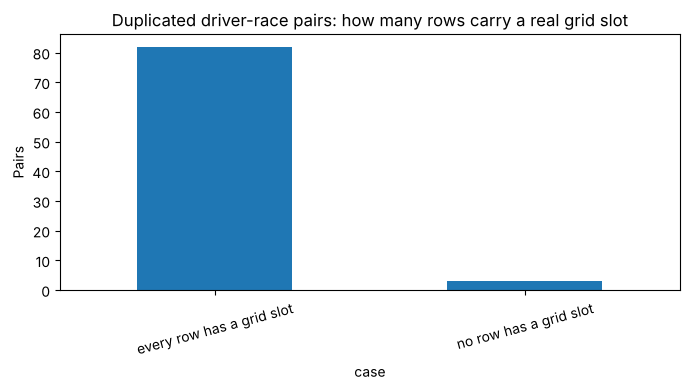

In [48]:
# Can we tell which car the driver started in? Count the rows with a real grid slot in each duplicated pair.
slots = (
    duplicate_result_rows
    .groupby(["raceId", "driverId"])
    .agg(rows=("grid", "size"), rows_with_grid_slot=("grid", lambda g: int((g > 0).sum())))
)
slot_summary = slots.assign(
    case=np.where(slots["rows_with_grid_slot"] == slots["rows"], "every row has a grid slot",
          np.where(slots["rows_with_grid_slot"] == 0, "no row has a grid slot", "only some rows have a grid slot"))
)["case"].value_counts()
display(slot_summary.to_frame("duplicated pairs"))

slot_summary.plot(kind="bar", figsize=(7, 4))
plt.title("Duplicated driver-race pairs: how many rows carry a real grid slot")
plt.ylabel("Pairs"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

### Evidence for the duplicate rule

In almost every duplicated pair, **every** row has a real grid slot, because in shared drives each car keeps the grid
slot it started from, even when the driver credited with it took the car over mid-race. The data therefore cannot tell
us which car the driver started in. A rule such as "keep the lowest grid" would pick an arbitrary car, and could
keep a `grid = 0` non-starter row first.

The rule chosen in section 2.3 is therefore:

1. prefer a row with a real grid slot (this only decides the few pairs where some rows have none);
2. then keep the row with the **best `positionOrder`** (the driver's best classified result);
3. then the lowest `resultId` as a deterministic tie-breaker.

### 1.7.1 Duplicates after 1957: are they really shared drives?

The brief says shared drives happened **until 1957**, but the duplicates in this copy run to **1978**. The explanation
"shared drive" is therefore only established for 1950-57. This block looks at the later groups on their own: do they have the
signature of a shared drive (different car numbers, same or different constructor, both rows with their own laps)?

In [ ]:
dup_src = (
    clean_tables["results"]
    .merge(clean_tables["races"][["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId")
    .merge(clean_tables["status"], on="statusId", how="left")
    .merge(clean_tables["drivers"][["driverId", "surname"]], on="driverId")
)
dup_rows = dup_src[dup_src.duplicated(["raceId", "driverId"], keep=False)].copy()
dup_rows["period"] = np.where(dup_rows["year"] <= 1957, "1950-57", "1958-78")

groups = (dup_rows.groupby(["period", "raceId", "driverId"])
          .agg(rows=("resultId", "size"), constructors=("constructorId", "nunique"), car_numbers=("number", "nunique"),
               all_rows_have_grid=("grid", lambda g: bool((g > 0).all())),
               every_row_ran=("laps", lambda l: bool((l > 0).all())),
               no_row_ran=("laps", lambda l: bool((l == 0).all())))
          .reset_index())
by_period = groups.groupby("period").agg(
    groups=("rows", "size"),
    same_constructor=("constructors", lambda c: int((c == 1).sum())),
    distinct_car_numbers=("car_numbers", lambda c: int((c >= 2).sum())),
    every_row_has_a_grid_slot=("all_rows_have_grid", "sum"),
    every_row_ran_laps=("every_row_ran", "sum"),
    no_row_ran=("no_row_ran", "sum"),
)
display(by_period)

late = dup_rows[dup_rows["period"] == "1958-78"].sort_values(["year", "raceId", "surname", "resultId"])
display(late[["year", "race_name", "surname", "constructorId", "number", "grid", "positionOrder", "laps", "status"]].reset_index(drop=True))

**Reading the groups.**

- **1950-57:** all 76 groups have two or more car numbers, a grid slot and laps on every row, and 64 are in one constructor.
  This is the shared-drive signature the brief describes.
- **1958-78:** 9 groups, and they are **not all shared drives**. Six (1958 French and Italian, 1960 Argentine, 1961 British and
  US, 1964 US) have laps and a grid slot on every row, which fits a driver taking over a second car. Three (1958 Monaco,
  1962 British, 1978 Italian) are a driver entered in **two cars that never started** (*Did not qualify*, *Withdrew*,
  *Did not prequalify*, 0 laps, `grid = 0`). Those three are not shared drives; section 2.3 removes them as non-starters,
  so they never reach the deduplication rule.
- The explanation "shared drive" is therefore documented for 82 of the 85 groups; the other 3 are double non-starter entries.

# Part 2 — Planned EDA, Cleaning and Missing-Value Handling

Part 1 audited the raw tables (sentinels, typing, text standardisation, keys, duplicates). Part 2 follows the plan
derived from the project brief (the *Formula 1 for Newcomers* PDF). The brief gives us these rules, which drive every
step below:

| Rule from the brief | Where it is applied |
|---|---|
| Target is `positionOrder <= 3`, one row per `(raceId, driverId)` | 2.3 |
| Only information known **after qualifying and before the race** may be a feature | 2.4, 2.5, 2.6 |
| Post-race columns (position, time, fastest lap, status, points, laps, pit stops, lap times) are never features | 2.4 |
| `grid = 0` means a pit-lane start (verify in EDA) | 2.2, 2.3 |
| Qualifying coverage drifts historically; impute, fall back to grid, or restrict the window | 2.2, 2.5 |
| Standings must be shifted to "before this race" | 2.6 |
| Indianapolis 500 (1950-1960) is a defensible exclusion to document | 2.3 |
| Shared drives must be reduced to one row per driver per race with a justified rule | 2.3 |
| Split boundaries: train <= 2019, validation 2020-2021, test >= 2022 | 2.8 |

The modelling tables are rebuilt from `clean_tables`; the raw `tables` are never modified.

## 2.1 Era helper and shared working frames

The brief says the sport changed in distinct technical eras, so podium rate, field size, and retirement rate should be
read **per era** and not as one global number. This cell defines the era labels (taken from the brief's era table) and
builds one working frame of raw results joined to race year and status. It is used only for EDA and does not modify
`clean_tables`.

In [49]:
import re
import matplotlib.pyplot as plt

ERA_BINS = [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2024]
ERA_LABELS = [
    "1950-57 front-engine", "1958-65 rear-engine", "1966-76 3L & wings",
    "1977-88 turbo/ground-effect", "1989-94 post-turbo", "1995-2008 V10/V8",
    "2009-13 late V8", "2014-21 turbo-hybrid", "2022-24 ground-effect",
]

def add_era(df, year_col="year"):
    df = df.copy()
    df["era"] = pd.cut(df[year_col], bins=ERA_BINS, labels=ERA_LABELS)
    return df

races_c = clean_tables["races"]
status_c = clean_tables["status"]

res_eda = (
    clean_tables["results"]
    .merge(races_c[["raceId", "year", "round", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left")
    .merge(status_c, on="statusId", how="left")           # adds the text column `status`
)
res_eda["positionOrder"] = pd.to_numeric(res_eda["positionOrder"], errors="coerce")
res_eda["podium_raw"] = (res_eda["positionOrder"] <= 3).astype(int)
res_eda = add_era(res_eda)

print(res_eda.shape)
print("Rows without an era:", res_eda["era"].isna().sum())

(26759, 24)
Rows without an era: 0


## 2.2 Additional EDA (before any row is dropped)

These charts answer the questions the brief explicitly tells us to check before cleaning:

1. Which missing values are **structural** (the thing never existed) and which are real gaps?
2. How large is **qualifying coverage** per season, and when does it begin?
3. What does `grid = 0` actually contain: pit-lane starts or non-starters?
4. How do podium rate and field size **drift by era**?
5. In which years do duplicated driver-race rows appear?
6. How do retirement rates change by era?

### 2.2.1 Missingness per column
The earlier audit counted missing cells per table. Here we show the **percentage per column**, so structural gaps
(columns that are almost entirely empty) stand out from small, fixable gaps.

,Table,Column,Missing,Pct missing
0,constructor_results,status,12608,99.9
1,races,sprint_time,1110,98.7
2,races,sprint_date,1107,98.4
3,races,fp3_time,1072,95.3
4,races,fp1_time,1057,94.0
5,races,fp2_time,1057,94.0
6,races,quali_time,1057,94.0
7,races,fp3_date,1053,93.6
8,drivers,number,802,93.1
9,races,fp1_date,1035,92.0


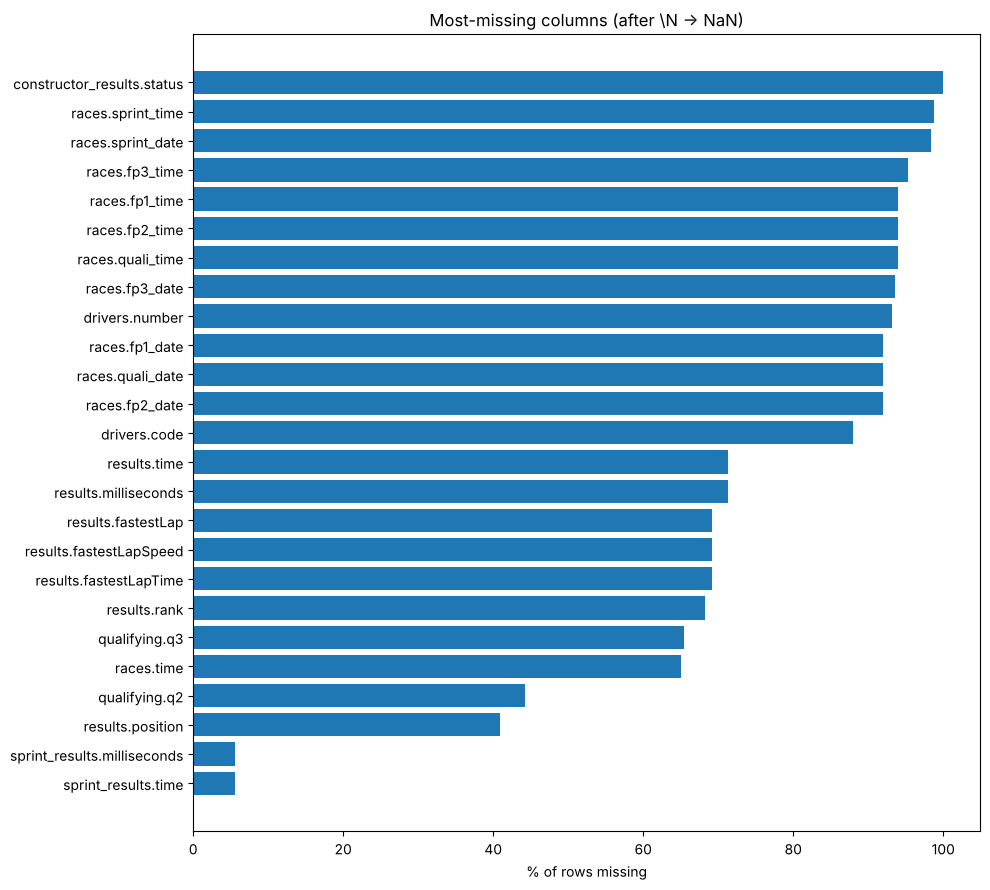

In [50]:
rows = []
for name, df in clean_tables.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            rows.append({"Table": name, "Column": col, "Missing": n, "Pct missing": round(100 * n / len(df), 1)})

miss_cols = pd.DataFrame(rows).sort_values("Pct missing", ascending=False).reset_index(drop=True)
display(miss_cols)

top = miss_cols.head(25).iloc[::-1]
plt.figure(figsize=(10, 9))
plt.barh(top["Table"] + "." + top["Column"], top["Pct missing"])
plt.xlabel("% of rows missing")
plt.title("Most-missing columns (after \\N -> NaN)")
plt.tight_layout()
plt.show()

**Reading the chart.** Columns such as the practice/qualifying/sprint dates in `races`, and `status` in
`constructor_results`, are missing for most rows because the thing they describe did not exist (for example, there was
no sprint on most weekends, and practice sessions were not recorded before 2021). These are **structural** and are
handled by dropping the column or converting it to a flag, not by imputing. Columns in `results` (`time`,
`milliseconds`, `fastestLap*`, `rank`, `position`) are missing because the driver retired or was not classified; they
are also post-race, so they are dropped from the feature set (section 2.4).

### 2.2.2 Qualifying coverage per season
The brief warns about *historical qualifying-coverage drift* and says we believe `qualifying.csv` starts in the
mid-1990s, but that this must be confirmed from our own copy. Coverage is the share of result rows in a season that
have a matching qualifying row.

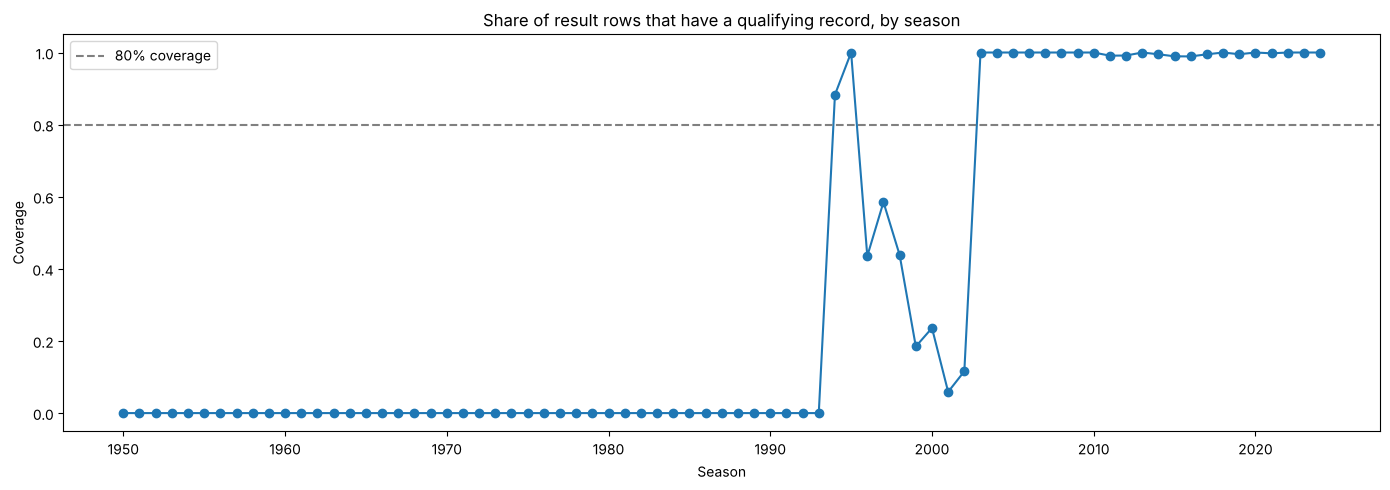

First season with any qualifying data: 1994


,coverage
year,
1994,0.88
1995,1.00
1996,0.44
1997,0.59
1998,0.44
1999,0.18
2000,0.24
2001,0.06
2002,0.12


In [51]:
q_keys = (
    clean_tables["qualifying"][["raceId", "driverId"]]
    .drop_duplicates()
    .assign(has_quali=1)
)
cov = res_eda.merge(q_keys, on=["raceId", "driverId"], how="left")
cov["has_quali"] = cov["has_quali"].fillna(0)

quali_coverage = cov.groupby("year")["has_quali"].mean()

plt.figure(figsize=(14, 5))
plt.plot(quali_coverage.index, quali_coverage.values, marker="o")
plt.axhline(0.8, linestyle="--", color="gray", label="80% coverage")
plt.title("Share of result rows that have a qualifying record, by season")
plt.xlabel("Season")
plt.ylabel("Coverage")
plt.legend()
plt.tight_layout()
plt.show()

first_year = quali_coverage[quali_coverage > 0].index.min()
print("First season with any qualifying data:", first_year)
display(quali_coverage[quali_coverage > 0].head(12).round(2).to_frame("coverage"))

**Decision input.** The first season with any qualifying data confirms (or corrects) the brief's mid-1990s belief.
Section 2.5 turns this into a concrete modelling window using an explicit rule (the first season from which coverage
stays at or above 80%).

### 2.2.3 What does `grid = 0` mean?
The brief states that `grid = 0` means a pit-lane start and asks us to verify it. `grid = 0` can hide two different
things: a driver who really started from the pit lane (a race starter) and a driver who **never started** (failed to
qualify or withdrew). The brief says non-starters have result rows too and asks us to decide whether they belong in the
modelling table. We cross-tabulate `grid = 0` against `positionText` (`F` = failed to qualify, `W` = withdrawn,
`R` = retired, `D` = disqualified ...) and against the status text.

Rows with grid == 0: 1638 (6.1% of all result rows)


positionText,10,11,12,13,14,15,16,17,18,19,20,5,7,8,9,D,E,F,R,W
era,,,,,,,,,,,,,,,,,,,,
1950-57 front-engine,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,20,0,15
1958-65 rear-engine,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,93,0,120
1966-76 3L & wings,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,148,0,20
1977-88 turbo/ground-effect,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,5,534,1,26
1989-94 post-turbo,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,1,539,0,9
1995-2008 V10/V8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,10,0,4
2009-13 late V8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,0,3
2014-21 turbo-hybrid,5,0,1,4,0,2,5,3,2,1,1,2,0,1,0,0,0,0,9,3
2022-24 ground-effect,2,4,2,3,3,4,1,6,4,0,0,1,1,0,2,0,0,0,4,3


,rows
status,
Did not qualify,1013
Did not prequalify,331
Withdrew,164
+1 Lap,27
Finished,22
Accident,20
Injury,8
+2 Laps,7
Engine,6


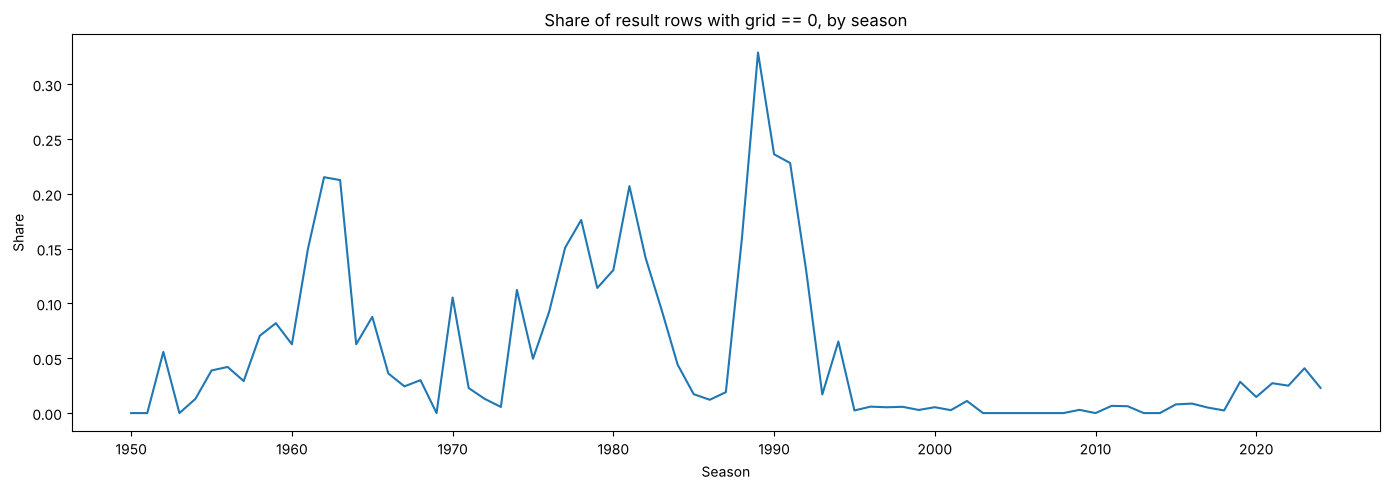

In [52]:
grid0 = res_eda[res_eda["grid"] == 0]
print("Rows with grid == 0:", len(grid0), f"({100*len(grid0)/len(res_eda):.1f}% of all result rows)")

display(pd.crosstab(grid0["era"], grid0["positionText"]))
display(grid0["status"].value_counts().head(15).to_frame("rows"))

share = res_eda.groupby("year")["grid"].apply(lambda s: (s == 0).mean())
plt.figure(figsize=(14, 5))
plt.plot(share.index, share.values)
plt.title("Share of result rows with grid == 0, by season")
plt.xlabel("Season"); plt.ylabel("Share")
plt.tight_layout(); plt.show()

**Reading the output.** `positionText = F` or `W` and statuses like *Did not qualify* / *Did not prequalify* mark
**non-starters**: they never had a grid slot. `grid = 0` rows with other texts (`R`, numeric positions) are
**race starters** whose slot was recorded as 0, i.e. pit-lane starts (or unrecorded grids in the early years). Section
2.3 separates the two groups with this rule.

### 2.2.4 Podium rate and field size by era
The brief says podiums are about 15% of rows in the modern era and far fewer when fields have 30+ entrants. This
confirms that statement with our data and shows why a single global base rate is misleading.

,rows,podium_rate,avg_field
era,,,
1950-57 front-engine,1571,0.136,27.033
1958-65 rear-engine,1768,0.131,24.244
1966-76 3L & wings,3237,0.129,24.170
1977-88 turbo/ground-effect,5234,0.108,28.090
1989-94 post-turbo,3035,0.095,32.255
1995-2008 V10/V8,5138,0.140,21.578
2009-13 late V8,2150,0.131,22.979
2014-21 turbo-hybrid,3267,0.147,20.458
2022-24 ground-effect,1359,0.150,19.986


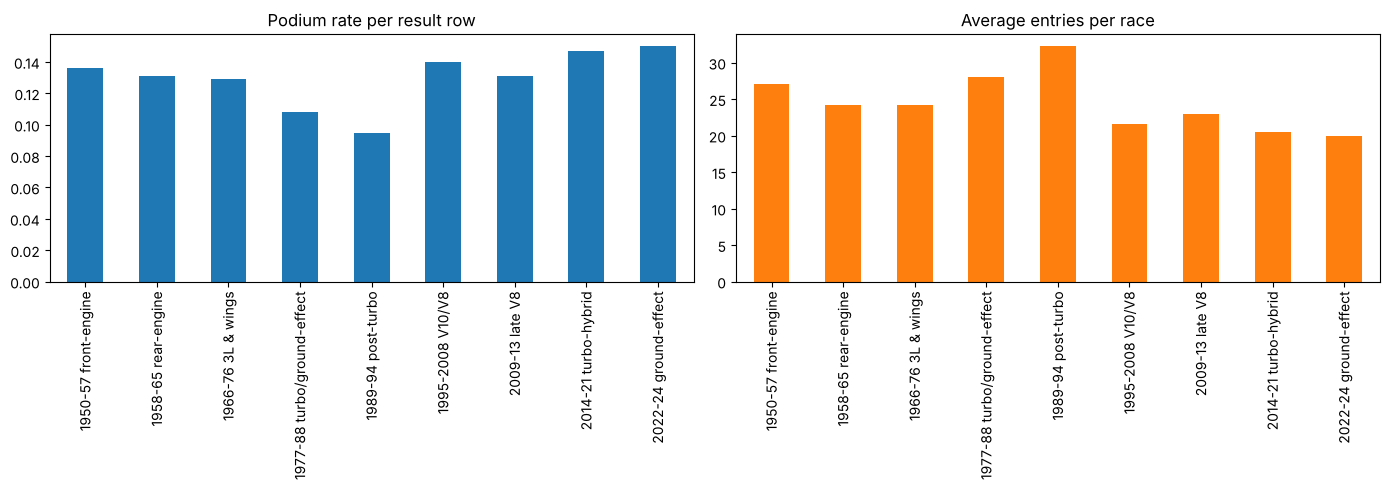

In [53]:
field = res_eda.groupby("raceId").size().rename("field_size")
era_stats = (
    res_eda.merge(field, on="raceId")
    .groupby("era", observed=True)
    .agg(rows=("resultId", "size"), podium_rate=("podium_raw", "mean"), avg_field=("field_size", "mean"))
    .round(3)
)
display(era_stats)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
era_stats["podium_rate"].plot(kind="bar", ax=ax[0]); ax[0].set_title("Podium rate per result row"); ax[0].set_xlabel("")
era_stats["avg_field"].plot(kind="bar", ax=ax[1], color="tab:orange"); ax[1].set_title("Average entries per race"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 2.2.5 Where do the duplicate driver-race rows come from?
Section 1.7 found 85 duplicated `(raceId, driverId)` groups. The brief explains why: until 1957 shared drives meant a
driver could appear in two cars in one race. Here we check that the duplicates sit in those early years.

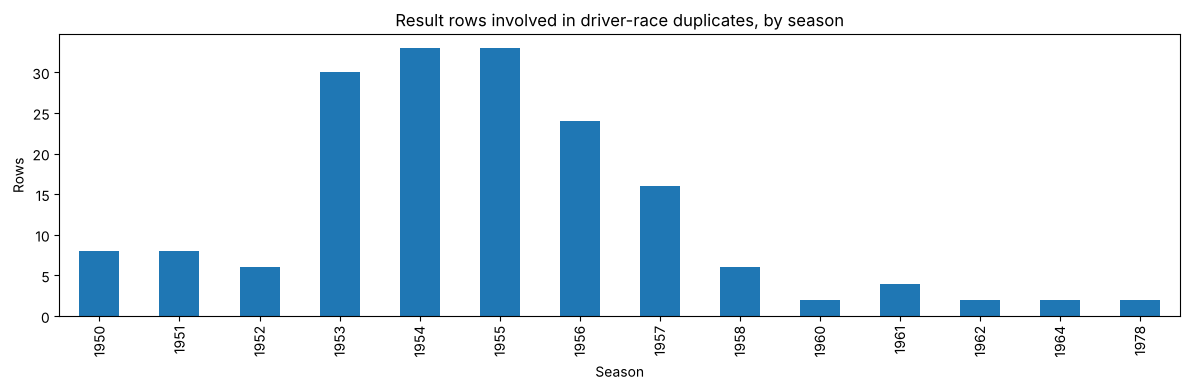

Years with duplicates: 1950 to 1978


In [54]:
dup_flag = res_eda.duplicated(subset=["raceId", "driverId"], keep=False)
dup_by_year = res_eda[dup_flag].groupby("year").size()

plt.figure(figsize=(12, 4))
dup_by_year.plot(kind="bar")
plt.title("Result rows involved in driver-race duplicates, by season")
plt.xlabel("Season"); plt.ylabel("Rows")
plt.tight_layout(); plt.show()

print("Years with duplicates:", dup_by_year.index.min(), "to", dup_by_year.index.max())

### 2.2.6 Retirement rate by era
The brief says retirement rates were far higher in the early decades, so a good grid slot converted to a podium much
less reliably. Per the brief, `Finished`, `+1 Lap`, `+2 Laps` ... count as reaching the flag; everything else is a
reason for stopping.

,retirement_rate
era,
1950-57 front-engine,0.505
1958-65 rear-engine,0.530
1966-76 3L & wings,0.525
1977-88 turbo/ground-effect,0.593
1989-94 post-turbo,0.610
1995-2008 V10/V8,0.387
2009-13 late V8,0.198
2014-21 turbo-hybrid,0.186
2022-24 ground-effect,0.143


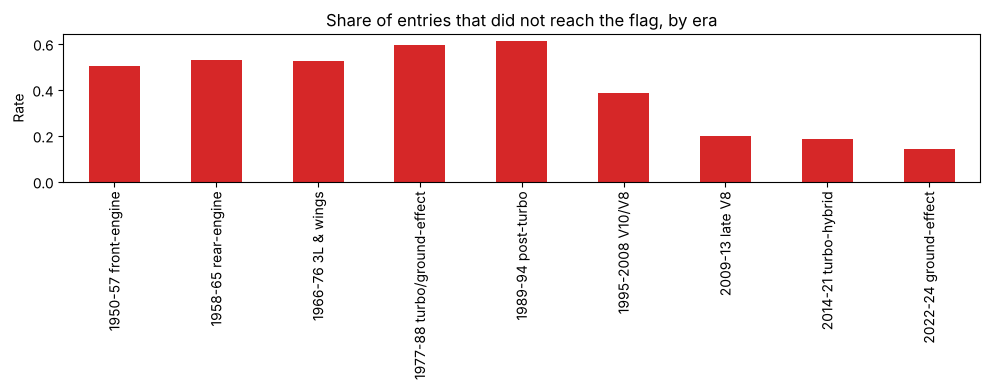

In [55]:
res_eda["reached_flag"] = res_eda["status"].fillna("").str.match(r"^(Finished|\+\d+ Laps?)$")
ret_by_era = (1 - res_eda.groupby("era", observed=True)["reached_flag"].mean()).round(3)
display(ret_by_era.to_frame("retirement_rate"))

ret_by_era.plot(kind="bar", figsize=(10, 4), color="tab:red")
plt.title("Share of entries that did not reach the flag, by era")
plt.xlabel(""); plt.ylabel("Rate")
plt.tight_layout(); plt.show()

### Part 2.2 findings

- Missing values are mostly **structural** (sessions that did not exist, post-race fields for retirements); only small
  pockets are genuine gaps.
- Qualifying coverage starts late and is patchy, so qualifying features cannot be assumed for the whole 1950-2024 range.
- `grid = 0` mixes pit-lane starters with non-starters; they need different treatment.
- Podium rate, field size and retirement rate all drift strongly by era, which is why the split and era columns are
  added later.
- Duplicates are confined to 1950-1978: 76 shared-drive groups up to 1957 and 9 later groups, of which 3 are double
  non-starter entries rather than shared drives (section 1.7.1).

## 2.3 Row-level cleaning

Three row-level decisions, each documented as the brief requires:

1. **Exclude the Indianapolis 500.** It counted for the championship in 1950-1960 but almost no F1 regulars entered, its
   drivers rarely raced elsewhere, and it has a different grid structure. It inflates race counts for American drivers
   and distorts the home-race analysis. Excluding it is the defensible choice named in the brief.
2. **Remove entries that were never part of the starting field, and only those.** The prediction is made *after
   qualifying*, so the question is: was this driver on the grid at that moment?
   - **Failed to qualify** (`positionText = F`, or status *Did not qualify* / *Did not prequalify* / *107% Rule*):
     known after qualifying, never in the race. **Dropped**, whatever value `grid` holds (some of these rows carry the
     slot they would have had, e.g. 21 or 22).
   - **Withdrew without a grid slot** (`grid = 0` and `positionText = W`, or status *Withdrew* with 0 laps):
     never in the starting field. **Dropped**.
   - **Did not start despite having a grid slot** (`positionText = W` with `grid > 0`, e.g. the 2005 United States GP,
     where 14 qualified cars withdrew on race day): at the prediction cutoff these drivers *were* on the grid. Removing
     them would filter rows using race-day information, so they are **kept** with label 0.
   - **Pit-lane starters** (`grid = 0` but the driver raced) are real starters and are kept with a flag.
3. **One row per `(raceId, driverId)`**, using the rule justified in section 1.7.

In [56]:
res = clean_tables["results"].copy()
res = res.merge(status_c, on="statusId", how="left")          # `status` text
res = res.merge(races_c[["raceId", "year", "name"]].rename(columns={"name": "race_name"}), on="raceId", how="left")
n_start = len(res)

# 1) Indianapolis 500
indy_mask = res["race_name"].eq("Indianapolis 500")
n_indy = int(indy_mask.sum())
print("Indianapolis 500 rows removed:", n_indy, "| seasons:", sorted(int(y) for y in res.loc[indy_mask, "year"].unique()))
res = res[~indy_mask]

# 2) Entries that were never part of the starting field
failed_to_qualify = (
    res["positionText"].eq("F")
    | res["status"].isin(["Did not qualify", "Did not prequalify", "107% Rule"])
)
withdrew_no_slot = (res["grid"] == 0) & (
    res["positionText"].eq("W") | (res["status"].eq("Withdrew") & res["laps"].eq(0))
)
nonstarter = failed_to_qualify | withdrew_no_slot
n_failed_q = int(failed_to_qualify.sum())
n_withdrew_no_slot = int((withdrew_no_slot & ~failed_to_qualify).sum())

dns_with_slot = ~nonstarter & res["positionText"].eq("W") & (res["grid"] > 0)
n_dns_with_slot = int(dns_with_slot.sum())

print("Failed to qualify, removed:", n_failed_q, "(of which with grid > 0:", int((failed_to_qualify & (res['grid'] > 0)).sum()), ")")
print("Withdrew without a grid slot, removed:", n_withdrew_no_slot)
print("Did not start despite a grid slot, kept (label 0):", n_dns_with_slot,
      "| podiums among them:", int((res.loc[dns_with_slot, "positionOrder"] <= 3).sum()))
display(res.loc[nonstarter, "status"].value_counts().head(12).to_frame("removed rows by status"))

res = res[~nonstarter].copy()

# Remaining grid == 0 rows are race starters recorded without a slot: pit-lane starts
res["pit_lane_start"] = (res["grid"] == 0).astype(int)
n_pit_lane = int(res["pit_lane_start"].sum())
print("Pit-lane / unrecorded-grid starters kept (flagged):", n_pit_lane)

Indianapolis 500 rows removed: 405 | seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
Failed to qualify, removed: 1368 (of which with grid > 0: 20 )
Withdrew without a grid slot, removed: 203
Did not start despite a grid slot, kept (label 0): 133 | podiums among them: 0


,removed rows by status
status,
Did not qualify,1025
Did not prequalify,331
Withdrew,164
Accident,18
107% Rule,9
Injury,9
Engine,6
Safety concerns,2
Injured,2


Pit-lane / unrecorded-grid starters kept (flagged): 87


Chart of the row-level decisions on `results` (red = removed, green = kept).

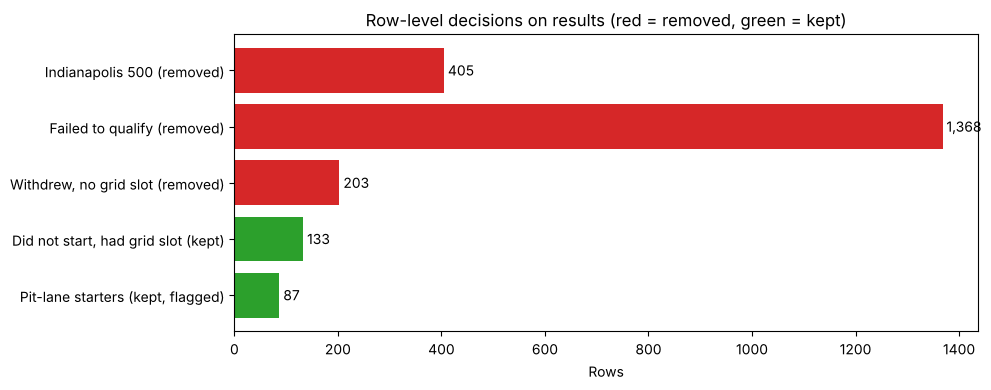

In [57]:
fig, ax = plt.subplots(figsize=(10, 4))
reasons = pd.Series({
    "Indianapolis 500 (removed)": n_indy,
    "Failed to qualify (removed)": n_failed_q,
    "Withdrew, no grid slot (removed)": n_withdrew_no_slot,
    "Did not start, had grid slot (kept)": n_dns_with_slot,
    "Pit-lane starters (kept, flagged)": n_pit_lane,
})
colors = ["tab:red"] * 3 + ["tab:green"] * 2
ax.barh(reasons.index[::-1], reasons.values[::-1], color=colors[::-1])
for i, v in enumerate(reasons.values[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Row-level decisions on results (red = removed, green = kept)")
ax.set_xlabel("Rows")
plt.tight_layout(); plt.show()

Apply the duplicate rule: keep one row per `(raceId, driverId)` and compare the resulting podium label with the "any car" reference label.

In [58]:
# 3) One row per (raceId, driverId): prefer a real grid slot, then best positionOrder, then resultId
before_dedup = len(res)
res = res.sort_values(
    ["raceId", "driverId", "pit_lane_start", "positionOrder", "resultId"]
)
kept = res.drop_duplicates(subset=["raceId", "driverId"], keep="first").copy()
n_dup_removed = before_dedup - len(kept)

# Label from the kept row (consistent with its own position/points/grid)
kept["podium"] = (kept["positionOrder"] <= 3).astype(int)

# Compare with the reference 'podium in any car' label from section 1.7
old_label = driver_race_target.set_index(["raceId", "driverId"])["podium"]
new_label = kept.set_index(["raceId", "driverId"])["podium"]
cmp = pd.concat([old_label.rename("any_car"), new_label.rename("kept_row")], axis=1, join="inner")
print("Rows before dedup:", before_dedup, "| after:", len(kept), "| shared-drive rows removed:", n_dup_removed)
print("Driver-races whose label differs from the 'any car' reference:", int((cmp["any_car"] != cmp["kept_row"]).sum()))
print("Duplicate pairs remaining:", int(kept.duplicated(["raceId", "driverId"]).sum()))
print("Total rows dropped from raw results:", n_start - len(kept))

dup_years = res_eda.loc[res_eda.duplicated(["raceId", "driverId"], keep=False), "year"]
DUP_RACE_IDS = set(res_eda.loc[res_eda.duplicated(["raceId", "driverId"], keep=False), "raceId"])
print("Shared-drive duplicates occur in seasons", int(dup_years.min()), "to", int(dup_years.max()))

Rows before dedup: 24783 | after: 24719 | shared-drive rows removed: 64
Driver-races whose label differs from the 'any car' reference: 0
Duplicate pairs remaining: 0
Total rows dropped from raw results: 2040
Shared-drive duplicates occur in seasons 1950 to 1978


**Why this rule.**

- **It is correct for the target.** In a shared drive the official classification credits the driver with each car's
  result. The question "did this driver finish on the podium?" is answered yes if any of those classifications is a
  podium. Keeping the best-classified row gives exactly that answer (the label matches the "any car" reference in every
  pair, printed above) while the label, `position`, `points` and `grid` of the kept row still come from one real row and
  never contradict each other.
- **The alternative is not available in the data.** "Keep the car the driver started in" would be the ideal pre-race
  rule, but section 1.7 showed that almost every duplicated row has its own grid slot, so the starting car cannot be
  identified.
- **Its leakage risk is contained.** Choosing a row by finishing position uses post-race information, so the kept row's
  `grid` could belong to a car taken over mid-race. All shared drives happen in 1950-1978, before the 2003+ modelling
  window, so they never reach `model_table`; this is asserted in section 2.9. They only remain in `model_table_full`.

**Caveat on the check above.** The kept row is the one with the best `positionOrder`, so its label equals the "podium in
any car" label **by construction**: the 0 differences are a consistency check, not independent evidence. The rule also
selects a row with post-race information. The next cell measures how much that matters by repeating the deduplication with a
rule that uses **no** post-race field (real grid slot first, then lowest `resultId`) and counting the labels that change.

In [ ]:
alt = res.sort_values(["raceId", "driverId", "pit_lane_start", "resultId"]).drop_duplicates(["raceId", "driverId"], keep="first")
alt_label = (alt["positionOrder"] <= 3).astype(int).rename("pre_race_rule").to_frame().assign(raceId=alt["raceId"], driverId=alt["driverId"])
chk = kept[["raceId", "driverId", "podium", "year"]].merge(alt_label, on=["raceId", "driverId"])
dup_keys = set(map(tuple, res.loc[res.duplicated(["raceId", "driverId"], keep=False), ["raceId", "driverId"]].to_numpy()))
chk = chk[[(r, d) in dup_keys for r, d in zip(chk["raceId"], chk["driverId"])]]
print("Duplicated driver-races:", len(chk))
print("Label differs between the best-positionOrder rule and a pre-race-only rule:", int((chk["podium"] != chk["pre_race_rule"]).sum()))
print("Seasons of the groups whose label changes:", sorted(chk.loc[chk["podium"] != chk["pre_race_rule"], "year"].unique().tolist()))

**Result.** Of the 61 driver-races that are still duplicated at this point, **15 change their label** when the post-race
selection is replaced by a pre-race-only rule, all in 1950-1960. None is from 2003 onward, so `model_table` is unaffected
(asserted in 2.9), but the 15 labels in `model_table_full` depend on the chosen rule. This is the real cost of the rule, and
the reason `model_table_full` is not used for the modelling experiments.

## 2.4 Missing values in `results`: drop post-race columns, do not impute

The remaining `NaN`s in `results` (`position`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`,
`fastestLapSpeed`) mean *the driver retired / was not classified / set no ranked lap*. They are **informative missing
values**, not errors:

- Filling `time` or `milliseconds` with a number would invent a finishing time for a car that never finished.
- Filling `position` would invent a classification.
- More importantly, every one of these columns is only known **after the race** (the brief: "Post-race, never a
  feature"). Imputing them would be pointless and keeping them would be leakage.

So they are **dropped from the modelling table**. The information that is needed for later questions (the target source
`positionOrder`, `statusId` for the mechanical-failure analysis, `points`, `laps`) is stored in a separate
`post_race_info` table keyed by `(raceId, driverId)`, so it can never leak into a feature set by accident.

`number` (car number, 6 missing values) is an identifier, not a performance signal, and the brief notes it was not fixed
in early years; it is dropped rather than imputed. This also corrects the earlier note that the missing numbers were
`0`: they are `NaN` and are not used.

In [59]:
POST_RACE_COLS = [
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
]

post_race_info = kept[["raceId", "driverId", "constructorId", "positionOrder", "positionText",
                       "points", "laps", "statusId", "status"]].reset_index(drop=True)

core = kept.drop(columns=[c for c in POST_RACE_COLS + ["number", "race_name", "year"] if c in kept.columns]).reset_index(drop=True)
print("Columns kept in the core table:", list(core.columns))
print("Post-race table:", post_race_info.shape)

Columns kept in the core table: ['resultId', 'raceId', 'driverId', 'constructorId', 'grid', 'pit_lane_start', 'podium']
Post-race table: (24719, 9)


## 2.5 Grid and qualifying: fill or flag

### 2.5.1 Grid position for pit-lane starters
`grid = 0` is a code, not a position. Left as 0, it would tell a model that the driver started *ahead of pole*. The
brief says a pit-lane start is the **back of the field in practice**, so we fill it with
`(largest real grid slot in that race) + (order among that race's pit-lane starters)`. The raw value is kept in `grid`
and the flag `pit_lane_start` stays, so nothing is hidden.

In [60]:
core = core.sort_values(["raceId", "resultId"]).reset_index(drop=True)

max_grid = core.loc[core["grid"] > 0].groupby("raceId")["grid"].max()
core["max_grid_in_race"] = core["raceId"].map(max_grid).fillna(0)
core["pit_order"] = core.groupby("raceId")["pit_lane_start"].cumsum()

core["grid_model"] = np.where(
    core["pit_lane_start"] == 1,
    core["max_grid_in_race"] + core["pit_order"],
    core["grid"],
).astype(int)

core = core.drop(columns=["max_grid_in_race", "pit_order"])
print("Rows whose grid was refilled:", int(core["pit_lane_start"].sum()))
print("Any grid_model == 0 left:", int((core["grid_model"] == 0).sum()))

Rows whose grid was refilled: 87
Any grid_model == 0 left: 0


### 2.5.2 Qualifying features
`q1`, `q2`, `q3` are lap-time strings such as `1:26.572` (converted to seconds in section 1.3). **A missing `q2` or `q3` has two
different meanings, and they must not be mixed:**

- **The session did not exist.** Qualifying was a single-lap session in 2003-2004, a single / aggregate session in 2005 and a
  three-part knockout only from 2006 (the check below the code shows `q3` empty for 100% of 2003-2005 rows and `q2` for
  100% of 2003-2004 rows). `q2_reached` / `q3_reached` are **`NaN`** there, not 0, because "reached Q2" is undefined when
  there is no Q2. Writing 0 would make a 2004 driver look like a 2015 driver who was knocked out in Q1.
- **The driver was eliminated.** In a knockout race a missing `q2` / `q3` means the driver was knocked out in an earlier part
  (the brief: "drivers knocked out early have `\N` for later parts"). The flags are 0 for those rows, 1 for drivers who set
  a time, and a driver with no qualifying record at all counts as "did not reach" (`has_quali = 0` marks them).

A race is a **knockout race** when at least one `q3` time exists for it. This is the same definition as `knockout_quali` in
Task 3, which later re-encodes the structural case as 0 next to that flag; Task 1 keeps the honest `NaN`. The column
`quali_format` (single_lap / aggregate / knockout / none) is added to the identifier columns so the format stays visible and
can be used to stratify. It is not a feature.

The other qualifying features:

- use the times in **seconds** (converted in section 1.3);
- take the driver's **best lap** and express it as a **gap to the fastest qualifier in that race**. This gap is *not*
  like-with-like across formats: a driver eliminated in Q1 only has a Q1 time, but the pole was set in Q3 on a faster track;
- add **`q1_gap_pct`**, the gap between the driver's **Q1** time and the fastest Q1 time of the same race. Every driver of
  every format has a Q1 time, so this gap is comparable across drivers, races and formats;
- keep `qual_position` as recorded.

The 68 true `NaN`s in `qualifying` (22 in `q2`, 46 in `q3`) are all in 2023-2024. The cell after the code tests, instead of
assuming, that they mean the same as the `\N` ones.

In [ ]:
# q1/q2/q3 were already converted to seconds in section 1.3
qual = clean_tables["qualifying"].copy()
for c in ["q1", "q2", "q3"]:
    qual[c + "_s"] = qual[c]

qual["qual_position"] = pd.to_numeric(qual["position"], errors="coerce")
qual["q2_reached"] = qual["q2_s"].notna().astype(int)
qual["q3_reached"] = qual["q3_s"].notna().astype(int)
qual["q_best_s"] = qual[["q1_s", "q2_s", "q3_s"]].min(axis=1)

# a knockout race has at least one q3 time (same definition as `knockout_quali` in Task 3)
race_knockout = (qual.groupby("raceId")["q3_s"].count() > 0).astype(int)

# the qualifying key must be unique before merging
print("Duplicate (raceId, driverId) in qualifying:", int(qual.duplicated(["raceId", "driverId"]).sum()))
qual = qual.sort_values(["raceId", "driverId", "qualifyId"]).drop_duplicates(["raceId", "driverId"], keep="first")

# Gap to the fastest qualifier of the same race, in percent
pole_time = qual.groupby("raceId")["q_best_s"].transform("min")
qual["q_gap_pct"] = 100 * (qual["q_best_s"] / pole_time - 1)

# Like-with-like gap: every driver of every format has a Q1 time, so compare Q1 with the fastest Q1
q1_fastest = qual.groupby("raceId")["q1_s"].transform("min")
qual["q1_gap_pct"] = 100 * (qual["q1_s"] / q1_fastest - 1)

qual_feats = qual[["raceId", "driverId", "qual_position", "q2_reached", "q3_reached", "q_best_s", "q_gap_pct", "q1_gap_pct"]]
core = core.merge(qual_feats, on=["raceId", "driverId"], how="left")

core["has_quali"] = core["qual_position"].notna().astype(int)

# q2/q3 flags: 0/1 in knockout races (no qualifying record = did not reach), NaN where the session did not exist
core["knockout_quali"] = core["raceId"].map(race_knockout).fillna(0).astype(int)
in_knockout = core["knockout_quali"] == 1
for c in ["q2_reached", "q3_reached"]:
    core[c] = np.where(in_knockout, core[c].fillna(0), np.nan)

print("Rows with a qualifying record:", int(core["has_quali"].sum()), "of", len(core))
print("q2_reached / q3_reached are NaN (no such session) for", int((~in_knockout).sum()), "of", len(core), "rows")

**Check: do the real `NaN`s mean the same as `\N`?** The 68 real `NaN`s in `qualifying` all sit in 2023-2024, while every other
season marks a missing `q2`/`q3` with `\N`. That looks like a different export, so the assumption that both mean "eliminated"
is tested instead of assumed: the missing cells must (1) only occur for the lower grid positions, (2) never have a later
session filled when an earlier one is missing, and (3) the 2023-24 rows must not differ in time format from earlier seasons.

In [ ]:
q_raw = tables["qualifying"].merge(tables["races"][["raceId", "year"]], on="raceId")
q_raw["pos"] = pd.to_numeric(q_raw["position"], errors="coerce")
recent = q_raw[q_raw["year"] >= 2021].copy()

def kind(col):
    return np.where(recent[col].isna(), "real NaN", np.where(recent[col].eq(r"\N"), r"\N", "time"))

for col in ["q2", "q3"]:
    recent[col + "_kind"] = kind(col)
    print(f"{col}: how the cell is stored, by season")
    display(pd.crosstab(recent["year"], recent[col + "_kind"]))

for col in ["q2", "q3"]:
    sub = recent[recent[col + "_kind"] != "time"]
    display(sub.groupby(col + "_kind")["pos"].agg(["count", "min", "median", "max"]).rename(columns=lambda c: f"{col} missing: position {c}"))

q2_missing = recent["q2_kind"] != "time"; q3_present = recent["q3_kind"] == "time"
print("Rows with q3 present while q2 is missing (must be 0):", int((q2_missing & q3_present).sum()))

# time-format drift: every q1 string from 2003 on must look like m:ss.mmm
fmt_ok = q_raw["q1"].astype(str).str.fullmatch(r"\d:\d{2}\.\d{3}")
present = q_raw[(q_raw["year"] >= 2003) & q_raw["q1"].notna() & q_raw["q1"].ne(r"\N")]
bad = present[~fmt_ok.loc[present.index]]
print("q1 strings (2003+) not in m:ss.mmm format:", len(bad), "| seasons:", sorted(bad["year"].unique().tolist()))

**Result.** The assumption holds. For both `q2` and `q3` the real `NaN`s occur only at the bottom of the order (positions
15-19 for `q2`, 10-20 for `q3`, inside the ranges of the `\N` cells), no row has a `q3` time with a missing `q2`, and every
`q1` string from 2003 on has the same `m:ss.mmm` format, so the 2023-24 rows show no format drift. The 68 real `NaN`s are
treated exactly like the `\N` ones. (One `\N` `q3` sits at position 9: a driver in the top 10 who set no Q3 time.)

### 2.5.3 Fallback and modelling window
The brief offers three options for years with no qualifying data: impute, fall back to grid, or restrict the training
window. We use two of them together, each applied where it is honest:

- **`qual_position_filled`**: falls back to `grid_model` when qualifying is missing. The fallback is legitimate because
  the brief notes that for most of history the grid *is* the only record of the starting order, and qualifying position
  and grid are close to each other. The flag `has_quali` tells a model which rows were filled. Time-based features
  (`q_best_s`, `q_gap_pct`, `q1_gap_pct`) are **not** imputed: a made-up lap time would be fiction, so they stay `NaN` where no
  qualifying exists.
- **Restricted window**: we define `QUALI_START_YEAR` as the first season from which coverage stays at or above 80%
  (computed from the coverage chart, not hard-coded). `model_table` (the main table) contains only seasons from that
  year onward, so qualifying features are real. `model_table_full` keeps all years and carries the flags, for
  experiments that use the long history.

In [ ]:
core = core.merge(races_c[["raceId", "year", "round", "circuitId", "date"]], on="raceId", how="left")
core["qual_position_filled"] = core["qual_position"].fillna(core["grid_model"])
core["quali_format"] = np.select(
    [core["knockout_quali"] == 1, core["year"].between(2003, 2004), core["year"] == 2005],
    ["knockout", "single_lap", "aggregate"], default="none")      # none = no qualifying data, or a race whose Q3 never ran
print(core.groupby("quali_format")["year"].agg(["min", "max", "count"]))

cov_year = core.groupby("year")["has_quali"].mean()
ok = cov_year[cov_year >= 0.8]
QUALI_START_YEAR = None
for y in ok.index:
    if (cov_year.loc[y:] >= 0.8).all():
        QUALI_START_YEAR = int(y)
        break
if QUALI_START_YEAR is None:
    QUALI_START_YEAR = 1996    # fallback to the brief's "mid-1990s" belief
    print("No season met the rule; falling back to", QUALI_START_YEAR)
print("QUALI_START_YEAR =", QUALI_START_YEAR)

plt.figure(figsize=(14, 4))
plt.plot(cov_year.index, cov_year.values)
plt.axvline(QUALI_START_YEAR, color="red", linestyle="--", label=f"modelling window starts {QUALI_START_YEAR}")
plt.axhline(0.8, color="gray", linestyle=":")
plt.title("Qualifying coverage after cleaning and chosen window start")
plt.legend(); plt.tight_layout(); plt.show()

## 2.6 Pre-race context features

All features here are known **before the race starts**.

### 2.6.1 Races: flags instead of mostly-empty columns
`fp1/fp2/fp3/quali/sprint` date and time columns in `races` are 85-99% missing: practice sessions are not in the
dataset before 2021, and the brief says practice "is not in the Kaggle dataset". Imputing dates for sessions that never
existed is meaningless and the times are not predictive, so we **drop them**. The one exception is `sprint_date`:
its presence means "this was a sprint weekend", which the brief calls out as a format change. We keep that information as
`is_sprint_weekend` (1 if `sprint_date` exists).

`sprint_results.csv` itself is **not used**. The brief calls it a leakage judgement call. For 2021-2022 the sprint
result already sets the Sunday grid, so `grid` carries that information; for 2023+ it is a separate session. Using
sprint results only for some years would make the feature inconsistent, so we keep the safe choice and use the flag
only.

In [ ]:
race_info = races_c[["raceId", "sprint_date"]].copy()
race_info["is_sprint_weekend"] = race_info["sprint_date"].notna().astype(int)
core = core.merge(race_info[["raceId", "is_sprint_weekend"]], on="raceId", how="left")
print(core["is_sprint_weekend"].value_counts())

### 2.6.2 Driver age
`dob` is complete after sentinel handling; the missing `\N`s in `drivers` are only in `code` and `number`, which are
dropped as non-features. Age at the race date is known in advance and is a legitimate feature.

In [ ]:
drv = clean_tables["drivers"][["driverId", "dob", "nationality"]]
core = core.merge(drv, on="driverId", how="left")
core["driver_age"] = (core["date"] - core["dob"]).dt.days / 365.25
print("Missing dob:", int(core["dob"].isna().sum()), "| missing age:", int(core["driver_age"].isna().sum()))

### 2.6.3 Home race
The brief says the home-race question needs a mapping from driver nationality (e.g. `British`) to circuit country
(e.g. `UK`). The mapping below is written out explicitly so it can be reviewed. Dual nationalities (such as
`Argentine-Italian`) are split and the driver counts as at home if **any** of them matches. Nationalities with no
circuit in their country (for example Finnish) are never "home".

In [ ]:
NAT_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Azerbaijani": "Azerbaijan", "Bahraini": "Bahrain", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chinese": "China", "Dutch": "Netherlands",
    "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Italian": "Italy", "Japanese": "Japan", "Korean": "Korea", "Malaysian": "Malaysia",
    "Mexican": "Mexico", "Monegasque": "Monaco", "Moroccan": "Morocco", "Portuguese": "Portugal",
    "Qatari": "Qatar", "Russian": "Russia", "Saudi": "Saudi Arabia", "Singaporean": "Singapore",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
    "Turkish": "Turkey", "Emirati": "UAE",
}
circuit_country = clean_tables["circuits"].set_index("circuitId")["country"]
core["circuit_country"] = core["circuitId"].map(circuit_country)

def is_home(nat, country):
    if pd.isna(nat) or pd.isna(country):
        return 0
    return int(any(NAT_TO_COUNTRY.get(p.strip()) == country for p in re.split(r"[-/]", nat)))

core["is_home_race"] = [is_home(n, c) for n, c in zip(core["nationality"], core["circuit_country"])]

# Review aids: circuit countries and nationalities that the mapping cannot match
known_countries = set(NAT_TO_COUNTRY.values())
print("Circuit countries with no nationality mapping:", sorted(set(circuit_country) - known_countries))
unmapped_nat = sorted({p.strip() for n in core["nationality"].dropna().unique() for p in re.split(r"[-/]", n)} - set(NAT_TO_COUNTRY))
print("Nationalities with no circuit country (never 'home'):", unmapped_nat)
print("Home-race share of rows:", round(core["is_home_race"].mean(), 4))
print("Home rows at the Las Vegas Strip (needs the USA fix):", int(core.loc[core["circuitId"] == 80, "is_home_race"].sum()))

After the text standardisation in 1.3.1, the first list is empty: every circuit country can be matched by at least one
nationality. The nationalities in the second list genuinely have no Grand Prix in their country in this dataset, so
those drivers are never "at home".

### 2.6.4 Standings "before this race"
The brief: standings are cumulative points and rank **after** each race, so they must be **shifted** to "standings
before this race" or they leak the result. For each race we find the previous round in the same season and read the
standings from that race. Using the full `races` table (which still contains the Indianapolis 500) keeps the previous
round correct even for races whose predecessor was dropped from the modelling table.

Missing values are filled with meaningful starting values, not averages:

- first race of a season (or a driver / constructor not yet in the standings): `points = 0`, `wins = 0`, and `position`
  = *worst possible* (field size + 1 for that race, i.e. not yet ranked). A flag `has_prev_standing` says whether the
  value was real.
- constructor standings start in 1958 (brief), so earlier rows get the same starting values and the flag is 0.

In [ ]:
rs = races_c[["raceId", "year", "round"]].sort_values(["year", "round"]).copy()
rs["prev_raceId"] = rs.groupby("year")["raceId"].shift(1)
core = core.merge(rs[["raceId", "prev_raceId"]], on="raceId", how="left")

ds = clean_tables["driver_standings"][["raceId", "driverId", "points", "position", "wins"]].rename(
    columns={"raceId": "prev_raceId", "points": "drv_pts_before", "position": "drv_pos_before", "wins": "drv_wins_before"})
cs = clean_tables["constructor_standings"][["raceId", "constructorId", "points", "position", "wins"]].rename(
    columns={"raceId": "prev_raceId", "points": "con_pts_before", "position": "con_pos_before", "wins": "con_wins_before"})

core = core.merge(ds, on=["prev_raceId", "driverId"], how="left")
core = core.merge(cs, on=["prev_raceId", "constructorId"], how="left")

core["has_prev_driver_standing"] = core["drv_pos_before"].notna().astype(int)
core["has_prev_constructor_standing"] = core["con_pos_before"].notna().astype(int)

field_size = core.groupby("raceId")["driverId"].transform("size")
core["drv_pts_before"] = core["drv_pts_before"].fillna(0)
core["drv_wins_before"] = core["drv_wins_before"].fillna(0)
core["drv_pos_before"] = core["drv_pos_before"].fillna(field_size + 1)
core["con_pts_before"] = core["con_pts_before"].fillna(0)
core["con_wins_before"] = core["con_wins_before"].fillna(0)
core["con_pos_before"] = core["con_pos_before"].fillna(field_size + 1)

# Leakage sanity check: pre-race points must never exceed what is possible before round 1
print("Round-1 rows with non-zero 'before' points (must be 0):", int((core.loc[core["round"] == 1, "drv_pts_before"] != 0).sum()))
print("Rows with a real previous driver standing:", int(core["has_prev_driver_standing"].sum()), "of", len(core))

## 2.7 Status grouping (for Task 2, question 3 only)

The brief defines a **mechanical retirement** as *a race start that ended early because a component of the car failed;
it excludes failures caused by a crash, by the driver, or by a regulation decision*. Instead of keyword guessing, every
one of the 139 status values is assigned explicitly to one group:

| Group | Meaning |
|---|---|
| `finished` | `Finished` or `+N Lap(s)` (reached the chequered flag) |
| `mechanical` | a car component failed (engine, gearbox, hydraulics, wheels, tyres, wings, electronics, ...) |
| `accident` | crash, collision, spin, crash damage or debris |
| `driver` | the driver could not continue (injury, illness, physical) |
| `regulation` | disqualified, excluded, underweight, failed to qualify, 107% rule |
| `other` | withdrawn, generic "Retired", not classified, out of fuel, refuelling, stalled, safety |

Judgement calls, documented so they can be reviewed:

- **Tyre / puncture / wheel / wheel nut** are counted as mechanical: the tyre and wheel are car components, and the data
  does not record whether debris caused the failure. Contact damage is recorded separately as *Collision damage*.
- **Front wing / rear wing / broken wing** are counted as mechanical for the same reason (crash damage has its own status).
- **Out of fuel, refuelling, fuel rig** are *other*: fuel calculation and pit equipment are team operations, not a
  component failure.
- **Stalled** and **Retired** are *other*: the cause (driver or car) is unknown.

This table is post-race information, so it lives with `post_race_info` and is never joined into the feature table.

In [ ]:
STATUS_GROUPS = {
    "mechanical": [
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
        "Brakes", "Differential", "Overheating", "Mechanical", "Tyre", "Driver Seat", "Puncture", "Driveshaft",
        "Fuel pressure", "Front wing", "Water pressure", "Wheel", "Throttle", "Steering", "Technical",
        "Electronics", "Broken wing", "Heat shield fire", "Exhaust", "Oil leak", "Wheel rim", "Water leak",
        "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire", "Tyre puncture", "Wheel nut",
        "Pneumatics", "Handling", "Rear wing", "Fire", "Wheel bearing", "Fuel system", "Oil line",
        "Launch control", "Fuel", "Power loss", "Vibrations", "Drivetrain", "Ignition", "Chassis", "Battery",
        "Halfshaft", "Crankshaft", "Alternator", "Safety belt", "Oil pump", "Fuel leak", "Injection",
        "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle",
        "Water pipe", "Magneto", "Supercharger", "Power Unit", "ERS", "Brake duct", "Seat", "Undertray",
        "Cooling system",
    ],
    "accident": ["Accident", "Collision", "Spun off", "Collision damage", "Fatal accident", "Damage", "Debris"],
    "driver": ["Physical", "Injured", "Injury", "Driver unwell", "Eye injury", "Illness"],
    "regulation": ["Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify", "Did not prequalify"],
    "other": ["Withdrew", "Retired", "Not classified", "Safety", "Safety concerns", "Not restarted",
              "Out of fuel", "Refuelling", "Fuel rig", "Stalled"],
}
STATUS_TO_GROUP = {s: g for g, lst in STATUS_GROUPS.items() for s in lst}
assert len(STATUS_TO_GROUP) == sum(len(v) for v in STATUS_GROUPS.values()), "a status is listed in two groups"

def group_status(s):
    if re.fullmatch(r"Finished|\+\d+ Laps?", s):
        return "finished"
    return STATUS_TO_GROUP.get(s, "UNMAPPED")

status_map = status_c.copy()
status_map["status_group"] = status_map["status"].map(group_status)

unmapped = status_map.loc[status_map["status_group"] == "UNMAPPED", "status"].tolist()
assert not unmapped, f"Statuses without a group: {unmapped}"
print("All", len(status_map), "status values are mapped.")

# The documented mapping (every status, with how many result rows use it)
rows_per_status = clean_tables["results"]["statusId"].value_counts()
status_map["result_rows"] = status_map["statusId"].map(rows_per_status).fillna(0).astype(int)
import textwrap
print("\nDocumented mapping: group -> statuses (result rows in raw results)")
for g, sub in status_map.sort_values("result_rows", ascending=False).groupby("status_group", sort=False):
    items = ", ".join(f"{s} ({n})" for s, n in zip(sub["status"], sub["result_rows"]))
    print(f"\n[{g}] {len(sub)} statuses, {int(sub['result_rows'].sum()):,} rows")
    print(textwrap.fill(items, width=110, initial_indent="  ", subsequent_indent="  "))

post_race_info = post_race_info.merge(status_map[["statusId", "status_group"]], on="statusId", how="left")
print("Unmapped status groups in post_race_info:", int(post_race_info["status_group"].isna().sum()))

grp = post_race_info["status_group"].value_counts()
grp.plot(kind="bar", figsize=(9, 4))
plt.title("How each driver-race ended (cleaned table, all seasons)")
plt.ylabel("Driver-race rows"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
display(grp.to_frame("rows"))

## 2.8 Era, split and the final modelling tables

The brief fixes the split boundaries: **train <= 2019, validation 2020-2021, test >= 2022**. They are assigned by
season, never randomly, so no future race is used to predict an earlier one. The `era` label is added so metrics can
be reported per era.

Two tables are produced:

- `model_table_full`: all seasons, with `has_quali` flags and grid fallbacks.
- `model_table`: seasons from `QUALI_START_YEAR` onward, where qualifying features are real.

Neither contains any post-race column; only the target `podium`.

In [ ]:
core = add_era(core)
core["split"] = np.select(
    [core["year"] <= 2019, core["year"].between(2020, 2021)],
    ["train", "val"],
    default="test",
)

FEATURES = [
    "grid_model", "pit_lane_start", "has_quali", "qual_position", "qual_position_filled",
    "q2_reached", "q3_reached", "q_best_s", "q_gap_pct", "q1_gap_pct",
    "drv_pts_before", "drv_pos_before", "drv_wins_before", "has_prev_driver_standing",
    "con_pts_before", "con_pos_before", "con_wins_before", "has_prev_constructor_standing",
    "is_sprint_weekend", "is_home_race", "driver_age",
]
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "era", "split", "quali_format"]

model_table_full = core[ID_COLS + FEATURES + ["podium"]].sort_values(["date", "raceId", "grid_model"]).reset_index(drop=True)
model_table = model_table_full[model_table_full["year"] >= QUALI_START_YEAR].reset_index(drop=True)

print("model_table_full:", model_table_full.shape, "| model_table:", model_table.shape)
display(model_table.groupby("split")["podium"].agg(rows="size", podium_rate="mean").round(3))

## 2.9 Validation checks

These checks make the brief's rules executable. If any assertion fails the pipeline stops, so a silent leak or a broken
grain cannot reach the modelling stage.

In [ ]:
POST_RACE_FORBIDDEN = {
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "status_group",
}

for name, t in [("model_table_full", model_table_full), ("model_table", model_table)]:
    assert not t.duplicated(["raceId", "driverId"]).any(), f"{name}: duplicate driver-race rows"
    assert not (set(t.columns) & POST_RACE_FORBIDDEN), f"{name}: post-race column present"
    assert t["podium"].isin([0, 1]).all(), f"{name}: bad target"
    assert (t["grid_model"] > 0).all(), f"{name}: grid_model still contains 0"
    assert t["podium"].notna().all()
    print(name, "grain, leakage, target and grid checks passed")

# Split order must be chronological
assert model_table_full.loc[model_table_full.split == "train", "year"].max() <= 2019
assert model_table_full.loc[model_table_full.split == "val", "year"].between(2020, 2021).all()
assert model_table_full.loc[model_table_full.split == "test", "year"].min() >= 2022
print("split boundaries respected")

# Shared-drive rows were chosen with post-race information, so they must not reach the modelling window
assert not model_table["raceId"].isin(DUP_RACE_IDS).any(), "a shared-drive race is inside model_table"
print("no shared-drive race inside model_table")

# Remaining missing values: only the expected ones should be left
remaining = model_table.isna().sum()
display(remaining[remaining > 0].to_frame("remaining NaN"))

**Expected remaining `NaN`s in `model_table`.** Three groups are left, all on purpose:

- **Qualifying times** (`q_best_s`, `q_gap_pct`, `q1_gap_pct`) and `qual_position` for the few drivers with no qualifying record
  (for example drivers who did not set a time). `has_quali` is the indicator, because inventing a lap time would be
  fabrication. `qual_position_filled` is the complete version for models that need no missing values.
- **`q2_reached` and `q3_reached`** in 2003-2005 and in any race whose Q3 never ran. These are not missing measurements but
  *not applicable*: the session did not exist. Replacing them with 0 would label a 2004 driver as "eliminated in Q1".
  `quali_format` records which case a row belongs to.
- possibly `driver_age`.

### 2.9.1 Imputed variant of the qualifying time features

The remaining `NaN`s in the time-based qualifying columns of `model_table` (`qual_position`, `q_best_s`, `q_gap_pct`; counts in the 2.9
output above) were left empty on purpose. The structural `NaN`s of `q2_reached` / `q3_reached` are not touched: they are
*not applicable*, not missing. For models that cannot take `NaN`s, this section adds an **imputed variant** next to the original columns. Nothing is overwritten.

- **Method.** A driver with no qualifying time is given the **median `q_gap_pct` of drivers who started from the same grid slot**
  (computed on the **training seasons only**, so no validation or test information enters the fill). Grid slots with no
  training data take the interpolated value of the neighbouring slots. `q_best_s_imp` is rebuilt from that gap and the
  pole time of the same race. A global mean or median is not used: the gap depends strongly on the starting position.
- **Why the grid slot.** It is known after qualifying and before the race, and it is the best available proxy for
  how slow the driver was. The target (`podium`) is never used.
- **Flag.** `q_time_imputed = 1` marks every filled row, so a model can tell real lap times from estimates.
- **`qual_position`.** Filled with `qual_position_filled` (the grid fallback from 2.5.3), as `qual_position_imp`.
- **Limit.** The filled gaps are larger than the real ones (mean 4.8% against 2.3% in this table), because drivers without a
  time are mostly slow or non-running cars; the flag `q_time_imputed` lets a model correct for that. `q1_gap_pct` is not imputed.
- **Scope.** Only `model_table` (seasons from `QUALI_START_YEAR`) is imputed. `model_table_full` keeps its `NaN`s, because
  most of its qualifying gaps are whole seasons without qualifying, which no estimate can honestly cover.

In [ ]:
# Imputed variant of the qualifying time features (adds columns, overwrites nothing)

# 1) Median gap per grid slot, fitted on training seasons inside the modelling window only
train_known = model_table_full[
    (model_table_full["split"] == "train")
    & (model_table_full["year"] >= QUALI_START_YEAR)
    & model_table_full["q_gap_pct"].notna()
]
gap_by_grid = train_known.groupby("grid_model")["q_gap_pct"].median()
all_slots = np.arange(1, int(model_table_full["grid_model"].max()) + 1)
gap_by_grid = gap_by_grid.reindex(all_slots).interpolate(limit_direction="both")

# 2) Pole time of every race (fastest best lap), to turn a gap back into seconds
race_pole_time = qual.groupby("raceId")["q_best_s"].min()

def add_imputed_times(t):
    t = t.copy()
    t["q_time_imputed"] = t["q_gap_pct"].isna().astype(int)
    t["q_gap_pct_imp"] = t["q_gap_pct"].fillna(t["grid_model"].map(gap_by_grid))
    est_seconds = t["raceId"].map(race_pole_time) * (1 + t["q_gap_pct_imp"] / 100)
    t["q_best_s_imp"] = t["q_best_s"].fillna(est_seconds)
    t["qual_position_imp"] = t["qual_position"].fillna(t["qual_position_filled"])
    return t

model_table_imputed = add_imputed_times(model_table)

# 3) Checks
new_cols = ["q_gap_pct_imp", "q_best_s_imp", "qual_position_imp"]
print("Rows imputed:", int(model_table_imputed["q_time_imputed"].sum()), "of", len(model_table_imputed))
print("Rows imputed per split:")
print(model_table_imputed.groupby("split")["q_time_imputed"].agg(["sum", "mean"]).round(3))
print("\nNaN left in the imputed columns:")
print(model_table_imputed[new_cols].isna().sum())
assert model_table_imputed[new_cols].notna().all().all(), "imputed columns still contain NaN"
assert (model_table_imputed.loc[model_table_imputed["q_time_imputed"] == 0, ["q_gap_pct", "q_best_s"]].notna().all().all())

# Original values are untouched
assert model_table_imputed["q_gap_pct"].isna().sum() == model_table["q_gap_pct"].isna().sum()

# Plausibility: imputed gaps should sit in the range of real gaps
real = model_table_imputed.loc[model_table_imputed["q_time_imputed"] == 0, "q_gap_pct"]
fake = model_table_imputed.loc[model_table_imputed["q_time_imputed"] == 1, "q_gap_pct_imp"]
display(pd.DataFrame({"real": real.describe(), "imputed": fake.describe()}).round(2))

plt.figure(figsize=(9, 4))
plt.hist(real.clip(upper=15), bins=40, alpha=0.6, density=True, label="real q_gap_pct")
plt.hist(fake.clip(upper=15), bins=40, alpha=0.6, density=True, label="imputed q_gap_pct_imp")
plt.xlabel("Gap to pole (%), clipped at 15"); plt.legend(); plt.tight_layout(); plt.show()


### 2.9.2 Leakage audit: what the checks above prove, and what they do not

The assertions in 2.9 compare **column names** with a list of forbidden post-race names. That catches an accidental
`position` or `points` column but not a post-race value that arrives under another name, and it says nothing about the rows
that were **selected** with post-race fields. This section adds two things.

**1. Which row decisions use post-race information.**

| Decision | Field used | Known after qualifying? | Effect on `model_table` |
|---|---|---|---|
| Drop *failed to qualify* | `positionText = F`, status DNQ / DNPQ / 107% | Yes (decided in qualifying) | None |
| Drop *withdrew without a grid slot* | `grid = 0` and `positionText = W` or status + `laps = 0` | Mostly (a withdrawal before the race), but `laps` and `status` are post-race | 13 rows in 11 of the 428 races of the window (counted below) |
| Keep *did not start, grid slot* | `positionText = W`, `grid > 0` | The grid slot is pre-race; the label is 0 | None |
| Flag pit-lane starters | `grid = 0` and the driver raced | The pit-lane start is announced before the race, but "raced" is read from results | 73 rows in the window |
| Shared-drive deduplication | best `positionOrder` | No | Outside the window (all 1950-78) |
| Field size used to fill standings and the pit-lane grid slot | number of rows kept per race | Only if the kept rows equal the starters | Counted below |

**2. An information-based scan.** A leaked feature is, by definition, one that carries the answer, so every numeric feature
is scored by its single-feature AUC against `podium` and anything above 0.95 is flagged. The scan is then tested on a
deliberately leaky column that is renamed to defeat the name-based check.

In [ ]:
def auc_strength(x, y):
    # Mann-Whitney AUC of one feature against the binary target, folded so 0.5 = no signal and 1.0 = perfect either way
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    r = d["x"].rank()
    n1 = int(d["y"].sum()); n0 = len(d) - n1
    auc = (r[d["y"] == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return max(auc, 1 - auc)

def information_scan(frame, features, threshold=0.95):
    scores = pd.Series({f: auc_strength(frame[f], frame["podium"]) for f in features}).sort_values(ascending=False)
    return scores, scores[scores > threshold].index.tolist()

num_feats = [f for f in FEATURES if model_table[f].nunique() > 2]
scores, flagged = information_scan(model_table, num_feats)
display(scores.head(8).round(3).to_frame("single-feature AUC (folded)"))
assert not flagged, f"features that look like leakage: {flagged}"
print("Information scan on the real features: nothing above 0.95")

# Negative test: a post-race value under an innocent name
leaky = model_table.merge(post_race_info[["raceId", "driverId", "positionOrder"]].rename(columns={"positionOrder": "season_rank_score"}),
                          on=["raceId", "driverId"], how="left")
name_check = bool(set(leaky.columns) & POST_RACE_FORBIDDEN)
_, scan_flags = information_scan(leaky, num_feats + ["season_rank_score"])
print(f"\nPlanted leak 'season_rank_score' (really positionOrder):  name-based check flags it: {name_check} | "
      f"information scan flags it: {'season_rank_score' in scan_flags}")
assert not name_check and "season_rank_score" in scan_flags

# Exposure of the post-race row selection to the window
raw_n = (tables["results"].merge(tables["races"][["raceId", "year"]], on="raceId")
         .query("year >= @QUALI_START_YEAR").groupby("raceId").size())
kept_n = model_table.groupby("raceId").size()
removed_per_race = (raw_n - kept_n.reindex(raw_n.index)).fillna(raw_n)
print(f"\nRaces in the window: {len(raw_n)} | races where the kept field is smaller than the raw entry list: {int((removed_per_race > 0).sum())}")
print("Rows removed per race (distribution):", removed_per_race.value_counts().sort_index().to_dict())
print("Pit-lane starters in model_table:", int(model_table["pit_lane_start"].sum()))
print("Rows whose standings were filled with field_size + 1 (no previous standing):",
      int((model_table["has_prev_driver_standing"] == 0).sum()), "driver /", int((model_table["has_prev_constructor_standing"] == 0).sum()), "constructor")

**Result.** No feature of `model_table` comes close to the 0.95 threshold (the strongest, `qual_position_filled`, scores 0.91),
and the scan catches a planted leak that the name-based check of 2.9 misses. The post-race row selection does reach the
modelling window, but only slightly: the kept field is smaller than the raw entry list in **11 of 428 races** (13 rows, 0.15% of
`model_table`), and the 73 pit-lane starters are identified from results. The 600 / 488 rows filled with `field_size + 1` are
round-1 rows and debutants, and use the field size of the same race; in the 11 races above that number is off by one or two.
This is a small, documented exposure, not a clean cutoff, and it should be listed among the known limitations of the report.

## 2.10 EDA after cleaning: the impact of cleaning

The brief asks for EDA both before and after cleaning. Each chart below puts the raw data next to the cleaned data, so
the effect of every decision is visible:

1. how many rows each step removed;
2. missing values before and after;
3. podium rate and field size per era;
4. the grid-position distribution;
5. rows per season;
6. grain and class balance;
7. the final train / validation / test split.

In [ ]:
# 1) Row funnel
funnel = pd.Series({
    "raw results": n_start,
    "- Indianapolis 500": n_start - n_indy,
    "- never in starting field": n_start - n_indy - n_failed_q - n_withdrew_no_slot,
    "- shared-drive duplicates\n= model_table_full": len(model_table_full),
    f"seasons >= {QUALI_START_YEAR}\n= model_table": len(model_table),
})
plt.figure(figsize=(12, 5))
bars = plt.bar(funnel.index, funnel.values, color=["gray", "tab:blue", "tab:blue", "tab:green", "tab:orange"])
for b, v in zip(bars, funnel.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom")
plt.title("Rows remaining after each cleaning step")
plt.ylabel("Rows")
plt.tight_layout(); plt.show()

### Impact of cleaning: before vs after

**2) Missing values.** Percentage missing per column in the raw `results` and `qualifying` tables vs the final `model_table`.

In [ ]:
# 2) Missing values: raw results/qualifying columns vs the modelling table
raw_res = tables["results"].replace(r"\N", np.nan)
raw_q = tables["qualifying"].replace(r"\N", np.nan)
raw_missing = pd.concat([
    (100 * raw_res.isna().mean()).add_prefix("results."),
    (100 * raw_q.isna().mean()).add_prefix("qualifying."),
])
raw_missing = raw_missing[raw_missing > 0].sort_values()
after_missing = (100 * model_table.isna().mean())
after_missing = after_missing[after_missing > 0].sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
ax[0].barh(raw_missing.index, raw_missing.values, color="tab:red")
ax[0].set_title("BEFORE: % missing per column (raw results + qualifying)")
ax[0].set_xlabel("% of rows missing")
ax[1].barh(after_missing.index, after_missing.values, color="tab:green")
ax[1].set_title(f"AFTER: % missing per column in model_table ({model_table.shape[1]} columns)")
ax[1].set_xlabel("% of rows missing")
plt.tight_layout(); plt.show()

print(f"model_table: {int(model_table.isna().sum().sum()):,} missing cells "
      f"({100 * model_table.isna().sum().sum() / model_table.size:.2f}% of all cells), "
      f"all in {list(after_missing.index)}")

**3) Podium rate and field size per era**, raw vs cleaned.

In [ ]:
# 3) Podium rate and field size per era: raw vs cleaned
raw_field = res_eda.groupby("raceId").size().rename("field")
raw_era = res_eda.merge(raw_field, on="raceId").groupby("era", observed=True).agg(
    podium_rate=("podium_raw", "mean"), field=("field", "mean"))
clean_field = model_table_full.groupby("raceId").size().rename("field")
clean_era = model_table_full.merge(clean_field, on="raceId").groupby("era", observed=True).agg(
    podium_rate=("podium", "mean"), field=("field", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
pd.DataFrame({"raw": raw_era["podium_rate"], "cleaned": clean_era["podium_rate"]}).plot(kind="bar", ax=ax[0])
ax[0].set_title("Podium rate per driver-race, by era"); ax[0].set_xlabel(""); ax[0].set_ylabel("Podium rate")
pd.DataFrame({"raw": raw_era["field"], "cleaned": clean_era["field"]}).plot(kind="bar", ax=ax[1])
ax[1].set_title("Average entries per race, by era"); ax[1].set_xlabel(""); ax[1].set_ylabel("Entries")
for a in ax:
    a.tick_params(axis="x", rotation=45)
    plt.setp(a.get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()

display(pd.concat({"raw": raw_era, "cleaned": clean_era}, axis=1).round(3))

**4) Grid distribution**: raw `grid` (where 0 is a code) vs the cleaned `grid_model`.

In [ ]:
# 4) Grid distribution: raw grid (0 = code) vs cleaned grid_model
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
raw_grid = pd.to_numeric(tables["results"]["grid"], errors="coerce")
ax[0].hist(raw_grid, bins=range(0, 36), color="tab:red")
ax[0].set_title(f"BEFORE: raw grid (grid = 0 rows: {int((raw_grid == 0).sum()):,})")
ax[0].set_xlabel("Grid position"); ax[0].set_ylabel("Rows")
ax[1].hist(model_table_full["grid_model"], bins=range(0, 36), color="tab:green")
ax[1].set_title(f"AFTER: grid_model (grid = 0 rows: {int((model_table_full['grid_model'] == 0).sum())})")
ax[1].set_xlabel("Grid position")
plt.tight_layout(); plt.show()

**5) Rows per season** before and after cleaning, showing where the removed rows came from.

In [ ]:
# 5) Rows per season: where the removed rows came from
raw_per_year = res_eda.groupby("year").size()
clean_per_year = model_table_full.groupby("year").size()
plt.figure(figsize=(15, 5))
plt.plot(raw_per_year.index, raw_per_year.values, label="raw results")
plt.plot(clean_per_year.index, clean_per_year.values, label="model_table_full")
plt.fill_between(raw_per_year.index, clean_per_year.reindex(raw_per_year.index).fillna(0), raw_per_year.values,
                 alpha=0.25, color="tab:red", label="removed")
plt.axvline(QUALI_START_YEAR, color="gray", linestyle="--", label=f"model_table starts ({QUALI_START_YEAR})")
plt.title("Rows per season before and after cleaning")
plt.xlabel("Season"); plt.ylabel("Rows"); plt.legend()
plt.tight_layout(); plt.show()

**6) Grain and class balance**: leftover duplicate driver-race rows and podium share in each table.

In [ ]:
# 6) Grain and class balance
raw_pairs_dup = int(tables["results"].duplicated(["raceId", "driverId"]).sum())
clean_pairs_dup = int(model_table_full.duplicated(["raceId", "driverId"]).sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(["raw results", "model_table_full"], [raw_pairs_dup, clean_pairs_dup], color=["tab:red", "tab:green"])
ax[0].set_title("Extra rows for an existing (raceId, driverId) pair")
for i, v in enumerate([raw_pairs_dup, clean_pairs_dup]):
    ax[0].text(i, v, str(v), ha="center", va="bottom")

balance = pd.DataFrame({
    "raw results": res_eda["podium_raw"].value_counts(normalize=True),
    "model_table_full": model_table_full["podium"].value_counts(normalize=True),
    "model_table": model_table["podium"].value_counts(normalize=True),
}).T[[1]].rename(columns={1: "podium share"})
balance.plot(kind="bar", ax=ax[1], legend=False, color="tab:purple")
ax[1].set_title("Share of rows that are podiums"); ax[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(balance["podium share"]):
    ax[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("Extra rows per existing pair - raw:", raw_pairs_dup, "| cleaned:", clean_pairs_dup)
display(balance.round(3))

**7) Final split**: rows, podium rate and seasons in the train, validation and test sets.

In [ ]:
# 7) Final split
split_stats = model_table.groupby("split").agg(
    rows=("podium", "size"), podium_rate=("podium", "mean"),
    seasons=("year", lambda y: f"{y.min()}-{y.max()}")).reindex(["train", "val", "test"])
display(split_stats.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(split_stats.index, split_stats["rows"], color=["tab:blue", "tab:orange", "tab:green"])
ax[0].set_title("Rows per split (model_table)")
ax[1].bar(split_stats.index, split_stats["podium_rate"], color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set_title("Podium rate per split"); ax[1].set_ylim(0, 0.2)
plt.tight_layout(); plt.show()

**8) Distributions and ranges of the final features**, after cleaning. The tables above compare counts; this one shows the
values the model will actually see: range and missing share of every feature, the shape of the continuous ones for podium
versus non-podium rows, and how the numeric features relate to each other.

In [ ]:
num_feats = [f for f in FEATURES if model_table[f].nunique() > 2]
bin_feats = [f for f in FEATURES if f not in num_feats]

desc = model_table[FEATURES].describe(percentiles=[0.5]).T[["count", "mean", "min", "50%", "max"]]
desc["% missing"] = 100 * model_table[FEATURES].isna().mean()
display(desc.round(2))

show = ["grid_model", "qual_position_filled", "q_gap_pct", "q1_gap_pct", "drv_pts_before", "drv_pos_before", "con_pts_before", "driver_age"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.ravel(), show):
    for lab, name in [(0, "no podium"), (1, "podium")]:
        v = model_table.loc[model_table["podium"] == lab, f].dropna()
        v = v.clip(upper=v.quantile(0.99)) if f in {"q_gap_pct", "q1_gap_pct"} else v
        ax.hist(v, bins=30, alpha=0.55, density=True, label=name)
    ax.set_title(f); ax.legend(fontsize=8)
plt.suptitle("Final features by outcome (density; gaps clipped at the 99th percentile)"); plt.tight_layout(); plt.show()

corr = model_table[num_feats + ["podium"]].corr(method="spearman")
plt.figure(figsize=(11, 9))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
plt.colorbar(label="Spearman correlation"); plt.title("Final numeric features and the target (model_table)")
plt.tight_layout(); plt.show()
for a, b in [("grid_model", "qual_position"), ("q_gap_pct", "q1_gap_pct"), ("drv_pts_before", "con_pts_before")]:
    print(f"Spearman {a} vs {b}: {corr.loc[a, b]:.2f}")
print(f"Spearman q_best_s (raw seconds) vs podium: {corr.loc['q_best_s', 'podium']:.2f}")
print("Strongest correlations with podium:")
display(corr["podium"].drop("podium").sort_values(key=abs, ascending=False).head(6).round(3).to_frame("spearman with podium"))

**Reading the distributions.**

- Podium rows are concentrated at the front: 83% start from the first five grid slots, and their qualifying gaps (both
  `q_gap_pct` and `q1_gap_pct`) sit close to 0. The standings features separate the two classes in the same direction.
- `driver_age` overlaps almost completely between the classes, which matches its weak correlation with the target.
- `grid_model` and `qual_position` are nearly redundant (Spearman 0.96), and so are `drv_pts_before` and `con_pts_before` (0.95).
  `q_gap_pct` and `q1_gap_pct` are related but not identical (0.83), because they use different reference sessions.
- The raw lap time `q_best_s` is almost uncorrelated with the target (Spearman -0.05) while its gap version is strong
  (-0.48): seconds are circuit-specific, which is why the gap to the fastest qualifier was built.

### 2.10 findings: what cleaning changed

- **Rows.** 26,759 raw result rows become 24,719 driver-race rows in `model_table_full`: 405 Indianapolis 500 rows,
  1,571 entries that were never in the starting field (1,368 failed to qualify, 203 withdrew without a grid slot) and
  64 shared-drive rows were removed. Restricting to seasons with reliable qualifying (2003+) leaves 8,957 rows in
  `model_table`.
- **Where the removed rows come from.** The rows-per-season chart shows the removals concentrate in 1950-1960 (the
  Indianapolis 500) and 1977-1995, the pre-qualifying era when 30+ cars entered and many failed to qualify (peak
  around 1989). From 2003 the two lines coincide, so the modelling window is almost untouched by row removal.
- **Missing values.** Before cleaning, post-race columns in `results` were up to 71% missing and `q3` 65% missing. Most of
  that disappears because the columns were dropped (76.7% of the 160,144 raw missing cells are post-race columns, see the
  accounting table), not because values were repaired. `model_table` keeps 2,612 missing cells (0.91% of all cells, 1.39%
  of the feature cells): 2,152 are *not applicable* values of `q2_reached` / `q3_reached` (no Q2 or Q3 session in
  2003-2005 or at the 2015 US GP), 438 are qualifying times of drivers without a lap time (`q_best_s`, `q_gap_pct`,
  `q1_gap_pct`: 146 each) and 22 are `qual_position`. Only the last two groups (460 cells, 0.24% of the feature cells)
  are missing measurements. They stay `NaN` on purpose, with the `has_quali` flag, because inventing a lap time would be
  fabrication; an imputed variant is in 2.9.1.
- **Podium rate and field size by era.** Removing non-starters shrinks the inflated fields of the early eras
  (1989-94: 32.3 to 25.9 entries per race) and raises their podium rate to a realistic level (0.095 to 0.116). Modern
  eras are virtually unchanged (2014-21: 0.147 before and after), which confirms the cleaning corrected the old
  eras without distorting the recent ones.
- **Grid.** The raw spike of 1,638 `grid = 0` rows is gone: non-starters were removed and the 87 pit-lane starters
  were moved to the back of their race's grid in `grid_model`.
- **Grain and balance.** The 91 extra rows for existing `(raceId, driverId)` pairs are reduced to 0. The podium share
  rises from 0.127 (raw) to 0.136 (`model_table_full`) and 0.143 (`model_table`), close to the "about 3 of 20" expected
  for a modern race.
- **Split.** Train 2003-2019 (6,822 rows, 14.1% podiums), validation 2020-2021 (779 rows, 15.0%) and test 2022-2024
  (1,356 rows, 15.0%) have similar class balance, so metrics on the three sets are comparable.

### Missing-value summary: before and after

The same audit as the start of the notebook, so the effect of cleaning is visible in one table.

In [ ]:
before = (
    pd.DataFrame({
        "Table": list(tables.keys()),
        "Missing before (\\N + NaN)": [
            int(df.isna().sum().sum() + (df.astype(str) == r"\N").sum().sum()) for df in tables.values()
        ],
    })
)
after_rows = len(model_table) * model_table.shape[1]
print(f"Raw missing cells across all 14 tables: {int(before.iloc[:, 1].sum()):,}")
print(f"Remaining missing cells in model_table: {int(model_table.isna().sum().sum()):,} of {after_rows:,} cells "
      f"({100 * model_table.isna().sum().sum() / after_rows:.2f}%)")
display(before.sort_values(before.columns[1], ascending=False))

### Missing-value accounting: what was fixed, what was dropped, what is left

The comparison above (160,144 raw missing cells against the remaining cells of `model_table`) is **not** a measure of how many
missing values cleaning repaired: most of the raw cells disappeared because their column was dropped, and the remaining count
is taken over all columns including identifiers and the target. The table below gives every raw missing cell one fate, and the
last lines recompute the remaining share over the feature columns only. The remaining cells are mostly *not applicable*
values (`q2_reached` / `q3_reached` in seasons without those sessions, see 2.5.2), which is why the share is higher than in
the first version of this notebook, where those cells were silently written as 0.

In [ ]:
POST_RACE_RES = ["position", "time", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed"]
FATE = {}
for c in POST_RACE_RES:
    FATE[("results", c)] = "column dropped (post-race, leakage)"
FATE[("results", "number")] = "column dropped (identifier)"
for c in ["q1", "q2", "q3"]:
    FATE[("qualifying", c)] = "kept as NaN (with flags / gap features)"
for c in ["fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time", "quali_date", "quali_time", "sprint_time", "time"]:
    FATE[("races", c)] = "column dropped (structurally missing / not a feature)"
FATE[("races", "sprint_date")] = "converted to a flag (is_sprint_weekend)"
FATE[("drivers", "code")] = "column dropped (not a feature)"
FATE[("drivers", "number")] = "column dropped (not a feature)"
FATE[("constructor_results", "status")] = "table column not used (~100% empty, post-race)"
for c in ["position", "time", "milliseconds", "fastestLap", "fastestLapTime"]:
    FATE[("sprint_results", c)] = "table not used (post-race, leakage judgement call)"

acc = []
for tname, df in tables.items():
    for col in df.columns:
        n = int(df[col].isna().sum() + (df[col].astype(str) == r"\N").sum())
        if n:
            acc.append({"table": tname, "column": col, "raw missing": n, "fate": FATE.get((tname, col), "UNMAPPED")})
acc = pd.DataFrame(acc)
assert not (acc["fate"] == "UNMAPPED").any(), acc[acc["fate"] == "UNMAPPED"]

fate_tbl = acc.groupby("fate")["raw missing"].sum().sort_values(ascending=False).to_frame()
fate_tbl["share %"] = (100 * fate_tbl["raw missing"] / fate_tbl["raw missing"].sum()).round(1)
display(fate_tbl)
print("Raw missing cells accounted for:", f"{int(acc['raw missing'].sum()):,}")

repaired = int(acc.loc[acc["fate"].str.startswith(("converted", "kept")), "raw missing"].sum())
print(f"Cells that stay in the modelling data in some form (kept as NaN or turned into a flag): {repaired:,}")

feat_cells = model_table[FEATURES].size
feat_nan = int(model_table[FEATURES].isna().sum().sum())
print(f"\nRemaining NaN over the {len(FEATURES)} feature columns: {feat_nan:,} of {feat_cells:,} cells ({100 * feat_nan / feat_cells:.2f}%)")
print(f"Remaining NaN over all {model_table.shape[1]} columns of model_table (the figure quoted above): "
      f"{int(model_table.isna().sum().sum()):,} of {model_table.size:,} ({100 * model_table.isna().sum().sum() / model_table.size:.2f}%)")
rem = model_table[FEATURES].isna().sum(); display(rem[rem > 0].to_frame("remaining NaN"))

**Reading the accounting.** 76.7% of the raw missing cells belong to post-race columns that were dropped, a further 7.9% to a
column that is not used, and only the qualifying times (7.3%) and the sprint date (0.7%) stay in the modelling data in some form.
The 2,612 cells left in `model_table` split into 2,152 *not applicable* values (`q2_reached` / `q3_reached`, 1,076 each:
2003-2005 plus the 2015 US GP, where no Q3 was recorded), 438 missing qualifying times (146 in each of `q_best_s`, `q_gap_pct`,
`q1_gap_pct`) and 22 missing `qual_position`. Only the last two groups (460 cells, 0.24% of the feature cells) are missing
*measurements*.

## 2.11 Summary of every cleaning decision

| Item | Decision | Reason (from the brief) |
|---|---|---|
| `\N` sentinel | Converted to `NaN` in working copies | Raw tables stay untouched |
| Dates, numbers and durations stored as text | Typed: dates to `datetime`, numeric text to numbers, lap-time / duration strings to seconds; 0 failed conversions | Semantic typing required by the brief |
| Impossible qualifying time (`16:42.640`, 1995 Japanese GP Q1) | Set to `NaN` by a data-driven rule (lap > 2x race median) | Recording error, not a real lap |
| Spelling variants (`"Argentinian "`, `"United States"`) | Stripped and standardised to `Argentine`, `USA` | Otherwise the home-race match silently fails |
| Keys | 12 primary, 2 composite and 23 foreign keys (incl. `races.year -> seasons.year`) verified | Brief requirement |
| Indianapolis 500 (1950-60) | Excluded | Non-F1 regulars, different grid, distorts home-race analysis |
| Failed to qualify (`F`, DNQ, DNPQ, 107% rule), any grid value | Dropped | Known after qualifying; never in the race |
| Withdrew without a grid slot (`grid = 0` and `W`) | Dropped | Never in the starting field |
| Did not start despite a grid slot (`W`, `grid > 0`) | Kept, label 0 | On the grid at the prediction cutoff; dropping them would use race-day information |
| Pit-lane starters (`grid = 0`, raced) | Kept, `pit_lane_start` flag, grid refilled to back of field | `grid = 0` is a code, not a position |
| Shared drives (duplicate driver-race rows) | Prefer a row with a grid slot, then best `positionOrder`, then lowest `resultId`; label from the kept row | One row per `(raceId, driverId)`; the starting car cannot be identified; label equals "podium in any car"; all in 1950-78, outside `model_table` (asserted) |
| `position`, `time`, `milliseconds`, `fastestLap*`, `rank`, `statusId`, `points`, `laps` | Removed from features, held in `post_race_info` | Post-race, leakage |
| `number` | Dropped | Identifier, not fixed in early years |
| Missing `q2`/`q3` in a knockout race | Times stay `NaN`; `q2_reached` / `q3_reached` are 0 or 1 | Eliminated in an earlier part, not an error; the real `NaN`s of 2023-24 were tested and mean the same as `\N` |
| `q2_reached` / `q3_reached` where the session did not exist (2003-2005, 2015 US GP) | `NaN` (not applicable); `quali_format` records the case | A 2004 driver was not eliminated in Q1; writing 0 would say so |
| Qualifying gap across formats | Added `q1_gap_pct` (Q1 against the fastest Q1 of the race) next to `q_gap_pct` | Q1 exists in every format, so it is comparable |
| Outliers in `lap_times`, `pit_stops`, `fastestLapTime` | Audited with the 2x race-median rule, reported, not modified | Post-race tables never used as features; 81% of slow laps are explained by real events |
| Duplicates after 1957 | Checked group by group (1.7.1): 6 of 9 are car swaps, 3 are double non-starter entries | The brief dates shared drives to 1957 |
| Row selection with post-race fields | Audited in 2.9.2: 13 rows in 11 of 428 window races; information scan finds no leaking feature | Name-based checks cannot see renamed leaks |
| Key audit | Negative tests with planted errors (1.6.1) | An audit that cannot fail proves nothing |
| Qualifying times still missing | Originals kept; imputed variant `q_gap_pct_imp`, `q_best_s_imp`, `qual_position_imp` plus `q_time_imputed` flag (2.9.1) | For models that cannot take `NaN`; training-seasons median per grid slot |
| Missing qualifying (old seasons) | `qual_position_filled` falls back to grid; time features stay `NaN`; main table restricted to `QUALI_START_YEAR`+ | Coverage drift; no invented lap times |
| Practice / qualifying / sprint dates & times in `races` | Dropped; `is_sprint_weekend` flag kept | Structurally missing |
| `constructor_results.status` | Not used | ~100% sentinel and post-race |
| `drivers.code`, `drivers.number` | Not used | Not features |
| `sprint_results.csv` | Not used as features | Leakage judgement call; flag only |
| Standings | Shifted to the previous round; start values 0 / worst rank with `has_prev_*` flags | Must be "before this race" |
| Status | Every one of 139 values explicitly mapped to `finished` / `mechanical` / `accident` / `driver` / `regulation` / `other` | Brief's definition of mechanical retirement (Question 3) |
| Split | train <= 2019, val 2020-21, test >= 2022 | Fixed by the brief |

# Task 2 — Data-Engineering Questions

Each question is answered from **multi-hop joins** of the cleaned tables built in Task 1, never from `results.csv` alone.
Every answer has three parts: the result, a visualisation, and a short note on **grain**, **missingness** and the
**pre-race cutoff**.

Shared conventions:

- The row set is the cleaned driver-race grain from Task 1 (`post_race_info` / `core`): one row per
  `(raceId, driverId)`, Indianapolis 500 and non-starters already removed.
- Rates are shown with **95% Wilson confidence intervals**, because many circuits and teams have only a few dozen
  observations, and a ranking that ignores uncertainty would mostly rank noise.
- Groups with too few observations are not ranked (the minimum is stated per question).

In [78]:
from scipy.stats import spearmanr
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.contingency_tables import StratifiedTable
import statsmodels.formula.api as smf

C1, C2, GREY = "#2a78d6", "#eb6834", "#8a8a8a"   # two-series palette (blue, orange) + neutral

def wilson(successes, n):
    lo, hi = proportion_confint(successes, n, alpha=0.05, method="wilson")
    return lo, hi

def add_rate_ci(df, k="events", n="n"):
    df = df.copy()
    df["rate"] = df[k] / df[n]
    df["ci_low"], df["ci_high"] = wilson(df[k], df[n])
    return df

def style(ax, grid_axis="x"):
    ax.grid(axis=grid_axis, color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

## Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Joins (4 hops).** `results` (cleaned grain, outcome `positionOrder`, `grid`) → `qualifying` on `(raceId, driverId)`
for the qualifying position → `races` on `raceId` for the season → `circuits` on `circuitId` for the track name.

**Definitions.**

- *Front-row start*, two versions, because the brief asks to separate them:
  - **by qualifying:** `qualifying.position` is 1 or 2 (the driver *earned* the front row);
  - **by grid:** `results.grid` is 1 or 2 (the driver *actually started* there, after penalties, sprint results or
    pit-lane starts).
- *Conversion rate* = front-row starts that ended on the podium ÷ all front-row starts, per circuit and period.
- *Periods:* **2003-2013** (pre-hybrid) vs **2014-2024** (turbo-hybrid power units, which still apply after the 2022
  rules change).

**Window.** Only seasons from 2003 are used. Section 2.5.3 showed qualifying coverage is only reliable from 2003, and
without qualifying data the two definitions cannot be compared. This gives two balanced periods of 11 seasons each.

**Minimum sample.** A circuit is ranked in a period only with **at least 10 front-row starts** (5 races). With fewer, one
lucky race moves the rate by 10+ points.

In [79]:
races_t = clean_tables["races"]
circuits_t = clean_tables["circuits"]
quali_t = clean_tables["qualifying"]

q1 = (
    post_race_info[["raceId", "driverId", "positionOrder"]]                                   # results (cleaned grain)
    .merge(core[["raceId", "driverId", "grid", "pit_lane_start", "is_sprint_weekend"]],
           on=["raceId", "driverId"], how="left")                                            # results: grid
    .merge(quali_t[["raceId", "driverId", "position"]].rename(columns={"position": "qual_position"}),
           on=["raceId", "driverId"], how="left")                                            # qualifying
    .merge(races_t[["raceId", "year", "circuitId"]], on="raceId", how="left")                # races
    .merge(circuits_t[["circuitId", "name"]].rename(columns={"name": "circuit"}),
           on="circuitId", how="left")                                                       # circuits
)
q1["podium"] = (q1["positionOrder"] <= 3).astype(int)
q1 = q1[q1["year"] >= QUALI_START_YEAR].copy()
q1["period"] = np.where(q1["year"] >= 2014, "2014-2024", "2003-2013")

q1["front_row_quali"] = q1["qual_position"].isin([1, 2])
q1["front_row_grid"] = q1["grid"].isin([1, 2])

assert not q1.duplicated(["raceId", "driverId"]).any()
print("Driver-race rows in window:", len(q1), "| races:", q1["raceId"].nunique())
print("Rows without a qualifying record:", int(q1["qual_position"].isna().sum()),
      "| of which started from grid P1-2:", int((q1["qual_position"].isna() & q1["grid"].isin([1, 2])).sum()))
print("Front-row starts per race (grid):", q1.groupby("raceId")["front_row_grid"].sum().value_counts().to_dict())

Driver-race rows in window: 8957 | races: 428
Rows without a qualifying record: 22 | of which started from grid P1-2: 0
Front-row starts per race (grid): {2: 426, 1: 2}


### Q1a. Qualifying position vs grid: how often do they disagree, and why?

direction,"qualified P1-2, started further back","qualified P3+, promoted to the front row",All
reason,,,
grid penalty,31,0,31
pit-lane start,1,0,1
promoted by others' penalties,0,31,31
sprint set the grid (2021-22),5,5,10
All,37,36,73


,definition,period,n,events,rate,ci_low,ci_high
0,by qualifying,2003-2013,400,269,0.672,0.625,0.717
1,by qualifying,2014-2024,455,336,0.738,0.696,0.777
0,by grid,2003-2013,400,272,0.680,0.633,0.724
1,by grid,2014-2024,454,345,0.760,0.719,0.797


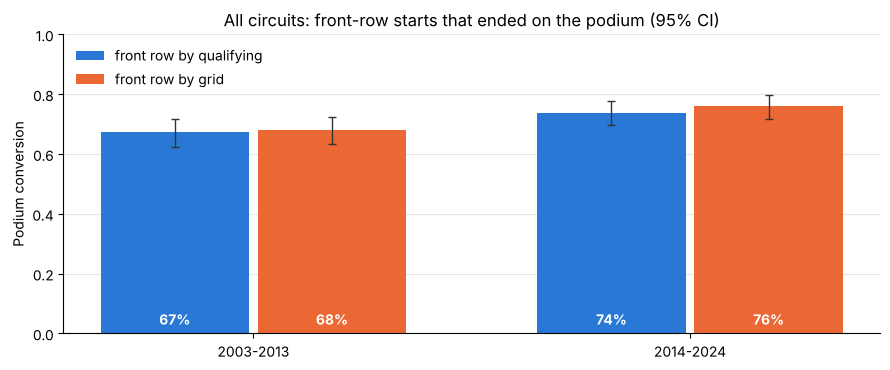

Change in grid-based conversion between periods: z = -2.60, p = 0.009


In [80]:
mismatch = q1[q1["front_row_quali"] != q1["front_row_grid"]].copy()
mismatch["direction"] = np.where(mismatch["front_row_quali"], "qualified P1-2, started further back",
                                 "qualified P3+, promoted to the front row")
mismatch["reason"] = np.select(
    [mismatch["is_sprint_weekend"].eq(1) & mismatch["year"].between(2021, 2022),
     mismatch["pit_lane_start"].eq(1),
     mismatch["front_row_quali"]],
    ["sprint set the grid (2021-22)", "pit-lane start", "grid penalty"],
    default="promoted by others' penalties",
)
display(pd.crosstab(mismatch["reason"], mismatch["direction"], margins=True))

overall = []
for col, label in [("front_row_quali", "by qualifying"), ("front_row_grid", "by grid")]:
    g = q1[q1[col]].groupby("period")["podium"].agg(events="sum", n="size").reset_index()
    g["definition"] = label
    overall.append(g)
overall = add_rate_ci(pd.concat(overall))
display(overall[["definition", "period", "n", "events", "rate", "ci_low", "ci_high"]].round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(2)
for i, (label, color) in enumerate([("by qualifying", C1), ("by grid", C2)]):
    sub = overall[overall["definition"] == label].sort_values("period")
    ax.bar(x + (i - 0.5) * 0.36, sub["rate"], width=0.34, color=color, label=f"front row {label}")
    ax.errorbar(x + (i - 0.5) * 0.36, sub["rate"], yerr=[sub["rate"] - sub["ci_low"], sub["ci_high"] - sub["rate"]],
                fmt="none", ecolor="#333333", capsize=3, linewidth=1)
    for xi, r in zip(x + (i - 0.5) * 0.36, sub["rate"]):
        ax.text(xi, 0.03, f"{r:.0%}", ha="center", color="white", fontweight="bold")
ax.set_xticks(x, sorted(overall["period"].unique()))
ax.set_ylim(0, 1); ax.set_ylabel("Podium conversion")
ax.set_title("All circuits: front-row starts that ended on the podium (95% CI)")
ax.legend(frameon=False, loc="upper left"); style(ax, "y")
plt.tight_layout(); plt.show()

z, p = proportions_ztest(
    overall.query("definition == 'by grid'").sort_values("period")["events"].values,
    overall.query("definition == 'by grid'").sort_values("period")["n"].values)
print(f"Change in grid-based conversion between periods: z = {z:.2f}, p = {p:.3f}")

**Qualifying vs grid.** The two definitions disagree for **73 of about 855 front-row starts** in 2003-2024:

- 31 drivers qualified P1-2 but started further back because of a **grid penalty** (plus 1 pit-lane start);
- 31 drivers qualified P3 or lower and were **promoted** onto the front row by those penalties;
- 10 cases are **2021-22 sprint weekends**, where the sprint result, not qualifying, set the grid.

Across all circuits, front-row starts converted into podiums more often after 2014: **67% → 74%** by qualifying and
**68% → 76%** by grid. The rise is statistically significant (two-proportion test on the grid definition, p = 0.009).
The grid-based rate is slightly higher because a penalised fast car leaves the front row and is replaced by a car that
starts there without a penalty to recover from.

### Q1b. Conversion rate per circuit and period

In [81]:
MIN_FRONT_ROW = 10

def circuit_rates(col):
    t = (q1[q1[col]].groupby(["circuit", "period"])["podium"]
         .agg(events="sum", n="size").reset_index())
    t = add_rate_ci(t)
    t["eligible"] = t["n"] >= MIN_FRONT_ROW
    return t

rates_q = circuit_rates("front_row_quali")
rates_g = circuit_rates("front_row_grid")

def top_table(t, period, k=5):
    s = t[(t["period"] == period) & t["eligible"]].sort_values(["rate", "n"], ascending=[False, False]).head(k)
    return s[["circuit", "n", "events", "rate", "ci_low", "ci_high"]].round(3).reset_index(drop=True)

for label, t in [("QUALIFYING-based", rates_q), ("GRID-based", rates_g)]:
    for period in ["2003-2013", "2014-2024"]:
        n_elig = int(((t["period"] == period) & t["eligible"]).sum())
        print(f"\nTop 5 circuits, {label} front row, {period}  ({n_elig} circuits with >= {MIN_FRONT_ROW} front-row starts)")
        display(top_table(t, period))


Top 5 circuits, QUALIFYING-based front row, 2003-2013  (21 circuits with >= 10 front-row starts)


,circuit,n,events,rate,ci_low,ci_high
0,Circuit de Nevers Magny-Cours,12,11,0.917,0.646,0.985
1,Istanbul Park,14,11,0.786,0.524,0.924
2,Silverstone Circuit,22,17,0.773,0.566,0.899
3,Autodromo Nazionale di Monza,22,16,0.727,0.518,0.868
4,Circuit de Spa-Francorchamps,18,13,0.722,0.491,0.875



Top 5 circuits, QUALIFYING-based front row, 2014-2024  (19 circuits with >= 10 front-row starts)


,circuit,n,events,rate,ci_low,ci_high
0,Suzuka Circuit,18,16,0.889,0.672,0.969
1,Circuit de Monaco,20,17,0.850,0.640,0.948
2,Circuit de Barcelona-Catalunya,22,18,0.818,0.615,0.927
3,Circuit de Spa-Francorchamps,22,18,0.818,0.615,0.927
4,Yas Marina Circuit,22,18,0.818,0.615,0.927



Top 5 circuits, GRID-based front row, 2003-2013  (21 circuits with >= 10 front-row starts)


,circuit,n,events,rate,ci_low,ci_high
0,Circuit de Nevers Magny-Cours,12,11,0.917,0.646,0.985
1,Istanbul Park,14,11,0.786,0.524,0.924
2,Autodromo Nazionale di Monza,22,17,0.773,0.566,0.899
3,Circuit de Monaco,22,17,0.773,0.566,0.899
4,Silverstone Circuit,22,16,0.727,0.518,0.868



Top 5 circuits, GRID-based front row, 2014-2024  (19 circuits with >= 10 front-row starts)


,circuit,n,events,rate,ci_low,ci_high
0,Suzuka Circuit,18,16,0.889,0.672,0.969
1,Yas Marina Circuit,22,19,0.864,0.667,0.953
2,Circuit de Monaco,20,17,0.850,0.640,0.948
3,Circuit de Barcelona-Catalunya,22,18,0.818,0.615,0.927
4,Circuit de Spa-Francorchamps,22,18,0.818,0.615,0.927


Podium conversion of front-row qualifiers for the circuits eligible in both periods (95% confidence intervals).

Circuits ranked in both periods: 14


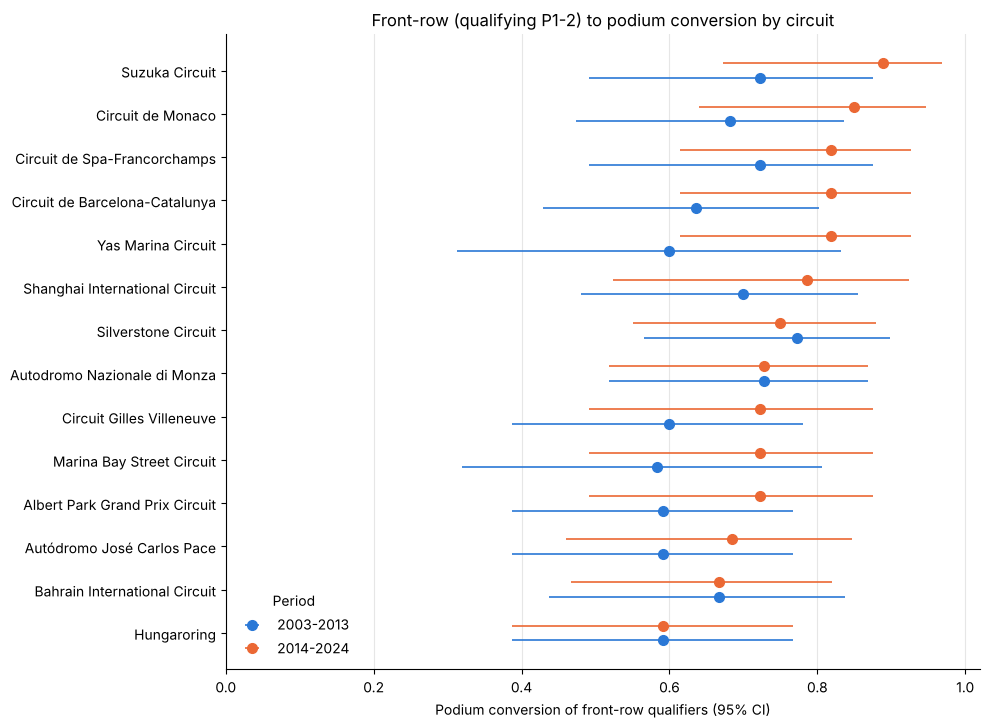

In [82]:
# Circuits that are eligible in BOTH periods (qualifying-based definition, the "earned" front row)
both = rates_q[rates_q["eligible"]].pivot(index="circuit", columns="period",
                                          values=["rate", "ci_low", "ci_high", "n"]).dropna()
both = both.sort_values(("rate", "2014-2024"))
print("Circuits ranked in both periods:", len(both))

fig, ax = plt.subplots(figsize=(10, 0.42 * len(both) + 1.5))
y = np.arange(len(both))
for off, period, color in [(-0.17, "2003-2013", C1), (0.17, "2014-2024", C2)]:
    r = both[("rate", period)]
    ax.errorbar(r, y + off, xerr=[r - both[("ci_low", period)], both[("ci_high", period)] - r],
                fmt="o", color=color, ecolor=color, elinewidth=1.2, capsize=0, markersize=7, label=period)
ax.set_yticks(y, both.index)
ax.set_xlim(0, 1.02); ax.set_xlabel("Podium conversion of front-row qualifiers (95% CI)")
ax.set_title("Front-row (qualifying P1-2) to podium conversion by circuit")
ax.legend(frameon=False, loc="lower left", title="Period"); style(ax, "x")
plt.tight_layout(); plt.show()

Does the circuit ranking change between periods? Ranks in each period and the Spearman rank correlation.

,rate 2003-13,rate 2014-24,rank 2003-13,rank 2014-24,rank change
circuit,,,,,
Suzuka Circuit,0.722,0.889,3,1,2
Circuit de Monaco,0.682,0.850,6,2,4
Circuit de Barcelona-Catalunya,0.636,0.818,8,3,5
Yas Marina Circuit,0.600,0.818,9,3,6
Circuit de Spa-Francorchamps,0.722,0.818,3,3,0
Shanghai International Circuit,0.700,0.786,5,6,-1
Silverstone Circuit,0.773,0.750,1,7,-6
Autodromo Nazionale di Monza,0.727,0.727,2,8,-6
Circuit Gilles Villeneuve,0.600,0.722,9,9,0


Spearman rank correlation between periods: rho = 0.55 (p = 0.04, n = 14 circuits)


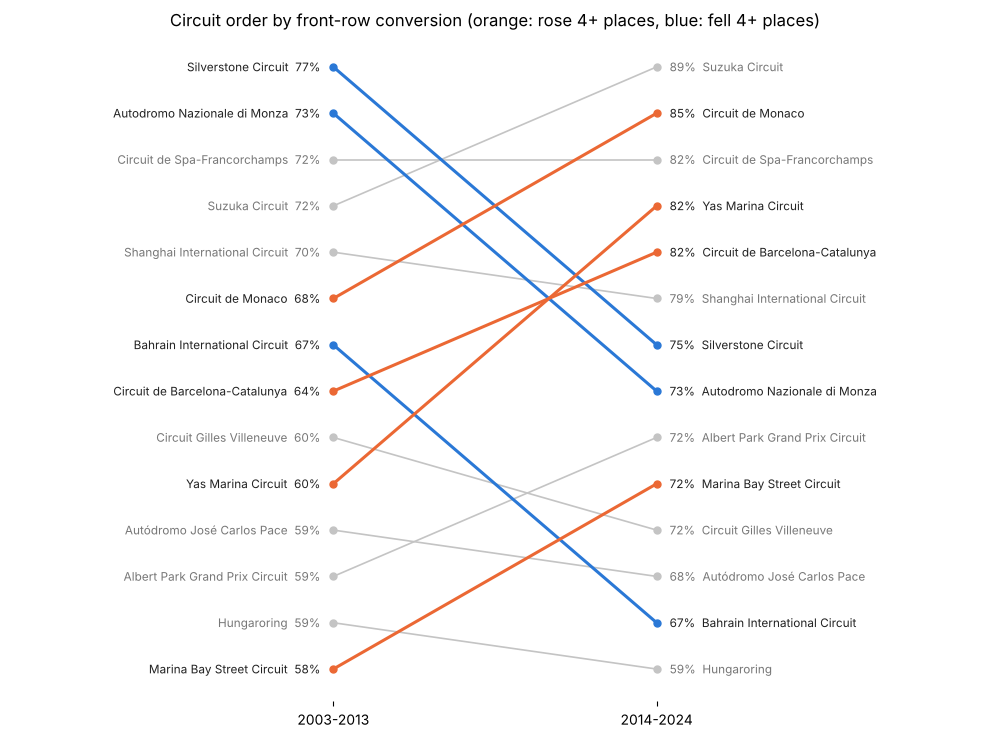

In [83]:
# Does the ranking change? Ranks within each period for circuits eligible in both, plus Spearman correlation.
rank_tbl = pd.DataFrame({
    "rate 2003-13": both[("rate", "2003-2013")],
    "rate 2014-24": both[("rate", "2014-2024")],
})
rank_tbl["rank 2003-13"] = rank_tbl["rate 2003-13"].rank(ascending=False, method="min").astype(int)
rank_tbl["rank 2014-24"] = rank_tbl["rate 2014-24"].rank(ascending=False, method="min").astype(int)
rank_tbl["rank change"] = rank_tbl["rank 2003-13"] - rank_tbl["rank 2014-24"]
display(rank_tbl.sort_values("rank 2014-24").round(3))

rho, p_rho = spearmanr(rank_tbl["rate 2003-13"], rank_tbl["rate 2014-24"])
print(f"Spearman rank correlation between periods: rho = {rho:.2f} (p = {p_rho:.2f}, n = {len(rank_tbl)} circuits)")

# plot positions use a tie-free order (rate, then sample size) so labels never overlap
pos_a = rank_tbl.sort_values(["rate 2003-13"], ascending=False).reset_index().reset_index().set_index("circuit")["index"] + 1
pos_b = rank_tbl.sort_values(["rate 2014-24"], ascending=False).reset_index().reset_index().set_index("circuit")["index"] + 1
n_c = len(rank_tbl)
fig, ax = plt.subplots(figsize=(10, 0.42 * n_c + 1.6))
for circuit, r in rank_tbl.iterrows():
    ch = r["rank change"]
    color = C2 if ch >= 4 else (C1 if ch <= -4 else "#c4c4c4")
    strong = abs(ch) >= 4
    ya, yb = pos_a[circuit], pos_b[circuit]
    ax.plot([0, 1], [ya, yb], color=color, linewidth=2.2 if strong else 1.2, marker="o", markersize=5, zorder=2 if strong else 1)
    ink = "#222222" if strong else "#777777"
    ax.text(-0.04, ya, f"{circuit}  {r['rate 2003-13']:.0%}", ha="right", va="center", fontsize=8.5, color=ink)
    ax.text(1.04, yb, f"{r['rate 2014-24']:.0%}  {circuit}", ha="left", va="center", fontsize=8.5, color=ink)
ax.set_xlim(-1.0, 2.0); ax.set_ylim(n_c + 0.7, 0.3)
ax.set_xticks([0, 1], ["2003-2013", "2014-2024"]); ax.set_yticks([])
for sp in ["top", "right", "left", "bottom"]:
    ax.spines[sp].set_visible(False)
ax.set_title("Circuit order by front-row conversion (orange: rose 4+ places, blue: fell 4+ places)")
plt.tight_layout(); plt.show()

Does the front-row definition (qualifying vs grid) change the circuit answer? Compare the rates per circuit and period.

Circuit-periods compared: 40 | identical rate: 27 | largest difference: 0.11


,circuit,period,n_quali,rate_quali,n_grid,rate_grid
10,Autódromo José Carlos Pace,2014-2024,19,0.684,19,0.789
21,Circuit de Monaco,2003-2013,22,0.682,22,0.773
13,Baku City Circuit,2014-2024,16,0.688,16,0.625
7,Autódromo Hermanos Rodríguez,2014-2024,18,0.556,18,0.611
16,Circuit Gilles Villeneuve,2014-2024,18,0.722,18,0.778
27,Circuit of the Americas,2014-2024,20,0.750,20,0.800


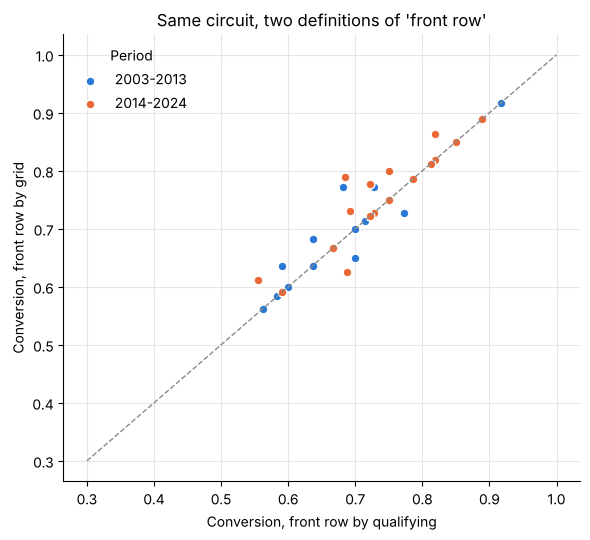

In [84]:
# Does the definition change the circuit answer? Compare qualifying-based and grid-based rates per circuit-period.
cmp_def = rates_q.merge(rates_g, on=["circuit", "period"], suffixes=("_quali", "_grid"))
cmp_def = cmp_def[cmp_def["eligible_quali"] & cmp_def["eligible_grid"]]
diff = (cmp_def["rate_grid"] - cmp_def["rate_quali"])
print(f"Circuit-periods compared: {len(cmp_def)} | identical rate: {int((diff.abs() < 1e-9).sum())} "
      f"| largest difference: {diff.abs().max():.2f}")
display(cmp_def.loc[diff.abs().sort_values(ascending=False).index[:6],
                    ["circuit", "period", "n_quali", "rate_quali", "n_grid", "rate_grid"]].round(3))

fig, ax = plt.subplots(figsize=(6, 5.5))
for period, color in [("2003-2013", C1), ("2014-2024", C2)]:
    s = cmp_def[cmp_def["period"] == period]
    ax.scatter(s["rate_quali"], s["rate_grid"], color=color, s=40, label=period, edgecolor="white", linewidth=1)
ax.plot([0.3, 1], [0.3, 1], color=GREY, linestyle="--", linewidth=1)
ax.set_xlabel("Conversion, front row by qualifying"); ax.set_ylabel("Conversion, front row by grid")
ax.set_title("Same circuit, two definitions of 'front row'")
ax.legend(frameon=False, title="Period"); style(ax, "both")
plt.tight_layout(); plt.show()

### Q1 answer

**Which circuits convert best** (front row by qualifying, at least 10 front-row starts):

| Rank | 2003-2013 | 2014-2024 |
|---|---|---|
| 1 | Magny-Cours **92%** (11/12) | Suzuka **89%** (16/18) |
| 2 | Istanbul Park 79% (11/14) | Monaco 85% (17/20) |
| 3 | Silverstone 77% (17/22) | Barcelona, Spa, Yas Marina 82% (18/22 each) |
| 4 | Monza 73% (16/22) | |
| 5 | Spa 72% (13/18) | |

With the **grid** definition the same circuits lead. Only the order inside the top five shifts: Monaco and Monza
move up before 2014, and Yas Marina moves to 2nd after 2014. 27 of the 40 comparable circuit-periods have an identical
rate under both definitions, and the largest gap is 11 points (Interlagos 2014-24: 68% by qualifying vs 79% by grid).

**Does the ranking change after 2014?** Partly. For the 14 circuits ranked in both periods, the rank correlation is
**ρ = 0.55** (p = 0.04): the order is related but far from stable.

- **Risers:** Yas Marina (9th → 3rd), Barcelona (8th → 3rd), Marina Bay (14th → 9th), Monaco (6th → 2nd).
- **Fallers:** Silverstone (1st → 7th), Monza (2nd → 8th), Bahrain (7th → 13th).
- **Hungaroring** is last in both periods.

**How sure is this?** Each circuit has at most 22 front-row starts per period, so the 95% intervals are about ±15-20
points and overlap for neighbouring circuits (Suzuka's 89% has an interval of 67-97%). The robust findings are the
overall rise in conversion since 2014 and the broad movement of circuits, not the exact position of any one circuit.

**Grain, missingness, cutoff.**

- *Grain:* one row per `(raceId, driverId)` (asserted). 426 of 428 races contribute exactly two grid front-row
  starters; in the other 2, a front-row qualifier did not start from the grid.
- *Missingness:* seasons before 2003 are excluded because qualifying data is unreliable there (section 2.5.3), which is
  required to tell qualifying from grid. Inside the window, 22 driver-races have no qualifying record; none of them
  started from P1-2, so no front-row start is lost. Circuits with fewer than 10 front-row starts in a period (e.g.
  Miami, Las Vegas, Jeddah) are reported in the data but not ranked.
- *Pre-race cutoff:* qualifying position and grid are both known before lights out, so the front-row flag is a valid
  pre-race variable. Grid is the closer of the two to the cutoff because it already includes penalties. The podium is
  only the outcome being measured.

## Q2. Do drivers podium more often at home, after controlling for starting position?

**Joins (4 hops).** `results` (cleaned grain, outcome, `grid`) → `drivers` on `driverId` for `nationality` → `races` on
`raceId` for `circuitId` and season → `circuits` on `circuitId` for `country`. The nationality→country mapping and
the dual-nationality rule are the ones documented in section 2.6.3 (after the spelling fixes of 1.3.1).

**Why a simple home-vs-away comparison is not enough.** If home drivers qualified better, they would podium more often
just because of the grid. So the comparison is made **inside groups of drivers who started from similar positions**
(grid P1, P2-3, P4-6, P7-10, P11+). Three estimates are reported, from simplest to most controlled:

1. **raw** home vs away podium rate (no control);
2. **Mantel-Haenszel odds ratio** across the five grid groups (a pooled within-group comparison);
3. **logistic regression** `podium ~ home + grid group + era`, which also controls for the era (podium rates and
   the share of local entrants differ across eras), with standard errors clustered by driver.

An odds ratio above 1 means home drivers podium more often than away drivers who started from the same grid group.

**Window.** All seasons 1950-2024: the home flag and the grid need no qualifying data, and the longer window gives
more home races. A 2003+ check is included. Pit-lane starters (87 rows) are excluded because `grid = 0` is not a
position.

In [85]:
drivers_t = clean_tables["drivers"]

q2 = (
    post_race_info[["raceId", "driverId", "positionOrder"]]                                   # results (cleaned grain)
    .merge(core[["raceId", "driverId", "grid", "pit_lane_start"]], on=["raceId", "driverId"], how="left")
    .merge(drivers_t[["driverId", "nationality"]], on="driverId", how="left")                 # drivers
    .merge(races_t[["raceId", "year", "circuitId"]], on="raceId", how="left")                 # races
    .merge(circuits_t[["circuitId", "country"]], on="circuitId", how="left")                  # circuits
)
q2["podium"] = (q2["positionOrder"] <= 3).astype(int)
q2["home"] = [is_home(n, c) for n, c in zip(q2["nationality"], q2["country"])]   # mapping from 2.6.3
q2 = add_era(q2)

print("Missing nationality:", int(q2["nationality"].isna().sum()), "| missing country:", int(q2["country"].isna().sum()))
q2 = q2[q2["grid"] > 0].copy()
GRID_BINS, GRID_LABELS = [0, 1, 3, 6, 10, 100], ["P1", "P2-3", "P4-6", "P7-10", "P11+"]
q2["grid_group"] = pd.cut(q2["grid"], GRID_BINS, labels=GRID_LABELS)
q2["era"] = q2["era"].astype(str)

print("Rows:", len(q2), "| home starts:", int(q2["home"].sum()), f"({q2['home'].mean():.1%})")
raw = q2.groupby("home").agg(starts=("podium", "size"), podiums=("podium", "sum"),
                             podium_rate=("podium", "mean"), mean_grid=("grid", "mean"),
                             median_grid=("grid", "median"))
raw.index = raw.index.map({0: "away", 1: "home"})
display(raw.round(3))

Missing nationality: 0 | missing country: 0
Rows: 24632 | home starts: 1936 (7.9%)


,starts,podiums,podium_rate,mean_grid,median_grid
home,,,,,
away,22696,3129,0.138,11.705,11.0
home,1936,230,0.119,12.679,13.0


Home vs away podium rate within each grid group, with Wilson confidence intervals.

n           rate       
side           away    home   away   home
grid_group                               
P1           1032.0    81.0  0.647  0.605
P2-3         2074.0   148.0  0.510  0.554
P4-6         3108.0   225.0  0.261  0.271
P7-10        4123.0   338.0  0.093  0.074
P11+        12359.0  1144.0  0.017  0.011

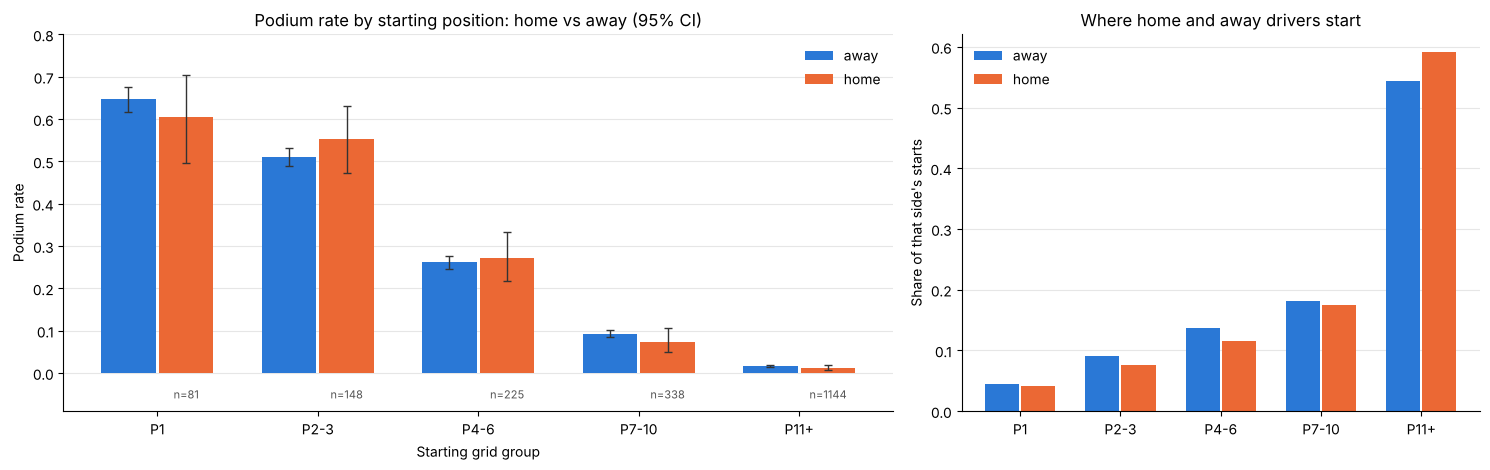

In [86]:
# Within each grid group: home vs away podium rate with Wilson CIs
strata = (q2.groupby(["grid_group", "home"], observed=True)["podium"]
          .agg(events="sum", n="size").reset_index())
strata = add_rate_ci(strata)
strata["side"] = strata["home"].map({0: "away", 1: "home"})
display(strata.pivot(index="grid_group", columns="side", values=["n", "rate"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(GRID_LABELS))
for i, (side, color) in enumerate([("away", C1), ("home", C2)]):
    s = strata[strata["side"] == side].set_index("grid_group").reindex(GRID_LABELS)
    xs = x + (i - 0.5) * 0.36
    ax[0].bar(xs, s["rate"], width=0.34, color=color, label=side)
    ax[0].errorbar(xs, s["rate"], yerr=[s["rate"] - s["ci_low"], s["ci_high"] - s["rate"]],
                   fmt="none", ecolor="#333333", capsize=3, linewidth=1)
    if side == "home":
        for xi, n in zip(xs, s["n"]):
            ax[0].text(xi, -0.06, f"n={n}", ha="center", fontsize=8, color="#555555")
ax[0].set_xticks(x, GRID_LABELS); ax[0].set_ylim(-0.09, 0.8)
ax[0].set_xlabel("Starting grid group"); ax[0].set_ylabel("Podium rate")
ax[0].set_title("Podium rate by starting position: home vs away (95% CI)")
ax[0].legend(frameon=False); style(ax[0], "y")

share = (q2.groupby("home")["grid_group"].value_counts(normalize=True).unstack(0)
         .reindex(GRID_LABELS).rename(columns={0: "away", 1: "home"}))
for i, (side, color) in enumerate([("away", C1), ("home", C2)]):
    ax[1].bar(x + (i - 0.5) * 0.36, share[side], width=0.34, color=color, label=side)
ax[1].set_xticks(x, GRID_LABELS); ax[1].set_ylabel("Share of that side's starts")
ax[1].set_title("Where home and away drivers start")
ax[1].legend(frameon=False); style(ax[1], "y")
plt.tight_layout(); plt.show()

Estimate the home effect three ways: raw, Mantel-Haenszel within grid groups, and logistic regression controlling for grid group and era.

Breslow-Day test that the home effect is the same in every grid group: p = 0.30


,estimate,odds_ratio,ci_low,ci_high,p_value
0,Raw (no control),0.843,0.731,0.972,0.019
1,"Mantel-Haenszel, within grid groups",0.950,0.801,1.128,0.565
2,Logistic: grid group + era,0.932,0.761,1.141,0.497
3,"Logistic, 2003+ only",0.762,0.390,1.491,0.428


Home starts in the modern-window model: 364


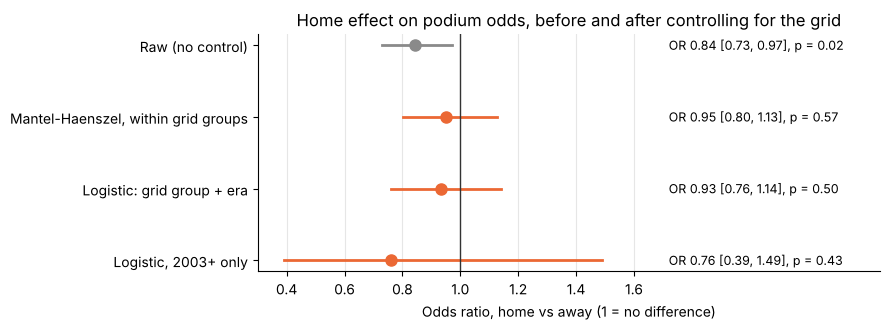

In [87]:
estimates = []

# 1) raw, no control
m_raw = smf.logit("podium ~ home", data=q2).fit(disp=0)
estimates.append(("Raw (no control)", m_raw.params["home"], *m_raw.conf_int().loc["home"], m_raw.pvalues["home"]))

# 2) Mantel-Haenszel across grid groups
tables_2x2 = [pd.crosstab(s["home"], s["podium"]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values
              for _, s in q2.groupby("grid_group", observed=True)]
mh = StratifiedTable(tables_2x2)
lo, hi = mh.oddsratio_pooled_confint()
estimates.append(("Mantel-Haenszel, within grid groups", np.log(mh.oddsratio_pooled), np.log(lo), np.log(hi),
                  mh.test_null_odds().pvalue))
print(f"Breslow-Day test that the home effect is the same in every grid group: p = {mh.test_equal_odds().pvalue:.2f}")

# 3) logistic regression with grid group + era, SEs clustered by driver
m_adj = smf.logit("podium ~ home + C(grid_group) + C(era)", data=q2).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"]})
estimates.append(("Logistic: grid group + era", m_adj.params["home"], *m_adj.conf_int().loc["home"],
                  m_adj.pvalues["home"]))

# 4) same model, modern window only
q2m = q2[q2["year"] >= QUALI_START_YEAR]
m_mod = smf.logit("podium ~ home + C(grid_group) + C(era)", data=q2m).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": q2m["driverId"]})
estimates.append((f"Logistic, {QUALI_START_YEAR}+ only", m_mod.params["home"], *m_mod.conf_int().loc["home"],
                  m_mod.pvalues["home"]))

est = pd.DataFrame(estimates, columns=["estimate", "log_or", "log_lo", "log_hi", "p_value"])
est["odds_ratio"], est["ci_low"], est["ci_high"] = np.exp(est["log_or"]), np.exp(est["log_lo"]), np.exp(est["log_hi"])
display(est[["estimate", "odds_ratio", "ci_low", "ci_high", "p_value"]].round(3))
print("Home starts in the modern-window model:", int(q2m["home"].sum()))

fig, ax = plt.subplots(figsize=(9, 3.4))
yy = np.arange(len(est))[::-1]
for yi, (_, r) in zip(yy, est.iterrows()):
    color = GREY if r["estimate"].startswith("Raw") else C2
    ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=color, linewidth=2)
    ax.plot(r["odds_ratio"], yi, "o", color=color, markersize=8)
    ax.text(1.72, yi, f"OR {r['odds_ratio']:.2f} [{r['ci_low']:.2f}, {r['ci_high']:.2f}], p = {r['p_value']:.2f}",
            va="center", fontsize=9)
ax.axvline(1, color="#333333", linewidth=1)
ax.set_yticks(yy, est["estimate"]); ax.set_xlim(0.3, 2.45); ax.set_xticks([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6])
ax.set_xlabel("Odds ratio, home vs away (1 = no difference)")
ax.set_title("Home effect on podium odds, before and after controlling for the grid")
style(ax, "x")
plt.tight_layout(); plt.show()

### Q2 answer

**No: after controlling for starting position, drivers do not podium more often at home.**

- **Raw comparison:** home drivers actually podium *less* often (11.9% vs 13.8%; odds ratio 0.84, p = 0.02).
- **Why:** home drivers start further back (mean grid 12.7 vs 11.7; 59% of home starts are from P11 or lower vs 54% of
  away starts). Many home entries are local drivers in weaker cars, especially in the early decades. So the confounder
  works in the opposite direction from the one the question worried about: home drivers do *not* qualify better.
- **Within the same grid group** the rates are close, and the 95% intervals overlap in every group: P1 60% home vs 65%
  away, P2-3 55% vs 51%, P4-6 27% vs 26%, P7-10 7% vs 9%, P11+ 1.1% vs 1.7%.
- **Controlled estimates:**
  - Mantel-Haenszel odds ratio **0.95** [0.80, 1.13], p = 0.57;
  - logistic regression with grid group and era **0.93** [0.76, 1.14], p = 0.50;
  - the same model on 2003+ only: 0.76 [0.39, 1.49], p = 0.43;
  - Breslow-Day test, p = 0.30: no grid group behaves differently from the others.

The raw "home disadvantage" disappears once starting position is controlled for, and the upper bound of the interval
(about 1.13) means any real home boost is at most about 13% higher odds of a podium.

**Grain, missingness, cutoff.**

- *Grain:* one row per driver-race start with a real grid slot: 24,632 starts, of which 1,936 (7.9%) are home starts.
  The 87 pit-lane starters are excluded because `grid = 0` is not a position.
- *Missingness:* no missing nationality or circuit country. Drivers from countries with no Grand Prix (e.g. Finland)
  are always "away", which is a structural zero, not missing data. Dual nationalities count as home if either matches.
  Nationality is stored once per driver, so a change of racing licence over a career is not captured.
- *Pre-race cutoff:* the home flag and the grid are both known before the race, so both are valid pre-race variables.
  For Task 3, this result suggests `is_home_race` adds little information beyond the grid.

## Q3. Which constructors have the highest mechanical-retirement rate, 2014-2021 vs 2022-2024?

**Joins (4 hops).** `results` (cleaned grain, `statusId`, `positionText`) → `status` on `statusId` for the status text
→ the documented `status_map` from section 2.7 for the group → `constructors` on `constructorId` for the team name
→ `races` on `raceId` for the season.

**Definitions, following the brief.**

- *Race start* (the denominator): every driver-race row of the cleaned table **except** cars that withdrew before the
  start (`positionText = W`, e.g. a failure on the formation lap). Non-starters were already removed in Task 1, and
  pit-lane starters count as starts.
- *Mechanical retirement* (the numerator): a race start whose status is in the `mechanical` group of section 2.7, i.e.
  a car component failed. Crashes (`accident`), driver illness or injury (`driver`), disqualifications
  (`regulation`) and unknown causes (`other`, e.g. a generic "Retired") are excluded, as the brief requires.
- *Rate* = mechanical retirements ÷ race starts, per constructor and period. A constructor is ranked in a period only
  with **at least 40 starts** (about one full season with two cars).

**Constructor identity.** The table uses the constructor names in `constructors.csv`, so renamed teams are separate rows
(e.g. Toro Rosso → AlphaTauri → RB). A second view groups them by team lineage.

In [88]:
constructors_t = clean_tables["constructors"]

q3 = (
    post_race_info[["raceId", "driverId", "constructorId", "positionText", "statusId"]]       # results (cleaned grain)
    .merge(clean_tables["status"], on="statusId", how="left")                                 # status text
    .merge(status_map[["statusId", "status_group"]], on="statusId", how="left")              # documented grouping
    .merge(constructors_t[["constructorId", "name"]].rename(columns={"name": "constructor"}),
           on="constructorId", how="left")                                                    # constructors
    .merge(races_t[["raceId", "year"]], on="raceId", how="left")                              # races
)
q3 = q3[q3["year"] >= 2014].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")

print("Unmapped statuses:", int(q3["status_group"].isna().sum()), "| missing constructor:", int(q3["constructor"].isna().sum()))
did_not_start = q3["positionText"].eq("W")
print("Withdrew before the start (excluded from starts):", int(did_not_start.sum()))
display(q3.loc[did_not_start, "status"].value_counts().to_frame("withdrawn cars by status"))

starts = q3[~did_not_start].copy()
starts["mechanical"] = starts["status_group"].eq("mechanical").astype(int)

display(starts.groupby("period")["status_group"].value_counts(normalize=True).unstack().round(3))
period_rate = starts.groupby("period")["mechanical"].agg(events="sum", n="size").reset_index()
period_rate = add_rate_ci(period_rate)
display(period_rate.round(3))
z, p = proportions_ztest(period_rate["events"].values, period_rate["n"].values)
print(f"Change in the overall mechanical-retirement rate between periods: z = {z:.2f}, p = {p:.4f}")

Unmapped statuses: 0 | missing constructor: 0
Withdrew before the start (excluded from starts): 22


,withdrawn cars by status
status,
Withdrew,8
Power Unit,3
Gearbox,2
ERS,1
Power loss,1
Retired,1
Engine,1
Hydraulics,1
Exhaust,1


status_group,accident,driver,finished,mechanical,other,regulation
period,,,,,,
2014-2021,0.067,0.000,0.819,0.098,0.012,0.002
2022-2024,0.066,0.001,0.862,0.059,0.010,0.003


,period,events,n,rate,ci_low,ci_high
0,2014-2021,318,3246,0.098,0.088,0.109
1,2022-2024,80,1352,0.059,0.048,0.073


Change in the overall mechanical-retirement rate between periods: z = 4.26, p = 0.0000


Mechanical-retirement rate per constructor and period (constructors with at least 40 starts), with a chart.


2014-2021: constructors ranked by mechanical-retirement rate (>= 40 starts)


,constructor,n,events,rate,ci_low,ci_high
0,Lotus F1,75,15,0.200,0.125,0.304
1,Toro Rosso,242,40,0.165,0.124,0.217
2,Renault,199,28,0.141,0.099,0.196
3,McLaren,316,43,0.136,0.103,0.178
4,Red Bull,318,36,0.113,0.083,0.153
5,Sauber,199,22,0.111,0.074,0.162
6,Haas F1 Team,241,23,0.095,0.064,0.139
7,Racing Point,75,7,0.093,0.046,0.180
8,Alpine F1 Team,44,4,0.091,0.036,0.212
9,AlphaTauri,77,7,0.091,0.045,0.176


Not ranked (too few starts): Caterham (33), Marussia (31)

2022-2024: constructors ranked by mechanical-retirement rate (>= 40 starts)


,constructor,n,events,rate,ci_low,ci_high
0,Alfa Romeo,88,11,0.125,0.071,0.210
1,Alpine F1 Team,135,14,0.104,0.063,0.167
2,AlphaTauri,88,7,0.080,0.039,0.155
3,Williams,134,8,0.060,0.031,0.113
4,Aston Martin,134,7,0.052,0.026,0.104
5,Ferrari,134,7,0.052,0.026,0.104
6,Haas F1 Team,135,7,0.052,0.025,0.103
7,Mercedes,136,6,0.044,0.020,0.093
8,RB F1 Team,48,2,0.042,0.012,0.140
9,McLaren,136,5,0.037,0.016,0.083


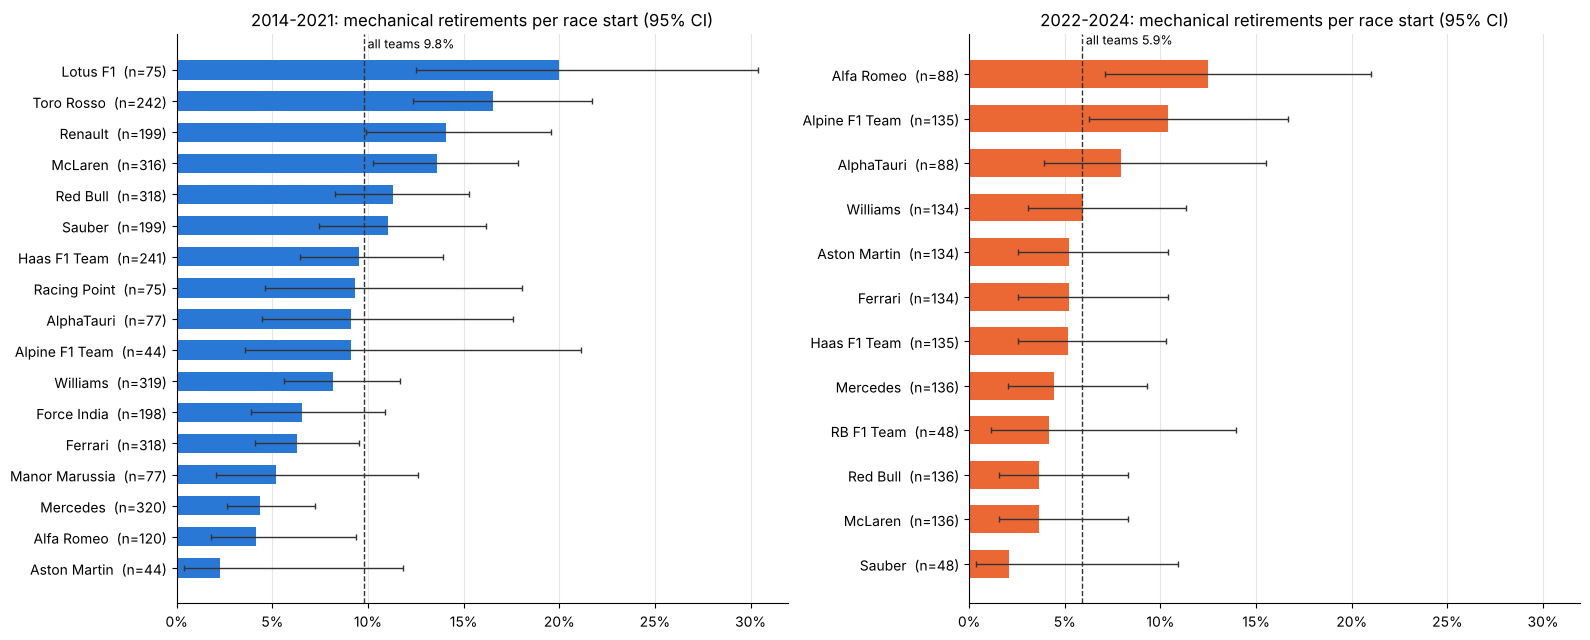

In [89]:
MIN_STARTS = 40

team = (starts.groupby(["period", "constructor"])["mechanical"]
        .agg(events="sum", n="size").reset_index())
team = add_rate_ci(team)
team["eligible"] = team["n"] >= MIN_STARTS

for period in ["2014-2021", "2022-2024"]:
    s = team[(team["period"] == period)]
    print(f"\n{period}: constructors ranked by mechanical-retirement rate (>= {MIN_STARTS} starts)")
    display(s[s["eligible"]].sort_values("rate", ascending=False)
            [["constructor", "n", "events", "rate", "ci_low", "ci_high"]].round(3).reset_index(drop=True))
    small = s[~s["eligible"]]
    if len(small):
        print("Not ranked (too few starts):", ", ".join(f"{c} ({n})" for c, n in zip(small["constructor"], small["n"])))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True)
for ax, period, color in [(axes[0], "2014-2021", C1), (axes[1], "2022-2024", C2)]:
    s = team[(team["period"] == period) & team["eligible"]].sort_values("rate")
    yy = np.arange(len(s))
    ax.barh(yy, s["rate"], color=color, height=0.62)
    ax.errorbar(s["rate"], yy, xerr=[s["rate"] - s["ci_low"], s["ci_high"] - s["rate"]],
                fmt="none", ecolor="#333333", capsize=2, linewidth=1)
    avg = period_rate.set_index("period").loc[period, "rate"]
    ax.axvline(avg, color="#333333", linestyle="--", linewidth=1)
    ax.text(avg, len(s) - 0.4, f" all teams {avg:.1%}", fontsize=9, va="bottom")
    ax.set_yticks(yy, [f"{c}  (n={n})" for c, n in zip(s["constructor"], s["n"])])
    ax.set_title(f"{period}: mechanical retirements per race start (95% CI)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    style(ax, "x")
plt.tight_layout(); plt.show()

Lineage view: group the same team under its different names so periods can be compared like with like.

rate                   n  \
period                                    2014-2021 2022-2024 2014-2021   
lineage                                                                   
Mercedes                                      0.044     0.044     320.0   
Ferrari                                       0.063     0.052     318.0   
Force India / Racing Point / Aston Martin     0.066     0.052     317.0   
Williams                                      0.082     0.060     319.0   
Sauber / Alfa Romeo                           0.085     0.088     319.0   
Haas F1 Team                                  0.095     0.052     241.0   
Red Bull                                      0.113     0.037     318.0   
McLaren                                       0.136     0.037     316.0   
Toro Rosso / AlphaTauri / RB                  0.147     0.066     319.0   
Lotus / Renault / Alpine                      0.148     0.104     318.0   

                                                     
period                                    2022-2024  
lineage                                              
Mercedes                                      136.0  
Ferrari                                       134.0  
Force India / Racing Point / Aston Martin     134.0  
Williams                                      134.0  
Sauber / Alfa Romeo                           136.0  
Haas F1 Team                                  135.0  
Red Bull                                      136.0  
McLaren                                       136.0  
Toro Rosso / AlphaTauri / RB                  136.0  
Lotus / Renault / Alpine                      135.0

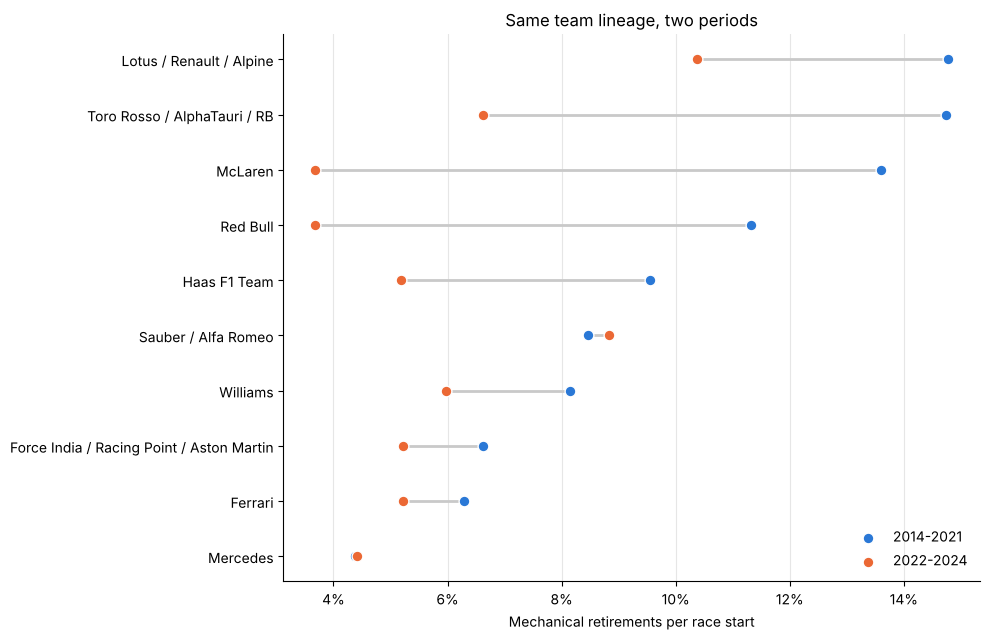

Spearman rank correlation of lineage rates between periods: rho = 0.24 (p = 0.51, n = 10)


In [90]:
# Lineage view: the same team under different names, to compare like with like across periods
LINEAGE = {
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB",
    "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Lotus F1": "Lotus / Renault / Alpine", "Renault": "Lotus / Renault / Alpine", "Alpine F1 Team": "Lotus / Renault / Alpine",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
starts["lineage"] = starts["constructor"].map(LINEAGE).fillna(starts["constructor"])
lin = add_rate_ci(starts.groupby(["lineage", "period"])["mechanical"].agg(events="sum", n="size").reset_index())
lin_w = lin[lin["n"] >= MIN_STARTS].pivot(index="lineage", columns="period", values=["rate", "n"]).dropna()
lin_w = lin_w.sort_values(("rate", "2014-2021"))
display(lin_w.round(3))

fig, ax = plt.subplots(figsize=(10, 0.5 * len(lin_w) + 1.5))
yy = np.arange(len(lin_w))
for yi, (name, r) in zip(yy, lin_w.iterrows()):
    ax.plot([r[("rate", "2014-2021")], r[("rate", "2022-2024")]], [yi, yi], color="#c9c9c9", linewidth=2, zorder=1)
ax.scatter(lin_w[("rate", "2014-2021")], yy, color=C1, s=60, label="2014-2021", zorder=2, edgecolor="white")
ax.scatter(lin_w[("rate", "2022-2024")], yy, color=C2, s=60, label="2022-2024", zorder=2, edgecolor="white")
ax.set_yticks(yy, lin_w.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Mechanical retirements per race start")
ax.set_title("Same team lineage, two periods")
ax.legend(frameon=False, loc="lower right"); style(ax, "x")
plt.tight_layout(); plt.show()

rho3, p3 = spearmanr(lin_w[("rate", "2014-2021")], lin_w[("rate", "2022-2024")])
print(f"Spearman rank correlation of lineage rates between periods: rho = {rho3:.2f} (p = {p3:.2f}, n = {len(lin_w)})")

Sensitivity check: recompute the rates with a stricter definition that drops the judgement-call statuses.

In [91]:
# Sensitivity: a stricter definition that drops the judgement-call statuses of section 2.7
AMBIGUOUS = {"Tyre", "Puncture", "Tyre puncture", "Wheel", "Wheel nut", "Wheel rim", "Front wing", "Rear wing",
             "Broken wing", "Handling", "Undertray", "Debris"}
starts["mechanical_strict"] = (starts["mechanical"].eq(1) & ~starts["status"].isin(AMBIGUOUS)).astype(int)
print("Mechanical retirements, default vs strict:", int(starts["mechanical"].sum()), "vs", int(starts["mechanical_strict"].sum()))

sens = starts.groupby(["period", "constructor"]).agg(n=("mechanical", "size"),
                                                     default=("mechanical", "mean"),
                                                     strict=("mechanical_strict", "mean")).reset_index()
sens = sens[sens["n"] >= MIN_STARTS]
for period in ["2014-2021", "2022-2024"]:
    s = sens[sens["period"] == period]
    r, _ = spearmanr(s["default"], s["strict"])
    top_d = s.nlargest(3, "default")["constructor"].tolist()
    top_s = s.nlargest(3, "strict")["constructor"].tolist()
    print(f"{period}: rank correlation default vs strict = {r:.2f} | top 3 default {top_d} | top 3 strict {top_s}")

Mechanical retirements, default vs strict: 398 vs 363
2014-2021: rank correlation default vs strict = 0.98 | top 3 default ['Lotus F1', 'Toro Rosso', 'Renault'] | top 3 strict ['Lotus F1', 'Toro Rosso', 'Renault']
2022-2024: rank correlation default vs strict = 0.95 | top 3 default ['Alfa Romeo', 'Alpine F1 Team', 'AlphaTauri'] | top 3 strict ['Alfa Romeo', 'Alpine F1 Team', 'AlphaTauri']


### Q3 answer

**2014-2021, highest mechanical-retirement rate** (at least 40 starts):

1. **Lotus F1 20.0%** (15 of 75 starts)
2. Toro Rosso 16.5% (40/242)
3. Renault 14.1% (28/199)
4. McLaren 13.6% (43/316), the Honda power-unit years

Lowest: Aston Martin 2.3% (1/44, small sample), Alfa Romeo 4.2% and Mercedes 4.4%.

**2022-2024, highest mechanical-retirement rate:**

1. **Alfa Romeo 12.5%** (11 of 88 starts)
2. Alpine 10.4% (14/135)
3. AlphaTauri 8.0% (7/88)

Lowest: Sauber 2.1% (1/48), Red Bull and McLaren 3.7%.

**How the periods compare.**

- Reliability improved for the whole grid: the mechanical-retirement rate fell from **9.8% to 5.9%** of race starts
  (p < 0.001), and the share of cars reaching the flag rose from 81.9% to 86.2%.
- **By team lineage** (same team under different names):
  - Lotus / Renault / Alpine is the least reliable in both periods (14.8% → 10.4%);
  - McLaren (13.6% → 3.7%) and Red Bull (11.3% → 3.7%) improved most;
  - Mercedes is stable at 4.4%.
- The ranking changes a lot between periods: rank correlation of the lineages ρ = 0.24 (p = 0.51).
- **Uncertainty:** in 2022-2024 each team has only 2 to 14 mechanical retirements, so the intervals are wide (Alfa
  Romeo 7-21%). The fall in the overall rate and the persistently high Renault/Alpine lineage are the robust results;
  the exact order of the middle of the table is not.
- **Sensitivity:** dropping the 35 judgement-call statuses (tyre, puncture, wheel, wing, handling) leaves the top three
  in both periods unchanged (rank correlation 0.98 and 0.95).

**Grain, missingness, cutoff.**

- *Grain:* one row per driver-race, which is one car's race start: 4,598 starts (3,246 in 2014-21, 1,352 in 2022-24).
  22 cars that withdrew before the start (12 of them with a component failure, e.g. on the formation lap) are not
  race starts, so they are excluded from both numerator and denominator, as the brief's definition requires.
- *Missingness:* every status is mapped (0 unmapped) and no constructor is missing. Retirements with an unknown cause
  ("Retired", "Not classified") are in `other` and not counted as mechanical. They are only about 1% of starts, so the
  possible undercount is small.
- *Pre-race cutoff:* the retirement status is **post-race** information. This question is a descriptive analysis and
  must never feed a feature for the same race. A reliability feature for Task 3 would have to use only previous races
  (e.g. the team's mechanical-retirement rate over its earlier races).

# Task 3 — Feature Selection & Engineering

**Goal.** Choose the predictors for "will this driver finish on the podium?" using only information available
**after qualifying and before the race starts**, back every choice with evidence, and justify the
training / validation / test split.

**Approach (in this order).**

1. **3.1 Hypotheses from the earlier EDA.** Tasks 1–2 already showed which kinds of information matter. A primary
   feature set is chosen from those results, and each choice is tied to the earlier finding it rests on.
2. **3.2 Split.** Feature evidence may only use training seasons, so the training years are fixed next.
3. **3.3 Feature engineering.** Build the hypothesis features, plus a few new candidates to test, with leakage tests.
4. **3.4 Exploratory evidence.** For every candidate: podium-rate plots per era, a heatmap that holds starting
   position fixed, a summary heatmap of all the evidence, and a redundancy heatmap.
5. **3.5 Screening.** Drop features that cannot be learned, and near-duplicates.
6. **3.6 Experiments.** A small number of trials that remove or add whole feature groups, scored on held-out training
   seasons. Every trial is kept in the notebook.
7. **3.7 Final feature set** with the reasoning for each feature; **3.8** leakage audit and handoff to Task 4.

**Not in Task 3.** Imputation, scaling, encoding pipelines and preprocessing-order experiments belong to Task 4/5.
Features are handed over raw.

**Rules fixed before looking at the results.**

| Decision | Rule |
|---|---|
| Split | Whole seasons in time order; test = most recent seasons, validation = the seasons just before, training = all earlier seasons from 2003. Validation needs at least 100 podium examples and test at least 157 (3.2). Among the splits that pass, keep the one with the most training data. |
| Evidence data | Only training seasons are used for any feature decision; validation and test outcomes are never looked at in Task 3. |
| Screening | Drop a feature that is constant in training. For any pair with Spearman correlation of at least 0.90, keep the clearly stronger one (race-bootstrap of single-feature AUC); on a tie, keep the one with more evidence beyond the grid. |
| Remove a hypothesis group | Removed only if the model **without** it is at least as good on both PR-AUC and log-loss, **in both model families**, in at least 95% of the race-bootstrap samples, and in at least 3 of the 4 blocks of 3.6 (amended, see below). |
| Add a new group | Added if it improves both PR-AUC and log-loss **and** the 95% race-bootstrap interval of the PR-AUC gain is above zero, **in both model families**, and in at least 3 of the 4 blocks of 3.6 (amended, see below). |
| Filter methods (Pearson, χ², mutual information, variance threshold) | A set chosen by a filter method replaces the hypothesis-based set only if it beats it on both PR-AUC and log-loss **and** its PR-AUC gain interval is above zero, with the same two-family and replication requirements. |

**Amendments after review, stated openly.** Two weaknesses were found when this section was re-run in a second software
environment, and the rules above were tightened. Nothing was changed after looking at validation or test data.

1. **A silent failure inside the screening.** The "beyond the grid" likelihood-ratio statistic (3.4.17) returned `NaN` for nine
   features in the second environment, because the unscaled Newton fit diverged and the error was swallowed. The screening
   then treated `NaN` as "infinitely strong" and kept the wrong member of three near-duplicate pairs, which changed the final
   feature set. The columns are now standardised before the fit (the statistic does not depend on scale), BFGS is the
   fallback, a failure raises an error, and only the reference features `grid_model` and `pit_lane_start` are treated as
   infinitely strong.
2. **Decisions that rested on one block of 62 races.** Section 3.2.2 shows that a block of this size is noisy, yet a group was
   added or removed on one comparison. In the second environment the qualifying-stage-flags group passed the old "add" rule,
   although its gain appeared in only one of four blocks. Changes to the pre-registered hypothesis set therefore now also have
   to point the same way in both model families and to **replicate** in at least 3 of 4 blocks of training seasons, and a
   removal has to be reliably harmless. The default stays the hypothesis set; a change needs repeated evidence.

### 3.0 Shared helpers

Every Task 3 figure is shown in the notebook and also saved as a PNG for the report (`task3_outputs/figures/`). The two
small statistics helpers are used throughout:

- `wilson()`: a 95% confidence interval for a rate, because many bins hold only a few dozen rows;
- `podium_rate_by()`: the podium rate and row count for each bin of a feature.

In [92]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

_t3_root = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
T3_FIG_DIR = _t3_root / "task3_outputs" / "figures"
T3_FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#2e9e5b", "#d64545", "#8a8a8a"

def t3_show(name):
    # Save the current figure for the report and display it in the notebook (also under a non-interactive backend).
    plt.tight_layout()
    path = T3_FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    if "agg" in matplotlib.get_backend().lower():
        plt.close("all")
        try:
            display(Image(filename=str(path)))
        except Exception:
            pass
    else:
        plt.show()

def wilson(k, n):
    lo, hi = proportion_confint(np.asarray(k), np.asarray(n), alpha=0.05, method="wilson")
    return lo, hi

def podium_rate_by(frame, column, order=None):
    out = (frame.groupby(column, observed=True)["podium"].agg(n="size", podiums="sum").reset_index())
    out["rate"] = out["podiums"] / out["n"]
    out["lo"], out["hi"] = wilson(out["podiums"], out["n"])
    if order is not None:
        out[column] = pd.Categorical(out[column], order, ordered=True)
        out = out.sort_values(column).reset_index(drop=True)
    return out

def style_axis(ax, grid="y"):
    ax.grid(axis=grid, color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

print("Task 3 figures are saved to:", T3_FIG_DIR)

Task 3 figures are saved to: /home/claude/t3/task3_outputs/figures


## 3.1 Hypotheses from the earlier EDA: the primary feature set

Before any new analysis, the results of Tasks 1–2 suggest which information predicts a podium. Each hypothesis below
points to the earlier result it comes from. Section 3.4 then checks every hypothesis on the training seasons, and 3.6
tests whether each group really adds something.

| # | Hypothesis | Earlier evidence | Primary features |
|---|---|---|---|
| H1 | **Starting position is the strongest single signal.** | Task 1 (2.10): the podium rate collapses as the grid number grows. Task 2 Q1: front-row starters reach the podium 68% (2003–13) and 76% (2014–24) of the time. | `grid_model`, `pit_lane_start` |
| H2 | **Qualifying adds information beyond the grid**, because penalties separate the two. | Task 2 Q1: qualifying position and grid disagreed for 73 front-row starts (31 penalties, 10 sprint weekends). Task 1 (2.5.3): qualifying data is complete from 2003. | `qual_position_filled`, `q_gap_pct`, `has_q_time`, `has_quali`, `grid_vs_quali_delta` |
| H3 | **Current-season strength** (championship standings before the race) shows who has the fast car this year. | Task 1 (2.6.4) built the standings shifted to "before this race" and verified there is no leakage. | driver and constructor points / rank / wins before the race + availability flags |
| H4 | **Recent form of the driver and of the team** captures momentum and current car pace. The brief's checklist also requires a leakage-safe form feature. | Task 2 Q1/Q3: results cluster by team and period (e.g. the 2014+ rise in front-row conversion). | driver podium rate / average finish over the last 5 starts; team podium rate / average finish over its last 5 races; no-history flags |
| H5 | **Reliability matters**: a car that breaks down cannot finish on the podium. | Task 2 Q3: mechanical retirement rates differ a lot between teams (Lotus 20% vs Mercedes 4.4% in 2014–21). Task 1 (2.2.6): retirement rates by era. | team mechanical-retirement rate over its last 10 races; driver finish rate over the last 10 starts |

**Left out by hypothesis**, each for a specific reason:

| Candidate | Why it is not in the primary set |
|---|---|
| `is_home_race` | Task 2 Q2: no home effect once the grid is held fixed (odds ratio 0.95, p = 0.57). |
| `is_sprint_weekend` | Sprints exist only from 2021 (Task 1, 2.6.1), so there are none in the training seasons and nothing to learn. |
| `circuitId`, `round` | Every race awards exactly 3 podiums, so the podium rate per circuit or round is flat by construction. Task 2 Q1 found circuit differences in front-row conversion mostly within noise. |
| raw IDs, `year`, `date`, `q_best_s` | IDs and dates only label rows; raw lap seconds depend on circuit length. |
| anything from the current race result | Post-race: leakage. |

**New candidates (not hypotheses, tested in 3.6):**
- qualifying stage flags (Q2/Q3 reached);
- teammate comparison;
- standings as a share of the leader's points;
- experience (career counts, age);
- the driver's history at this circuit;
- race context (`round`, field size);
- circuit identity.

## 3.2 Choosing the training / validation / test split

### 3.2.1 Why the split must be chronological (evidence)

The model will be used to predict **future** races from past ones. A random row split breaks this in two ways that
can be measured directly:

- **Same race on both sides.** Drivers from one race land in both training and test, so the model trains on the very
  race it is tested on (the other 19 finishing results of that race are known to it).
- **Training on the future.** Training rows come from seasons after the test rows, so the model learns from the
  future.

The cell below makes a random 70/15/15 row split of the 2003+ table and measures both problems. It then shows the same
seasons under a whole-season chronological split.

Random split: 100.0% of test races also have drivers in the training set
Random split: 99.8% of test rows are older than the newest training row (the model would learn from the future)


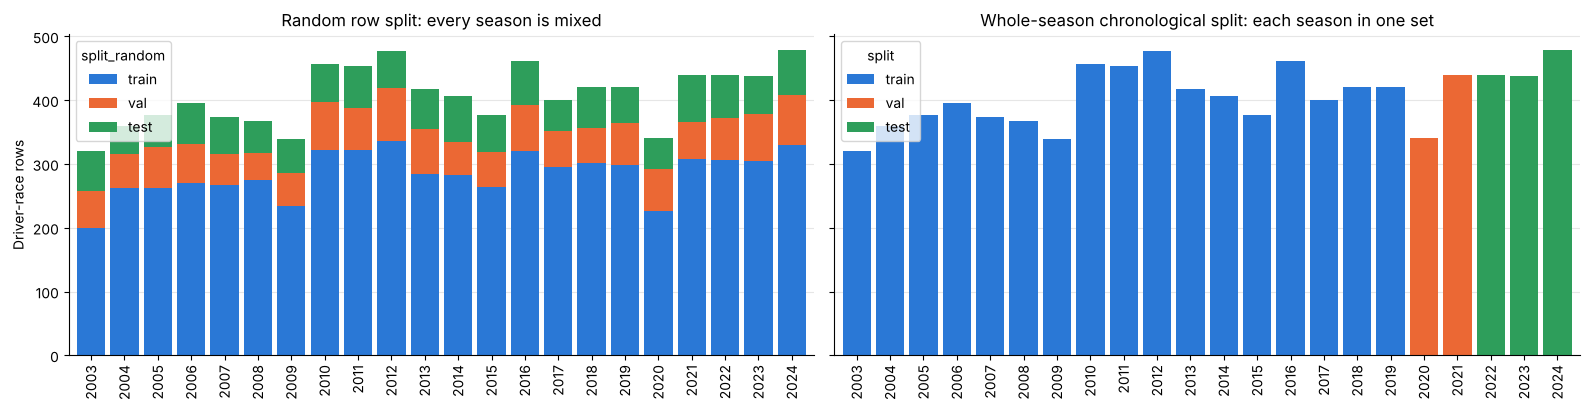

In [93]:
rng = np.random.default_rng(0)
random_label = rng.choice(["train", "val", "test"], size=len(model_table), p=[0.70, 0.15, 0.15])
rand = model_table[["raceId", "year", "date"]].assign(split_random=random_label)

train_races = set(rand.loc[rand["split_random"].eq("train"), "raceId"])
test_rows = rand[rand["split_random"].eq("test")]
latest_train_date = rand.loc[rand["split_random"].eq("train"), "date"].max()
share_test_races_in_train = test_rows["raceId"].drop_duplicates().isin(train_races).mean()
share_test_rows_with_future_training = (test_rows["date"] < latest_train_date).mean()

print(f"Random split: {share_test_races_in_train:.1%} of test races also have drivers in the training set")
print(f"Random split: {share_test_rows_with_future_training:.1%} of test rows are older than the newest training row "
      "(the model would learn from the future)")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), sharey=True)
colors = {"train": BLUE, "val": ORANGE, "test": GREEN}
by_year_random = rand.groupby(["year", "split_random"]).size().unstack(fill_value=0)[["train", "val", "test"]]
by_year_random.plot(kind="bar", stacked=True, ax=axes[0], color=[colors[c] for c in by_year_random.columns], width=0.85)
axes[0].set_title("Random row split: every season is mixed")
by_year_chrono = model_table.groupby(["year", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
by_year_chrono.plot(kind="bar", stacked=True, ax=axes[1], color=[colors[c] for c in by_year_chrono.columns], width=0.85)
axes[1].set_title("Whole-season chronological split: each season in one set")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("Driver-race rows"); style_axis(ax)
t3_show("t3_split_random_vs_chronological")

**Reading the result.** Under a random split almost every test race also appears in training, and almost every test
row is older than the newest training row. Both mean that a random split would report optimistic scores that the
model could never reach on a real future race. A **whole-season chronological split** removes both problems by
construction: each race, and each season, sits in exactly one set, and every training season comes before every
evaluation season. The remaining question is **where** to put the boundaries.

### 3.2.2 How big must validation and test be? (evidence from the training years)

Validation is used in Task 4 to compare models and choose a probability threshold, and test is used once for the
final report. Both are judged on the **podium** rows, which are only about 15% of the data, so the number of podium
examples decides how noisy their scores are.

**Rule of thumb (stated in advance).** A recall or precision estimated from *n* podium examples has a standard error of
at most √(0.25 / n). We ask for:

- a standard error of at most 0.05 on validation, which needs **n ≥ 100** podium examples;
- a standard error of at most 0.04 on the final test, which needs **n ≥ 157**.

**Checking the rule with real data.** The rule above is a formula, so the cell below checks it empirically. It uses
only seasons that are training data under *every* candidate split (2003–2016), so no possible validation or test season
is touched. It draws random blocks of whole races and scores them with a fixed, model-free ranking (smaller grid number
= more likely podium). It then measures how much the PR-AUC of that ranking varies from block to block as the block
size grows.

year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
races,16,18,19,18,17,18,17,19,19,20,...,19,21,20,21,21,17,22,22,22,24
rows,320,360,376,396,374,368,339,456,453,477,...,376,462,400,420,420,340,439,439,438,479
podiums,48,54,57,54,51,54,51,57,57,60,...,57,63,60,63,63,51,66,66,66,72


,races,podium_examples,PR_AUC_mean,PR_AUC_sd
0,10,30,0.6192,0.0946
1,15,45,0.6236,0.0796
2,20,60,0.6091,0.0641
3,25,75,0.6128,0.0551
4,33,99,0.6067,0.0463
5,40,120,0.6128,0.0418
6,53,159,0.6124,0.0366
7,60,180,0.6108,0.0354
8,70,210,0.6077,0.0318
9,80,240,0.6091,0.0277


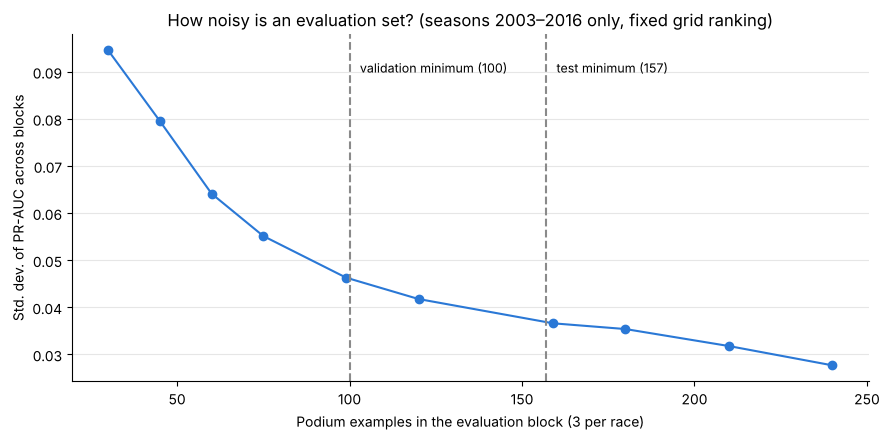

In [94]:
SEASONS = sorted(model_table["year"].unique())
season_stats = (model_table.groupby("year")
                .agg(races=("raceId", "nunique"), rows=("podium", "size"), podiums=("podium", "sum")))
display(season_stats.T)

MIN_VAL_PODIUMS, MIN_TEST_PODIUMS = 100, 157
SAFE_YEARS = [y for y in SEASONS if y <= SEASONS[-1] - 8]          # training under every candidate below
safe = model_table[model_table["year"].isin(SAFE_YEARS)]
safe_races = safe["raceId"].unique()
by_race = {r: g for r, g in safe.groupby("raceId")}

rng = np.random.default_rng(1)
noise_rows = []
for n_races in [10, 15, 20, 25, 33, 40, 53, 60, 70, 80]:
    scores = []
    for _ in range(300):
        block = pd.concat([by_race[r] for r in rng.choice(safe_races, size=n_races, replace=False)])
        scores.append(average_precision_score(block["podium"], -block["grid_model"]))
    noise_rows.append({"races": n_races, "podium_examples": 3 * n_races,
                       "PR_AUC_mean": np.mean(scores), "PR_AUC_sd": np.std(scores, ddof=1)})
noise = pd.DataFrame(noise_rows)
display(noise.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(noise["podium_examples"], noise["PR_AUC_sd"], marker="o", color=BLUE)
for x, label in [(MIN_VAL_PODIUMS, "validation minimum (100)"), (MIN_TEST_PODIUMS, "test minimum (157)")]:
    ax.axvline(x, color=GREY, linestyle="--"); ax.text(x + 3, noise["PR_AUC_sd"].max() * 0.95, label, fontsize=9)
ax.set_xlabel("Podium examples in the evaluation block (3 per race)")
ax.set_ylabel("Std. dev. of PR-AUC across blocks")
ax.set_title(f"How noisy is an evaluation set? (seasons {SAFE_YEARS[0]}–{SAFE_YEARS[-1]} only, fixed grid ranking)")
style_axis(ax)
t3_show("t3_split_noise_vs_size")

**Reading the result.** The spread of PR-AUC shrinks steadily as the block gets bigger. Below about 100 podium examples
(about 33 races), two evaluation sets of the same size can disagree by several PR-AUC points just by chance, which is
larger than the differences we expect between reasonable models in Task 4. The thresholds of 100 (validation) and
157 (test) sit where the curve has flattened. They are therefore minimum sizes, not targets.

### 3.2.3 Comparing every candidate boundary

Candidates: test = the last *k* seasons (k = 1–4), validation = the *m* seasons before them (m = 1–4), training =
every earlier season from 2003. The window starts in 2003 because Task 1 (section 2.5.3) showed that qualifying
data is only complete from then on.

For each of the 16 candidates the heatmaps show validation podium examples, test podium examples and training rows.
Cells that break a minimum are marked ✗, and the chosen split is outlined.

In [ ]:
cand_rows = []
for k in range(1, 5):
    for m in range(1, 5):
        test_years, val_years, train_years = SEASONS[-k:], SEASONS[-(k + m):-k], SEASONS[:-(k + m)]
        sel = lambda years: season_stats.loc[years]
        cand_rows.append({
            "test_seasons": k, "val_seasons": m,
            "train": f"{train_years[0]}–{train_years[-1]}",
            "validation": f"{val_years[0]}–{val_years[-1]}" if m > 1 else f"{val_years[0]}",
            "test": f"{test_years[0]}–{test_years[-1]}" if k > 1 else f"{test_years[0]}",
            "train_rows": int(sel(train_years)["rows"].sum()),
            "val_races": int(sel(val_years)["races"].sum()), "val_podiums": int(sel(val_years)["podiums"].sum()),
            "test_races": int(sel(test_years)["races"].sum()), "test_podiums": int(sel(test_years)["podiums"].sum()),
        })
split_candidates = pd.DataFrame(cand_rows)
split_candidates["val_ok"] = split_candidates["val_podiums"] >= MIN_VAL_PODIUMS
split_candidates["test_ok"] = split_candidates["test_podiums"] >= MIN_TEST_PODIUMS
split_candidates["passes"] = split_candidates["val_ok"] & split_candidates["test_ok"]
# every race has exactly three podium finishers, so the podium counts above are 3 x races: the size rule uses no outcome
assert (split_candidates["val_podiums"] == 3 * split_candidates["val_races"]).all()
assert (split_candidates["test_podiums"] == 3 * split_candidates["test_races"]).all()
chosen_split = split_candidates[split_candidates["passes"]].sort_values("train_rows", ascending=False).iloc[0]
display(split_candidates)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
panels = [("val_podiums", "Validation podium examples", "val_ok"),
          ("test_podiums", "Test podium examples", "test_ok"),
          ("train_rows", "Training rows (higher is better)", "passes")]
for ax, (col, title, ok_col) in zip(axes, panels):
    grid = split_candidates.pivot(index="test_seasons", columns="val_seasons", values=col)
    ok = split_candidates.pivot(index="test_seasons", columns="val_seasons", values=ok_col)
    ax.imshow(grid.to_numpy(), cmap="Blues", aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            mark = "" if ok.iat[i, j] else "  ✗"
            ax.text(j, i, f"{v:,}{mark}", ha="center", va="center", fontsize=10,
                    color="white" if v > grid.to_numpy().max() * 0.6 else "black")
    ci = list(grid.index).index(chosen_split["test_seasons"]); cj = list(grid.columns).index(chosen_split["val_seasons"])
    ax.add_patch(plt.Rectangle((cj - 0.5, ci - 0.5), 1, 1, fill=False, edgecolor=RED, linewidth=3))
    ax.set_xticks(range(grid.shape[1]), [f"{m} season{'s' if m > 1 else ''}" for m in grid.columns])
    ax.set_yticks(range(grid.shape[0]), [f"last {k}" for k in grid.index])
    ax.set_xlabel("Validation length"); ax.set_ylabel("Test = most recent seasons"); ax.set_title(title)
t3_show("t3_split_candidates_heatmap")

SPLIT_T3 = {"train": (SEASONS[0], int(chosen_split["train"][-4:])),
            "val": tuple(int(x) for x in chosen_split["validation"].split("–")) if "–" in chosen_split["validation"]
                   else (int(chosen_split["validation"]),) * 2,
            "test": tuple(int(x) for x in chosen_split["test"].split("–")) if "–" in chosen_split["test"]
                    else (int(chosen_split["test"]),) * 2}
print("Chosen split:", SPLIT_T3)

**What the size rule looks at.** Every race has exactly three podium finishers, so the podium counts in the table are
3 × the number of races (asserted in the cell above). The rule "at least 100 / 157 podium examples" is therefore the same as
"at least 34 / 53 races": it uses the calendar only and never looks at which drivers finished on the podium in a candidate
validation or test season. (Section 4 listed this wording as an inherited limitation; it is a limitation of phrasing, not of method.)

### 3.2.4 Applying the chosen split and checking it

The chosen boundaries are written to a `split` column of the Task 3 table. The checks below confirm that:

- every race and every season sits in exactly one set;
- the sets are in time order;
- the podium rate is similar across the sets.

In [96]:
def assign_split(year):
    for name, (a, b) in SPLIT_T3.items():
        if a <= year <= b:
            return name
    raise ValueError(year)

t3 = model_table.copy()
t3["split"] = t3["year"].map(assign_split)
same_as_task1 = bool((t3["split"] == model_table["split"]).all())
print("Chosen split identical to the split column built in Task 1 (section 2.8):", same_as_task1)

assert t3.groupby("raceId")["split"].nunique().max() == 1, "a race crosses splits"
assert t3.groupby("year")["split"].nunique().max() == 1, "a season crosses splits"
assert t3.loc[t3["split"].eq("train"), "date"].max() < t3.loc[t3["split"].eq("val"), "date"].min()
assert t3.loc[t3["split"].eq("val"), "date"].max() < t3.loc[t3["split"].eq("test"), "date"].min()

split_summary = (t3.groupby("split").agg(seasons=("year", lambda s: f"{s.min()}–{s.max()}"),
                                         races=("raceId", "nunique"), rows=("podium", "size"),
                                         podiums=("podium", "sum"), podium_rate=("podium", "mean"))
                 .reindex(["train", "val", "test"]))
p_lo, p_hi = wilson(split_summary["podiums"], split_summary["rows"])
split_summary["rate_95ci"] = [f"{a:.3f}–{b:.3f}" for a, b in zip(p_lo, p_hi)]
display(split_summary.round(4))

TRAIN = t3[t3["split"].eq("train")].copy()       # the ONLY rows used for feature decisions below
print(f"Training rows used for every feature decision in Task 3: {len(TRAIN):,} "
      f"({TRAIN['year'].min()}–{TRAIN['year'].max()})")

Chosen split identical to the split column built in Task 1 (section 2.8): True


,seasons,races,rows,podiums,podium_rate,rate_95ci
split,,,,,,
train,2003–2019,321,6822,963,0.1412,0.133–0.150
val,2020–2021,39,779,117,0.1502,0.127–0.177
test,2022–2024,68,1356,204,0.1504,0.132–0.170


Training rows used for every feature decision in Task 3: 6,822 (2003–2019)


## 3.3 Engineering the candidate features

### 3.3.1 Candidate list and the hypothesis behind each group

Every candidate has a simple F1 reason to be there. Groups marked **new** were not in the earlier draft.

| Group | Candidates | Hypothesis (why it could predict a podium) |
|---|---|---|
| A. Grid position | `grid_model`, `pit_lane_start` | Starting near the front means fewer cars to pass. |
| B. Qualifying rank & pace | `qual_position_filled`, `has_quali`, `q_gap_pct`, `has_q_time` | One-lap speed shows how fast the car-driver package is this weekend. |
| C. Grid–qualifying movement | `grid_vs_quali_delta` | A penalty moves a fast car back; the car is still fast. |
| D. Qualifying stage flags | `q2_reached`, `q3_reached`, `knockout_quali` | Surviving to Q3 marks the top-ten cars (from 2006). |
| E. Teammate comparison **(new)** | `beat_teammate_quali`, `q_gap_to_teammate_pct` | Same car, so beating the teammate isolates the driver's level this weekend. |
| F. Season standings | points / rank / wins before the race, driver and constructor, + availability flags | Who is strong this season. |
| G. Standings share **(new)** | `drv_pts_share_before`, `con_pts_share_before` | Points as a share of the leader's: comparable across the 2003 and 2010 points-system changes. |
| H. Driver recent form | podium rate and average finish over the last 5 starts, `drv_avg_grid_last5` **(new)**, `drv_no_history` | Recent results carry momentum and current car pace. |
| I. Constructor recent form | podiums per start and average finish over the team's last 5 races, `con_no_history` | The car decides most podiums. |
| J. Reliability **(new)** | `con_mech_dnf_rate_last10`, `drv_finish_rate_last10` | A car that keeps breaking down rarely finishes in the top three. |
| K. Experience | career starts and podiums (driver), career races and podiums (constructor), `driver_age` | Long-run quality and experience. |
| L. Circuit history **(new)** | starts, podium rate and average finish of the driver at this circuit before | Some drivers suit some tracks. |
| M. Race context | `round`, `field_size` **(new)** | Season progress; more cars means more competition for 3 places. |
| N. Circuit identity | `circuitId` (categorical) | Some tracks make the starting order stick (Task 2 Q1). |
| O. Home race | `is_home_race` | Home support (Task 2 Q2 found no effect once grid is controlled). |
| P. Sprint weekend | `is_sprint_weekend` | Different weekend format. |

**Never candidates.** These are excluded and checked again in 3.7:
- current-race results, points, status, laps, pit stops and lap times (all post-race);
- raw IDs (`raceId`, `driverId`, `constructorId`): their numbers have no meaning, so a model could only memorise them;
- `q_best_s`: raw lap seconds, which differ by circuit length;
- `year` / `date`, which only label time.

### 3.3.2 How "history" features are built without leakage

All history features (form, reliability, experience, circuit history) follow one pattern:

1. Take every cleaned driver-race row from **all seasons since 1950**, so a driver's form in 2003 can use 2002 races.
   Order them by race date.
2. A row counts as a **start** unless `positionText = "W"`, i.e. the driver withdrew before the start (Task 1).
3. After each start, store a **snapshot** of the driver's (or team's) totals *including* that start.
4. Each prediction row takes the latest snapshot from a race **strictly before** its own race
   (`merge_asof(..., allow_exact_matches=False)`). The current race's result therefore never enters its own features.
5. Team features first add up both cars into one row per *(team, race)*. Otherwise a teammate's result in the same
   race could leak into the other driver's features.

The whole construction is one function, `build_history_features()`, so that 3.3.4 can **re-run it on deliberately
corrupted results** to prove that nothing from the current race leaks in.

In [97]:
race_order = (races_c[["raceId", "date"]].drop_duplicates("raceId").sort_values(["date", "raceId"]).reset_index(drop=True))
race_order["event_order"] = np.arange(len(race_order))

hist_base = (
    core[["raceId", "driverId", "constructorId", "circuitId", "year", "grid_model", "podium"]]
    .merge(post_race_info[["raceId", "driverId", "positionOrder", "positionText", "status_group"]],
           on=["raceId", "driverId"], how="left", validate="one_to_one")
    .merge(race_order[["raceId", "event_order"]], on="raceId", how="left", validate="many_to_one")
)
assert hist_base["event_order"].notna().all() and not hist_base.duplicated(["raceId", "driverId"]).any()
print(f"History table: {len(hist_base):,} driver-race rows, seasons {hist_base['year'].min()}–{hist_base['year'].max()}")


def _asof(rows, snaps, by, cols):
    # Attach to every row the latest snapshot from a STRICTLY earlier race (same 'by' key).
    left = rows[["raceId", "driverId", "event_order"] + [b for b in by if b not in ("driverId",)]].sort_values("event_order")
    right = snaps[by + ["event_order"] + cols].sort_values("event_order")
    out = pd.merge_asof(left, right, on="event_order", by=by, direction="backward", allow_exact_matches=False)
    return out[["raceId", "driverId"] + cols]


def build_history_features(h):
    h = h.copy()
    h["started"] = h["positionText"].ne("W").astype(int)
    h["finished"] = h["status_group"].eq("finished").astype(int)
    h["mech_dnf"] = (h["status_group"].eq("mechanical") & h["started"].eq(1)).astype(int)   # breakdowns of real starts only
    st = h[h["started"].eq(1)].sort_values(["event_order", "raceId"]).copy()

    # --- driver snapshots (after each start, inclusive)
    g = st.groupby("driverId", sort=False)
    st["s_starts"] = g.cumcount() + 1
    st["s_podiums"] = g["podium"].cumsum()
    roll = lambda col, w: g[col].transform(lambda s: s.rolling(w, min_periods=1).mean())
    st["s_pod5"] = roll("podium", 5)
    st["s_fin5"] = roll("positionOrder", 5)
    st["s_grid5"] = roll("grid_model", 5)
    st["s_finrate10"] = roll("finished", 10)
    drv = _asof(h, st, ["driverId"], ["s_starts", "s_podiums", "s_pod5", "s_fin5", "s_grid5", "s_finrate10"])
    drv = drv.rename(columns={"s_starts": "drv_prev_starts", "s_podiums": "drv_podiums_before",
                              "s_pod5": "drv_podium_rate_last5", "s_fin5": "drv_avg_finish_last5",
                              "s_grid5": "drv_avg_grid_last5", "s_finrate10": "drv_finish_rate_last10"})

    # --- driver-at-this-circuit snapshots
    gc = st.groupby(["driverId", "circuitId"], sort=False)
    st["c_starts"] = gc.cumcount() + 1
    st["c_podiums"] = gc["podium"].cumsum()
    st["c_fin_sum"] = gc["positionOrder"].cumsum()
    circ = _asof(h, st, ["driverId", "circuitId"], ["c_starts", "c_podiums", "c_fin_sum"])
    circ["drv_circuit_prev_starts"] = circ["c_starts"]
    circ["drv_circuit_podium_rate"] = circ["c_podiums"] / circ["c_starts"]
    circ["drv_circuit_avg_finish"] = circ["c_fin_sum"] / circ["c_starts"]
    circ = circ.drop(columns=["c_starts", "c_podiums", "c_fin_sum"])

    # --- constructor: both cars summed into one row per (team, race), then snapshots after each race
    h["finish_if_started"] = h["positionOrder"].where(h["started"].eq(1), 0)
    cr = (h.groupby(["constructorId", "raceId", "event_order"], as_index=False)
            .agg(c_starts=("started", "sum"), c_pods=("podium", "sum"),
                 c_fin=("finish_if_started", "sum"), c_mech=("mech_dnf", "sum"))
            .sort_values(["event_order", "raceId"]))
    gk = cr.groupby("constructorId", sort=False)
    rsum = lambda col, w: gk[col].transform(lambda s: s.rolling(w, min_periods=1).sum())
    cr["k_races"] = gk.cumcount() + 1
    cr["k_podiums"] = gk["c_pods"].cumsum()
    st5, st10 = rsum("c_starts", 5), rsum("c_starts", 10)
    cr["k_pod5"] = rsum("c_pods", 5) / st5.replace(0, np.nan)
    cr["k_fin5"] = rsum("c_fin", 5) / st5.replace(0, np.nan)
    cr["k_mech10"] = rsum("c_mech", 10) / st10.replace(0, np.nan)
    rows_c = h[["raceId", "driverId", "constructorId", "event_order"]]
    con = _asof(rows_c, cr, ["constructorId"], ["k_races", "k_podiums", "k_pod5", "k_fin5", "k_mech10"])
    con = con.rename(columns={"k_races": "con_prev_races", "k_podiums": "con_podiums_before",
                              "k_pod5": "con_podium_rate_last5", "k_fin5": "con_avg_finish_last5",
                              "k_mech10": "con_mech_dnf_rate_last10"})

    out = (h[["raceId", "driverId"]]
           .merge(drv, on=["raceId", "driverId"], validate="one_to_one")
           .merge(circ, on=["raceId", "driverId"], validate="one_to_one")
           .merge(con, on=["raceId", "driverId"], validate="one_to_one"))
    for c in ["drv_prev_starts", "drv_podiums_before", "drv_circuit_prev_starts", "con_prev_races", "con_podiums_before"]:
        out[c] = out[c].fillna(0).astype(int)
    out["drv_no_history"] = out["drv_prev_starts"].eq(0).astype(int)
    out["con_no_history"] = out["con_prev_races"].eq(0).astype(int)
    return out


history_features = build_history_features(hist_base)
assert len(history_features) == len(hist_base) and not history_features.duplicated(["raceId", "driverId"]).any()
display(history_features.describe().T.round(3))

History table: 24,719 driver-race rows, seasons 1950–2024


,count,mean,std,min,25%,50%,75%,max
raceId,24719.0,551.437,321.217,1.0,285.000,530.000,828.000,1144.0
driverId,24719.0,276.465,288.375,1.0,52.000,163.000,383.000,862.0
drv_prev_starts,24719.0,67.895,68.775,0.0,15.000,45.000,99.000,401.0
drv_podiums_before,24719.0,13.327,26.083,0.0,0.000,2.000,15.000,202.0
drv_podium_rate_last5,24028.0,0.139,0.238,0.0,0.000,0.000,0.200,1.0
drv_avg_finish_last5,24028.0,11.634,4.433,1.0,8.600,11.800,14.800,31.0
drv_avg_grid_last5,24028.0,11.672,5.797,1.0,7.000,11.600,16.000,30.0
drv_finish_rate_last10,24028.0,0.608,0.254,0.0,0.400,0.600,0.800,1.0
drv_circuit_prev_starts,24719.0,2.699,3.210,0.0,0.000,2.000,4.000,20.0
drv_circuit_podium_rate,17226.0,0.148,0.247,0.0,0.000,0.000,0.250,1.0


### 3.3.3 Same-race pre-race features and attaching everything to the modelling table

These features use only the **current** race, and only information that exists before the start:

- **Qualifying-stage fix.** The draft found that `q2_reached` / `q3_reached` were 0 for every driver before the
  knockout format existed (2003–2005, when there was no Q3). That mixed "eliminated in Q1" with "there was no Q2/Q3".
  `knockout_quali` (the race had a Q3 session) marks the format, and in non-knockout races the two flags are set to a
  **structural 0**. Task 1 (2.5.2) now stores those two flags as `NaN` where the session did not exist, and Task 3 turns that into the
  structural 0 plus the `knockout_quali` flag, so this table is unchanged.
- **Teammate comparison.** Within each `(race, constructor)`:
  - `beat_teammate_quali` = 1 if the driver qualified ahead of the teammate;
  - `q_gap_to_teammate_pct` = the driver's best qualifying lap relative to the teammate's, in %.

  Both come from the completed qualifying session. They are missing when there is no teammate, or no lap time.
- **Standings share.** Driver (constructor) points before the race divided by the **leader's** points before the
  race. The leader is read from the same previous-round standings table, so it is also pre-race. The share is
  undefined (left missing) when the leader still has 0 points (round 1). The flag `has_prev_driver_standing` already
  marks that case.
- **Field size.** Number of cars in the race (known once the grid is published).
- **Grid movement.** `grid_vs_quali_delta = grid_model − qual_position_filled`; positive means the driver starts
  further back than they qualified.

In [98]:
# --- qualifying format and stage flags
q_times = clean_tables["qualifying"][["raceId", "driverId", "q2", "q3"]]
race_format = q_times.groupby("raceId").agg(q3_times=("q3", "count")).reset_index()
race_format["knockout_quali"] = (race_format["q3_times"] > 0).astype(int)

# --- teammate comparison inside the same race (qualifying is complete before the race)
def _other_min(frame, col):
    # For every row: the smallest value of `col` among the OTHER cars of the same team in the same race.
    f = frame[["raceId", "constructorId", col]].copy()
    f["_rank"] = f.groupby(["raceId", "constructorId"])[col].rank(method="first")
    first = f[f["_rank"] == 1].set_index(["raceId", "constructorId"])[col]
    second = f[f["_rank"] == 2].set_index(["raceId", "constructorId"])[col]
    key = pd.MultiIndex.from_frame(f[["raceId", "constructorId"]])
    best, runner_up = first.reindex(key).to_numpy(), second.reindex(key).to_numpy()
    return np.where(f["_rank"].to_numpy() == 1, runner_up, best)   # NaN rank (missing value) -> best of the others

tm = core[["raceId", "driverId", "constructorId", "qual_position_filled", "q_best_s"]].copy()
tm["n_team_cars"] = tm.groupby(["raceId", "constructorId"])["driverId"].transform("size")
tm["teammate_pos"] = _other_min(tm, "qual_position_filled")
tm["teammate_q_best"] = _other_min(tm, "q_best_s")
has_mate = tm["n_team_cars"].gt(1)
tm["beat_teammate_quali"] = np.where(has_mate, (tm["qual_position_filled"] < tm["teammate_pos"]).astype(float), np.nan)
tm["q_gap_to_teammate_pct"] = np.where(has_mate, 100 * (tm["q_best_s"] / tm["teammate_q_best"] - 1), np.nan)
print("Teams with more than two cars in one race (2003+):",
      int((tm.merge(core[["raceId","driverId","year"]], on=["raceId","driverId"]).query("year >= 2003")["n_team_cars"] > 2).sum()))

# --- leader points before the race (same previous-round standings as the _before columns)
lead_drv = clean_tables["driver_standings"].groupby("raceId")["points"].max().rename("leader_drv_pts")
lead_con = clean_tables["constructor_standings"].groupby("raceId")["points"].max().rename("leader_con_pts")
field = core.groupby("raceId").size().rename("field_size")

t3 = (t3.merge(history_features, on=["raceId", "driverId"], how="left", validate="one_to_one")
        .merge(race_format[["raceId", "knockout_quali"]], on="raceId", how="left", validate="many_to_one")
        .merge(tm[["raceId", "driverId", "beat_teammate_quali", "q_gap_to_teammate_pct"]],
               on=["raceId", "driverId"], how="left", validate="one_to_one")
        .merge(core[["raceId", "driverId", "prev_raceId"]], on=["raceId", "driverId"], how="left", validate="one_to_one")
        .merge(lead_drv, left_on="prev_raceId", right_index=True, how="left")
        .merge(lead_con, left_on="prev_raceId", right_index=True, how="left")
        .merge(field, left_on="raceId", right_index=True, how="left"))

t3["knockout_quali"] = t3["knockout_quali"].fillna(0).astype(int)
no_ko = t3["knockout_quali"].eq(0)
t3.loc[no_ko, ["q2_reached", "q3_reached"]] = 0                     # structural zero: no Q2/Q3 session existed
t3["has_q_time"] = t3["q_gap_pct"].notna().astype(int)
t3["grid_vs_quali_delta"] = t3["grid_model"] - t3["qual_position_filled"]
t3["drv_pts_share_before"] = t3["drv_pts_before"] / t3["leader_drv_pts"].where(t3["leader_drv_pts"] > 0)
t3["con_pts_share_before"] = t3["con_pts_before"] / t3["leader_con_pts"].where(t3["leader_con_pts"] > 0)
t3 = t3.drop(columns=["prev_raceId", "leader_drv_pts", "leader_con_pts"])

assert len(t3) == len(model_table) and not t3.duplicated(["raceId", "driverId"]).any()
assert (t3[["raceId", "driverId", "podium"]].to_numpy() == model_table[["raceId", "driverId", "podium"]].to_numpy()).all()
assert t3.loc[t3["knockout_quali"].eq(1), "year"].min() >= 2006
assert t3["drv_pts_share_before"].dropna().between(0, 1).all() and t3["con_pts_share_before"].dropna().between(0, 1).all()
print("Task 3 table:", t3.shape, "| rows, keys and target unchanged")

Teams with more than two cars in one race (2003+): 0
Task 3 table: (8957, 54) | rows, keys and target unchanged


### 3.3.4 Leakage tests for the engineered features

Two independent checks:

1. **Recompute one feature a second way.** Driver podium rate over the last 5 starts, recomputed with the textbook
   `shift(1).rolling(5)` on start rows, must equal the snapshot version.
2. **Corruption test (strongest).** Pick 40 races and invert their results: podium becomes not-podium and vice
   versa, finishing order reversed, every status flipped between finished and mechanical. Then rebuild all history
   features.
   - If any feature of *those same races* changes, current-race information is leaking.
   - Features of *later* races **should** change, which proves the test is sensitive.

In [99]:
# 1) independent recomputation on start rows
chk = hist_base[hist_base["positionText"].ne("W")].sort_values(["event_order", "raceId"]).copy()
chk["expected"] = chk.groupby("driverId")["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
chk = chk.merge(history_features[["raceId", "driverId", "drv_podium_rate_last5"]], on=["raceId", "driverId"])
assert np.allclose(chk["expected"], chk["drv_podium_rate_last5"], equal_nan=True)
print(f"Check 1 passed on {len(chk):,} start rows: snapshot form == shift(1).rolling(5)")

# 2) corruption test: corrupt ONE race at a time, rebuild, compare
def _corrupt_one(h, race_id):
    c = h.copy()
    m = c["raceId"].eq(race_id)
    c.loc[m, "podium"] = 1 - c.loc[m, "podium"]
    c.loc[m, "positionOrder"] = c.loc[m, "positionOrder"].max() + 1 - c.loc[m, "positionOrder"]
    c.loc[m, "status_group"] = np.where(c.loc[m, "status_group"].eq("finished"), "mechanical", "finished")
    return c

feat_cols = [c for c in history_features.columns if c not in ("raceId", "driverId")]
base_idx = history_features.set_index(["raceId", "driverId"]).sort_index()
rng = np.random.default_rng(7)
corruption_rows = []
for race_id in rng.choice(t3["raceId"].unique(), size=20, replace=False):
    rebuilt = build_history_features(_corrupt_one(hist_base, race_id)).set_index(["raceId", "driverId"]).sort_index()
    diff = ~np.isclose(base_idx[feat_cols].to_numpy(float), rebuilt[feat_cols].to_numpy(float), equal_nan=True)
    own = base_idx.index.get_level_values("raceId") == race_id
    corruption_rows.append({"corrupted raceId": race_id,
                            "changed values in that race": int(diff[own].sum()),
                            "changed values in other races": int(diff[~own].sum())})
corruption_check = pd.DataFrame(corruption_rows)
display(corruption_check)
assert corruption_check["changed values in that race"].eq(0).all()
assert corruption_check["changed values in other races"].gt(0).all()
print("PASS: no history feature uses its own race's outcome.")

Check 1 passed on 24,586 start rows: snapshot form == shift(1).rolling(5)


,corrupted raceId,changed values in that race,changed values in other races
0,339,0,7223
1,1102,0,2230
2,966,0,5189
3,991,0,4038
4,911,0,4721
5,23,0,5995
6,1053,0,3313
7,97,0,6883
8,900,0,6099
9,14,0,5491


PASS: no history feature uses its own race's outcome.


### 3.3.5 What the engineering steps did to the data (range, distribution, missingness)

The checklist asks for the **effect of each preprocessing / engineering step on the data**. Four short checks, one per kind of step:

1. **Gap to pole instead of lap seconds** (`q_gap_pct` from `q_best_s`). Raw lap seconds mostly say *which circuit it is*; how much
   of each variable is explained by the circuit alone (η², 0 to 1) shows what the step removed.
2. **Share of the leader's points instead of raw points** (`*_pts_share_before`). The 2010 change from 10 to 25 points per win
   shifts raw points; the share should not shift. The plot compares the two for the same kind of driver every season.
3. **Rolling "last 5 / last 10" features.** Range, missingness and the first-race effect of every engineered feature in one table.
4. **Structural zero for Q2/Q3.** What Task 1 stores (`NaN`) and what Task 3 hands over (0 plus `knockout_quali`).

In [ ]:
# (1) lap seconds versus gap: how much is just 'which circuit'?
def eta_squared(values, groups):
    d = pd.DataFrame({"v": values, "g": groups}).dropna()
    total = ((d["v"] - d["v"].mean()) ** 2).sum()
    between = d.groupby("g")["v"].apply(lambda s: len(s) * (s.mean() - d["v"].mean()) ** 2).sum()
    return between / total
print(f"Share of variance explained by the circuit alone: q_best_s (seconds) {eta_squared(t3['q_best_s'], t3['circuitId']):.2f} | "
      f"q_gap_pct {eta_squared(t3['q_gap_pct'], t3['circuitId']):.2f} | q1_gap_pct {eta_squared(t3['q1_gap_pct'], t3['circuitId']):.2f}")

# (2) raw points versus share of the leader's points, same driver type every season (front-row starters at round 8)
mid = t3[(t3["round"] == 8) & (t3["grid_model"] <= 3)]
by_year = mid.groupby("year").agg(raw_points=("drv_pts_before", "median"), share=("drv_pts_share_before", "median"))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(by_year.index, by_year["raw_points"], marker="o", color=BLUE); ax[0].axvline(2009.5, color=GREY, linestyle="--")
ax[0].set_title("Raw championship points before round 8 (median front-row starter)"); style_axis(ax[0])
ax[1].plot(by_year.index, by_year["share"], marker="o", color=GREEN); ax[1].axvline(2009.5, color=GREY, linestyle="--")
ax[1].set_ylim(0, 1); ax[1].set_title("Share of the leader's points (same drivers)"); style_axis(ax[1])
t3_show("t3_engineering_points_vs_share")
print("Median raw points before / after the 2010 points change:",
      round(by_year.loc[:2009, "raw_points"].median(), 1), "/", round(by_year.loc[2010:, "raw_points"].median(), 1),
      "| median share:", round(by_year.loc[:2009, "share"].median(), 2), "/", round(by_year.loc[2010:, "share"].median(), 2))

# (3) range, missingness and distribution of every engineered feature
ENGINEERED = ["q_gap_pct", "q1_gap_pct", "grid_vs_quali_delta", "q_gap_to_teammate_pct", "beat_teammate_quali", "drv_pts_share_before",
              "con_pts_share_before", "drv_podium_rate_last5", "drv_avg_finish_last5", "drv_avg_grid_last5", "drv_finish_rate_last10",
              "con_podium_rate_last5", "con_avg_finish_last5", "con_mech_dnf_rate_last10", "field_size"]
eng = t3[ENGINEERED].describe(percentiles=[0.5]).T[["count", "mean", "min", "50%", "max"]]
eng["% missing"] = 100 * t3[ENGINEERED].isna().mean()
display(eng.round(3))

# (4) the structural zero
sz = t3.groupby("quali_format").agg(rows=("podium", "size"), task1_q3_NaN=("raceId", lambda s: int(model_table.loc[s.index, "q3_reached"].isna().sum())),
                                    task3_q3_mean=("q3_reached", "mean"), task3_q3_missing=("q3_reached", lambda s: int(s.isna().sum())))
display(sz.round(3))

**Reading the effects.**

- **Gap instead of seconds.** The circuit alone explains 79% of the variance of raw lap seconds (`q_best_s`) but only 2% of
  `q_gap_pct` and of `q1_gap_pct`. The step removes "which track is this" and keeps "how far from the fastest car", which is why raw
  seconds are never a candidate.
- **Share instead of points.** Before and after the 2010 change the median raw points of a front-row starter at round 8 jump from about 35 to
  94 (almost threefold), while the share of the leader's points moves from 0.60 to 0.68. The share removes the points-system break
  (it does not remove real changes in dominance, which is what the feature is meant to show).
- **Ranges and missingness.** Every engineered rate stays in its natural range (rates and shares in 0-1, average finish 1-24, gaps from 0).
  Missingness is small and has a cause: about 1% for the rolling features (a driver's or team's first start), 1.6% for the qualifying
  gaps (no lap time), 3.3% for the teammate gap (no teammate), and 5.1% for the shares (round 1, where the leader has 0 points).
- **Structural zero.** The 1,076 rows of 2003-2005 and of the 2015 US GP (no Q2/Q3 session) are `NaN` in Task 1 and become 0 plus
  `knockout_quali = 0` in Task 3; in knockout races 46% of the rows reached Q3. Nothing is written as "eliminated" where no
  session existed.

## 3.4 Evidence for every candidate feature (training seasons 2003–2019 only)

For every candidate the evidence has three parts:

1. **Does the podium rate change with the feature, and is the pattern the same in both training eras?** Top row of
   each figure: podium rate per bin with 95% intervals, separately for 2003–2013 and 2014–2019. A pattern that
   appears in both eras is unlikely to be a fluke of one period.
2. **Does it still matter once starting position is known?** Bottom row: a heatmap of podium rate by **grid group**
   (rows) and **feature bin** (columns). Starting position is the strongest single predictor, so if colours change
   *along a row*, the feature carries information the grid does not. If every row is flat, the feature only repeats the
   grid.
3. **Numbers**, collected in 3.4.17:
   - Spearman correlation with podium (overall and per era);
   - the ROC-AUC of the feature used alone;
   - a likelihood-ratio test of adding the feature to a grid-only logistic model.

Bins are training-set quantiles (or the actual values for features with few values). Missing values get their own
`missing` bin rather than being hidden. All of this is **association, not causation**.

In [100]:
CANDIDATE_GROUPS = {
    "A. Grid position": ["grid_model", "pit_lane_start"],
    "B. Qualifying rank & pace": ["qual_position_filled", "has_quali", "q_gap_pct", "has_q_time"],
    "C. Grid-qualifying movement": ["grid_vs_quali_delta"],
    "D. Qualifying stage flags": ["q2_reached", "q3_reached", "knockout_quali"],
    "E. Teammate comparison": ["beat_teammate_quali", "q_gap_to_teammate_pct"],
    "F. Season standings": ["drv_pts_before", "drv_pos_before", "drv_wins_before", "has_prev_driver_standing",
                            "con_pts_before", "con_pos_before", "con_wins_before", "has_prev_constructor_standing"],
    "G. Standings share": ["drv_pts_share_before", "con_pts_share_before",
                           "has_prev_driver_standing", "has_prev_constructor_standing"],
    "H. Driver recent form": ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_avg_grid_last5", "drv_no_history"],
    "I. Constructor recent form": ["con_podium_rate_last5", "con_avg_finish_last5", "con_no_history"],
    "J. Reliability": ["con_mech_dnf_rate_last10", "drv_finish_rate_last10"],
    "K. Experience": ["drv_prev_starts", "drv_podiums_before", "con_prev_races", "con_podiums_before", "driver_age"],
    "L. Circuit history": ["drv_circuit_prev_starts", "drv_circuit_podium_rate", "drv_circuit_avg_finish"],
    "M. Race context": ["round", "field_size"],
    "N. Circuit identity": ["circuitId"],
    "O. Home race": ["is_home_race"],
    "P. Sprint weekend": ["is_sprint_weekend"],
}
CATEGORICAL_FEATURES = {"circuitId"}
ALL_CANDIDATES = list(dict.fromkeys(f for fs in CANDIDATE_GROUPS.values() for f in fs))
assert set(ALL_CANDIDATES).issubset(t3.columns)
print(len(ALL_CANDIDATES), "candidate features in", len(CANDIDATE_GROUPS), "groups")

TRAIN = t3[t3["split"].eq("train")].copy()
TRAIN["era_t3"] = np.where(TRAIN["year"] <= 2013, "2003–2013", "2014–2019")
GRID_GROUPS = ["P1", "P2–3", "P4–6", "P7–10", "P11+"]
TRAIN["grid_group"] = pd.cut(TRAIN["grid_model"], [0, 1, 3, 6, 10, np.inf], labels=GRID_GROUPS)


RANK_EDGES, RANK_LABELS = [0, 1, 3, 6, 10, 15, np.inf], ["1", "2–3", "4–6", "7–10", "11–15", "16+"]
BIN_SPECS = {   # fixed, F1-meaningful bins; everything else uses training quantiles
    "grid_model": (RANK_EDGES, RANK_LABELS),
    "qual_position_filled": (RANK_EDGES, RANK_LABELS),
    "drv_pos_before": (RANK_EDGES, RANK_LABELS),
    "con_pos_before": ([0, 1, 2, 3, 5, 8, np.inf], ["1", "2", "3", "4–5", "6–8", "9+"]),
    "grid_vs_quali_delta": ([-np.inf, -1, 0, 2, 5, np.inf], ["moved up", "same", "back 1–2", "back 3–5", "back 6+"]),
    "drv_wins_before": ([-0.5, 0.5, 1.5, 3.5, np.inf], ["0", "1", "2–3", "4+"]),
    "con_wins_before": ([-0.5, 0.5, 2.5, 5.5, np.inf], ["0", "1–2", "3–5", "6+"]),
    "drv_circuit_prev_starts": ([-0.5, 0.5, 1.5, 3.5, 6.5, np.inf], ["0", "1", "2–3", "4–6", "7+"]),
    "round": ([0, 5, 10, 15, np.inf], ["1–5", "6–10", "11–15", "16+"]),
}
RATE_SPEC = ([-0.001, 0, 0.2, 0.4, 0.6, 1], ["0", "≤20%", "20–40%", "40–60%", "60–100%"])
for _f in ["drv_podium_rate_last5", "con_podium_rate_last5", "drv_circuit_podium_rate"]:
    BIN_SPECS[_f] = RATE_SPEC


def make_bins(series, max_bins=5):
    # Fixed bins for rank-like features, training quantiles otherwise, raw values when few; 'missing' kept separate.
    s = series
    values = s.dropna()
    name = s.name
    if name in BIN_SPECS:
        edges, labels = BIN_SPECS[name]
        lab = pd.cut(s, edges, labels=labels).astype(object).where(s.notna(), "missing")
        order = list(labels)
    elif values.nunique() <= 6:
        lab = s.map(lambda v: "missing" if pd.isna(v) else (f"{v:g}"))
        order = [f"{v:g}" for v in sorted(values.unique())]
    else:
        edges = np.unique(np.quantile(values, np.linspace(0, 1, max_bins + 1)))
        cut = pd.cut(s, edges, include_lowest=True, duplicates="drop")
        fmt = lambda x: (f"{x:.0f}" if abs(x) >= 10 or float(x).is_integer() else f"{x:.2f}").replace("-", "−")
        names = {iv: f"{fmt(max(iv.left, values.min()))} to {fmt(iv.right)}" for iv in cut.cat.categories}
        lab = cut.map(names).astype(object).where(s.notna(), "missing")
        order = [names[iv] for iv in cut.cat.categories]
    if s.isna().any():
        order = order + ["missing"]
    lab = lab.astype(str)
    present = set(lab.unique())
    return lab, [o for o in order if o in present]


def evidence_figure(group, features, fig_name):
    n = len(features)
    fig, axes = plt.subplots(2, n, figsize=(max(6.2 * n, 9), 9.2), squeeze=False,
                             gridspec_kw={"height_ratios": [1, 1.15]})
    tables = {}
    for j, f in enumerate(features):
        lab, order = make_bins(TRAIN[f])
        frame = TRAIN.assign(_bin=lab)
        ax = axes[0, j]
        x = np.arange(len(order))
        for k, (era, color) in enumerate([("2003–2013", BLUE), ("2014–2019", ORANGE)]):
            r = podium_rate_by(frame[frame["era_t3"].eq(era)], "_bin", order).set_index("_bin").reindex(order)
            ax.errorbar(x + (k - 0.5) * 0.18, r["rate"], yerr=[(r["rate"] - r["lo"]).clip(lower=0), (r["hi"] - r["rate"]).clip(lower=0)],
                        fmt="o-", color=color, capsize=3, markersize=5, linewidth=1.6, label=era)
        overall = podium_rate_by(frame, "_bin", order).set_index("_bin").reindex(order)
        ticks = [f"{o}\nn={int(nn) if pd.notna(nn) else 0:,}" for o, nn in zip(order, overall["n"])]
        ax.set_xticks(x, ticks, rotation=0, fontsize=8)
        big = overall[overall["n"] >= 30]
        ax.set_ylim(0, min(1, max(0.25, float(np.nanmax(big["hi"] if len(big) else overall["hi"])) * 1.15)))
        ax.set_title(f, fontsize=11, fontweight="bold"); ax.set_ylabel("Podium rate (95% CI)")
        style_axis(ax)
        if j == 0:
            ax.legend(frameon=False, fontsize=8.5, title="training era", title_fontsize=8.5)
        tables[f] = overall

        ax = axes[1, j]
        if f in ("grid_model",):
            hm = TRAIN.assign(_g=pd.cut(TRAIN["grid_model"], [0, 1, 2, 3, 4, 6, 8, 10, 14, np.inf],
                                        labels=["1", "2", "3", "4", "5–6", "7–8", "9–10", "11–14", "15+"]))
            piv = hm.pivot_table(index="_g", columns="year", values="podium", aggfunc="mean", observed=True)
            cnt = None
            ax.set_ylabel("Grid position"); ax.set_xlabel("Training season")
            title = "Podium rate by grid position and season"
        else:
            piv = frame.pivot_table(index="grid_group", columns="_bin", values="podium", aggfunc="mean", observed=True).reindex(columns=order)
            cnt = frame.pivot_table(index="grid_group", columns="_bin", values="podium", aggfunc="size", observed=True).reindex(columns=order)
            ax.set_ylabel("Grid group"); ax.set_xlabel(f"{f} bin")
            title = "Podium rate inside each grid group"
        im = ax.imshow(piv.to_numpy(dtype=float), cmap="YlGnBu", vmin=0, vmax=0.8, aspect="auto")
        ax.set_xticks(range(piv.shape[1]), [str(c) for c in piv.columns], rotation=30 if f != "grid_model" else 90,
                      ha="right" if f != "grid_model" else "center", fontsize=8)
        ax.set_yticks(range(piv.shape[0]), [str(i) for i in piv.index], fontsize=9)
        if cnt is not None:
            for i in range(piv.shape[0]):
                for k in range(piv.shape[1]):
                    v, c = piv.iat[i, k], cnt.iat[i, k]
                    if pd.notna(v):
                        ax.text(k, i, f"{v:.0%}\n{int(c)}", ha="center", va="center", fontsize=7,
                                color="white" if v > 0.45 else "black")
        ax.set_title(title, fontsize=10)
    fig.suptitle(f"{group}: training evidence (top: per era; bottom: holding the grid fixed)", fontsize=13, y=1.0)
    t3_show(fig_name)
    return tables

44 candidate features in 16 groups


### 3.4.1 A. Grid position

**Hypothesis H1 (primary).** Starting near the front means fewer cars to pass; Task 2 Q1 showed front-row starters reach the podium 68–76% of the time.

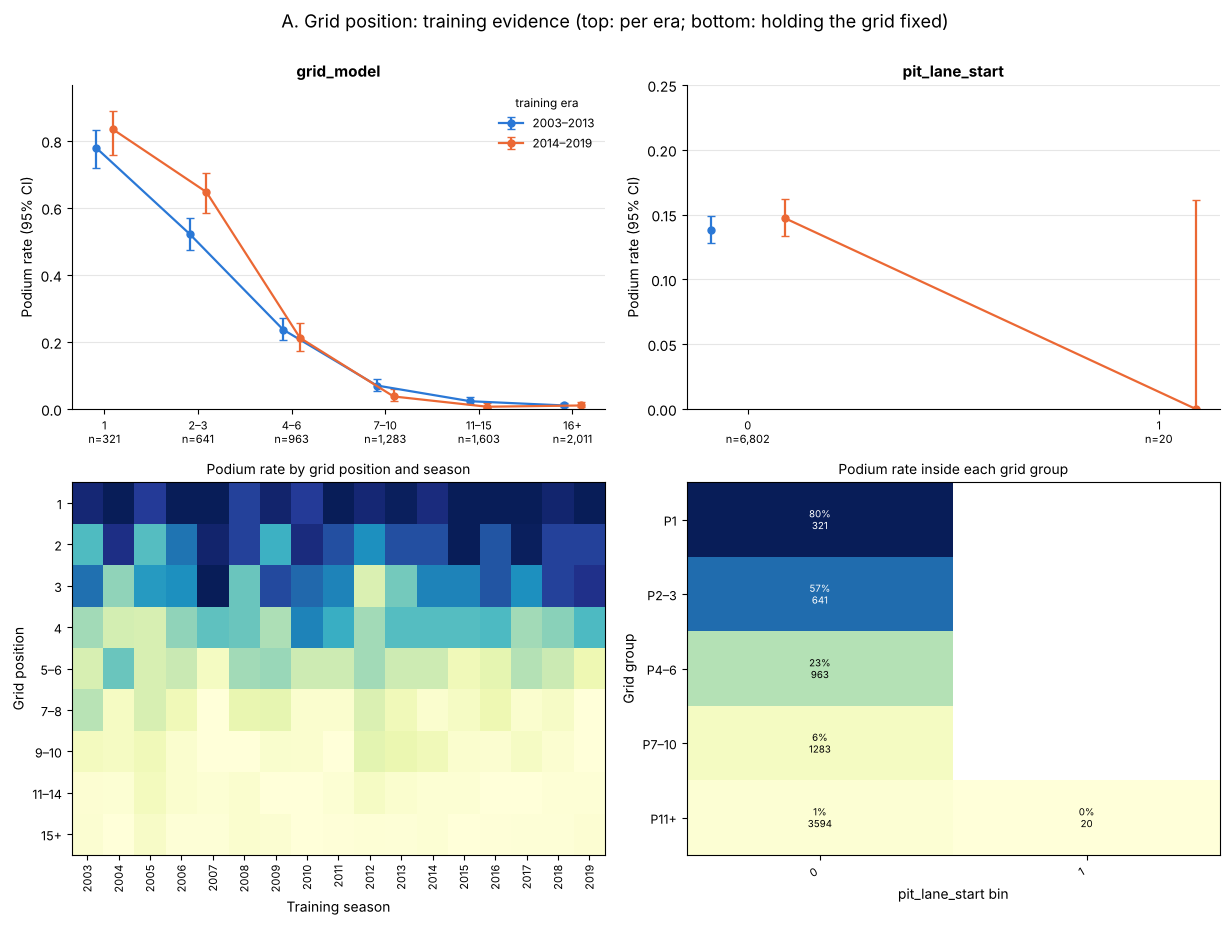

In [101]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("A. Grid position", CANDIDATE_GROUPS["A. Grid position"], "t3_evidence_a"))

**Result.**

- **Strong, monotonic and stable.** The podium rate falls from 78% (2003–13) / 84% (2014–19) for P1, to 52% / 65%
  for P2–3, 24% / 21% for P4–6, 7% / 4% for P7–10, and about 1% from P16 back.
- **Every season.** The season heatmap shows the same top-down pattern in every training season, so the relationship
  is not an artefact of one period.
- **Strongest single candidate.** Spearman ρ = −0.48 (2003–13) and −0.52 (2014–19); grid alone ranks podiums with
  ROC-AUC 0.91 (shown as 0.09 because a *smaller* grid number means *more* podiums).
- **`pit_lane_start` is a companion flag.** Only 20 training rows started from the pit lane, and none reached the
  podium. On its own the flag is weak (0.3% of rows). Its job is to keep the meaning of `grid_model`, where a pit-lane
  start is placed behind the field (Task 1, 2.5.1).
- **Verdict:** H1 confirmed.

### 3.4.2 B. Qualifying rank & pace

**Hypothesis H2 (primary).** One-lap pace shows how fast the car-driver package is this weekend. Task 2 Q1 showed qualifying and grid differ because of penalties.

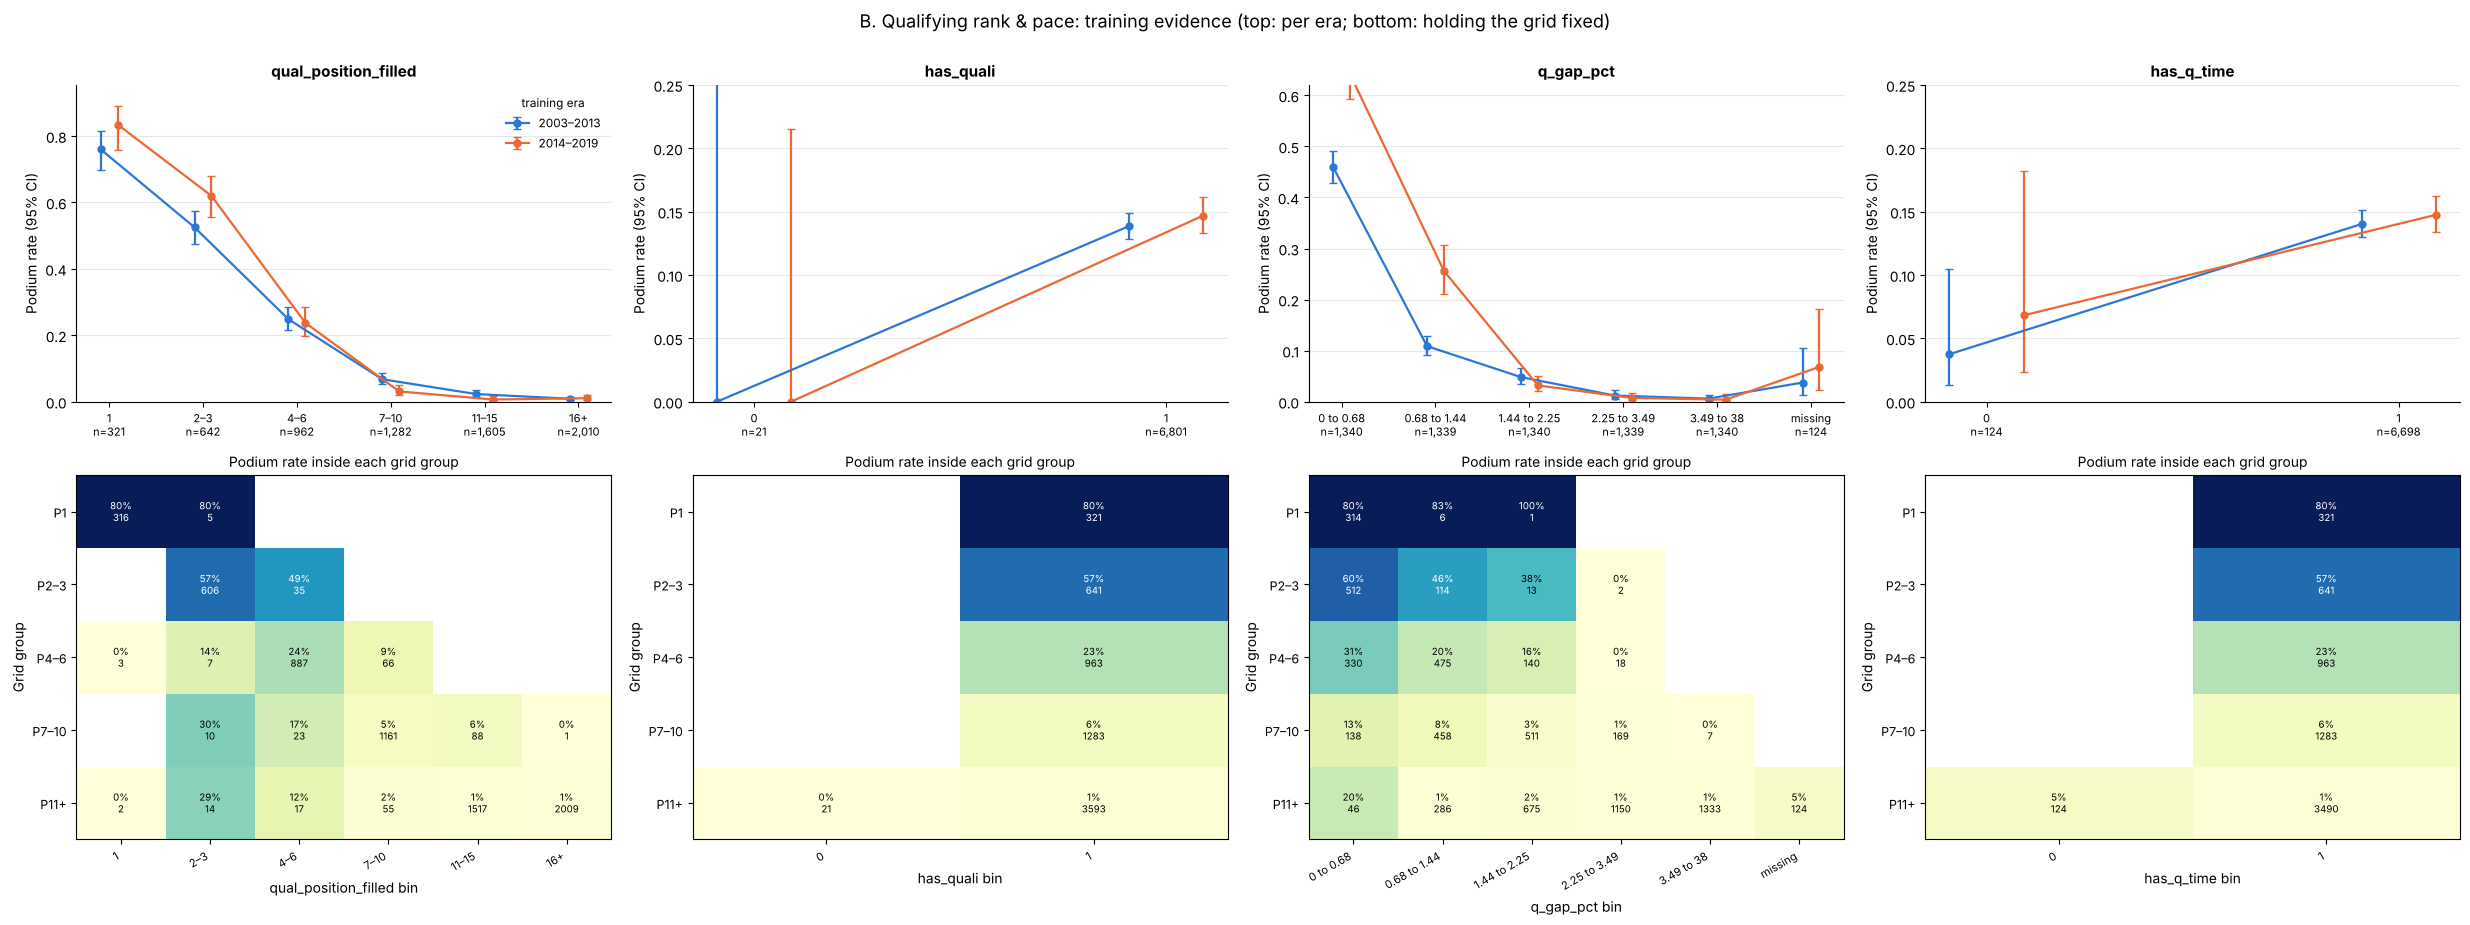

In [102]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("B. Qualifying rank & pace", CANDIDATE_GROUPS["B. Qualifying rank & pace"], "t3_evidence_b"))

**Result.**

- **Pace (`q_gap_pct`) adds beyond the grid.** The fastest fifth of the field (within 0.68% of pole) podiums 46%
  (2003–13) / 64% (2014–19) of the time, against below 1.5% from 2.25% back. The heatmap shows the key point: *inside
  the same grid group* a smaller gap still means more podiums. Among P2–3 starters: 60% → 46% → 38% as the gap grows;
  among P4–6: 31% → 20% → 16%. Its beyond-grid likelihood-ratio χ² is 59 (p < 0.001).
- **`has_q_time` carries information when missing.** The 124 rows without a valid time podium only 4% / 7% of the
  time, against 14% / 15% (χ² = 10, p = 0.001).
- **`has_quali` (21 rows without a record, none on the podium)** is a companion flag that keeps the fallback rank
  honest.
- **`qual_position_filled` is almost a copy of the grid** (ρ = 0.97). It is removed in screening (3.5). Nothing is
  lost: qualifying rank = grid − `grid_vs_quali_delta`.
- **Verdict:** H2 confirmed for pace and its missingness flags.

### 3.4.3 C. Grid-qualifying movement

**Part of H2.** A penalty moves a fast car back; the car is still fast, so its chance should be better than its grid slot suggests.

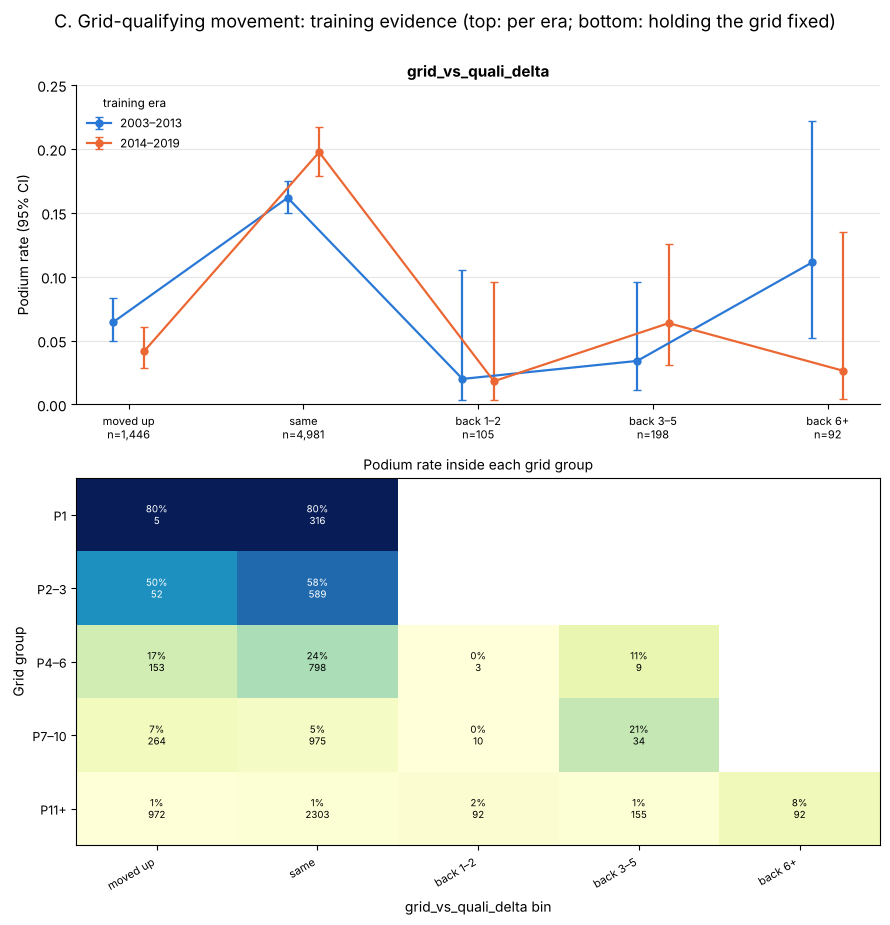

In [103]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("C. Grid-qualifying movement", CANDIDATE_GROUPS["C. Grid-qualifying movement"], "t3_evidence_c"))

**Result.**

- **The plain podium rate by movement is U-shaped:** "moved up" drivers 6% / 4%, "same" 16% / 20%, "back 1–2" 2%.
  Most drivers who move up are midfield cars promoted by others' penalties.
- **The heatmap shows the real signal.** At the *same* grid group, a driver who was pushed back converts better: among
  P7–10 starters, 21% of the "back 3–5" group reached the podium against 5% of the "same" group. Those are fast cars
  starting out of position.
- **This shape is non-linear.** It is why the Pearson filter in 3.6.1 misses this feature (r = 0.009) while χ² and the
  likelihood-ratio test detect it (χ² = 24 beyond the grid, p < 0.001).
- **Verdict:** keep, as part of H2.

### 3.4.4 D. Qualifying stage flags

**New candidate.** Surviving to Q3 marks the top-ten cars, but only from 2006 (no Q3 existed before; see the structural-zero fix in 3.3.3).

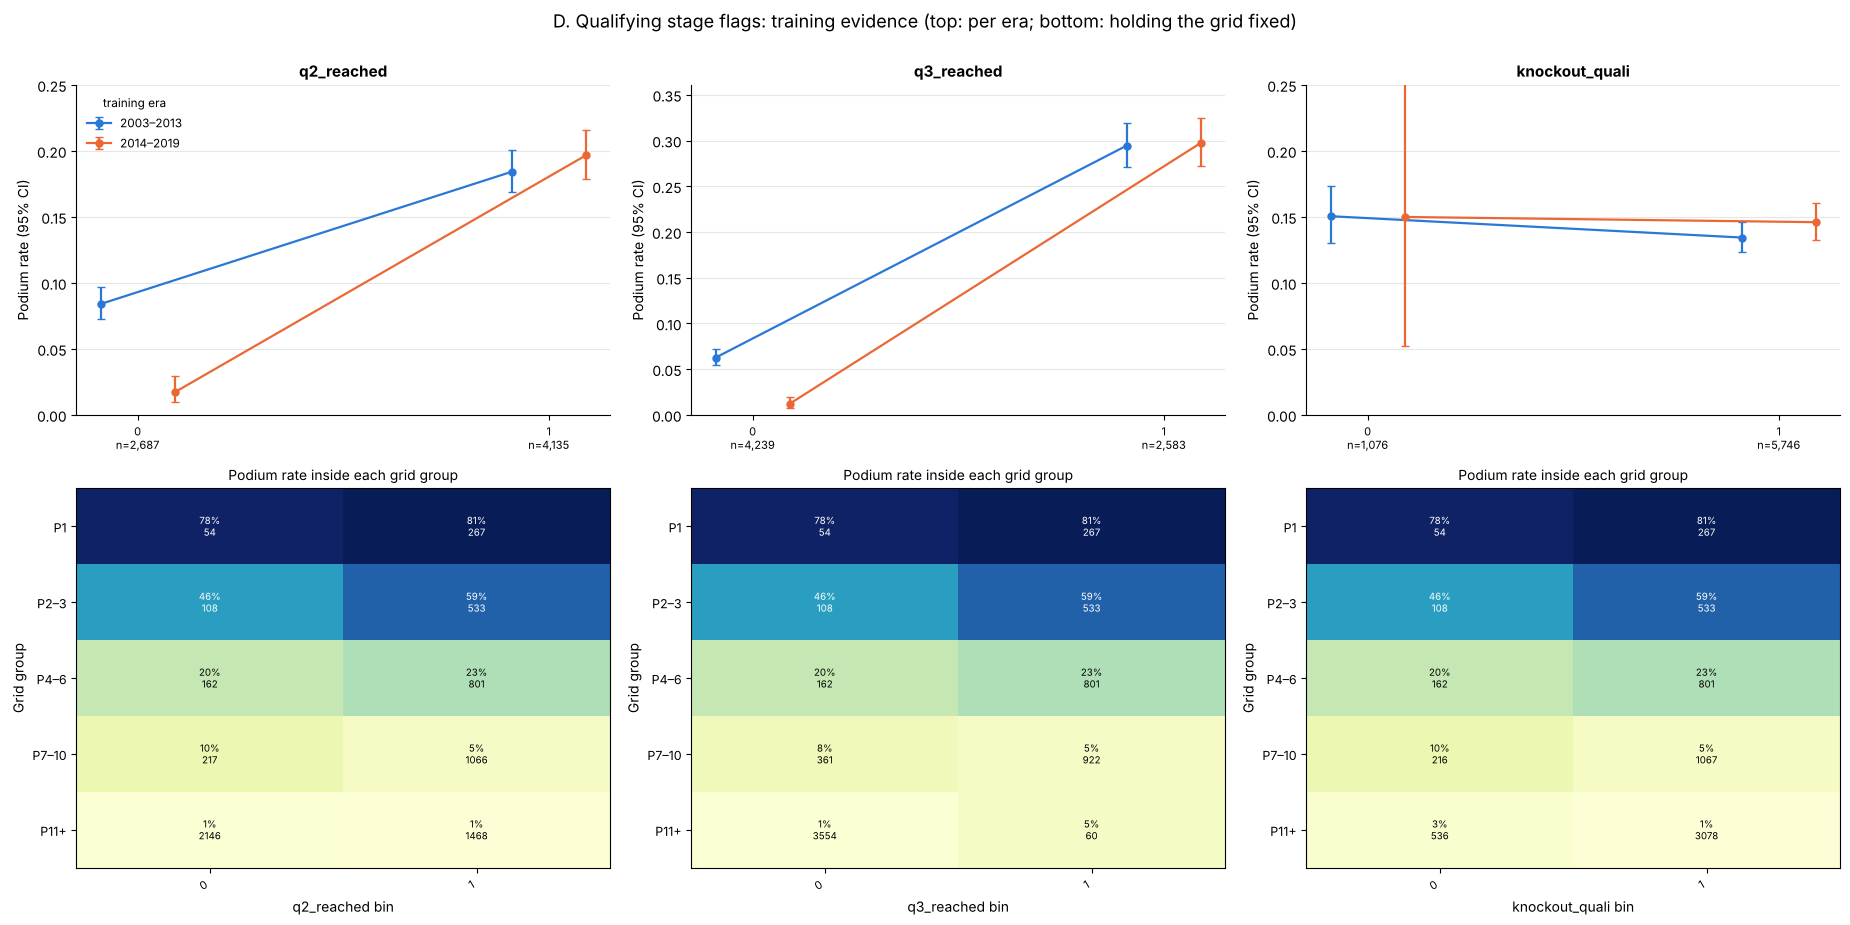

In [104]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("D. Qualifying stage flags", CANDIDATE_GROUPS["D. Qualifying stage flags"], "t3_evidence_d"))

**Result.**

- **Clear alone.** Reaching Q3 means 29% / 30% podiums vs 6% / 1%.
- **Much smaller inside each grid group.** Not reaching vs reaching Q3: 46% vs 59% among P2–3 starters, 20% vs 23%
  among P4–6. Most front-runners who "did not reach Q3" are 2003–05 rows, when Q3 did not exist. Reaching Q3 is
  almost the same information as "qualified in the top ten", which the grid already contains; its beyond-grid χ² is
  8.7, against 59 for qualifying pace.
- **`knockout_quali` alone is flat** (13–15% in both formats), as expected for a race-level flag.
- **Verdict:** not in the primary set; tested as an addition in 3.6.

### 3.4.5 E. Teammate comparison

**New candidate.** Teammates share the same car, so beating the teammate isolates the driver's level this weekend.

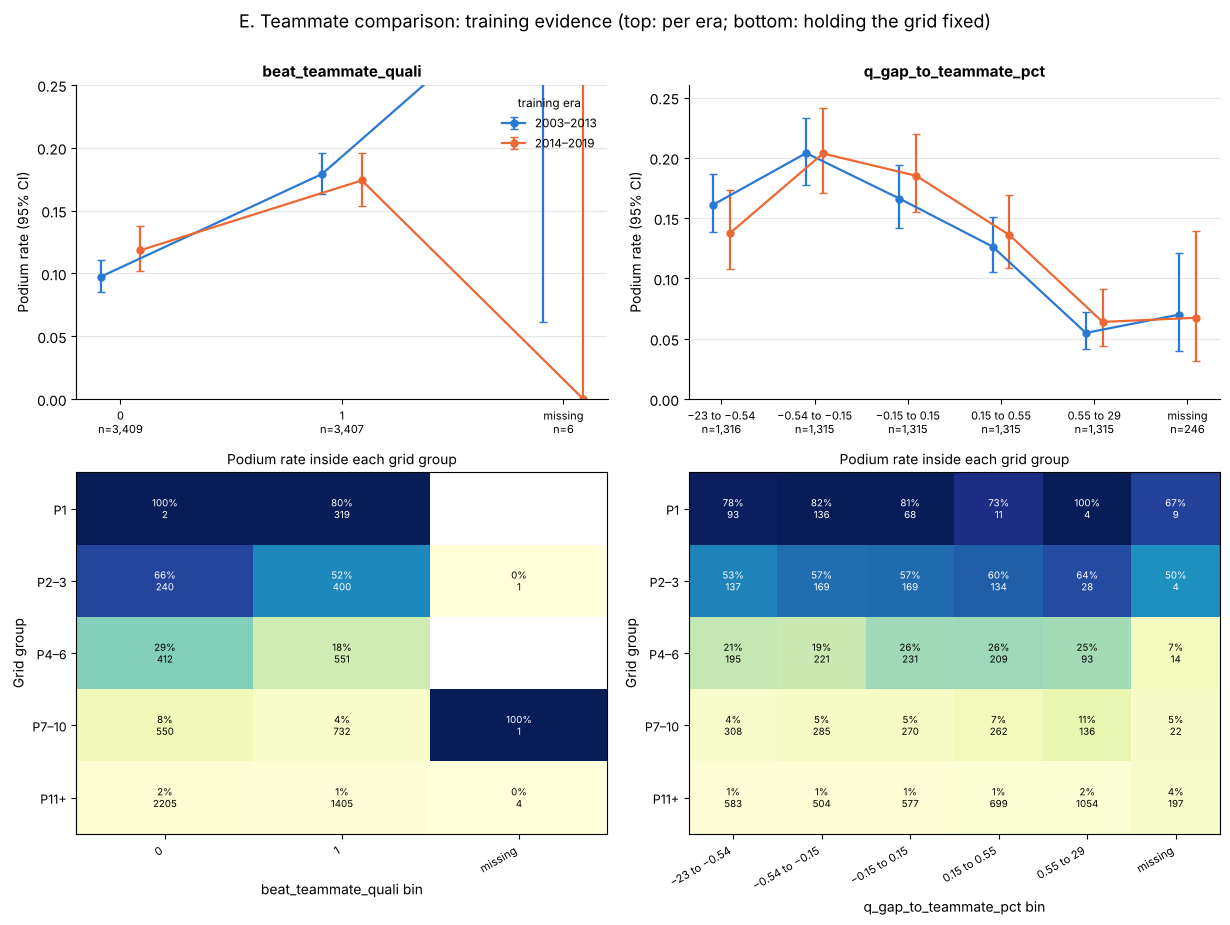

In [105]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("E. Teammate comparison", CANDIDATE_GROUPS["E. Teammate comparison"], "t3_evidence_e"))

**Result.**

- **Alone:** beating the teammate in qualifying goes with more podiums (18% / 17% vs 10% / 12%).
- **Inside a grid group the sign reverses.** Among P2–3 starters, those who did *not* beat their teammate podium 66%
  of the time vs 52%. A P2–3 starter who lost to the teammate means the teammate is even further ahead, so it is a
  front-row *team*. The feature therefore mostly measures team strength in disguise, which the standings and team-form
  features measure directly.
- **Verdict:** new candidate, tested in 3.6.

### 3.4.6 F. Season standings

**Hypothesis H3 (primary).** Championship points, rank and wins *before* the race show who has a fast car and driver this season (built in Task 1, 2.6.4, shifted to the previous round).

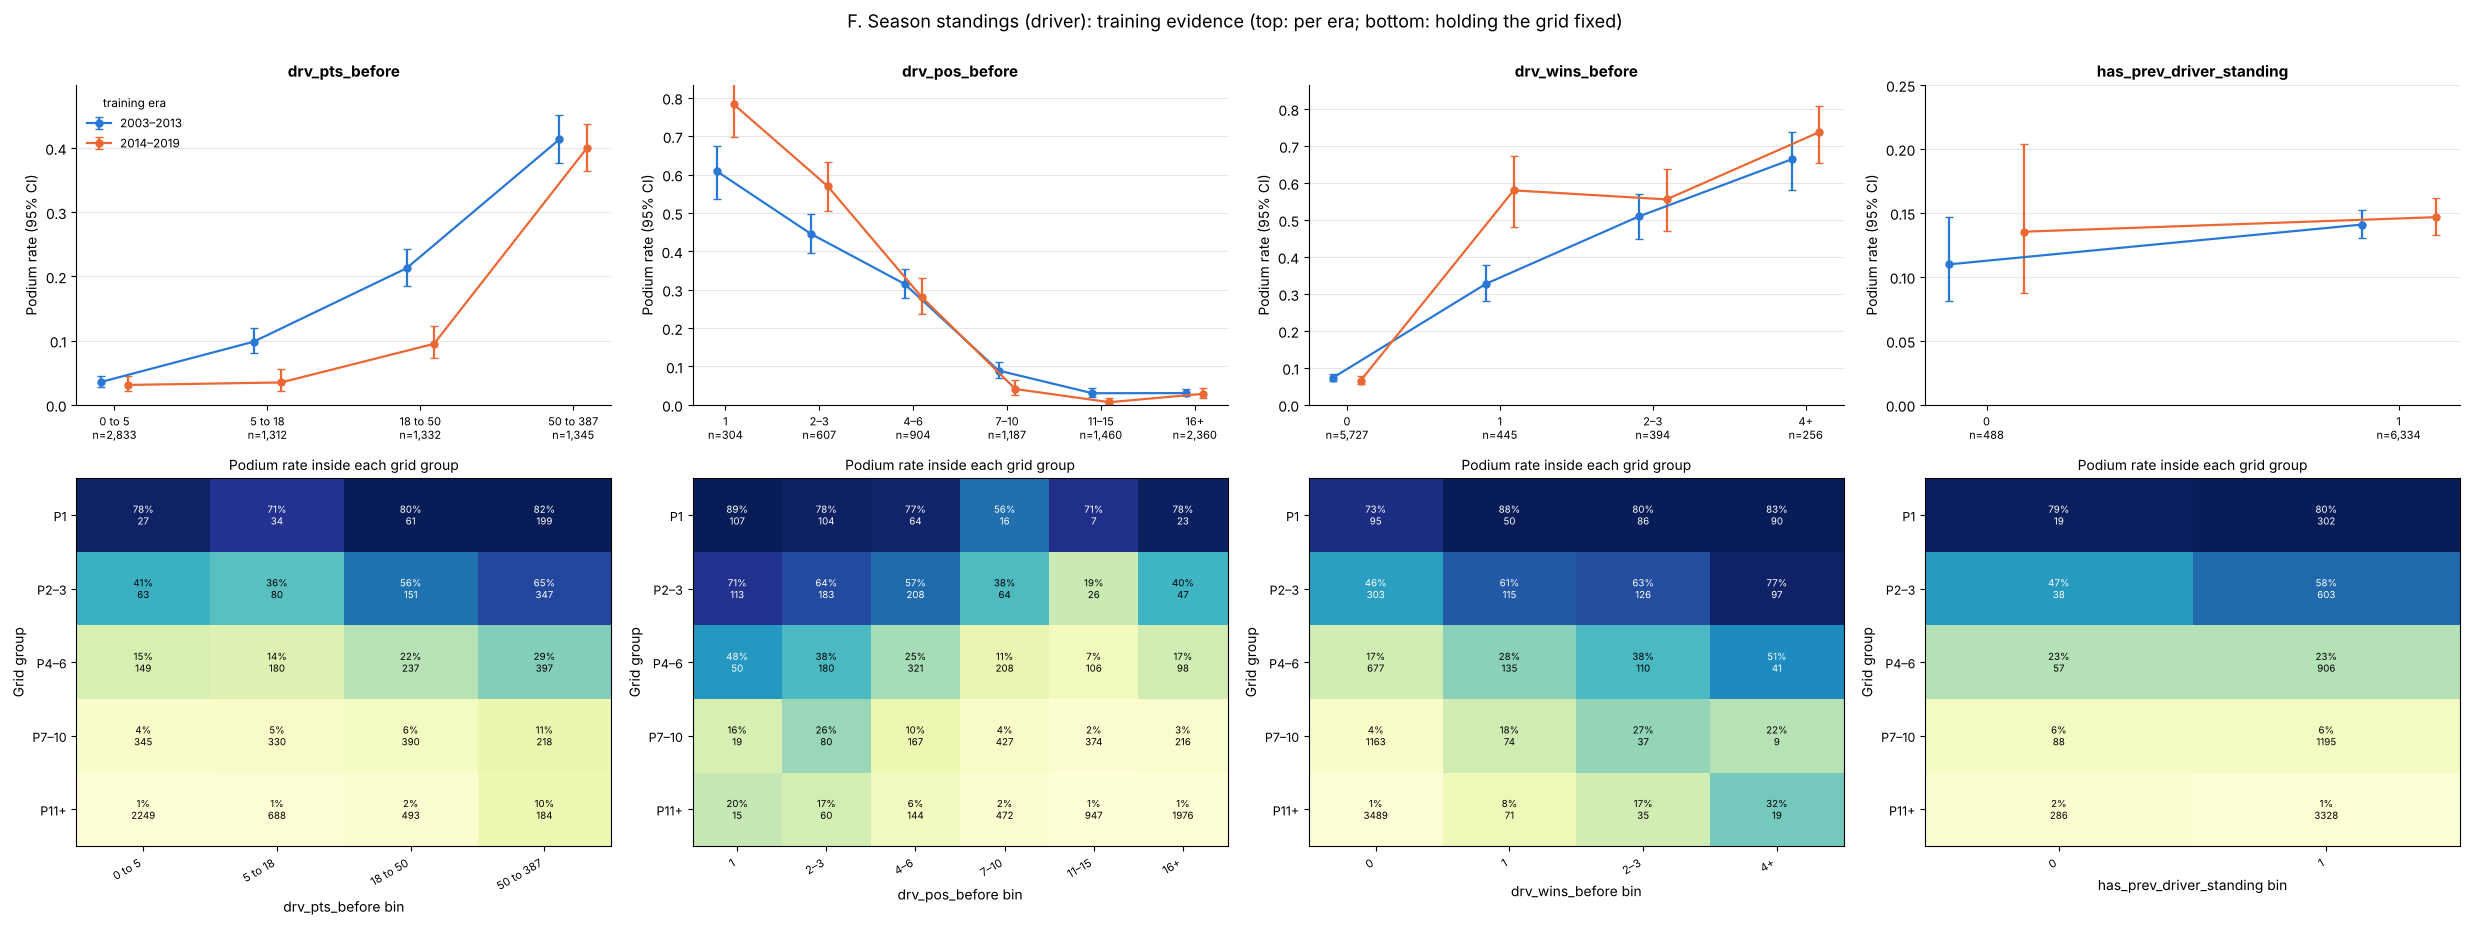

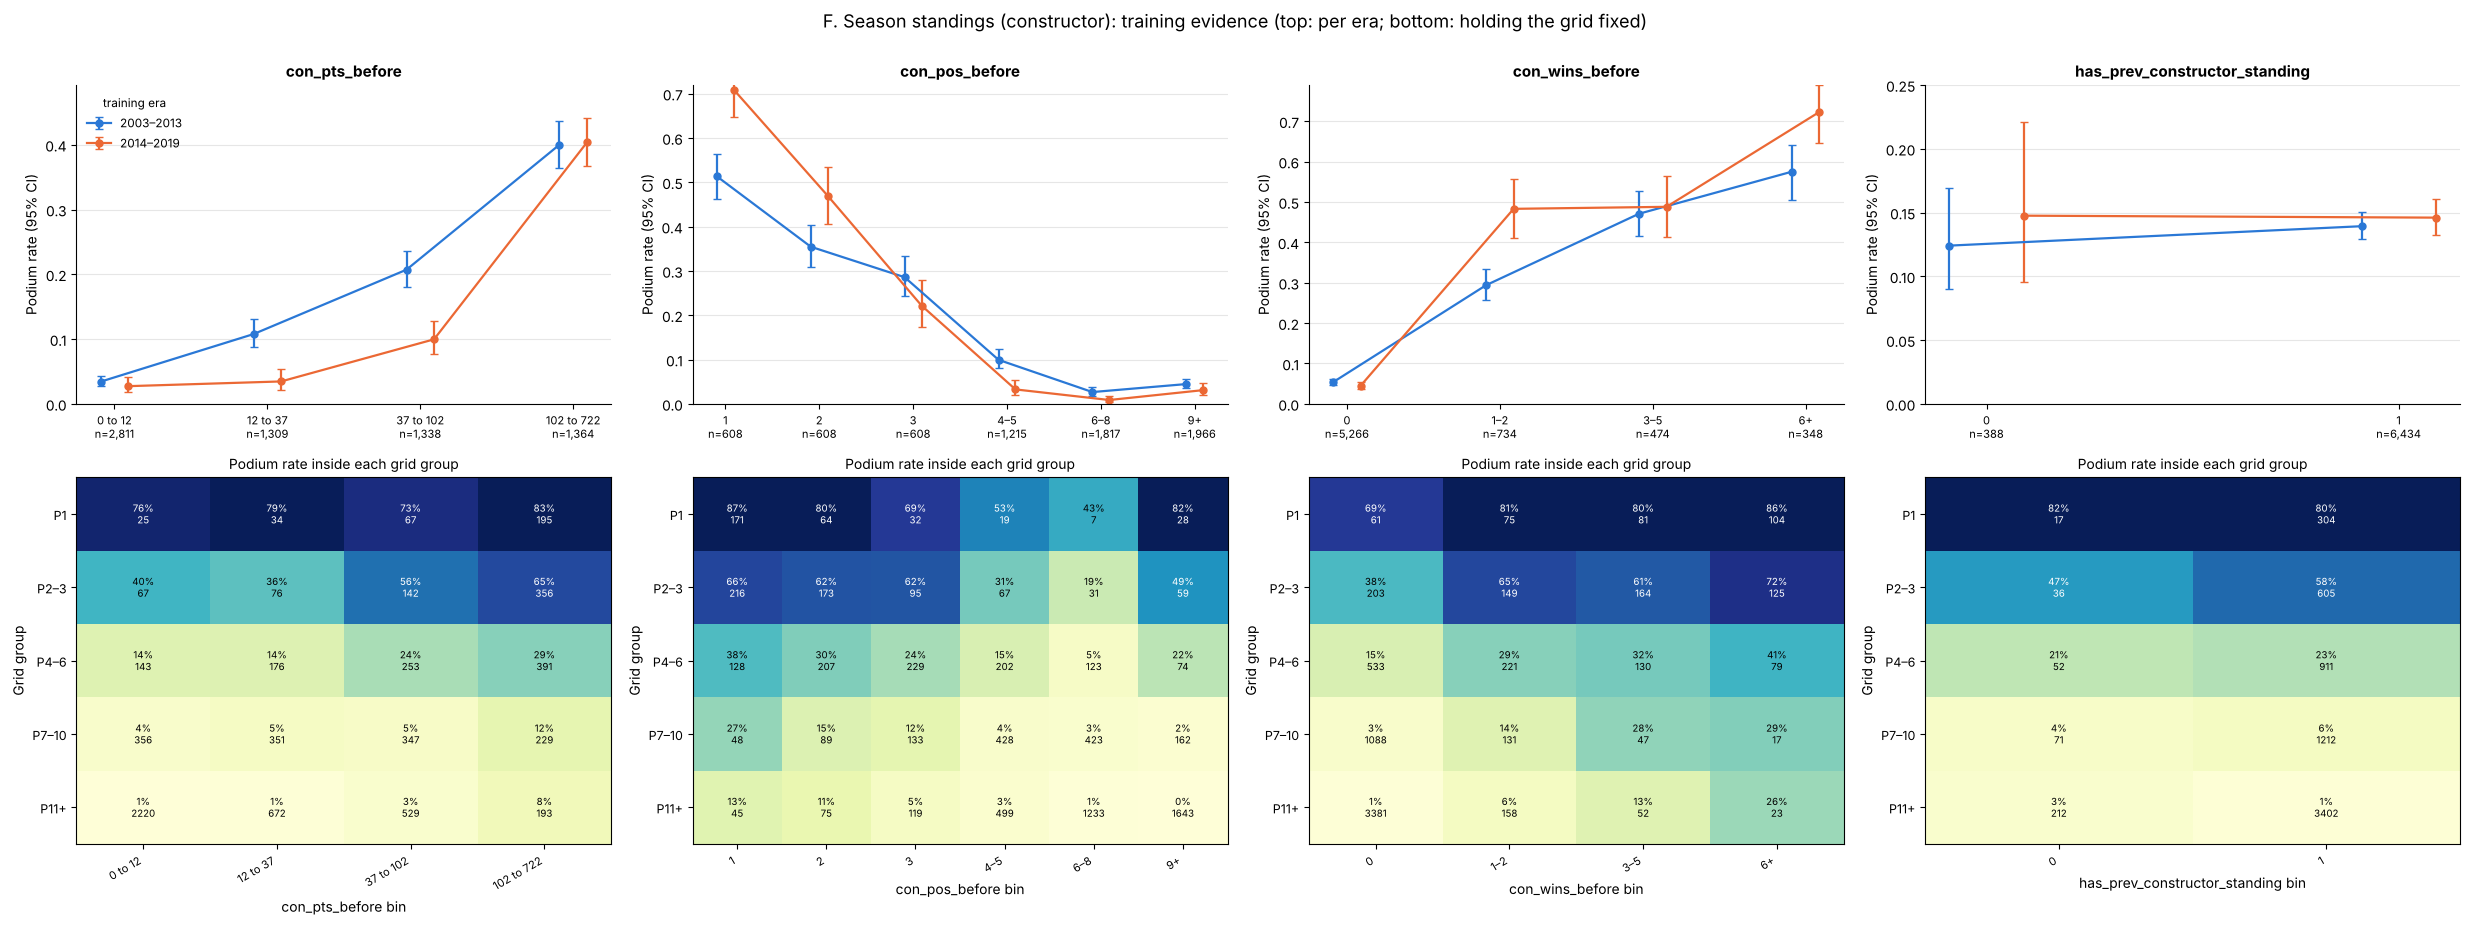

In [106]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("F. Season standings (driver)", ["drv_pts_before", "drv_pos_before", "drv_wins_before", "has_prev_driver_standing"], "t3_evidence_f_driver"))
evidence_tables.update(evidence_figure("F. Season standings (constructor)", ["con_pts_before", "con_pos_before", "con_wins_before", "has_prev_constructor_standing"], "t3_evidence_f_constructor"))

**Result.**

- **Wins show the clearest staircase.** Drivers with 0 wins so far podium 7% / 7% of the time; with 1 win 33% / 58%;
  with 4+ wins 66% / 74%. The constructor version is similar (5% → 58% / 72%).
- **Strongly beyond the grid.** Inside the P4–6 group, driver podium rate rises from 17% (0 wins) to 51% (4+ wins),
  and the same holds for points (15% → 29%). Beyond-grid χ²:
  - 104 for driver wins, 106 for constructor wins;
  - 91 for driver points;
  - 150 for driver rank, 45 for constructor rank.
- **Same direction in both eras** for every standings measure.
- **The availability flags are weak alone** (11% / 14% vs 14% / 15%). They are companions: they mark round 1, where
  points and wins are 0 because no race has been run, not because the driver is weak.
- **Screening (3.5) keeps one of each near-duplicate pair** (rank vs points, driver vs constructor points).
- **Verdict:** H3 confirmed.

### 3.4.7 G. Standings share

**New candidate.** Points as a share of the leader's points. Raw points are not comparable across the 2010 points-system change (10 points for a win before, 25 after); a share is.

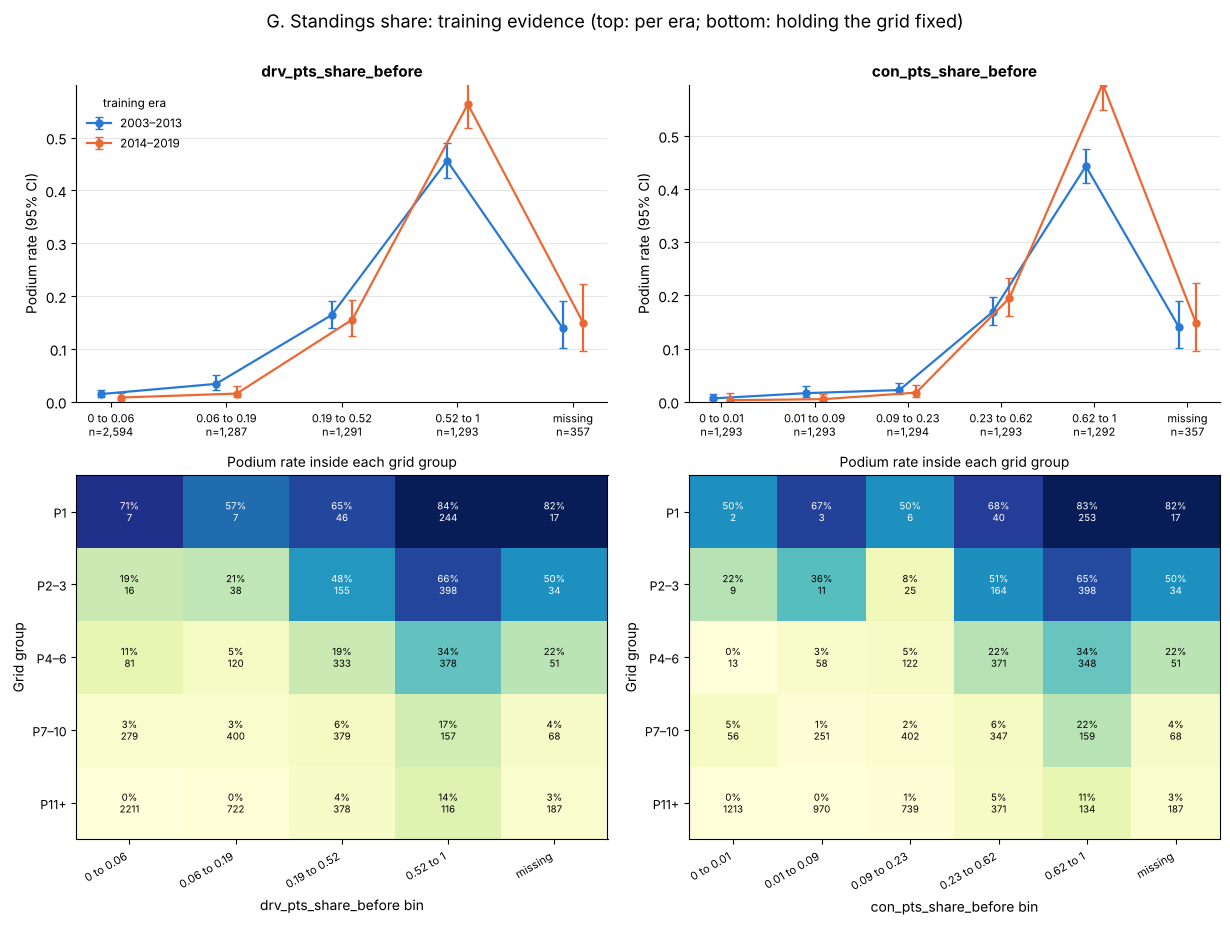

In [107]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("G. Standings share", ["drv_pts_share_before", "con_pts_share_before"], "t3_evidence_g"))

**Result.**

- **Among the strongest single features.** Single-feature ROC-AUC 0.89; beyond-grid χ² of about 250, the largest of
  all candidates. A team on 62–100% of the leader's points podiums 44% / 60% of the time, against below 2.5% under
  23%.
- **Overlaps heavily with standings and form.** ρ ≈ 0.8–0.9 with points, rank and recent podium rate (redundancy
  heatmap, 3.5), so its value *on top of* H3 and H4 has to be tested.
- **Verdict:** new candidate, tested in 3.6.

### 3.4.8 H. Driver recent form

**Hypothesis H4 (primary).** A driver's last five starts capture current form and current car pace. This is also the leakage-safe form feature the checklist requires (built only from earlier races, 3.3.2).

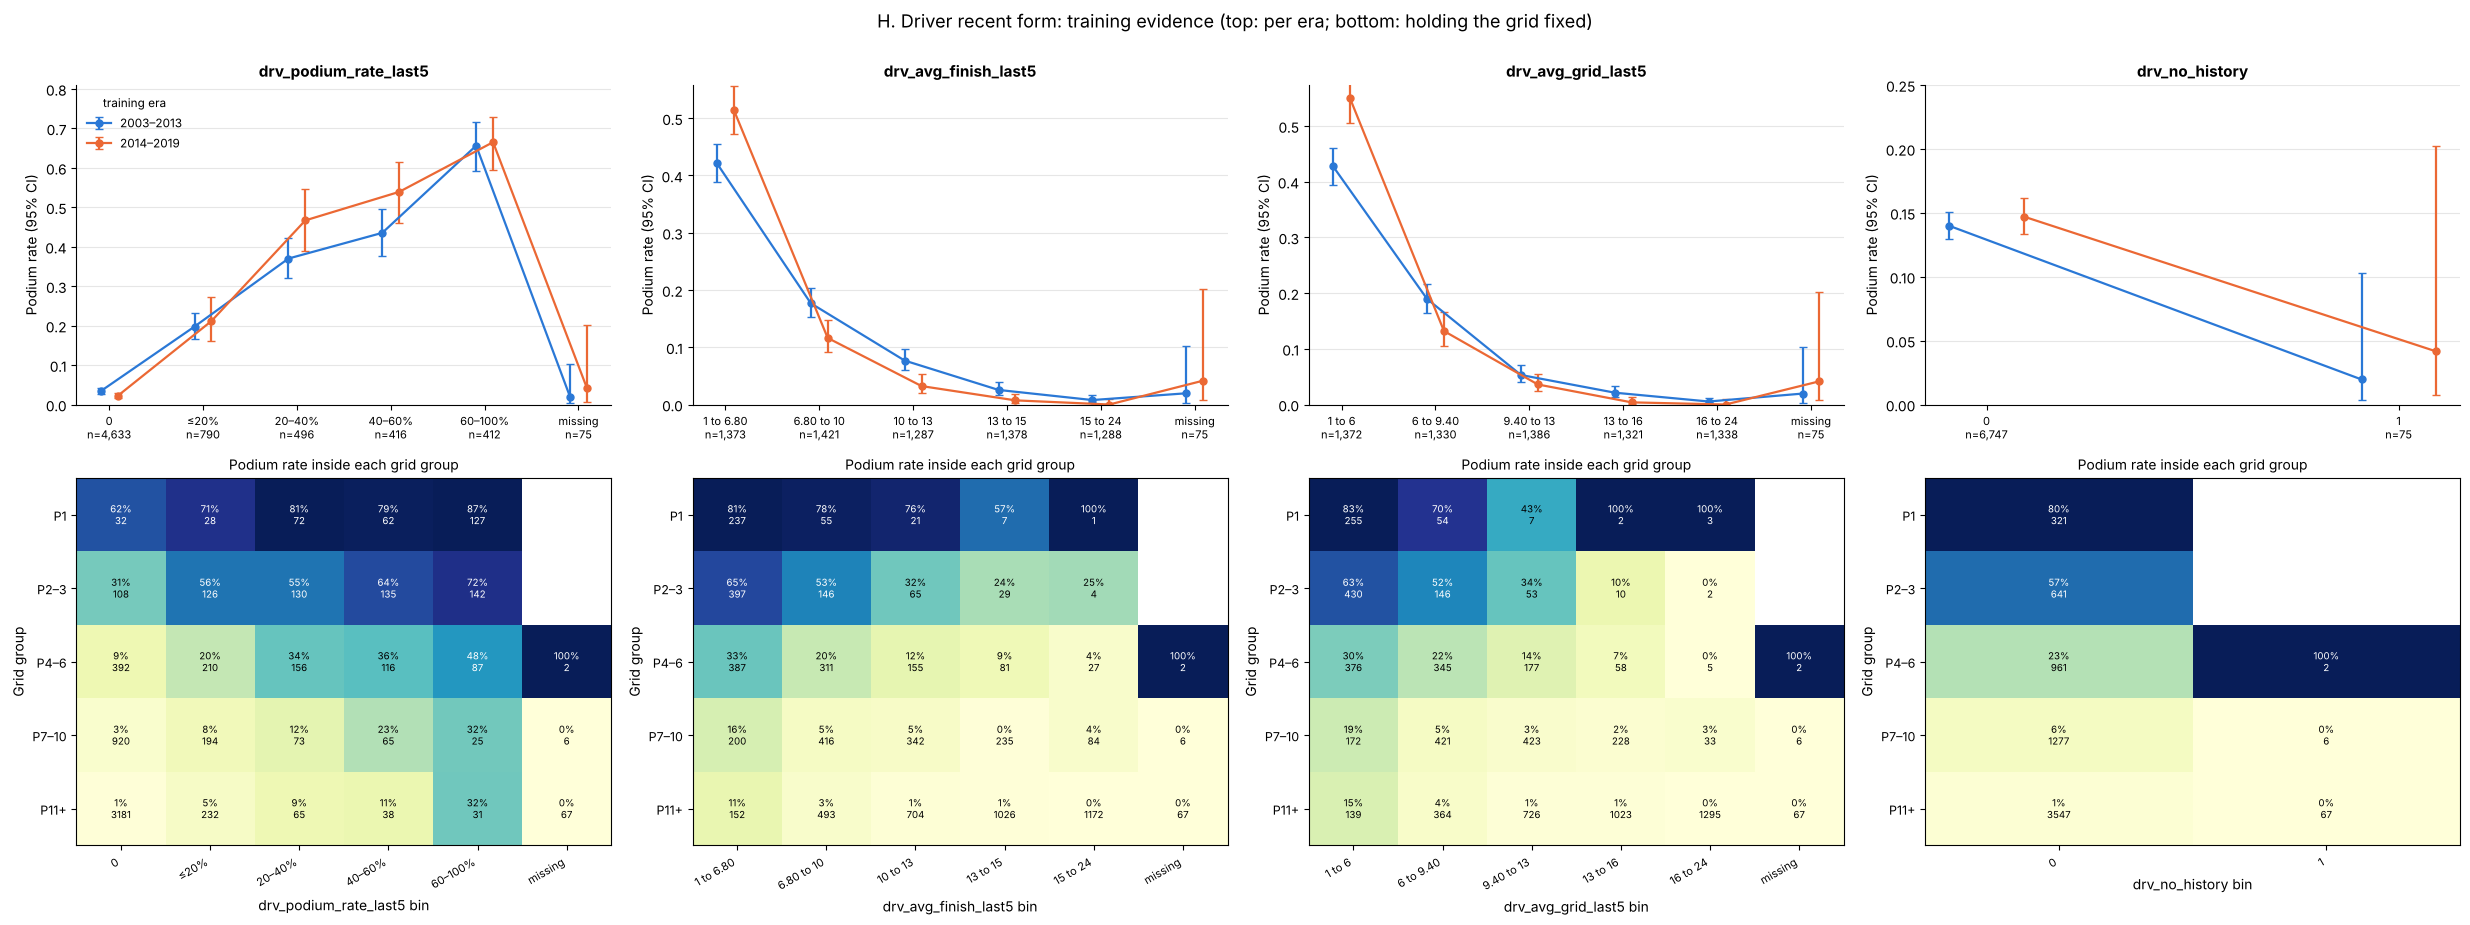

In [108]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("H. Driver recent form", CANDIDATE_GROUPS["H. Driver recent form"], "t3_evidence_h"))

**Result.**

- **Podium rate over the last 5 starts:**
  - 0 → 3% / 2%;
  - up to 20% → 20% / 21%;
  - 20–40% → 37% / 47%;
  - 40–60% → 44% / 54%;
  - 60–100% → 66% / 67%.

  The steps are the same in both eras (ρ = +0.48 / +0.60, AUC 0.86).
- **Holds inside every grid group.** Among P4–6 starters the rate climbs from 9% (no recent podium) to 48% (60–100%);
  among P11+ starters from 1% to 32%. Beyond-grid χ² = 233.
- **Average finish over the last 5 starts** shows the same pattern (42% / 51% for an average of 1–6.8, below 1% for
  15+; χ² = 214).
- **`drv_no_history`** (75 rows of a driver's first start, 2% / 4% podiums) is the companion that marks why the two
  rates are missing.
- **Verdict:** H4 confirmed for drivers.

### 3.4.9 I. Constructor recent form

**Hypothesis H4 (primary).** The car decides most podiums, so the team's last five races (both cars combined, 3.3.2) should predict well.

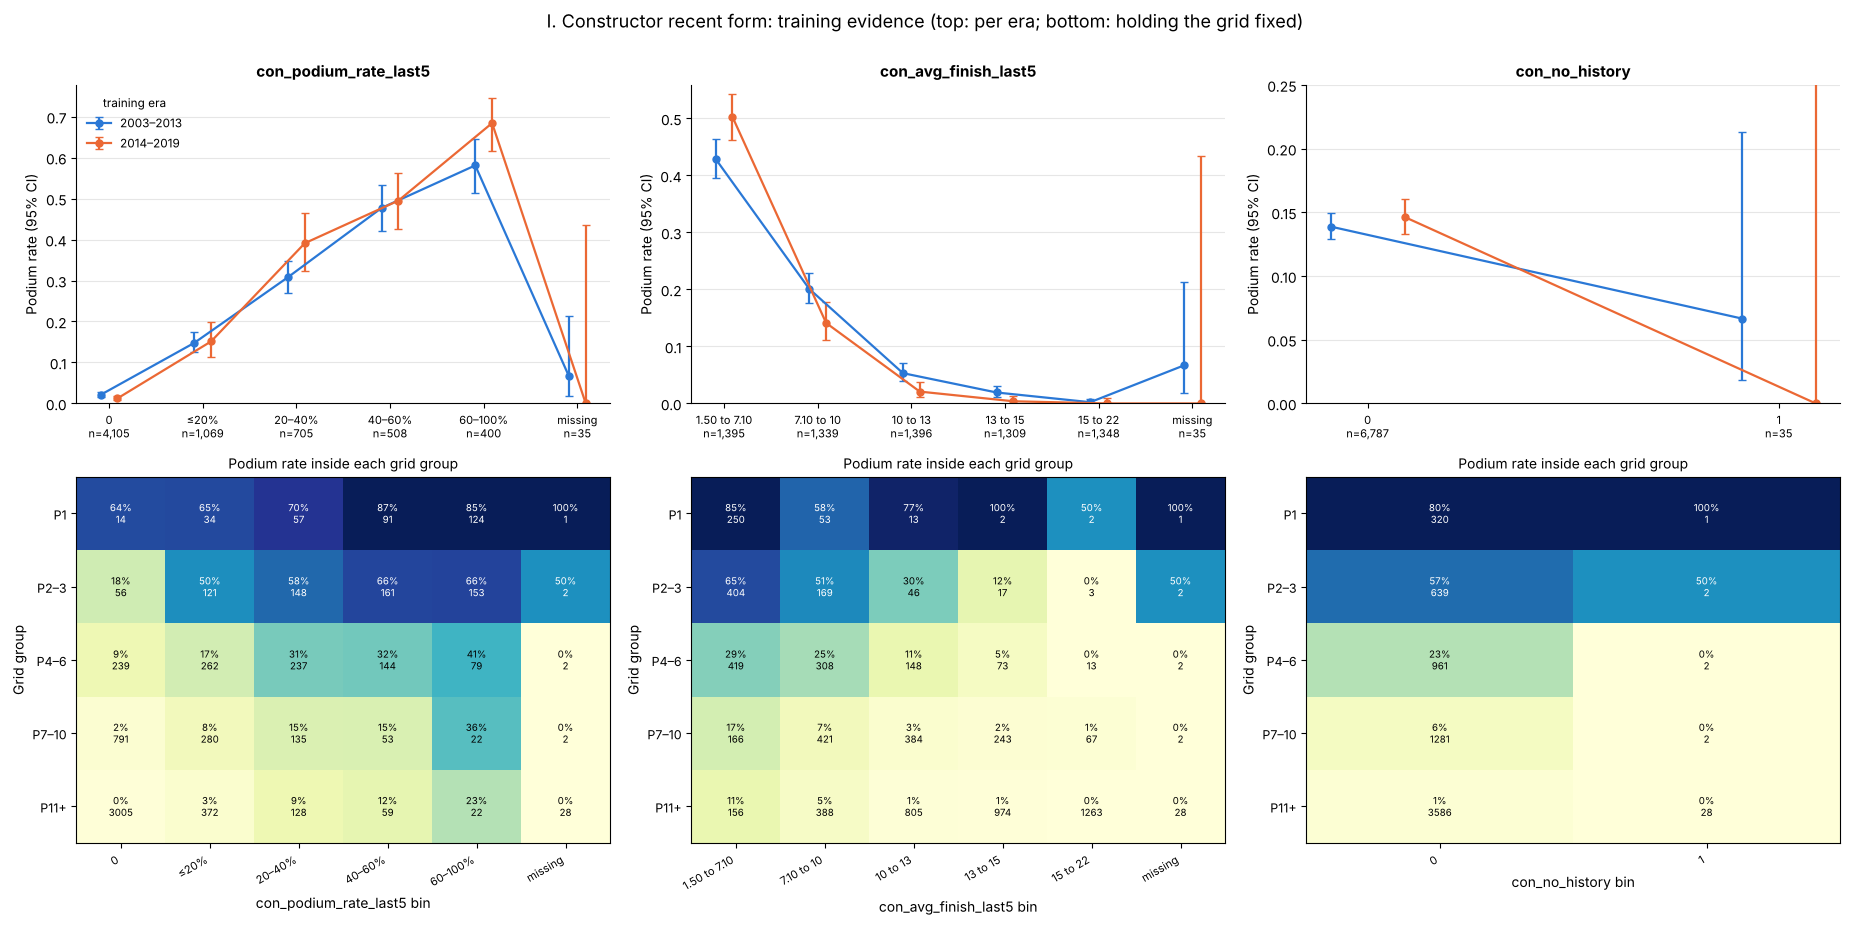

In [109]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("I. Constructor recent form", CANDIDATE_GROUPS["I. Constructor recent form"], "t3_evidence_i"))

**Result.**

- **Team podiums per start over its last 5 races:** 2% / 1% at zero, rising to 58% / 68% at 60–100% (AUC 0.88).
- **Average team finish:** 43% / 50% for the best fifth, ≤ 0.2% for the worst.
- **Beyond the grid.** Among P2–3 starters, 18% podium in a team with no recent podium vs 66% in a team at 40%+;
  among P7–10 starters, 2% vs 36%. χ² = 197 (podium rate) and 225 (average finish).
- **`con_no_history`** marks a team's first race under a new `constructorId` (35 rows).
- **Verdict:** H4 confirmed for teams.

### 3.4.10 J. Reliability

**Hypothesis H5 (primary).** A car that keeps breaking down cannot finish on the podium. Task 2 Q3 showed large differences in mechanical-retirement rates between teams.

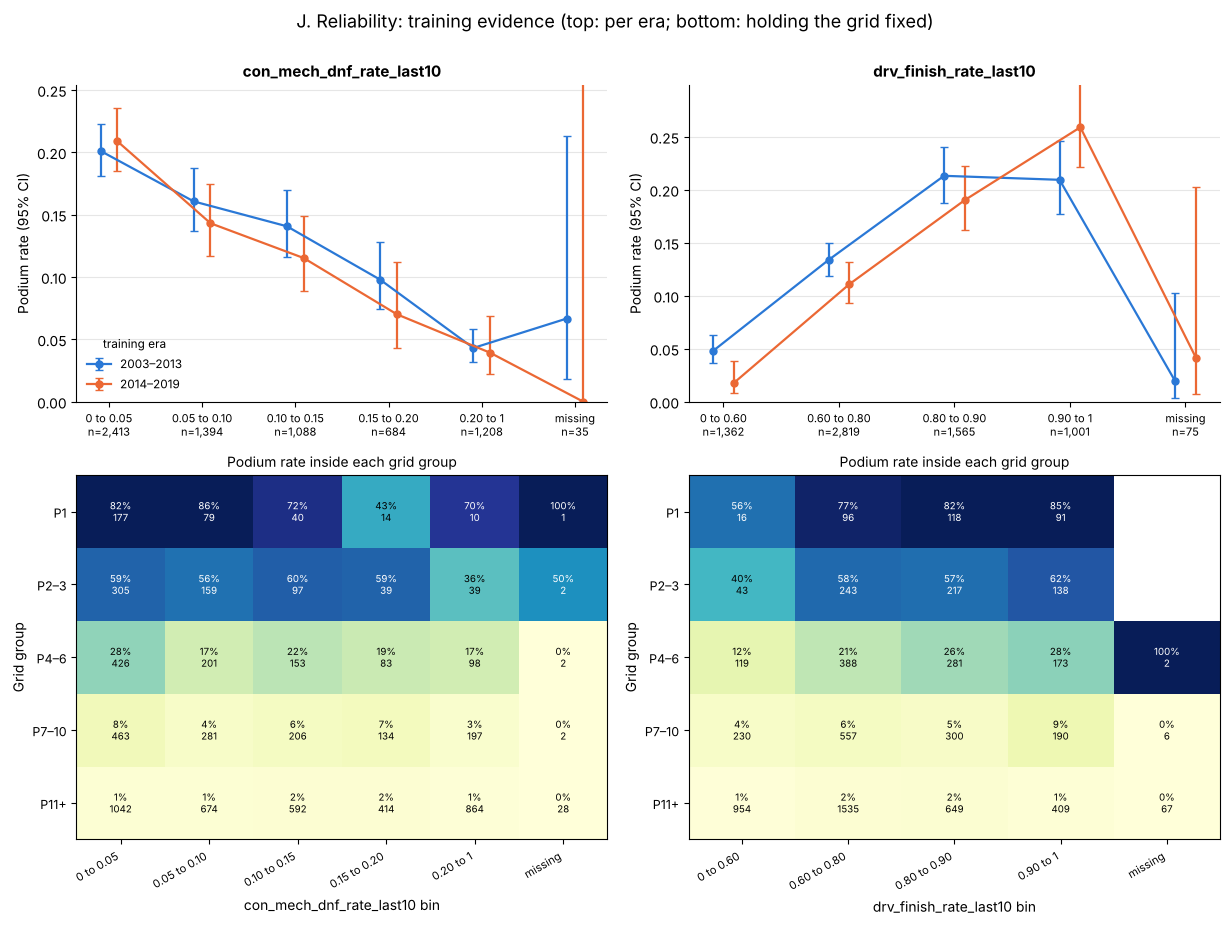

In [110]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("J. Reliability", CANDIDATE_GROUPS["J. Reliability"], "t3_evidence_j"))

**Result.**

- **A clear downward staircase, the same in both eras.** Podium rate falls from 20% / 21% for teams with ≤ 5%
  mechanical retirements in their last 10 races, to 4% / 4% above 20%.
- **The driver's finish rate over the last 10 starts** rises from 5% / 2% (finished under 60%) to 21% / 26% (90%+).
- **Smaller beyond the grid than the form features, but real.** Mechanical rate χ² = 26, driver finish rate χ² = 34
  (both p < 0.001). Among P1 starters, the podium rate drops from 82% to 70% for the least reliable teams.
- **Verdict:** H5 confirmed. The trials in 3.6 test whether it still adds something next to form and standings.

### 3.4.11 K. Experience

**New candidate.** Long-run quality and experience: career starts and podiums (driver and team) and age.

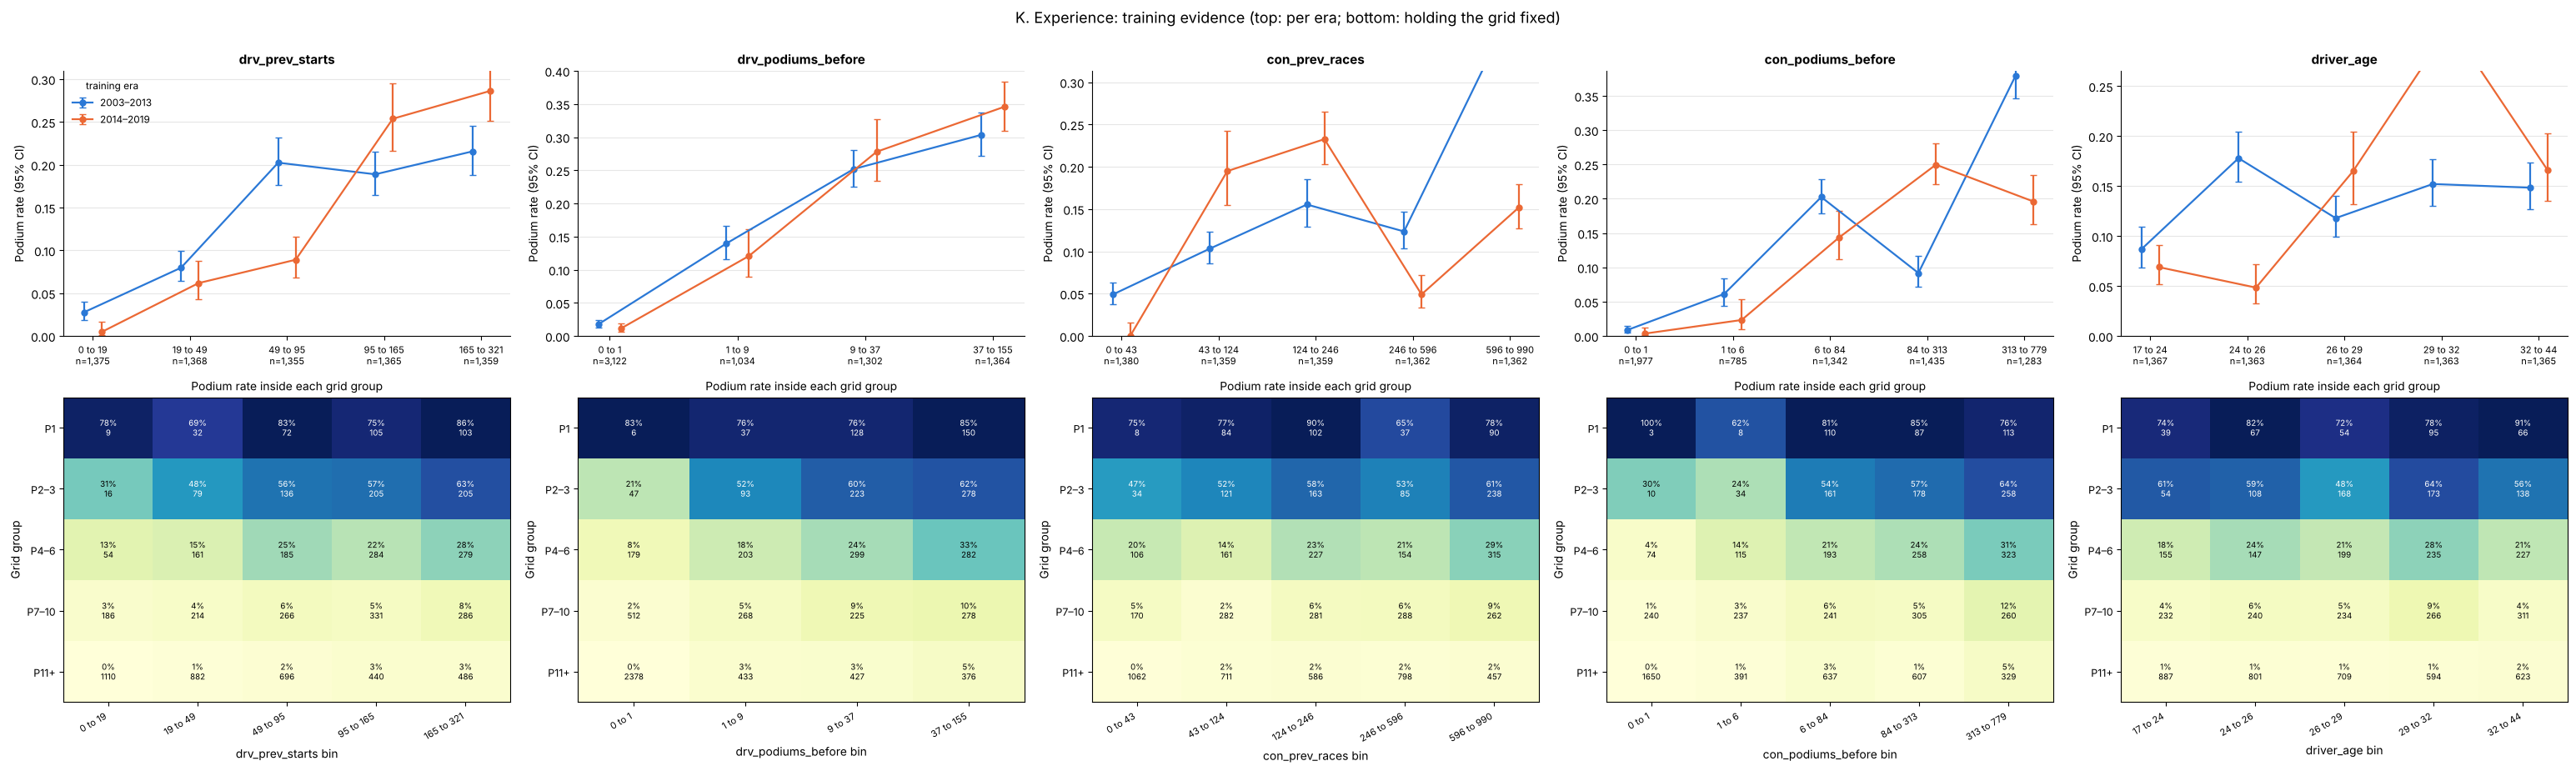

In [111]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("K. Experience", CANDIDATE_GROUPS["K. Experience"], "t3_evidence_k"))

**Result.**

- **Strong alone.** Career podiums: AUC 0.80. Team career podiums: AUC 0.76. Experienced drivers podium more:
  0–19 starts → 3% / 1%; 165+ starts → 22% / 29%.
- **Not stable across eras.** Team career races change direction between the eras (ρ = +0.24 in 2003–13 vs +0.01 in
  2014–19), and age is flat in 2003–13 (ρ = +0.03) but not in 2014–19 (+0.18).
- **Why:** these counts grow over time and mostly repeat "good teams stay good", which recent form and standings
  measure more directly.
- **Verdict:** new candidate, tested in 3.6.

### 3.4.12 L. Circuit history

**New candidate.** Some drivers suit some tracks; earlier results at the same circuit might add to general form.

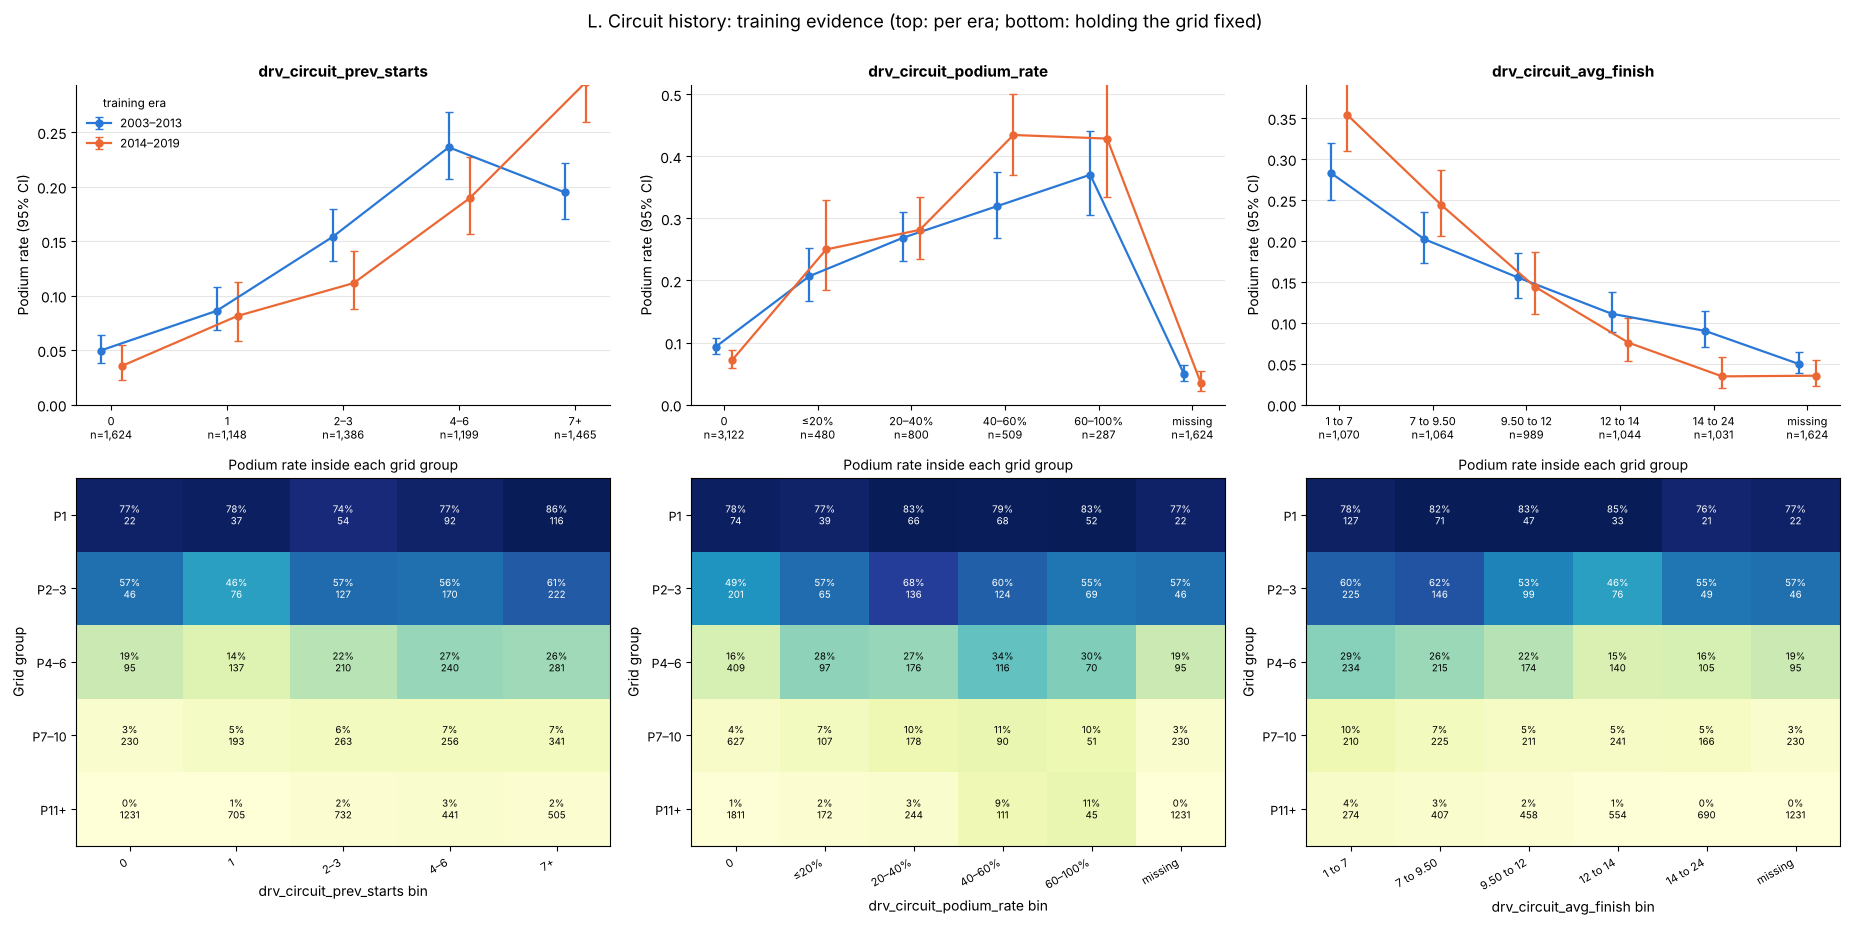

In [112]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("L. Circuit history", CANDIDATE_GROUPS["L. Circuit history"], "t3_evidence_l"))

**Result.**

- **Alone it works.** A podium rate of 40%+ at this circuit before → 32–43% now, against 9% / 7% with no earlier
  podium there.
- **But 24% of training rows have no earlier visit** (missing).
- **It overlaps with general career success** (ρ = 0.73 with career podiums).
- **Inside grid groups the gain is modest and uneven.**
- **Verdict:** new candidate, tested in 3.6.

### 3.4.13 M. Race context

**New candidate.** Season progress (`round`) and the number of cars competing for three places (`field_size`).

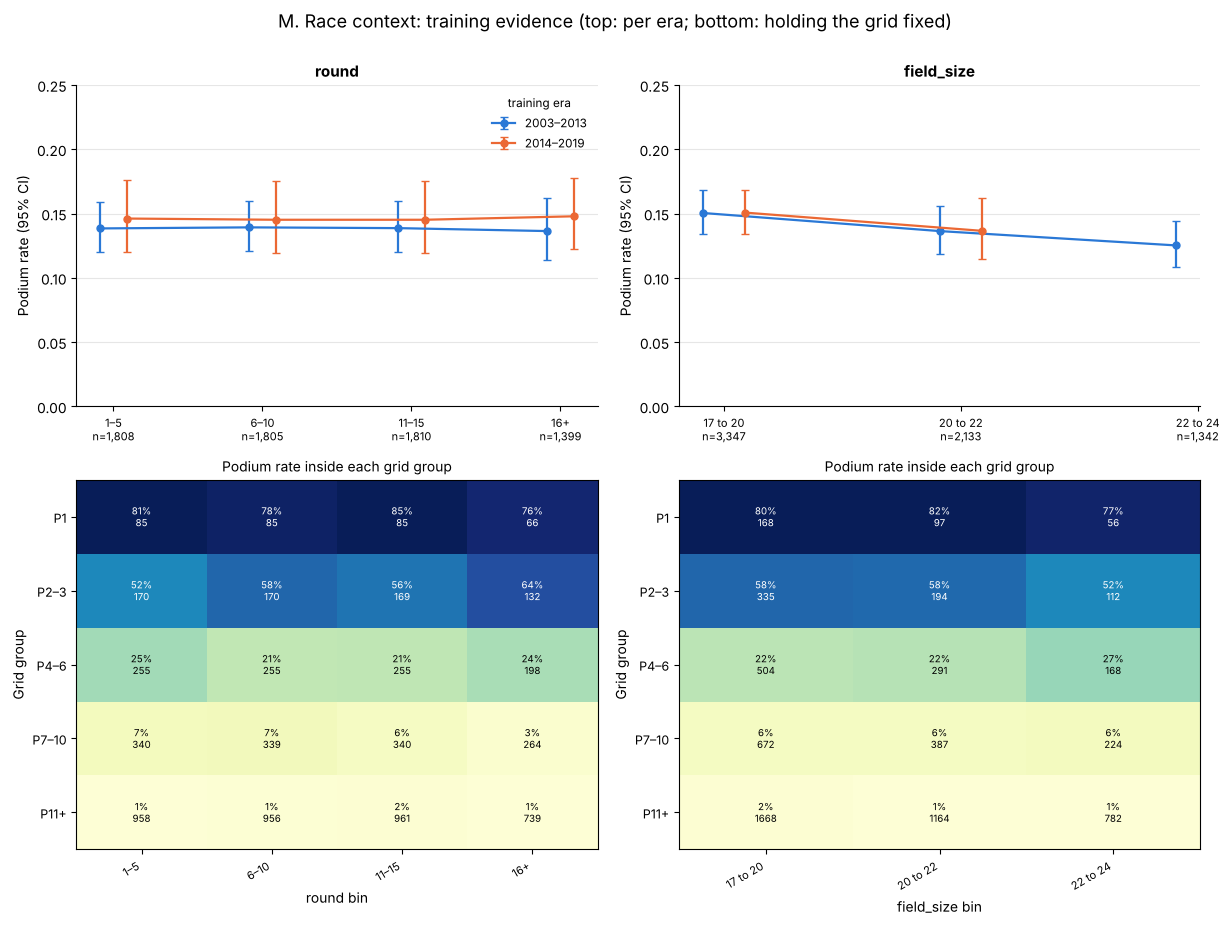

In [113]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("M. Race context", CANDIDATE_GROUPS["M. Race context"], "t3_evidence_m"))

**Result.**

- **`round` is flat by construction.** The podium rate is 14–15% in every phase of the season, because every race
  awards exactly 3 podiums (ρ = 0.00, beyond-grid χ² = 0.0006, p = 0.98).
- **`field_size` behaves as arithmetic predicts.** 3 places shared by more cars: 15% with 17–20 cars, 12.5% with
  22–24. It adds nothing beyond the grid (χ² = 0.05, p = 0.82).
- **Verdict:** new candidate, tested in 3.6.

### 3.4.14 N. Circuit identity

**New candidate (left out by hypothesis in 3.1).** Some tracks may make the starting order stick (Task 2 Q1).

Podium rate per circuit (training): min 0.128 max 0.150 -> flat by construction (3 podiums per race)
Do grid P1-3 starters convert differently by circuit? chi-square = 16.7, dof = 21, p = 0.731


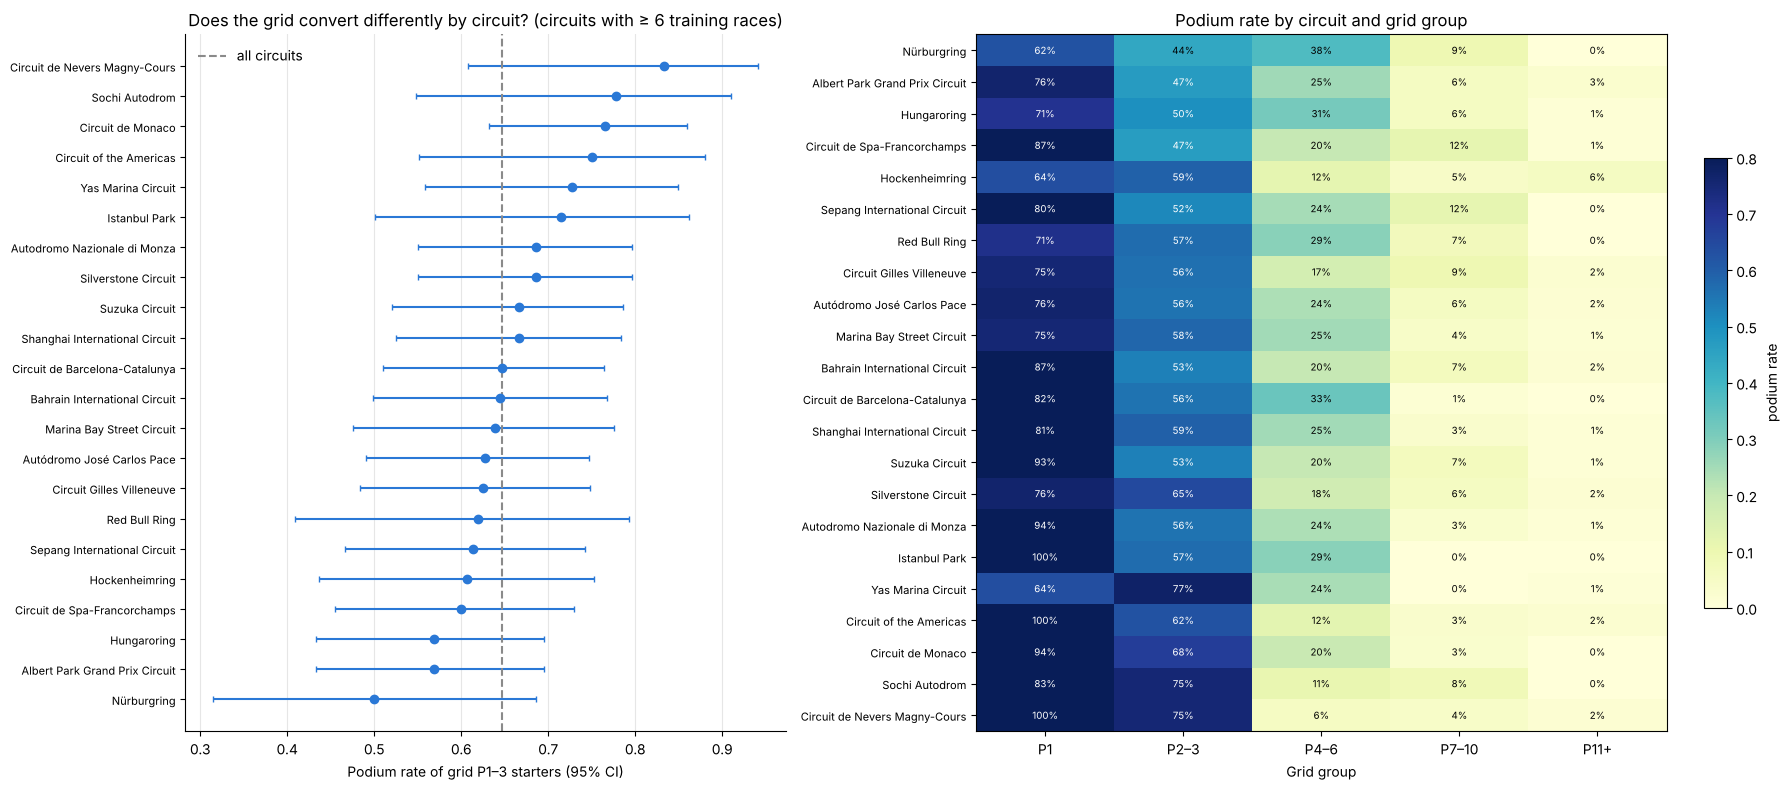

In [114]:
# Circuit identity: every race awards exactly 3 podiums, so the podium rate per circuit is flat BY CONSTRUCTION.
# The only way a circuit can help is by changing HOW MUCH the grid matters there, so that is what we measure.
evidence_tables = globals().get("evidence_tables", {})
circ_names = clean_tables["circuits"].set_index("circuitId")["name"]
ct = TRAIN.assign(circuit=TRAIN["circuitId"].map(circ_names))
by_circuit = ct.groupby("circuit").agg(rows=("podium", "size"), races=("raceId", "nunique"), podium_rate=("podium", "mean"))
front = ct[ct["grid_model"] <= 3].groupby("circuit")["podium"].agg(n="size", podiums="sum")
front["rate"] = front["podiums"] / front["n"]; front["lo"], front["hi"] = wilson(front["podiums"], front["n"])
front = front[by_circuit.loc[front.index, "races"] >= 6].sort_values("rate")
print("Podium rate per circuit (training): min", f"{by_circuit['podium_rate'].min():.3f}", "max",
      f"{by_circuit['podium_rate'].max():.3f}", "-> flat by construction (3 podiums per race)")

from scipy.stats import chi2_contingency
chi2, p_circ, dof, _ = chi2_contingency(np.c_[front["podiums"], front["n"] - front["podiums"]])
print(f"Do grid P1-3 starters convert differently by circuit? chi-square = {chi2:.1f}, dof = {dof}, p = {p_circ:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.25]})
y = np.arange(len(front))
axes[0].errorbar(front["rate"], y, xerr=[(front["rate"] - front["lo"]).clip(lower=0), (front["hi"] - front["rate"]).clip(lower=0)], fmt="o", color=BLUE, capsize=2)
axes[0].axvline(ct.loc[ct["grid_model"] <= 3, "podium"].mean(), color=GREY, linestyle="--", label="all circuits")
axes[0].set_yticks(y, front.index, fontsize=8); axes[0].set_xlabel("Podium rate of grid P1–3 starters (95% CI)")
axes[0].set_title("Does the grid convert differently by circuit? (circuits with ≥ 6 training races)")
axes[0].legend(frameon=False); style_axis(axes[0], "x")
piv = ct[ct["circuit"].isin(front.index)].pivot_table(index="circuit", columns="grid_group", values="podium", aggfunc="mean", observed=True).reindex(front.index)
im = axes[1].imshow(piv.to_numpy(float), cmap="YlGnBu", vmin=0, vmax=0.8, aspect="auto")
axes[1].set_yticks(range(len(piv)), piv.index, fontsize=8); axes[1].set_xticks(range(piv.shape[1]), piv.columns)
for i in range(piv.shape[0]):
    for k in range(piv.shape[1]):
        v = piv.iat[i, k]
        if pd.notna(v):
            axes[1].text(k, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.45 else "black")
axes[1].set_title("Podium rate by circuit and grid group"); axes[1].set_xlabel("Grid group")
fig.colorbar(im, ax=axes[1], fraction=0.03, label="podium rate")
t3_show("t3_evidence_n")

**Result.**

- **The podium rate per circuit is flat by construction** (12.8–15.0%).
- **The only way a circuit could matter** is by changing how strongly the grid converts there. The left panel tests
  exactly that for grid P1–3 starters: the circuits' intervals overlap heavily, and a χ² test finds no difference
  between circuits (χ² = 16.7, 21 degrees of freedom, p = 0.73).
- **Consistent with Task 2 Q1**, where circuit differences were mostly within noise.
- **Verdict:** hypothesis of 3.1 (leave out) supported; still offered as an addition in 3.6.

### 3.4.15 O. Home race

**Left out by hypothesis.** Task 2 Q2 found no home advantage once starting position is held fixed.

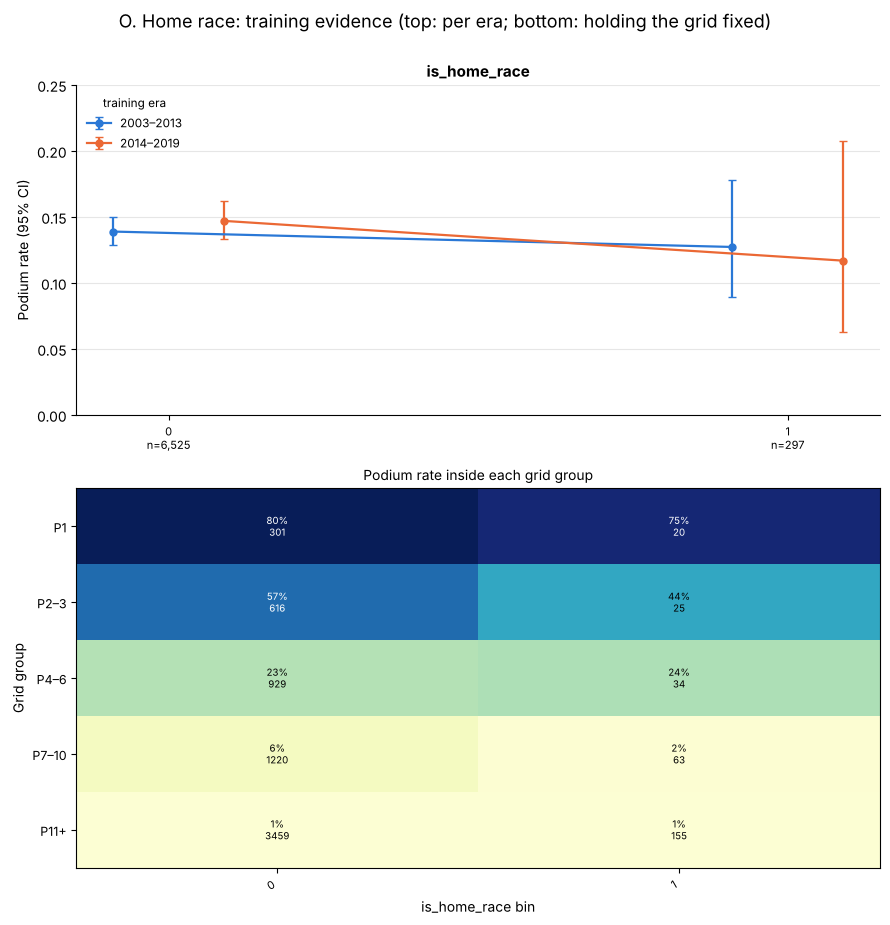

In [115]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("O. Home race", CANDIDATE_GROUPS["O. Home race"], "t3_evidence_o"))

**Result.**

- **The training seasons agree with Task 2 Q2.** Home rows podium 13% / 12% of the time vs 14% / 15% away, and the
  heatmap shows no home advantage inside the grid groups (e.g. P4–6: 24% home vs 23% away).
- **Beyond-grid χ² = 3.5, p = 0.06.** That is not significant, and the direction is slightly negative.
- **Verdict:** left out, as hypothesised.

### 3.4.16 P. Sprint weekend

**Left out by hypothesis.** Sprint weekends only exist from 2021 (Task 1, 2.6.1).

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1811: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1811: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


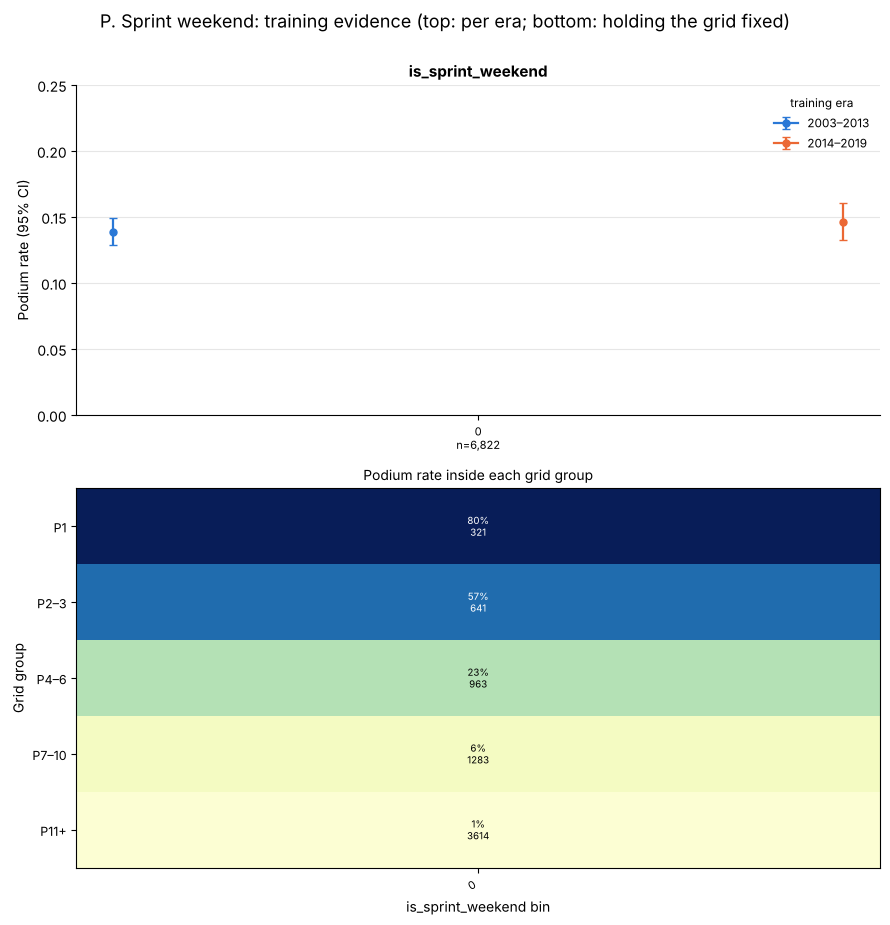

In [116]:
evidence_tables = globals().get("evidence_tables", {})
evidence_tables.update(evidence_figure("P. Sprint weekend", CANDIDATE_GROUPS["P. Sprint weekend"], "t3_evidence_p"))

**Result.**

- **Every training row has `is_sprint_weekend = 0`**, so a model trained on 2003–2019 cannot learn anything from it,
  however relevant it may be in 2021+.
- **Verdict:** removed by Rule 1 in 3.5 (constant in training).

### 3.4.17 All the evidence in numbers

One row per candidate (training seasons only):

| Column | Meaning |
|---|---|
| `missing_%` | share of training rows without a value |
| `rho_all`, `rho_2003_13`, `rho_2014_19` | Spearman correlation with podium, overall and per era (same sign in both eras = stable direction) |
| `auc_alone` | ROC-AUC when the feature alone ranks drivers (0.5 = useless, further from 0.5 = stronger; below 0.5 means "smaller value = more podiums") |
| `grid_adj_LR`, `grid_adj_p` | Likelihood-ratio statistic and p-value for adding the feature to a logistic model that already contains `log(grid)` and `pit_lane_start`. A large statistic means the feature explains podiums **beyond the grid**. |

The heatmap colours each column by strength, so the strong and weak candidates stand out at a glance.

In [ ]:
import warnings
import statsmodels.api as sm
from scipy.stats import chi2
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*Maximum Likelihood optimization failed.*")

base_X = pd.DataFrame({"log_grid": np.log(TRAIN["grid_model"]), "pit_lane": TRAIN["pit_lane_start"]})
base_fit = sm.Logit(TRAIN["podium"], sm.add_constant(base_X)).fit(disp=0)

def _fit_logit(X):
    # Newton's method diverges when a column has a large raw scale (e.g. a rank up to 27 next to log(grid)), so the added
    # columns are standardised before this call. The LR statistic does not change under scaling. BFGS is the fallback.
    for method, iters in (("newton", 300), ("bfgs", 3000)):
        try:
            fit = sm.Logit(TRAIN["podium"], X).fit(disp=0, maxiter=iters, method=method)
            if np.isfinite(fit.llf) and fit.mle_retvals.get("converged", True):
                return fit
        except Exception:
            continue
    raise RuntimeError("the grid-adjusted likelihood-ratio fit did not converge")   # never return NaN: it would change the screening

def grid_adjusted_lr(f):
    if f == "circuitId":
        add = pd.get_dummies(TRAIN["circuitId"].astype(str), prefix="c", drop_first=True, dtype=float)
    else:
        x = TRAIN[f].astype(float)
        add = pd.DataFrame({f: x.fillna(x.median())})
        add[f] = (add[f] - add[f].mean()) / add[f].std(ddof=0)
        if x.isna().any():
            add[f + "_missing"] = x.isna().astype(float)
    fit = _fit_logit(sm.add_constant(pd.concat([base_X, add], axis=1)))
    stat = 2 * (fit.llf - base_fit.llf)
    return stat, chi2.sf(stat, add.shape[1])

ev_rows = []
for group, feats in CANDIDATE_GROUPS.items():
    for f in feats:
        if any(r["feature"] == f for r in ev_rows):
            continue
        row = {"group": group, "feature": f, "missing_%": 100 * TRAIN[f].isna().mean(), "n_unique": TRAIN[f].nunique()}
        if f in CATEGORICAL_FEATURES or TRAIN[f].nunique() <= 1:
            row.update({"rho_all": np.nan, "rho_2003_13": np.nan, "rho_2014_19": np.nan, "auc_alone": np.nan})
        else:
            ok = TRAIN[f].notna()
            row["rho_all"] = spearmanr(TRAIN.loc[ok, f], TRAIN.loc[ok, "podium"])[0]
            for era, key in [("2003–2013", "rho_2003_13"), ("2014–2019", "rho_2014_19")]:
                e = TRAIN[ok & TRAIN["era_t3"].eq(era)]
                row[key] = spearmanr(e[f], e["podium"])[0] if e[f].nunique() > 1 else np.nan
            row["auc_alone"] = roc_auc_score(TRAIN.loc[ok, "podium"], TRAIN.loc[ok, f])
        row["grid_adj_LR"], row["grid_adj_p"] = (np.nan, np.nan) if f in ("grid_model", "pit_lane_start") or TRAIN[f].nunique() <= 1 else grid_adjusted_lr(f)
        row["same_sign_both_eras"] = (bool(np.sign(row["rho_2003_13"]) == np.sign(row["rho_2014_19"]))
                                     if pd.notna(row["rho_2003_13"]) and pd.notna(row["rho_2014_19"]) else np.nan)
        ev_rows.append(row)
feature_evidence = pd.DataFrame(ev_rows).set_index("feature")
_needs_lr = [f for f in feature_evidence.index if f not in ("grid_model", "pit_lane_start") and feature_evidence.at[f, "n_unique"] > 1]
assert feature_evidence.loc[_needs_lr, "grid_adj_LR"].notna().all(), "a likelihood-ratio statistic is missing"
display(feature_evidence.round(4))

show = pd.DataFrame({
    "ρ with podium, 2003–13": feature_evidence["rho_2003_13"].abs(),
    "ρ with podium, 2014–19": feature_evidence["rho_2014_19"].abs(),
    "ROC-AUC used alone": (feature_evidence["auc_alone"] - 0.5).abs(),
    "beyond the grid (LR χ²)": np.log10(1 + feature_evidence["grid_adj_LR"]),
})
norm = show / show.max()
fig, ax = plt.subplots(figsize=(11, 15))
ax.imshow(norm.to_numpy(float), cmap="Blues", aspect="auto", vmin=0, vmax=1)
raw_text = pd.DataFrame({
    "ρ with podium, 2003–13": feature_evidence["rho_2003_13"].map(lambda v: "" if pd.isna(v) else f"{v:+.2f}"),
    "ρ with podium, 2014–19": feature_evidence["rho_2014_19"].map(lambda v: "" if pd.isna(v) else f"{v:+.2f}"),
    "ROC-AUC used alone": feature_evidence["auc_alone"].map(lambda v: "" if pd.isna(v) else f"AUC {v:.2f}"),
    "beyond the grid (LR χ²)": [("" if pd.isna(a) else f"χ² {a:.0f}" + (" (p<.001)" if p < 0.001 else f" (p={p:.2f})"))
                                   for a, p in zip(feature_evidence["grid_adj_LR"], feature_evidence["grid_adj_p"])],
})
for i in range(norm.shape[0]):
    for j in range(norm.shape[1]):
        v = norm.iat[i, j]
        ax.text(j, i, raw_text.iat[i, j] if raw_text.iat[i, j] else "n/a", ha="center", va="center", fontsize=8,
                color="white" if (pd.notna(v) and v > 0.6) else "black")
ax.set_xticks(range(norm.shape[1]), norm.columns, fontsize=10)
ax.xaxis.tick_top()
ax.set_yticks(range(norm.shape[0]), [f"{g.split('.')[0]}  {f}" for f, g in zip(norm.index, feature_evidence["group"])], fontsize=9)
ax.set_title("Evidence summary per candidate (training 2003–2019). Colour = strength of the evidence; text = actual value", pad=40)
t3_show("t3_evidence_summary_heatmap")

**Reading the summary heatmap.**

- **Strongest beyond the grid** (largest likelihood-ratio χ²):
  - standings shares (≈ 250);
  - driver recent podium rate (233);
  - team recent average finish (225);
  - driver recent average finish (214);
  - team recent podium rate (197);
  - driver rank and wins (150, 104).

  These are the H3/H4 features.
- **Qualifying pace** (χ² 59) and **grid movement** (24) add clearly but less. **Reliability** (26–34) is real but
  smaller.
- **Flat candidates:** `round`, `field_size`, `circuitId`, `knockout_quali` and `is_home_race` show no signal on any
  measure, as their hypotheses predicted.
- **Stable direction:** almost every candidate has the same sign in both training eras. The two exceptions
  (`has_prev_constructor_standing`, `round`) are near zero anyway.
- **Companion flags look weak alone, and that is expected.** `pit_lane_start`, `has_quali`, `has_q_time`,
  `drv_no_history`, `con_no_history` and `has_prev_*` do not predict podiums by themselves. They explain why their
  partner feature has an unusual or missing value.
- **Reading the p-values.** The likelihood-ratio and χ² tests treat rows as independent, but the rows of one race are not (a race
  has exactly three podium finishers), so the p-values are too small. They are used to **rank** features, not as exact error
  rates; the decisions that matter (3.6) use race-level resampling instead.


## 3.5 Screening: features that cannot be learned, and near-duplicates

**Rule 1 – learnable.** A feature with only one value in the training seasons gives the model nothing to learn from,
however useful it may be later. It is dropped.

**Rule 2 – redundancy.** Two features with Spearman correlation of at least 0.90 carry almost the same information.
Keeping both adds no signal. It also splits the credit between them in permutation importance and SHAP (Task 6), and
can destabilise linear models. For each such pair, the feature with the weaker single-feature ROC-AUC is dropped.
Pairs are handled from the most to the least correlated.

**Amendment, stated openly.** The first run showed that `grid_model` and `qual_position_filled` (ρ = 0.97) differ in
single-feature ROC-AUC only in the third decimal. "Weaker" was then decided by noise, which the original rule did not
anticipate. The rule is therefore made precise:

- A feature counts as **clearly weaker** only if the 95% bootstrap interval of the AUC-strength difference (resampling
  whole races) excludes zero.
- Otherwise the pair is a **tie**, and we keep the feature with the larger "beyond the grid" likelihood-ratio statistic
  from 3.4.17. `grid_model` is the reference of that test, because it is the starting order the race actually uses,
  so it wins any tie it is part of.
- No information is lost when `qual_position_filled` goes: `qual_position_filled = grid_model − grid_vs_quali_delta`,
  and the movement feature is tested in 3.6.

The heatmap shows every pairwise correlation among the candidates (clustered so that similar features sit together).
Rejected pairs are listed below it.

In [ ]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

constant_in_training = [f for f in ALL_CANDIDATES if TRAIN[f].nunique(dropna=True) <= 1]
print("Rule 1 - constant in the training seasons (dropped):", constant_in_training)

numeric_candidates = [f for f in ALL_CANDIDATES if f not in CATEGORICAL_FEATURES and f not in constant_in_training]
corr = TRAIN[numeric_candidates].corr(method="spearman")
dist = 1 - corr.abs().fillna(0).to_numpy()
np.fill_diagonal(dist, 0)
order = leaves_list(linkage(squareform(dist, checks=False), method="average"))
corr_ord = corr.iloc[order, order]

fig, ax = plt.subplots(figsize=(17, 15))
im = ax.imshow(corr_ord.to_numpy(float), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_ord)), corr_ord.columns, rotation=90, fontsize=8.5)
ax.set_yticks(range(len(corr_ord)), corr_ord.index, fontsize=8.5)
for i in range(len(corr_ord)):
    for j in range(len(corr_ord)):
        v = corr_ord.iat[i, j]
        if i != j and abs(v) >= 0.5:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(v) >= 0.9 else "black", fontweight="bold" if abs(v) >= 0.9 else "normal")
fig.colorbar(im, ax=ax, fraction=0.03, label="Spearman correlation (training)")
ax.set_title("Redundancy between candidates (training 2003–2019); values shown where |ρ| ≥ 0.5, bold white where |ρ| ≥ 0.90")
t3_show("t3_redundancy_heatmap")

strength = (feature_evidence["auc_alone"] - 0.5).abs()
lr_beyond = feature_evidence["grid_adj_LR"].copy()
lr_beyond[["grid_model", "pit_lane_start"]] = np.inf          # the reference features of that test win any tie
assert lr_beyond[numeric_candidates].notna().all(), "a screening decision would rest on a missing statistic"
race_groups = [g.index.to_numpy() for _, g in TRAIN.groupby("raceId")]

def bootstrap_strength_diff(a, b, n_boot=300, seed=0):
    # 95% interval of |AUC_a - 0.5| - |AUC_b - 0.5|, resampling whole races (training rows only)
    rng = np.random.default_rng(seed)
    both = TRAIN[[a, b, "podium"]].dropna()
    idx_by_race = [g[np.isin(g, both.index)] for g in race_groups]
    diffs = []
    for _ in range(n_boot):
        pick = np.concatenate([idx_by_race[i] for i in rng.integers(0, len(idx_by_race), len(idx_by_race))])
        sample = both.loc[pick]
        diffs.append(abs(roc_auc_score(sample["podium"], sample[a]) - 0.5) - abs(roc_auc_score(sample["podium"], sample[b]) - 0.5))
    return np.percentile(diffs, [2.5, 97.5])

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs[pairs["rho"].abs() >= 0.90].sort_values("rho", key=abs, ascending=False)
dropped_redundant, redundancy_log = [], []
for _, r in pairs.iterrows():
    a, b = r["a"], r["b"]
    if a in dropped_redundant or b in dropped_redundant:
        redundancy_log.append({"a": a, "b": b, "rho": r["rho"], "decision": "already resolved (one is dropped)"}); continue
    lo, hi = bootstrap_strength_diff(a, b)
    if lo > 0:
        keep, drop, why = a, b, "clearly stronger alone"
    elif hi < 0:
        keep, drop, why = b, a, "clearly stronger alone"
    else:
        keep, drop = (a, b) if lr_beyond[a] >= lr_beyond[b] else (b, a)
        why = "tie on AUC -> more evidence beyond the grid"
    dropped_redundant.append(drop); redundant_partner = globals().setdefault("redundant_partner", {}); redundant_partner[drop] = (keep, r["rho"])
    redundancy_log.append({"a": a, "b": b, "rho": r["rho"], "AUC a": feature_evidence.at[a, "auc_alone"],
                           "AUC b": feature_evidence.at[b, "auc_alone"], "strength diff 95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                           "decision": f"keep {keep}, drop {drop}", "reason": why})
display(pd.DataFrame(redundancy_log).round(3))
SCREENED_OUT = {**{f: "constant in training seasons" for f in constant_in_training},
                **{f: f"near-duplicate of {redundant_partner[f][0]} (ρ = {redundant_partner[f][1]:+.2f})" for f in dropped_redundant}}
print("Screened out:", SCREENED_OUT)

**Result.**

- **Rule 1** removes `is_sprint_weekend` (constant in training).
- **Rule 2** resolves five near-duplicate pairs, all visible as dark red/blue squares in the heatmap:
  - `qual_position_filled` (ρ = 0.97 with `grid_model`; tie on AUC, the grid wins);
  - `drv_pos_before` and `drv_pts_share_before` (copies of each other and of the standings share);
  - `con_pts_before` (ρ = 0.95 with driver points: a team's points are the sum of its two drivers');
  - `con_pos_before` (ρ = −0.92 with the constructor share).
- **Where the remaining overlap sits.** The heatmap shows two blocks that stay strongly related without being
  duplicates:
  - "season strength" (points, wins, shares, recent podium rates);
  - "pace" (grid, qualifying gap, recent average finish/grid).

  This overlap is why 3.6 tests whole groups rather than single features.

## 3.6 Experiments: filter methods and adding / removing feature groups

All experiments use one fixed, fast setup. Nothing here is the final model; the setup only compares feature sets fairly.

- **Inner split inside the training years:** fit on 2003–2016, score on 2017–2019 (62 races). Validation and test
  are not touched.
- **Two simple models,** so a conclusion does not depend on one model: logistic regression (linear) and gradient
  boosting (non-linear). Each trial is two quick fits. The small preparation needed to fit them (median fill, scaling,
  one-hot for `circuitId`) is fitted on the 2003–2016 rows only and is **not** the Task 4 preprocessing.
- **Metrics:** PR-AUC (main metric: podiums are rare), ROC-AUC and log-loss. Each trial is compared with the
  hypothesis set, with a 95% interval from resampling whole races.
- **Fair ties:** a grid-only model gives every pole-sitter the same score, and PR-AUC scores tied blocks
  pessimistically. The same tiny random tie-breaker is added to every model's scores, so that a feature cannot look
  useful merely by breaking ties.

### 3.6.1 Filter methods (no model): variance threshold, Pearson, χ², mutual information

Four standard filter methods score every screened candidate on the training seasons, each from a different angle:

| Method | What it measures | How it is applied here |
|---|---|---|
| **Variance threshold** | Features that barely vary carry almost no information | A 0/1 feature has variance p(1 − p). Below 0.01 means one value covers more than 99% of rows (quasi-constant). For other features: the most frequent value covers ≥ 99% of rows. |
| **Pearson correlation** | *Linear* association with podium (point-biserial r) | \|r\| and its p-value; rows with a missing value are left out. |
| **χ² test of independence** | Whether podium rates differ across the feature's bins (any shape, not only linear) | Contingency table of feature bins (same bins as 3.4, with a `missing` bin) × podium; χ², p-value and Cramér's V (χ² scaled to 0–1, so features with different numbers of bins can be compared). |
| **Mutual information** | How much knowing the feature reduces uncertainty about podium (captures non-linear relationships) | `mutual_info_classif` (missing values filled with the training median), in nats. |

Each of Pearson, χ² and mutual information then selects its **top-k** features, where k = the size of the
hypothesis set, so every set has the same size. The variance threshold instead removes the quasi-constant features.
All of these sets are scored as trials in 3.6.2.

Hypothesis set after screening: 19 features
  Grid position (H1)       ['grid_model', 'pit_lane_start']
  Qualifying (H2)          ['q_gap_pct', 'has_q_time', 'has_quali', 'grid_vs_quali_delta']
  Standings (H3)           ['drv_pts_before', 'drv_wins_before', 'has_prev_driver_standing', 'con_wins_before', 'has_prev_constructor_standing']
  Driver form (H4)         ['drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_no_history']
  Constructor form (H4)    ['con_podium_rate_last5', 'con_avg_finish_last5', 'con_no_history']
  Reliability (H5)         ['con_mech_dnf_rate_last10', 'drv_finish_rate_last10']


,variance (0/1 features),most frequent value share,passes variance threshold,pearson_r,pearson_p,chi2,chi2_dof,chi2_p,cramers_v,mutual_info,abs_pearson,rank_pearson,rank_chi2,rank_mi,in_hypothesis_set
feature,,,,,,,,,,,,,,,
grid_model,NaN,0.0473,True,-0.4887,0.0000,2741.8538,5,0.0000,0.6340,0.1657,0.4887,4.0,1.0,1.0,True
q_gap_pct,NaN,0.0471,True,-0.2858,0.0000,2038.8466,5,0.0000,0.5467,0.1533,0.2858,14.0,3.0,2.0,True
con_pts_share_before,NaN,0.1651,True,0.5555,0.0000,1851.2894,5,0.0000,0.5209,0.1373,0.5555,1.0,5.0,3.0,False
con_podiums_before,NaN,0.1966,True,0.2596,0.0000,690.3900,4,0.0000,0.3181,0.1364,0.2596,15.0,15.0,4.0,False
con_podium_rate_last5,NaN,0.6017,True,0.5482,0.0000,2007.0224,5,0.0000,0.5424,0.1304,0.5482,3.0,4.0,5.0,True
con_avg_finish_last5,NaN,0.0114,True,-0.4724,0.0000,1696.9487,5,0.0000,0.4987,0.1279,0.4724,5.0,8.0,6.0,True
drv_podium_rate_last5,NaN,0.6791,True,0.5483,0.0000,2078.2390,5,0.0000,0.5519,0.1253,0.5483,2.0,2.0,7.0,True
drv_avg_grid_last5,NaN,0.0155,True,-0.4577,0.0000,1744.3788,5,0.0000,0.5057,0.1252,0.4577,8.0,6.0,8.0,False
drv_avg_finish_last5,NaN,0.0183,True,-0.4617,0.0000,1590.1417,5,0.0000,0.4828,0.1202,0.4617,7.0,9.0,9.0,True


Quasi-constant (removed by the variance threshold): ['pit_lane_start', 'has_quali', 'con_no_history']


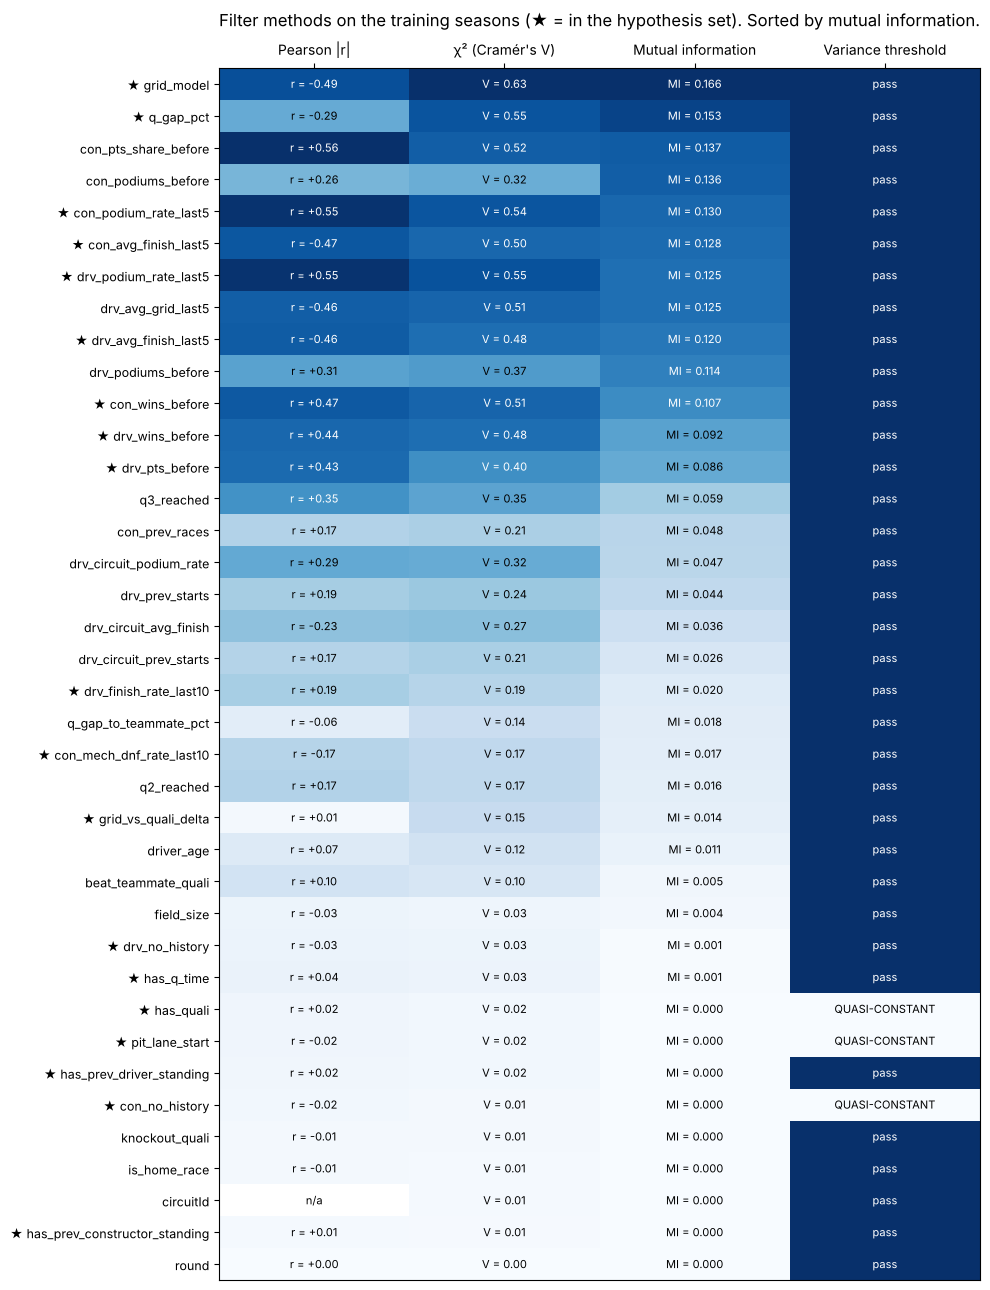

,features shared with the hypothesis set,set size
Pearson top-19,10,19
Chi-square top-19,9,19
Mutual information top-19,9,19
Variance threshold: all candidates minus quasi-constant,16,35


Pearson top-19: not in hypothesis set -> ['con_pts_share_before', 'drv_avg_grid_last5', 'q3_reached', 'drv_podiums_before', 'drv_circuit_podium_rate', 'con_podiums_before', 'drv_circuit_avg_finish', 'drv_prev_starts', 'q2_reached']
Chi-square top-19: not in hypothesis set -> ['con_pts_share_before', 'drv_avg_grid_last5', 'drv_podiums_before', 'q3_reached', 'drv_circuit_podium_rate', 'con_podiums_before', 'drv_circuit_avg_finish', 'drv_prev_starts', 'drv_circuit_prev_starts', 'con_prev_races']
Mutual information top-19: not in hypothesis set -> ['con_pts_share_before', 'con_podiums_before', 'drv_avg_grid_last5', 'drv_podiums_before', 'q3_reached', 'con_prev_races', 'drv_circuit_podium_rate', 'drv_prev_starts', 'drv_circuit_avg_finish', 'drv_circuit_prev_starts']
Variance threshold: all candidates minus quasi-constant: not in hypothesis set -> ['q2_reached', 'q3_reached', 'knockout_quali', 'beat_teammate_quali', 'q_gap_to_teammate_pct', 'con_pts_share_before', 'drv_avg_grid_last5', 'drv_

In [119]:
from sklearn.feature_selection import mutual_info_classif, VarianceThreshold
from scipy.stats import pearsonr, chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

POOL = [f for f in ALL_CANDIDATES if f not in SCREENED_OUT]          # screened candidate pool (3.5)
HYP_GROUPS = {
    "Grid position (H1)": ["grid_model", "pit_lane_start"],
    "Qualifying (H2)": ["qual_position_filled", "q_gap_pct", "has_q_time", "has_quali", "grid_vs_quali_delta"],
    "Standings (H3)": ["drv_pts_before", "drv_pos_before", "drv_wins_before", "has_prev_driver_standing",
                       "con_pts_before", "con_pos_before", "con_wins_before", "has_prev_constructor_standing"],
    "Driver form (H4)": ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_no_history"],
    "Constructor form (H4)": ["con_podium_rate_last5", "con_avg_finish_last5", "con_no_history"],
    "Reliability (H5)": ["con_mech_dnf_rate_last10", "drv_finish_rate_last10"],
}
HYP_GROUPS = {g: [f for f in fs if f in POOL] for g, fs in HYP_GROUPS.items()}     # apply screening
NEW_GROUPS = {
    "Qualifying stage flags": ["q2_reached", "q3_reached", "knockout_quali"],
    "Teammate comparison": ["beat_teammate_quali", "q_gap_to_teammate_pct"],
    "Standings share": ["con_pts_share_before", "drv_pts_share_before"],
    "Recent average grid": ["drv_avg_grid_last5"],
    "Experience": ["drv_prev_starts", "drv_podiums_before", "con_prev_races", "con_podiums_before", "driver_age"],
    "Circuit history": ["drv_circuit_prev_starts", "drv_circuit_podium_rate", "drv_circuit_avg_finish"],
    "Race context": ["round", "field_size"],
    "Circuit identity": ["circuitId"],
}
NEW_GROUPS = {g: [f for f in fs if f in POOL] for g, fs in NEW_GROUPS.items()}
NEW_GROUPS = {g: fs for g, fs in NEW_GROUPS.items() if fs}
HYP_FEATURES = [f for fs in HYP_GROUPS.values() for f in fs]
K = len(HYP_FEATURES)
print("Hypothesis set after screening:", K, "features")
for g, fs in HYP_GROUPS.items():
    print(f"  {g:24s} {fs}")

# ---------------- variance threshold
binary_pool = [f for f in POOL if f not in CATEGORICAL_FEATURES and set(TRAIN[f].dropna().unique()) <= {0, 1}]
vt = VarianceThreshold(threshold=0.01).fit(TRAIN[binary_pool].fillna(0))
top_share = {f: TRAIN[f].value_counts(normalize=True, dropna=False).iloc[0] for f in POOL}
quasi_constant = [f for f, keep in zip(binary_pool, vt.get_support()) if not keep]
quasi_constant += [f for f in POOL if f not in binary_pool and top_share[f] >= 0.99]

rows = []
for f in POOL:
    r = {"feature": f, "variance (0/1 features)": vt.variances_[binary_pool.index(f)] if f in binary_pool else np.nan,
         "most frequent value share": top_share[f], "passes variance threshold": f not in quasi_constant}
    if f not in CATEGORICAL_FEATURES:
        ok = TRAIN[f].notna()
        r["pearson_r"], r["pearson_p"] = pearsonr(TRAIN.loc[ok, f], TRAIN.loc[ok, "podium"])
    lab, _ = make_bins(TRAIN[f]) if f not in CATEGORICAL_FEATURES else (TRAIN[f].astype(str), None)
    table = pd.crosstab(lab, TRAIN["podium"])
    chi2_stat, chi2_p, dof, _ = chi2_contingency(table)
    r["chi2"], r["chi2_dof"], r["chi2_p"] = chi2_stat, dof, chi2_p
    r["cramers_v"] = np.sqrt(chi2_stat / (len(TRAIN) * (min(table.shape) - 1)))
    rows.append(r)
filters = pd.DataFrame(rows).set_index("feature")
X_mi = TRAIN[POOL].copy()
for f in POOL:
    X_mi[f] = X_mi[f].astype(float).fillna(X_mi[f].astype(float).median())
discrete = [f in CATEGORICAL_FEATURES or f in binary_pool for f in POOL]
filters["mutual_info"] = mutual_info_classif(X_mi, TRAIN["podium"], discrete_features=discrete, random_state=0)
filters["abs_pearson"] = filters["pearson_r"].abs()
for col, rank_col in [("abs_pearson", "rank_pearson"), ("cramers_v", "rank_chi2"), ("mutual_info", "rank_mi")]:
    filters[rank_col] = filters[col].rank(ascending=False, method="first")
filters["in_hypothesis_set"] = filters.index.isin(HYP_FEATURES)
display(filters.sort_values("mutual_info", ascending=False).round(4))
print("Quasi-constant (removed by the variance threshold):", quasi_constant)

FILTER_SETS = {
    f"Pearson top-{K}": filters.dropna(subset=["abs_pearson"]).nlargest(K, "abs_pearson").index.tolist(),
    f"Chi-square top-{K}": filters.nlargest(K, "cramers_v").index.tolist(),
    f"Mutual information top-{K}": filters.nlargest(K, "mutual_info").index.tolist(),
    "Variance threshold: all candidates minus quasi-constant": [f for f in POOL if f not in quasi_constant],
}

# heatmap of the four filter methods
show = filters[["abs_pearson", "cramers_v", "mutual_info"]].copy()
show["variance check"] = filters["passes variance threshold"].astype(float)
order_idx = filters.sort_values("mutual_info", ascending=False).index
show = show.loc[order_idx]
norm = show / show.max()
fig, ax = plt.subplots(figsize=(10, 13))
ax.imshow(norm.to_numpy(float), cmap="Blues", aspect="auto", vmin=0, vmax=1)
for i, f in enumerate(order_idx):
    txt = [("" if pd.isna(filters.at[f, "pearson_r"]) else f"r = {filters.at[f, 'pearson_r']:+.2f}"),
           f"V = {filters.at[f, 'cramers_v']:.2f}", f"MI = {filters.at[f, 'mutual_info']:.3f}",
           "pass" if filters.at[f, "passes variance threshold"] else "QUASI-CONSTANT"]
    for j, t in enumerate(txt):
        ax.text(j, i, t or "n/a", ha="center", va="center", fontsize=8, color="white" if norm.iat[i, j] > 0.6 else "black")
ax.set_xticks(range(4), ["Pearson |r|", "χ² (Cramér's V)", "Mutual information", "Variance threshold"]); ax.xaxis.tick_top()
ax.set_yticks(range(len(order_idx)), [f"{'★ ' if f in HYP_FEATURES else ''}{f}" for f in order_idx], fontsize=9)
ax.set_title("Filter methods on the training seasons (★ = in the hypothesis set). Sorted by mutual information.", pad=30)
t3_show("t3_filter_methods_heatmap")

overlap = pd.DataFrame({name: [len(set(fs) & set(HYP_FEATURES)), len(fs)] for name, fs in FILTER_SETS.items()},
                       index=["features shared with the hypothesis set", "set size"]).T
display(overlap)
for name, fs in FILTER_SETS.items():
    print(f"{name}: not in hypothesis set -> {[f for f in fs if f not in HYP_FEATURES]}")

**Result.**

- **The three ranking methods mostly agree on the top features:** grid, qualifying gap, constructor standings share,
  recent podium rates and recent average finish.
- **They disagree where relationships are not straight lines,** which shows why more than one method is needed:
  - `q_gap_pct` is 2nd by mutual information and 3rd by χ², but only 14th by Pearson (r = −0.29). Its effect is
    concentrated in the first percent of gap, which a linear measure under-rates.
  - `grid_vs_quali_delta` has Pearson r = 0.009 (p = 0.44, rank 35 of 38), yet χ² finds a clear difference across its
    bins (p < 0.001). Its U-shape cancels out in a linear correlation.
- **Variance threshold:** it flags `pit_lane_start` (0.29% of rows), `has_quali` (0.31%) and `con_no_history` (0.51%)
  as quasi-constant. These are the companion flags described above; whether dropping them matters is tested as trial
  T18.
- **Overlap with the hypothesis set:** each top-19 filter list shares only 9–10 features with it. The filters prefer
  the long-run counts (career podiums, circuit history), while the hypothesis set uses recent form and reliability. The
  trials decide which choice predicts better.

### 3.6.2 Trials: the hypothesis set, removing groups, adding groups, and the filter-method sets

| Trial | Feature set | Question it answers |
|---|---|---|
| T0 | grid only | Baseline: how far does starting position alone go? |
| T1 | hypothesis set (H1–H5) | The primary feature set from 3.1. |
| T2–T7 | hypothesis set minus one group | Does each hypothesis group really add something? |
| T8+ | hypothesis set plus one new group | Does any new candidate add something? |
| last 4 | Pearson / χ² / mutual-information top-k, variance-threshold set | Does a purely statistical filter choose a better set than the hypotheses? |

The decision rules from the top of Task 3 are applied automatically below the table.

**Decision rules (amended, see the top of Task 3).** A change to the hypothesis set needs more than one lucky comparison:

- it must hold in the **logistic** model and in the **boosting** model separately, not only on their average;
- an **addition** needs a PR-AUC gain whose race-bootstrap interval is above zero; a **removal** needs the group to be harmless in
  at least 95% of the bootstrap samples;
- it must **replicate**: the same comparison is repeated on three earlier blocks of training seasons (2008–10, 2011–13, 2014–16,
  each fitted on everything before it), and the change must hold in at least 3 of the 4 blocks. The columns
  `blocks better` / `blocks harmless` and `block ΔPR` show this.


In [ ]:
FIT_YEARS, EVAL_YEARS = (2003, 2016), (2017, 2019)
FIT = TRAIN[TRAIN["year"].between(*FIT_YEARS)]
EVAL = TRAIN[TRAIN["year"].between(*EVAL_YEARS)]
TIE = np.random.default_rng(123).random(len(EVAL)) * 1e-9
EVAL_RACES = [EVAL.index.get_indexer(g.index) for _, g in EVAL.groupby("raceId")]
BOOT = [np.concatenate([EVAL_RACES[i] for i in np.random.default_rng(500 + b).integers(0, len(EVAL_RACES), len(EVAL_RACES))])
        for b in range(200)]
y_eval = EVAL["podium"].to_numpy()

def fit_predict(features):
    num = [f for f in features if f not in CATEGORICAL_FEATURES]; cat = [f for f in features if f in CATEGORICAL_FEATURES]
    preds = {}
    for fam in ["logistic", "boosting"]:
        if fam == "logistic":
            steps = [("num", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num)]
            est = LogisticRegression(max_iter=3000)
        else:
            steps = [("num", "passthrough", num)]
            est = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=40, random_state=0)
        if cat:
            steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
        model = Pipeline([("prep", ColumnTransformer(steps, sparse_threshold=0)), ("model", est)]).fit(FIT[features], FIT["podium"])
        preds[fam] = model.predict_proba(EVAL[features])[:, 1]
    return preds

def scores(preds, idx=None):
    idx = np.arange(len(y_eval)) if idx is None else idx
    out = {}
    for fam, p in preds.items():
        out[fam] = (average_precision_score(y_eval[idx], p[idx] + TIE[idx]), roc_auc_score(y_eval[idx], p[idx] + TIE[idx]),
                    log_loss(y_eval[idx], p[idx], labels=[0, 1]))
    return {m: np.mean([out[f][i] for f in out]) for i, m in enumerate(["pr_auc", "roc_auc", "log_loss"])}

TRIALS = {"T0 grid only": HYP_GROUPS["Grid position (H1)"], "T1 hypothesis set": HYP_FEATURES}
n = 2
for g in HYP_GROUPS:
    if g != "Grid position (H1)":
        TRIALS[f"T{n} hypothesis − {g}"] = [f for f in HYP_FEATURES if f not in HYP_GROUPS[g]]; n += 1
for g, fs in NEW_GROUPS.items():
    TRIALS[f"T{n} hypothesis + {g}"] = HYP_FEATURES + [f for f in fs if f not in HYP_FEATURES]; n += 1
for name, fs in FILTER_SETS.items():
    TRIALS[f"T{n} {name}"] = fs; n += 1

def boot_pr(preds):
    # PR-AUC (mean of the two models) on each race-bootstrap sample
    return np.array([np.mean([average_precision_score(y_eval[b], p[b] + TIE[b]) for p in preds.values()]) for b in BOOT])

def family_scores(preds):
    # PR-AUC and log-loss of each model family on its own (the pooled scores average the two)
    return {fam: (average_precision_score(y_eval, p + TIE), log_loss(y_eval, p, labels=[0, 1])) for fam, p in preds.items()}

def boot_ll(preds):
    # log-loss (mean of the two models) on each race-bootstrap sample
    return np.array([np.mean([log_loss(y_eval[b], p[b], labels=[0, 1]) for p in preds.values()]) for b in BOOT])

# Replication blocks: the same comparison on three EARLIER blocks of training seasons (fit on everything before the block).
# The last block is the one used above. A decision that rests on one block of ~60 races is noisy (3.2.2).
BLOCKS = [((2003, 2007), (2008, 2010)), ((2003, 2010), (2011, 2013)), ((2003, 2013), (2014, 2016)), (FIT_YEARS, EVAL_YEARS)]
BLOCK_DATA = []
for (fa, fb), (ea, eb) in BLOCKS:
    fit_b, eval_b = TRAIN[TRAIN["year"].between(fa, fb)], TRAIN[TRAIN["year"].between(ea, eb)]
    BLOCK_DATA.append((fit_b, eval_b, eval_b["podium"].to_numpy(), np.random.default_rng(1).random(len(eval_b)) * 1e-9))

def fit_predict_on(features, fit_df, eval_df):
    num = [f for f in features if f not in CATEGORICAL_FEATURES]; cat = [f for f in features if f in CATEGORICAL_FEATURES]
    preds = {}
    for fam in ["logistic", "boosting"]:
        if fam == "logistic":
            steps = [("num", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num)]
            est = LogisticRegression(max_iter=3000)
        else:
            steps = [("num", "passthrough", num)]
            est = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=40, random_state=0)
        if cat:
            steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
        model = Pipeline([("prep", ColumnTransformer(steps, sparse_threshold=0)), ("model", est)]).fit(fit_df[features], fit_df["podium"])
        preds[fam] = model.predict_proba(eval_df[features])[:, 1]
    return preds

def block_scores(features):
    out = []
    for fit_b, eval_b, y_b, tie_b in BLOCK_DATA:
        p = fit_predict_on(features, fit_b, eval_b)
        out.append({fam: (average_precision_score(y_b, pr + tie_b), log_loss(y_b, pr, labels=[0, 1])) for fam, pr in p.items()})
    return out

ref_preds = fit_predict(HYP_FEATURES)
ref = scores(ref_preds)
ref_boot = boot_pr(ref_preds)
ref_boot_ll = boot_ll(ref_preds)
ref_fam = family_scores(ref_preds)
ref_blocks = block_scores(HYP_FEATURES)

def evaluate_trial(name, feats):
    is_ref = name.startswith("T1 ")
    p = ref_preds if is_ref else fit_predict(feats)
    sc = scores(p)
    fam = family_scores(p)
    diff = boot_pr(p) - ref_boot if not is_ref else np.zeros(1)
    diff_ll = boot_ll(p) - ref_boot_ll if not is_ref else np.zeros(1)
    lo, hi = np.percentile(diff, [2.5, 97.5])
    d_pr, d_ll = [], []
    for bs, rb in zip(block_scores(feats) if not is_ref else ref_blocks, ref_blocks):
        d_pr.append(np.mean([bs[f][0] - rb[f][0] for f in bs])); d_ll.append(np.mean([bs[f][1] - rb[f][1] for f in bs]))
    d_pr, d_ll = np.array(d_pr), np.array(d_ll)
    return {"trial": name, "n_features": len(feats), "PR-AUC": sc["pr_auc"], "ROC-AUC": sc["roc_auc"], "log-loss": sc["log_loss"],
            "ΔPR-AUC vs T1": sc["pr_auc"] - ref["pr_auc"], "ΔPR 95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "_lo": lo, "_hi": hi,
            "Δlog-loss vs T1 (− = better)": sc["log_loss"] - ref["log_loss"],
            "ΔPR logistic": fam["logistic"][0] - ref_fam["logistic"][0], "ΔPR boosting": fam["boosting"][0] - ref_fam["boosting"][0],
            "Δll logistic": fam["logistic"][1] - ref_fam["logistic"][1], "Δll boosting": fam["boosting"][1] - ref_fam["boosting"][1],
            "removal support": float(np.mean((diff >= 0) & (diff_ll <= 0))) if not is_ref else np.nan,
            "blocks better (of 4)": int(((d_pr > 0) & (d_ll < 0)).sum()) if not is_ref else np.nan,
            "blocks harmless (of 4)": int(((d_pr >= 0) & (d_ll <= 0)).sum()) if not is_ref else np.nan,
            "block ΔPR (2008-10, 11-13, 14-16, 17-19)": " ".join(f"{v:+.3f}" for v in d_pr)}

trial_rows = [evaluate_trial(name, feats) for name, feats in TRIALS.items()]
trials = pd.DataFrame(trial_rows)

REMOVE_SUPPORT = 0.95          # share of race-bootstrap samples in which dropping a group must be harmless
REPLICATE = 3                  # a change must hold in at least 3 of the 4 blocks

def both_families(r, strict):
    # the change must point the same way in the logistic model AND in the boosting model, not only on average
    if strict:    # an improvement: better on both metrics in both families
        return all(r[f"ΔPR {m}"] > 0 and r[f"Δll {m}"] < 0 for m in ("logistic", "boosting"))
    return all(r[f"ΔPR {m}"] >= 0 and r[f"Δll {m}"] <= 0 for m in ("logistic", "boosting"))    # at least as good

def decide(r):
    name = r["trial"]
    if name.startswith(("T0", "T1 ")):
        return "reference"
    if " − " in name:      # removal: only if dropping the group is harmless on both metrics, in both families, reliably, and repeatedly
        harmless = r["ΔPR-AUC vs T1"] >= 0 and r["Δlog-loss vs T1 (− = better)"] <= 0
        ok = harmless and both_families(r, strict=False) and r["removal support"] >= REMOVE_SUPPORT and r["blocks harmless (of 4)"] >= REPLICATE
        return "REMOVE group" if ok else "keep group (needed)"
    better = (r["ΔPR-AUC vs T1"] > 0 and r["Δlog-loss vs T1 (− = better)"] < 0 and r["_lo"] > 0
              and both_families(r, strict=True) and r["blocks better (of 4)"] >= REPLICATE)
    if " + " in name:
        return "ADD group" if better else "do not add"
    return "REPLACE hypothesis set" if better else "hypothesis set stays"
trials["decision"] = trials.apply(decide, axis=1)
display(trials.drop(columns=["_lo", "_hi"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(19, 0.42 * len(trials) + 2), sharey=True)
yy = np.arange(len(trials))
colors = [GREY if d == "reference" else GREEN if d in ("ADD group", "REPLACE hypothesis set", "keep group (needed)") else
          RED if d == "REMOVE group" else "#b0b0b0" for d in trials["decision"]]
ax = axes[0]
for i, r in trials.iterrows():
    if not r["trial"].startswith("T1 "):
        ax.plot([r["_lo"], r["_hi"]], [i, i], color=colors[i], linewidth=2)
    ax.plot(r["ΔPR-AUC vs T1"], i, "D", color=colors[i], markersize=7)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("PR-AUC difference vs the hypothesis set T1 (95% race-bootstrap interval)")
ax.set_title("Ranking quality (PR-AUC), scored on 2017–2019")
ax.set_yticks(yy, trials["trial"], fontsize=9); ax.invert_yaxis(); style_axis(ax, "x")
ax = axes[1]
ax.barh(yy, trials["Δlog-loss vs T1 (− = better)"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Log-loss difference vs T1 (negative = better probabilities)")
ax.set_title("Probability quality (log-loss)"); style_axis(ax, "x")
t3_show("t3_experiment_trials")

**Result (scored on 2017–2019, models fitted on 2003–2016).**

- **The hypothesis set is a clear step up from the grid alone.** T1 reaches PR-AUC 0.709, ROC-AUC 0.945, log-loss
  0.207, against 0.684 / 0.927 / 0.230 for T0. Log-loss improves by 0.023, the largest change of any trial.
- **Every hypothesis group is needed** (T2–T6). Removing any one of them makes the probabilities worse (log-loss up
  0.0006–0.0039). The largest loss is removing qualifying (PR-AUC −0.0035, log-loss +0.0039). Removing standings or
  driver form slightly raises PR-AUC (+0.005), but within noise, and both make log-loss worse. By the rule (the group
  stays unless removing it is at least as good on *both* metrics) all five groups stay.
- **No new group passes the "add" rule** (T7–T14). The stage flags, the standings share and the recent average grid
  slightly improve log-loss (−0.0008 to −0.0015), but their PR-AUC gains (+0.0006 to +0.0021) have intervals that
  include zero. Teammate comparison, experience, circuit history, race context and circuit identity all make log-loss worse.
  This matches 3.4: they mostly repeat information the hypothesis set already has.
- **No filter method beats the hypotheses** (T15–T18). Pearson, χ² and mutual-information top-19 sets and the
  variance-threshold set all score below T1 on PR-AUC (−0.002 to −0.004). The Pearson and variance-threshold sets have
  a slightly better log-loss (−0.0007 / −0.0008), so none of them is better on *both* metrics, and the variance set
  needs 35 features instead of 19. The filters choose correlated long-run counts over recent form and reliability.
- **Honest caveat:** most differences between trials are small and their intervals overlap zero. The evaluation block
  has 62 races, and 3.2.2 showed that a block of this size has a PR-AUC noise of about ±0.04. The decisions therefore
  rest on the rules fixed in advance, not on the third decimal, and the result is a **stable, defensible set** rather
  than a uniquely optimal one.

**Replication check (added in review).** The last three columns of the trial table repeat every comparison on earlier blocks.
They show how little a single block can decide: no candidate group improves both metrics in more than a few of the four blocks, and
the one group that passed the old single-block rule when this section was re-run in a second software environment (the qualifying
stage flags) improved things in only 2 of 4 blocks, with a gain concentrated in 2017–2019. With the amended rules the
hypothesis set stays as it is, which is also what the 2017–2019 result above shows. This is the honest reading of 3.2.2: with
about 60 races per block, the data can confirm a feature group that matters (qualifying, form) but cannot rank small additions.

### 3.6.3 Added after the Task 1 review: Q1 pace (`q1_gap_pct`)

Task 1 (2.5.2) added `q1_gap_pct`, the gap between a driver's **Q1** time and the fastest Q1 time of the race. Unlike `q_gap_pct`
(a driver knocked out in Q1 only has a Q1 time, but the pole is set in Q3 on a faster track), every driver of every format has a Q1
time, so this gap is comparable across drivers, races and qualifying formats. It is tested here as a new candidate with the same
evidence figure, the same beyond-the-grid statistic and the same decision rule as every other group. It was added after the
trials above, so it appears as trial T19 and does not renumber them.

In [ ]:
evidence_tables.update(evidence_figure("Q1 pace (like-with-like)", ["q1_gap_pct"], "t3_evidence_q1gap"))

x = TRAIN["q1_gap_pct"]; ok = x.notna()
lr_q1, p_q1 = grid_adjusted_lr("q1_gap_pct")
print(f"q1_gap_pct: missing {100 * x.isna().mean():.1f}% of training rows | Spearman with podium {spearmanr(x[ok], TRAIN.loc[ok, 'podium'])[0]:+.2f} | "
      f"AUC alone {roc_auc_score(TRAIN.loc[ok, 'podium'], x[ok]):.3f} | beyond the grid: LR χ² = {lr_q1:.0f} (p = {p_q1:.3g})")
print(f"Spearman with q_gap_pct: {spearmanr(x[ok & TRAIN['q_gap_pct'].notna()], TRAIN.loc[ok & TRAIN['q_gap_pct'].notna(), 'q_gap_pct'])[0]:.2f} (screening threshold 0.90)")

q1_trial = pd.DataFrame([evaluate_trial("T19 hypothesis + Q1 pace", HYP_FEATURES + ["q1_gap_pct"])])
q1_trial["decision"] = q1_trial.apply(decide, axis=1)
display(q1_trial.drop(columns=["_lo", "_hi"]).round(4).T)
NEW_GROUPS["Q1 pace"] = ["q1_gap_pct"]
trials = pd.concat([trials, q1_trial], ignore_index=True)

**Result.** `q1_gap_pct` is informative on its own (Spearman about -0.40 with podium, ROC-AUC 0.83 once the direction is flipped) and adds
something beyond the grid (LR χ² = 19, p < 0.001), but less than `q_gap_pct` (χ² = 59), and it is strongly related to it
(ρ = 0.85, just under the 0.90 screening line). Added to the hypothesis set it does **not** pass the rule: the PR-AUC gain is
within noise and it helps in only one of the four blocks. It stays out of the final set. The Task 1 addition is therefore tested
and rejected on evidence, not silently ignored.

## 3.7 The final feature set

The final set is the hypothesis set with the decisions of 3.6 applied: groups whose removal did not hurt are removed,
and groups that passed the "add" rule are added. A last trial confirms the final set against the hypothesis set.

In [121]:
FINAL_GROUPS = {g: fs for g, fs in HYP_GROUPS.items()
                if not any(t.endswith(f"− {g}") and d == "REMOVE group" for t, d in zip(trials["trial"], trials["decision"]))}
for g, fs in NEW_GROUPS.items():
    if any(t.endswith(f"+ {g}") and d == "ADD group" for t, d in zip(trials["trial"], trials["decision"])):
        FINAL_GROUPS[g] = fs
replaced = trials[trials["decision"].eq("REPLACE hypothesis set")]
if len(replaced):
    best = replaced.sort_values("ΔPR-AUC vs T1", ascending=False).iloc[0]["trial"]
    FINAL_GROUPS = {"filter-selected": TRIALS[best]}
FINAL_FEATURES = list(dict.fromkeys(f for fs in FINAL_GROUPS.values() for f in fs))

final_sc = scores(fit_predict(FINAL_FEATURES)) if FINAL_FEATURES != HYP_FEATURES else ref
display(pd.DataFrame([{"set": "T1 hypothesis set", "n_features": len(HYP_FEATURES), **ref},
                      {"set": "FINAL set", "n_features": len(FINAL_FEATURES), **final_sc}]).round(4))
for g, fs in FINAL_GROUPS.items():
    print(f"{g:26s} {fs}")
print("Final features:", len(FINAL_FEATURES))

,set,n_features,pr_auc,roc_auc,log_loss
0,T1 hypothesis set,19,0.7091,0.9447,0.2067
1,FINAL set,19,0.7091,0.9447,0.2067


Grid position (H1)         ['grid_model', 'pit_lane_start']
Qualifying (H2)            ['q_gap_pct', 'has_q_time', 'has_quali', 'grid_vs_quali_delta']
Standings (H3)             ['drv_pts_before', 'drv_wins_before', 'has_prev_driver_standing', 'con_wins_before', 'has_prev_constructor_standing']
Driver form (H4)           ['drv_podium_rate_last5', 'drv_avg_finish_last5', 'drv_no_history']
Constructor form (H4)      ['con_podium_rate_last5', 'con_avg_finish_last5', 'con_no_history']
Reliability (H5)           ['con_mech_dnf_rate_last10', 'drv_finish_rate_last10']
Final features: 19


In [ ]:
DOCUMENTED_FINAL = [
    "grid_model", "pit_lane_start", "q_gap_pct", "has_q_time", "has_quali", "grid_vs_quali_delta",
    "drv_pts_before", "drv_wins_before", "has_prev_driver_standing", "con_wins_before", "has_prev_constructor_standing",
    "drv_podium_rate_last5", "drv_avg_finish_last5", "drv_no_history", "con_podium_rate_last5", "con_avg_finish_last5",
    "con_no_history", "con_mech_dnf_rate_last10", "drv_finish_rate_last10",
]
same_final = set(FINAL_FEATURES) == set(DOCUMENTED_FINAL)
print("Final set equals the 19 features described in 3.7.1 and used by Tasks 4-6:", same_final)
if not same_final:
    print("  added:", sorted(set(FINAL_FEATURES) - set(DOCUMENTED_FINAL)), "| removed:", sorted(set(DOCUMENTED_FINAL) - set(FINAL_FEATURES)))
    print("  -> the prose of 3.7.1 and of Tasks 4-6 describes a different set and must be updated before submission")

### 3.7.1 Why each selected feature is in the model

The final set is the hypothesis set: **19 features in 6 groups**. Each feature below lists the hypothesis, the
evidence and why it is known before the race. Figure references are to section 3.4.

**Group 1 – Grid position (H1)**

- **`grid_model`** — the actual starting position after penalties; pit-lane starts are placed behind the field.
  - *Why:* fewer cars to pass. The strongest single candidate (ROC-AUC 0.91, ρ ≈ −0.5 in both eras).
  - *Evidence:* podium rate 78–84% from P1, ~1% from P16+, with the same top-down pattern in every training season
    (season heatmap, 3.4.1).
  - *Known before the race:* the grid is published before the start.
- **`pit_lane_start`** — 1 if the driver starts from the pit lane.
  - *Why:* companion flag. `grid_model` places these drivers at the back, and the flag tells the model that this
    position was assigned, not earned in qualifying.
  - *Evidence:* 20 training rows, 0 podiums. Flagged as quasi-constant by the variance threshold, but dropping the
    quasi-constant flags (T18) did not improve the model.
  - *Known before the race:* grid.

**Group 2 – Qualifying (H2)**

- **`q_gap_pct`** — best qualifying lap as % behind the fastest qualifier of the same race.
  - *Why:* one-lap pace this weekend, comparable across circuits (raw seconds are not).
  - *Evidence:* beyond-grid χ² = 59. Inside the P2–3 grid group the podium rate drops 60% → 46% → 38% as the gap
    grows. 2nd by mutual information. Removing the qualifying group gave the largest loss of any group (T2: PR-AUC
    −0.0035, log-loss +0.0039).
  - *Known before the race:* qualifying is complete.
- **`grid_vs_quali_delta`** — grid minus qualifying rank (positive = pushed back by a penalty).
  - *Why:* a penalised fast car is still fast. Task 2 Q1 found 73 front-row cases changed by penalties or sprints.
  - *Evidence:* inside P7–10, cars pushed back 3–5 places podium 21% vs 5% for unchanged cars. Beyond-grid χ² = 24,
    p < 0.001. Non-linear, which is why Pearson misses it and χ² finds it.
  - *Known before the race:* qualifying + published grid.
- **`has_q_time`**, **`has_quali`** — flags for a missing qualifying time or record.
  - *Why:* without them, a filled-in gap would look like real pace.
  - *Evidence:* rows without a time podium 4–7% vs 14–15% (χ² = 10, p = 0.001).
  - *Known before the race:* qualifying.

**Group 3 – Season standings (H3)**

- **`drv_wins_before`**, **`con_wins_before`** — race wins of the driver and of the team so far this season.
  - *Evidence:* the clearest staircase of all: 0 wins → 7% podiums, 4+ wins → 66–74%. Inside P4–6, 17% → 51%.
    Beyond-grid χ² = 104 and 106.
- **`drv_pts_before`** — championship points before the race (the screening kept it over team points and rank).
  - *Evidence:* χ² = 91; inside P2–3, 41% → 65% from the lowest to the highest points band.
- **`has_prev_driver_standing`**, **`has_prev_constructor_standing`** — companions that mark round 1 (no standings yet,
  so 0 points does not mean a weak driver).
- *Known before the race (whole group):* standings after the **previous** round (Task 1, 2.6.4; verified there are no
  current-race points).
- *Trial evidence:* removing standings made log-loss worse (T3).

**Group 4 – Driver recent form (H4)**

- **`drv_podium_rate_last5`** — share of podiums in the driver's previous 5 starts.
  - *Evidence:* 3% at zero → 66–67% at 60–100%, the same in both eras. Inside P4–6, 9% → 48%; inside P11+, 1% → 32%.
    Beyond-grid χ² = 233.
- **`drv_avg_finish_last5`** — average finishing position over the previous 5 starts (retirements count as a late
  position, so it mixes pace and reliability).
  - *Evidence:* χ² = 214; 42–51% podiums for an average of 1–6.8.
- **`drv_no_history`** — companion flag for a driver's first start, where the two rates are missing.
- *Known before the race (whole group):* built only from earlier starts (strict "before" lookup); the corruption test
  in 3.3.4 proved the current race never enters.
- *Trial evidence:* removing the group made log-loss worse (T4).

**Group 5 – Constructor recent form (H4)**

- **`con_podium_rate_last5`**, **`con_avg_finish_last5`** — team podiums per start, and average finish, over the
  team's previous 5 races, both cars combined.
  - *Evidence:* 1–2% → 58–68% podiums from the weakest to the strongest recent team form (AUC 0.88). Inside P2–3,
    18% → 66%. χ² = 197 and 225.
- **`con_no_history`** — companion for a team's first race under its `constructorId`.
- *Known before the race:* earlier races only, both cars combined before shifting, so a teammate's current result
  cannot leak in.
- *Trial evidence:* removing the group made PR-AUC and log-loss worse (T5).

**Group 6 – Reliability (H5)**

- **`con_mech_dnf_rate_last10`** — the team's mechanical retirements per start over its previous 10 races.
  - *Why:* Task 2 Q3 showed large differences between teams.
  - *Evidence:* podium rate 20–21% for teams at ≤ 5% vs 4% above 20%, in both eras. χ² = 26.
- **`drv_finish_rate_last10`** — share of the driver's previous 10 starts that reached the finish.
  - *Evidence:* 2–5% podiums below 60% vs 21–26% at 90%+. χ² = 34.
- *Known before the race:* earlier races only.
- *Trial evidence:* removing reliability made PR-AUC and log-loss worse (T6).

### 3.7.2 Every candidate: selected or dropped, and why

In [122]:
dec_rows = []
for f in ALL_CANDIDATES:
    group = next(g for g, fs in CANDIDATE_GROUPS.items() if f in fs)
    if f in FINAL_FEATURES:
        status, why = "SELECTED", "hypothesis supported by the evidence (3.4) and needed in the trials (3.6)"
    elif f in SCREENED_OUT:
        status, why = "dropped: screening", SCREENED_OUT[f]
    elif f in HYP_FEATURES:
        g = next(g for g, fs in HYP_GROUPS.items() if f in fs)
        r = trials[trials["trial"].str.endswith(f"− {g}")].iloc[0]
        status, why = "dropped: trial", f"removing '{g}' did not hurt: ΔPR-AUC {r['ΔPR-AUC vs T1']:+.4f}, Δlog-loss {r['Δlog-loss vs T1 (− = better)']:+.4f}"
    elif any(f in fs for fs in NEW_GROUPS.values()):
        g = next(g for g, fs in NEW_GROUPS.items() if f in fs)
        r = trials[trials["trial"].str.endswith(f"+ {g}")].iloc[0]
        status, why = "dropped: trial", f"adding '{g}' did not pass: ΔPR-AUC {r['ΔPR-AUC vs T1']:+.4f} {r['ΔPR 95% CI']}, Δlog-loss {r['Δlog-loss vs T1 (− = better)']:+.4f}"
    else:
        status, why = "dropped: hypothesis", {"is_home_race": "Task 2 Q2: no home effect once grid is controlled",
                                              "is_sprint_weekend": "no sprint weekends in the training seasons"}.get(f, "see 3.1")
    dec_rows.append({"feature": f, "group": group, "status": status, "reason": why})
feature_decisions = pd.DataFrame(dec_rows)
with pd.option_context("display.max_colwidth", None):
    display(feature_decisions)
display(feature_decisions["status"].value_counts().to_frame("features"))

,feature,group,status,reason
0,grid_model,A. Grid position,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
1,pit_lane_start,A. Grid position,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
2,qual_position_filled,B. Qualifying rank & pace,dropped: screening,near-duplicate of grid_model (ρ = +0.97)
3,has_quali,B. Qualifying rank & pace,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
4,q_gap_pct,B. Qualifying rank & pace,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
5,has_q_time,B. Qualifying rank & pace,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
6,grid_vs_quali_delta,C. Grid-qualifying movement,SELECTED,hypothesis supported by the evidence (3.4) and needed in the trials (3.6)
7,q2_reached,D. Qualifying stage flags,dropped: trial,"adding 'Qualifying stage flags' did not pass: ΔPR-AUC +0.0010 [-0.002, +0.004], Δlog-loss -0.0013"
8,q3_reached,D. Qualifying stage flags,dropped: trial,"adding 'Qualifying stage flags' did not pass: ΔPR-AUC +0.0010 [-0.002, +0.004], Δlog-loss -0.0013"
9,knockout_quali,D. Qualifying stage flags,dropped: trial,"adding 'Qualifying stage flags' did not pass: ΔPR-AUC +0.0010 [-0.002, +0.004], Δlog-loss -0.0013"


,features
status,
SELECTED,19
dropped: trial,18
dropped: screening,6
dropped: hypothesis,1


### 3.7.3 What each chosen feature does inside the model (scramble test)

3.6 showed that each *group* is needed. This section looks at what each chosen feature does once it is in the model,
using a **scramble test** (permutation importance): fit the two trial models on the final set (2003–2016), then
randomly shuffle one feature's values across the 2017–2019 rows, so that feature no longer matches its driver, and
measure how much worse the predictions get. Nothing is re-trained. A large increase in log-loss means the model leans
heavily on that feature; close to zero means the model does not need it *on its own* because other features carry the
same information. Each shuffle is repeated 10 times and averaged. The same test is also run for whole groups, by
shuffling all features of a group together.

In [ ]:
def fit_models(features):
    out = {}
    for fam in ["logistic", "boosting"]:
        if fam == "logistic":
            prep = ColumnTransformer([("num", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), features)])
            est = LogisticRegression(max_iter=3000)
        else:
            prep = ColumnTransformer([("num", "passthrough", features)])
            est = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_depth=3, min_samples_leaf=40, random_state=0)
        out[fam] = Pipeline([("prep", prep), ("model", est)]).fit(FIT[features], FIT["podium"])
    return out

final_models = fit_models(FINAL_FEATURES)
def eval_scores(X):
    ps = [m.predict_proba(X[FINAL_FEATURES])[:, 1] for m in final_models.values()]
    return np.mean([log_loss(y_eval, p) for p in ps]), np.mean([average_precision_score(y_eval, p + TIE) for p in ps])

base_ll, base_pr = eval_scores(EVAL)
rng_perm = np.random.default_rng(0)
def scramble(cols, repeats=10):
    d_ll, d_pr = [], []
    for _ in range(repeats):
        X = EVAL.copy(); idx = rng_perm.permutation(len(X))
        for c in cols:
            X[c] = X[c].values[idx]
        ll, pr = eval_scores(X)
        d_ll.append(ll - base_ll); d_pr.append(base_pr - pr)
    return np.mean(d_ll), np.mean(d_pr)

feat_group = {f: g for g, fs in FINAL_GROUPS.items() for f in fs}
rows = []
for f in FINAL_FEATURES:
    dll, dpr = scramble([f])
    rows.append({"feature": f, "group": feat_group[f], "log-loss increase": dll,
                 "log-loss increase %": 100 * dll / base_ll, "PR-AUC drop": dpr})
feature_effects = pd.DataFrame(rows).sort_values("log-loss increase", ascending=False).reset_index(drop=True)
grows = []
for g, fs in FINAL_GROUPS.items():
    dll, dpr = scramble(fs)
    grows.append({"group": g, "features": len(fs), "log-loss increase": dll,
                  "log-loss increase %": 100 * dll / base_ll, "PR-AUC drop": dpr})
group_effects = pd.DataFrame(grows).sort_values("log-loss increase", ascending=False).reset_index(drop=True)
print(f"Final-set model on 2017–2019: log-loss {base_ll:.4f}, PR-AUC {base_pr:.4f}")
display(group_effects.round(4))
display(feature_effects.round(4))

GROUP_COLOURS = dict(zip(FINAL_GROUPS, [GREY, BLUE, ORANGE, GREEN, "#7a5cc8", RED, "#c9a227", "#16a6a6", "#a64d79", "#555555"]))
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1, 1.5]})
ge = group_effects.iloc[::-1]
axes[0].barh(ge["group"], ge["log-loss increase %"], color=[GROUP_COLOURS[g] for g in ge["group"]])
for y_, v in enumerate(ge["log-loss increase %"]):
    axes[0].text(v + 0.8, y_, f"+{v:.1f}%", va="center", fontsize=10)
axes[0].set_title("Whole group scrambled")
axes[0].set_xlabel("Log-loss increase on 2017–2019 (% of the final model's log-loss)")
fe = feature_effects.iloc[::-1]
axes[1].barh(fe["feature"], fe["log-loss increase %"], color=[GROUP_COLOURS[g] for g in fe["group"]])
for y_, v in enumerate(fe["log-loss increase %"]):
    axes[1].text(max(v, 0) + 0.8, y_, f"{v:+.1f}%", va="center", fontsize=9)
axes[1].set_title("One feature scrambled (colour = group)")
axes[1].set_xlabel("Log-loss increase on 2017–2019 (% of the final model's log-loss)")
for ax in axes:
    style_axis(ax, grid="x"); ax.set_xlim(right=ax.get_xlim()[1] * 1.12)
fig.suptitle("Scramble test: how much worse the final model gets when a feature's information is destroyed", fontsize=13)
plt.tight_layout()
t3_show("t3_feature_effects")

**Result.**

- **Grid position dominates.** Scrambling `grid_model` makes log-loss about 72% worse and drops PR-AUC by about 0.26.
  Starting position is the backbone of every podium prediction, as hypothesis H1 said.
- **The next three groups matter at a similar level:** qualifying (≈ 9% worse when scrambled), constructor form
  (≈ 8.5%) and driver form (≈ 7.6%). Inside them, the model leans most on `con_avg_finish_last5` (≈ 8.6%),
  `q_gap_pct` (≈ 5.6%), `drv_podium_rate_last5` (≈ 4.0%) and `has_q_time` (≈ 2.6%).
- **Standings (≈ 1.5%) and reliability (≈ 0.4%) have small effects on 2017–2019.** Their information overlaps with
  recent form: a team that wins a lot also has a high recent podium rate. Removing them in 3.6 still made the
  probabilities slightly worse (T3, T6), so they are kept, but their contribution is modest and should be described
  that way in the report.
- **Many single features score close to zero** (e.g. `drv_pts_before`, `drv_wins_before`, the `has_prev_*` flags,
  `con_mech_dnf_rate_last10`). This does not mean they are useless. When one is scrambled, its partners (wins ↔ points
  ↔ recent podiums, or a flag ↔ its feature) still carry the same information, so the model barely notices. This is
  exactly why 3.6 tested *groups* rather than single features.
- **Companion flags** (`pit_lane_start`, `has_quali`, `drv_no_history`, `con_no_history`, `has_prev_*`) affect only the
  few rows they mark (0.3–7% of rows), so their average effect is small by construction. Their job is to stop the model
  from misreading a filled-in or missing value on those rows.

## 3.8 Leakage audit and the final modelling table

For every selected feature the table records *when* the information becomes known. The cell then asserts:

- no forbidden post-race column is a feature;
- the corruption test of 3.3.4 passed;
- the grain is still one row per `(raceId, driverId)`;
- no race crosses splits.

It then writes the modelling table and the `X` / `y` objects for Task 4. Features are handed over **raw**:
imputation and scaling are Task 4's job, fitted on `X_train` only.

In [ ]:
KNOWN_WHEN = {
    "grid_model": "starting grid, published before the race", "pit_lane_start": "starting grid, published before the race",
    "qual_position_filled": "qualifying (completed before the race)", "q_gap_pct": "qualifying (completed before the race)",
    "has_q_time": "qualifying (completed before the race)", "has_quali": "qualifying (completed before the race)",
    "grid_vs_quali_delta": "qualifying and the published grid",
    "drv_pts_before": "standings after the PREVIOUS round", "drv_pos_before": "standings after the PREVIOUS round",
    "drv_wins_before": "standings after the PREVIOUS round", "con_pts_before": "standings after the PREVIOUS round",
    "con_pos_before": "standings after the PREVIOUS round", "con_wins_before": "standings after the PREVIOUS round",
    "has_prev_driver_standing": "standings after the PREVIOUS round", "has_prev_constructor_standing": "standings after the PREVIOUS round",
    "drv_podium_rate_last5": "driver's 5 previous starts", "drv_avg_finish_last5": "driver's 5 previous starts",
    "drv_avg_grid_last5": "driver's 5 previous starts", "drv_no_history": "driver's earlier starts",
    "con_podium_rate_last5": "team's 5 previous races", "con_avg_finish_last5": "team's 5 previous races", "con_no_history": "team's earlier races",
    "con_mech_dnf_rate_last10": "team's 10 previous races", "drv_finish_rate_last10": "driver's 10 previous starts",
    "q2_reached": "qualifying", "q3_reached": "qualifying", "knockout_quali": "qualifying format",
    "q1_gap_pct": "qualifying (completed before the race)",
    "beat_teammate_quali": "qualifying", "q_gap_to_teammate_pct": "qualifying",
    "con_pts_share_before": "standings after the PREVIOUS round", "drv_pts_share_before": "standings after the PREVIOUS round",
    "drv_prev_starts": "career before the race", "drv_podiums_before": "career before the race", "con_prev_races": "team history",
    "con_podiums_before": "team history", "driver_age": "calendar", "drv_circuit_prev_starts": "earlier visits to the circuit",
    "drv_circuit_podium_rate": "earlier visits to the circuit", "drv_circuit_avg_finish": "earlier visits to the circuit",
    "round": "calendar", "field_size": "published grid", "circuitId": "calendar",
}
FORBIDDEN = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds", "fastestLap", "rank",
             "fastestLapTime", "fastestLapSpeed", "statusId", "status", "status_group", "podium", "raceId", "driverId",
             "constructorId", "year", "date", "q_best_s"}
assert not FORBIDDEN & set(FINAL_FEATURES)
assert set(FINAL_FEATURES) <= set(KNOWN_WHEN)
assert corruption_check["changed values in that race"].eq(0).all()
assert not t3.duplicated(["raceId", "driverId"]).any() and t3.groupby("raceId")["split"].nunique().max() == 1

audit = pd.DataFrame({"feature": FINAL_FEATURES, "known before the race from": [KNOWN_WHEN[f] for f in FINAL_FEATURES],
                      "missing % (all splits)": [100 * t3[f].isna().mean() for f in FINAL_FEATURES]})
display(audit.round(2))

META = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "split"]
task3_modeling_table = t3[META + [f for f in FINAL_FEATURES if f not in META] + ["podium"]].copy()
TASK3_FEATURE_GROUPS = FINAL_GROUPS                       # for the Task 5 feature-group ablation
TASK3_SELECTED_FEATURES = FINAL_FEATURES
masks = {k: task3_modeling_table["split"].eq(k) for k in ["train", "val", "test"]}
X_train, y_train = task3_modeling_table.loc[masks["train"], FINAL_FEATURES], task3_modeling_table.loc[masks["train"], "podium"]
X_val, y_val = task3_modeling_table.loc[masks["val"], FINAL_FEATURES], task3_modeling_table.loc[masks["val"], "podium"]
X_test, y_test = task3_modeling_table.loc[masks["test"], FINAL_FEATURES], task3_modeling_table.loc[masks["test"], "podium"]

out_dir = T3_FIG_DIR.parent
task3_modeling_table.to_csv(out_dir / "task3_modeling_table.csv", index=False)
feature_decisions.to_csv(out_dir / "task3_feature_decisions.csv", index=False)
trials.drop(columns=["_lo", "_hi"]).to_csv(out_dir / "task3_experiment_trials.csv", index=False)
import json
(out_dir / "task3_feature_manifest.json").write_text(json.dumps({
    "target": "podium (positionOrder <= 3)", "cutoff": "after qualifying, before the race starts",
    "split": {k: [int(v[0]), int(v[1])] for k, v in SPLIT_T3.items()},
    "feature_groups": FINAL_GROUPS, "selected_features": FINAL_FEATURES,
    "note": "Features are raw; fit any imputation/scaling on X_train only."}, indent=2), encoding="utf-8")
display(pd.DataFrame({"object": ["X_train", "X_val", "X_test"], "rows": [len(X_train), len(X_val), len(X_test)],
                      "columns": [X_train.shape[1]] * 3, "podium rate": [y_train.mean(), y_val.mean(), y_test.mean()]}).round(4))
print("PASS: leakage audit complete; handoff objects and files written to", out_dir)

## 3.9 Task 3 summary

**Split** (3.2):

- **Choice:** train 2003–2019 (6,822 rows), validation 2020–2021 (779 rows, 117 podiums), test 2022–2024
  (1,356 rows, 204 podiums).
- **How it was chosen:** out of 16 candidate boundaries, by a rule stated in advance. It is the only split that meets
  the minimum validation and test sizes while keeping the most training data. It is identical to the split built in
  Task 1, so Tasks 1–2 are unchanged.
- **Why not random:** a random split would put 100% of test races in training too.

**Features** (3.1 → 3.7):

- **Primary set from the earlier EDA:** 5 hypotheses (grid, qualifying, standings, recent form, reliability).
- **Exploratory evidence (3.4):** each hypothesis checked for every candidate, with per-era rate plots, grid-controlled
  heatmaps and a summary heatmap.
- **Screening (3.5):** 6 candidates removed (1 constant, 5 near-duplicates).
- **Trials (3.6):** 19 trials comparing the hypothesis set with removals, additions and the Pearson / χ² /
  mutual-information / variance-threshold sets. The hypothesis set was kept: every group was needed, and no addition or
  filter set beat it.
- **Final: 19 features in 6 groups** (`TASK3_FEATURE_GROUPS`), all known before the race (3.8).
- **What each feature does in the model (3.7.3, scramble test):** grid position dominates; qualifying, team form and
  driver form follow at a similar level; standings and reliability add only a little on 2017–2019 because they overlap
  with recent form.

**For Task 4:**

- `X_train`/`y_train`, `X_val`/`y_val`, `X_test`/`y_test` and `task3_modeling_table`.
- Features are raw. Missing values remain only where they mean something: no previous start, no previous team race,
  no qualifying time; each has a companion flag. Fit any imputation or scaling on `X_train` only.
- `TASK3_FEATURE_GROUPS` gives the 6 groups for the Task 5 feature-group ablation.

**Limitations to state in the report.**

- Differences between trials are small compared with the noise of a 62-race evaluation block, so the set is
  defensible rather than uniquely optimal.
- Validation (2020–21) is hybrid-era while test (2022–24) is the new-car era. An era-matched validation set is
  impossible under the size rule (3.2.3).
- Team history restarts when a team is renamed (new `constructorId`).
- Recent average finish mixes pace and reliability.
- All evidence is association, not causation.

# Task 4 — Predictive Modeling

## 4.1 Introduction and objectives

### What are we doing?

Task 4 turns the leakage-safe modeling table produced by Task 3 into three binary classifiers that predict whether a driver will finish on the podium:

1. Logistic Regression — the interpretable statistical baseline.
2. Random Forest — a nonlinear tree ensemble.
3. A shallow feed-forward neural network — two hidden layers implemented with TensorFlow/Keras.

All models use exactly the same 19 Task 3 features, target, rows, and chronological train/validation/test partitions. Model-specific preprocessing is allowed, but every learned preprocessing operation is fitted on training rows only.

### Why are we doing it this way?

The milestone requires at least two different statistical machine-learning models and one shallow neural network. Comparing different model families tells us whether nonlinear complexity adds useful predictive information beyond a strong, interpretable baseline.

### How will model development remain honest?

- Training data fits model parameters and preprocessing.
- Validation data selects hyperparameters and one probability threshold per model.
- Test data remains untouched until every configuration, threshold, and the validation-selected final model are frozen.
- PR-AUC is the primary metric because podiums are the minority class. F1 is secondary because it balances precision and recall after a threshold is chosen.

Tasks 1–3 above are read-only. Every Task 4 variable is prefixed with `t4_` to avoid altering earlier work.


## 4.2 Inspecting the final Task 3 modeling dataset

### What are we doing?

We copy the final Task 3 feature matrices and targets into Task 4-only variables, then audit their structure without changing them.

### Why are we doing it?

All three models must use the same underlying rows and selected features. This audit verifies that the handoff is suitable for binary classification and catches missing, non-numeric, infinite, duplicated, or forbidden post-race information before fitting a model.

### How does it work?

The code uses the actual Task 3 objects: `TASK3_SELECTED_FEATURES`, `task3_modeling_table`, `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, and `y_test`. Copies are made so Task 4 cannot mutate Tasks 1–3.

### What should we expect?

The selected feature list must be identical in all splits, the target must contain only 0 and 1, `(raceId, driverId)` must remain unique, and no post-race field may be a predictor. Missing values are allowed only because Task 3 deliberately retains meaningful missingness and companion flags; imputation therefore belongs inside each Task 4 pipeline.


In [ ]:
# Task 4 imports and reproducibility settings. No Task 1-3 object is overwritten.
import json as t4_json
import random as t4_random
import warnings as t4_warnings
from pathlib import Path as T4Path

import joblib as t4_joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown as T4Markdown, display as t4_display

from sklearn.base import clone as t4_clone
from sklearn.compose import ColumnTransformer as T4ColumnTransformer
from sklearn.ensemble import RandomForestClassifier as T4RandomForestClassifier
from sklearn.impute import SimpleImputer as T4SimpleImputer
from sklearn.linear_model import LogisticRegression as T4LogisticRegression
from sklearn.metrics import (
    average_precision_score as t4_average_precision_score,
    f1_score as t4_f1_score,
    precision_recall_curve as t4_precision_recall_curve,
    precision_score as t4_precision_score,
    recall_score as t4_recall_score,
    roc_auc_score as t4_roc_auc_score,
    roc_curve as t4_roc_curve,
)
from sklearn.pipeline import Pipeline as T4Pipeline
from sklearn.preprocessing import StandardScaler as T4StandardScaler

try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError(
        "Task 4 requires TensorFlow/Keras for the shallow neural network. "
        "Kaggle normally includes TensorFlow; otherwise install tensorflow before running this section."
    ) from exc

T4_RANDOM_SEED = 42
np.random.seed(T4_RANDOM_SEED)
t4_random.seed(T4_RANDOM_SEED)
tf.keras.utils.set_random_seed(T4_RANDOM_SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

t4_output_root = T4Path("/kaggle/working") if T4Path("/kaggle/working").exists() else T4Path.cwd()
t4_output_dir = t4_output_root / "task4_outputs"
t4_output_dir.mkdir(parents=True, exist_ok=True)
print("Task 4 outputs will be written to:", t4_output_dir)


In [ ]:
# Copy the exact Task 3 handoff. These copies isolate Task 4 from earlier sections.
t4_selected_features = list(TASK3_SELECTED_FEATURES)
t4_X_train = X_train.loc[:, t4_selected_features].copy()
t4_y_train = y_train.copy().astype(int)
t4_X_val = X_val.loc[:, t4_selected_features].copy()
t4_y_val = y_val.copy().astype(int)
t4_X_test = X_test.loc[:, t4_selected_features].copy()
t4_y_test = y_test.copy().astype(int)

t4_X_by_split = {"train": t4_X_train, "validation": t4_X_val, "test": t4_X_test}
t4_y_by_split = {"train": t4_y_train, "validation": t4_y_val, "test": t4_y_test}

# Required structural checks.
assert t4_selected_features == list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert len(t4_selected_features) == len(set(t4_selected_features)), "Task 3 selected a feature twice"
assert set(pd.concat(t4_y_by_split.values()).unique()) <= {0, 1}, "Target is not binary"

t4_forbidden_predictors = {
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
    "status_group", "podium", "raceId", "driverId", "constructorId", "date",
}
assert not (set(t4_selected_features) & t4_forbidden_predictors), "A forbidden post-race/identity field is a predictor"

t4_audit_rows = []
for t4_split_name, t4_X_part in t4_X_by_split.items():
    t4_y_part = t4_y_by_split[t4_split_name]
    t4_non_numeric = t4_X_part.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
    t4_inf_count = int(np.isinf(t4_X_part.to_numpy(dtype=float)).sum())
    t4_keys = task3_modeling_table.loc[t4_X_part.index, ["raceId", "driverId"]]
    t4_audit_rows.append({
        "split": t4_split_name,
        "rows": len(t4_X_part),
        "features": t4_X_part.shape[1],
        "podiums": int(t4_y_part.sum()),
        "podium_rate": float(t4_y_part.mean()),
        "missing_cells": int(t4_X_part.isna().sum().sum()),
        "features_with_missing": int((t4_X_part.isna().sum() > 0).sum()),
        "non_numeric_features": len(t4_non_numeric),
        "infinite_values": t4_inf_count,
        "duplicate_driver_races": int(t4_keys.duplicated(["raceId", "driverId"]).sum()),
    })

t4_data_audit = pd.DataFrame(t4_audit_rows)
t4_display(t4_data_audit.round(4))
t4_display(pd.DataFrame({"selected feature": t4_selected_features}))

assert t4_data_audit["non_numeric_features"].eq(0).all()
assert t4_data_audit["infinite_values"].eq(0).all()
assert t4_data_audit["duplicate_driver_races"].eq(0).all()
assert t4_data_audit["features"].eq(len(t4_selected_features)).all()


In [ ]:
# Actual, run-dependent interpretation of the Task 3 handoff.
t4_missing_names = [c for c in t4_selected_features if t4_X_train[c].isna().any()]
t4_data_message = (
    "### 4.2 result interpretation\n\n"
    f"Task 3 hands Task 4 **{len(t4_selected_features)} numeric features** and "
    f"**{len(t4_X_train):,} / {len(t4_X_val):,} / {len(t4_X_test):,}** "
    "train/validation/test rows. The podium rates are "
    f"**{t4_y_train.mean():.1%} / {t4_y_val.mean():.1%} / {t4_y_test.mean():.1%}**. "
    "This confirms a meaningful class imbalance: accuracy alone could look high while missing podiums.\n\n"
    f"Missing values remain in {len(t4_missing_names)} features: `{', '.join(t4_missing_names)}`. "
    "They are handled inside each model pipeline, fitted on training data only. "
    "All non-numeric, infinite-value, duplicate-key, feature-consistency, binary-target, and forbidden-column checks passed."
)
t4_display(T4Markdown(t4_data_message))


### Inherited Task 1–3 limitations (documented, not changed)

Task 4 treats the earlier work as read-only, but two execution/methodology details should remain visible:

1. **Split-size selection in Task 3 inspected podium counts in candidate validation/test seasons.** Because every retained race contributes exactly three podium labels, those counts are deterministically `3 × number of races`; the same boundary can be justified without inspecting which drivers podiumed. Task 4 accepts the already-reviewed 2003–2019 / 2020–2021 / 2022–2024 split and never revisits it. The potential impact is limited to how the split-selection rationale is phrased, not to Task 4 row membership. (Task 3, section 3.2.3, now asserts in code that the podium counts equal 3 × the number of races, so the size rule is a rule about the calendar and uses no outcome.)
2. **The data-loading path in Task 1 is a Kaggle account-specific mount.** A Run All therefore requires the same dataset to be attached at that path (or a separately authorized portability change to Task 1). Task 4 does not modify the path or silently work around it.

Neither issue is corrected here because changing Tasks 1–3 is explicitly outside Task 4's authorization.


## 4.3 Evaluation metrics and strategy

### Why accuracy is not the main metric

Only around three drivers per race reach the podium, so the positive class is much smaller than the non-podium class. A classifier that predicts “not podium” for everyone could achieve high accuracy while being useless. We therefore report five metrics:

1. **ROC-AUC** — threshold-free ranking performance: the probability that a randomly chosen podium finisher receives a higher score than a randomly chosen non-podium finisher. It remains useful for overall separation, although it can look optimistic when negatives dominate.
2. **PR-AUC (Average Precision)** — the area summary of the precision-recall relationship. We use scikit-learn's `average_precision_score` convention. It focuses on the minority podium class and is our **primary metric**.
3. **F1** — the harmonic mean of precision and recall at one selected threshold. It is the **secondary metric** because it balances missed podiums and false podium predictions.
4. **Precision** — among predicted podiums, the fraction that actually reached the podium.
5. **Recall** — among actual podium finishers, the fraction identified by the model.

ROC-AUC and PR-AUC use predicted probabilities and do not depend on one threshold. F1, precision, and recall use binary predictions formed by comparing the probability with a threshold. Hyperparameters are chosen with validation PR-AUC; thresholds are subsequently chosen with validation F1. The test set is not evaluated until both decisions are frozen.


In [ ]:
def t4_compute_metrics(y_true, probabilities, threshold=0.5):
    # Compute the five required metrics using probabilities and one fixed threshold.
    y_array = np.asarray(y_true, dtype=int)
    p_array = np.asarray(probabilities, dtype=float).reshape(-1)
    if len(y_array) != len(p_array):
        raise ValueError("Target and probability lengths differ")
    if not np.isfinite(p_array).all() or not ((p_array >= 0) & (p_array <= 1)).all():
        raise ValueError("Predicted probabilities must be finite and between 0 and 1")
    prediction = (p_array >= threshold).astype(int)
    return {
        "ROC-AUC": t4_roc_auc_score(y_array, p_array),
        "PR-AUC": t4_average_precision_score(y_array, p_array),
        "F1": t4_f1_score(y_array, prediction, zero_division=0),
        "Precision": t4_precision_score(y_array, prediction, zero_division=0),
        "Recall": t4_recall_score(y_array, prediction, zero_division=0),
    }


def t4_metric_row(model_name, split_name, y_true, probabilities, threshold, configuration):
    return {
        "Model": model_name,
        "Split": split_name,
        **t4_compute_metrics(y_true, probabilities, threshold),
        "Threshold": float(threshold),
        "Configuration": configuration,
    }


def t4_threshold_table(y_true, probabilities):
    rows = []
    for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
        m = t4_compute_metrics(y_true, probabilities, threshold)
        rows.append({"Threshold": threshold, "F1": m["F1"], "Precision": m["Precision"], "Recall": m["Recall"]})
    return pd.DataFrame(rows)


def t4_choose_threshold(y_true, probabilities):
    table = t4_threshold_table(y_true, probabilities)
    # F1 is the objective; precision resolves exact F1 ties, then the threshold closest to 0.5.
    table["distance_from_0.5"] = (table["Threshold"] - 0.5).abs()
    best = table.sort_values(["F1", "Precision", "distance_from_0.5"], ascending=[False, False, True]).iloc[0]
    return float(best["Threshold"]), table.drop(columns="distance_from_0.5")


t4_metric_definitions = pd.DataFrame([
    ["PR-AUC", "Primary", "probabilities", "Ranks the rare podium class; Average Precision convention"],
    ["F1", "Secondary", "binary predictions", "Balances precision and recall at the chosen threshold"],
    ["ROC-AUC", "Supporting", "probabilities", "Measures overall separation across thresholds"],
    ["Precision", "Supplemental", "binary predictions", "Reliability of predicted podiums"],
    ["Recall", "Supplemental", "binary predictions", "Coverage of actual podiums"],
], columns=["Metric", "Role", "Input", "Interpretation"])
t4_display(t4_metric_definitions)


## 4.4 Baseline: Logistic Regression

### What is a baseline and why use Logistic Regression?

A baseline is a simple, defensible reference model. More complex models should only be preferred if validation evidence shows that their extra complexity earns better performance. Logistic Regression is appropriate because the target is binary, it returns podium probabilities, it is fast, and its behavior is comparatively interpretable.

### How does it work?

Logistic Regression models the log-odds of a podium as a weighted sum of the features, then transforms the result through the logistic sigmoid to obtain a probability between 0 and 1. L2 regularization discourages excessively large coefficients. `C` is the inverse regularization strength: smaller `C` means stronger shrinkage.

### Preprocessing

Missing values are filled with training medians and features are standardized to comparable scales. Both operations live inside a scikit-learn pipeline, so validation and test statistics cannot influence them.

### Experiment

We vary only `C` across a small range. Hyperparameters are compared using validation PR-AUC at the default 0.5 threshold for the threshold-dependent metrics. The final threshold is selected later. Limitations include a linear log-odds assumption and difficulty learning complex feature interactions without explicitly engineering them.


In [ ]:
t4_logistic_C_values = [0.05, 0.2, 1.0, 5.0, 20.0]
t4_logistic_trials = []
t4_logistic_models = {}

for t4_C in t4_logistic_C_values:
    t4_lr_pipeline = T4Pipeline([
        ("imputer", T4SimpleImputer(strategy="median")),
        ("scaler", T4StandardScaler()),
        ("model", T4LogisticRegression(C=t4_C, penalty="l2", max_iter=3000, random_state=T4_RANDOM_SEED)),
    ])
    t4_lr_pipeline.fit(t4_X_train, t4_y_train)
    t4_logistic_models[t4_C] = t4_lr_pipeline
    for t4_split_name, t4_X_part, t4_y_part in [
        ("train", t4_X_train, t4_y_train), ("validation", t4_X_val, t4_y_val)
    ]:
        t4_prob = t4_lr_pipeline.predict_proba(t4_X_part)[:, 1]
        t4_logistic_trials.append(t4_metric_row(
            "Logistic Regression", t4_split_name, t4_y_part, t4_prob, 0.5, f"C={t4_C:g}, L2"
        ))

t4_logistic_experiments = pd.DataFrame(t4_logistic_trials)
t4_lr_val = t4_logistic_experiments.query("Split == 'validation'").sort_values(
    ["PR-AUC", "F1"], ascending=False
)
t4_best_logistic_C = float(t4_lr_val.iloc[0]["Configuration"].split("=")[1].split(",")[0])
t4_logistic_pipeline = t4_logistic_models[t4_best_logistic_C]
t4_logistic_config = f"median imputation + scaling + L2 Logistic Regression, C={t4_best_logistic_C:g}"

t4_display(t4_logistic_experiments.round(4))


In [ ]:
t4_lr_best_val = t4_lr_val.iloc[0]
t4_lr_best_configuration = str(t4_lr_best_val["Configuration"])
t4_lr_best_train = t4_logistic_experiments.query(
    "Split == 'train' and Configuration == @t4_lr_best_configuration"
).iloc[0]
t4_display(T4Markdown(
    "### 4.4 result interpretation\n\n"
    f"Validation PR-AUC selected **C = {t4_best_logistic_C:g}**. At the temporary 0.5 threshold, "
    f"the selected baseline achieved validation PR-AUC **{t4_lr_best_val['PR-AUC']:.3f}**, "
    f"ROC-AUC **{t4_lr_best_val['ROC-AUC']:.3f}**, and F1 **{t4_lr_best_val['F1']:.3f}**. "
    f"Its train-to-validation PR-AUC gap is **{t4_lr_best_train['PR-AUC'] - t4_lr_best_val['PR-AUC']:+.3f}**. "
    "A large positive gap would suggest overfitting; a small gap suggests that the linear baseline generalizes reasonably. "
    "The 0.5-threshold precision, recall, and F1 are provisional because threshold selection occurs in section 4.8."
))


## 4.5 Random Forest model

### What are we doing and why?

A Decision Tree repeatedly splits the feature space into regions, such as “grid position at most 3” versus “greater than 3.” One deep tree can memorize noise. A Random Forest fits many trees to bootstrap samples and random feature subsets, then averages their probabilities. Averaging reduces variance and lets the model capture nonlinear thresholds and interactions that Logistic Regression cannot represent directly.

### Advantages and limitations

Random Forests handle nonlinear relationships, interactions, and mixed feature scales without standardization. Their disadvantages are reduced interpretability, larger memory use, and a tendency to overfit when trees are too deep or leaves are too small.

### Experiment

The baseline forest uses 300 trees, maximum depth 8, and at least 5 training observations per leaf. Compact one-change-at-a-time alternatives test deeper trees, smaller leaves, more trees, and balanced bootstrap weights. Missing values are median-imputed inside a training-fitted pipeline. Validation PR-AUC selects the configuration.


In [ ]:
t4_rf_configurations = [
    {"label": "RF base", "n_estimators": 300, "max_depth": 8, "min_samples_leaf": 5, "class_weight": None},
    {"label": "RF deeper", "n_estimators": 300, "max_depth": 12, "min_samples_leaf": 5, "class_weight": None},
    {"label": "RF smaller leaves", "n_estimators": 300, "max_depth": 8, "min_samples_leaf": 2, "class_weight": None},
    {"label": "RF more trees", "n_estimators": 500, "max_depth": 8, "min_samples_leaf": 5, "class_weight": None},
    {"label": "RF balanced", "n_estimators": 300, "max_depth": 8, "min_samples_leaf": 5, "class_weight": "balanced_subsample"},
]
t4_rf_trials = []
t4_rf_models = {}

for t4_rf_cfg in t4_rf_configurations:
    t4_rf_pipeline = T4Pipeline([
        ("imputer", T4SimpleImputer(strategy="median")),
        ("model", T4RandomForestClassifier(
            n_estimators=t4_rf_cfg["n_estimators"],
            max_depth=t4_rf_cfg["max_depth"],
            min_samples_leaf=t4_rf_cfg["min_samples_leaf"],
            max_features="sqrt",
            class_weight=t4_rf_cfg["class_weight"],
            n_jobs=-1,
            random_state=T4_RANDOM_SEED,
        )),
    ])
    t4_rf_pipeline.fit(t4_X_train, t4_y_train)
    t4_rf_models[t4_rf_cfg["label"]] = t4_rf_pipeline
    t4_config_text = t4_json.dumps(t4_rf_cfg, sort_keys=True)
    for t4_split_name, t4_X_part, t4_y_part in [
        ("train", t4_X_train, t4_y_train), ("validation", t4_X_val, t4_y_val)
    ]:
        t4_prob = t4_rf_pipeline.predict_proba(t4_X_part)[:, 1]
        t4_rf_trials.append(t4_metric_row(
            "Random Forest", t4_split_name, t4_y_part, t4_prob, 0.5, t4_config_text
        ) | {"Trial": t4_rf_cfg["label"]})

t4_rf_experiments = pd.DataFrame(t4_rf_trials)
t4_rf_val = t4_rf_experiments.query("Split == 'validation'").sort_values(["PR-AUC", "F1"], ascending=False)
t4_best_rf_label = str(t4_rf_val.iloc[0]["Trial"])
t4_random_forest_pipeline = t4_rf_models[t4_best_rf_label]
t4_random_forest_config = str(t4_rf_val.iloc[0]["Configuration"])
t4_display(t4_rf_experiments.round(4))


In [ ]:
t4_rf_best_val = t4_rf_val.iloc[0]
t4_rf_best_train = t4_rf_experiments.query(
    "Split == 'train' and Trial == @t4_best_rf_label"
).iloc[0]
t4_lr_comparison_pr = float(t4_lr_best_val["PR-AUC"])
t4_display(T4Markdown(
    "### 4.5 result interpretation\n\n"
    f"Validation PR-AUC selected **{t4_best_rf_label}**. It achieved validation PR-AUC "
    f"**{t4_rf_best_val['PR-AUC']:.3f}**, ROC-AUC **{t4_rf_best_val['ROC-AUC']:.3f}**, and temporary-threshold "
    f"F1 **{t4_rf_best_val['F1']:.3f}**. Its validation PR-AUC difference from Logistic Regression is "
    f"**{t4_rf_best_val['PR-AUC'] - t4_lr_comparison_pr:+.3f}**. The train-to-validation PR-AUC gap is "
    f"**{t4_rf_best_train['PR-AUC'] - t4_rf_best_val['PR-AUC']:+.3f}**; a much larger gap than the baseline is evidence "
    "that the forest is fitting training-specific nonlinear patterns. Complexity is justified only if the validation gain is meaningful."
))


## 4.6 Shallow feed-forward neural network

### What is the model?

A neural network passes numeric inputs through layers of neurons. Each neuron computes a weighted sum plus a bias and applies an activation function. The two hidden layers here learn nonlinear combinations of the same Task 3 features used by the statistical models.

- **ReLU hidden activations** keep positive signals and set negative activations to zero, enabling nonlinear decision boundaries with stable gradients.
- **Sigmoid output** converts the final score into a podium probability between 0 and 1.
- **Binary cross-entropy** penalizes confident wrong probabilities and is the standard loss for binary classification.
- **Adam optimizer** adjusts weights using gradients and adaptive learning rates.
- **Epoch** means one pass through the training data; **batch size** controls how many rows contribute to one gradient update.
- **Dropout and L2** discourage the model from relying too heavily on individual neurons or extreme weights.

### Leakage-safe preprocessing and early stopping

Training medians and scaling parameters are learned once from training rows only. Neural networks are sensitive to feature scales, so standardization is important. Early stopping monitors validation loss, restores the weights from the best epoch, and prevents continued training once generalization stops improving. The test set is never supplied to Keras.

### Compact experiment

We compare a 32→16 baseline, a wider 64→32 network, and stronger dropout. The architecture remains shallow in every case. Validation PR-AUC selects the configuration; the learning curves then diagnose overfitting or underfitting.


In [ ]:
# Fit neural-network preprocessing on training rows only.
t4_nn_imputer = T4SimpleImputer(strategy="median")
t4_nn_scaler = T4StandardScaler()
t4_X_train_nn = t4_nn_scaler.fit_transform(t4_nn_imputer.fit_transform(t4_X_train)).astype("float32")
t4_X_val_nn = t4_nn_scaler.transform(t4_nn_imputer.transform(t4_X_val)).astype("float32")
t4_X_test_nn = t4_nn_scaler.transform(t4_nn_imputer.transform(t4_X_test)).astype("float32")


def t4_build_neural_network(input_width, hidden_units=(32, 16), dropout=0.15, l2_strength=1e-4, learning_rate=1e-3):
    regularizer = tf.keras.regularizers.l2(l2_strength)
    model = tf.keras.Sequential(name="t4_shallow_ffnn")
    model.add(tf.keras.layers.Input(shape=(input_width,), name="selected_features"))
    for layer_number, units in enumerate(hidden_units, start=1):
        model.add(tf.keras.layers.Dense(
            units, activation="relu", kernel_regularizer=regularizer, name=f"hidden_{layer_number}"
        ))
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout, seed=T4_RANDOM_SEED + layer_number, name=f"dropout_{layer_number}"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid", name="podium_probability"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(curve="ROC", name="roc_auc"), tf.keras.metrics.AUC(curve="PR", name="pr_auc")],
    )
    return model


t4_nn_configurations = [
    {"label": "NN base", "hidden_units": (32, 16), "dropout": 0.15, "l2_strength": 1e-4, "learning_rate": 1e-3},
    {"label": "NN wider", "hidden_units": (64, 32), "dropout": 0.15, "l2_strength": 1e-4, "learning_rate": 1e-3},
    {"label": "NN stronger dropout", "hidden_units": (32, 16), "dropout": 0.30, "l2_strength": 1e-4, "learning_rate": 1e-3},
]
t4_nn_trials = []
t4_nn_models = {}
t4_nn_histories = {}

for t4_nn_index, t4_nn_cfg in enumerate(t4_nn_configurations):
    tf.keras.utils.set_random_seed(T4_RANDOM_SEED + t4_nn_index)
    t4_nn_model = t4_build_neural_network(
        input_width=t4_X_train_nn.shape[1],
        hidden_units=t4_nn_cfg["hidden_units"],
        dropout=t4_nn_cfg["dropout"],
        l2_strength=t4_nn_cfg["l2_strength"],
        learning_rate=t4_nn_cfg["learning_rate"],
    )
    t4_early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=12, min_delta=1e-4, restore_best_weights=True, verbose=0
    )
    t4_history = t4_nn_model.fit(
        t4_X_train_nn, t4_y_train.to_numpy(),
        validation_data=(t4_X_val_nn, t4_y_val.to_numpy()),
        epochs=120, batch_size=128, callbacks=[t4_early_stopping], verbose=0, shuffle=True,
    )
    t4_nn_models[t4_nn_cfg["label"]] = t4_nn_model
    t4_nn_histories[t4_nn_cfg["label"]] = t4_history
    t4_config_text = t4_json.dumps({**t4_nn_cfg, "hidden_units": list(t4_nn_cfg["hidden_units"])}, sort_keys=True)
    for t4_split_name, t4_X_part, t4_y_part in [
        ("train", t4_X_train_nn, t4_y_train), ("validation", t4_X_val_nn, t4_y_val)
    ]:
        t4_prob = t4_nn_model.predict(t4_X_part, verbose=0).reshape(-1)
        t4_nn_trials.append(t4_metric_row(
            "Shallow Neural Network", t4_split_name, t4_y_part, t4_prob, 0.5, t4_config_text
        ) | {"Trial": t4_nn_cfg["label"], "Epochs run": len(t4_history.history["loss"]),
             "Best epoch": int(np.argmin(t4_history.history["val_loss"]) + 1)})

t4_nn_experiments = pd.DataFrame(t4_nn_trials)
t4_nn_val = t4_nn_experiments.query("Split == 'validation'").sort_values(["PR-AUC", "F1"], ascending=False)
t4_best_nn_label = str(t4_nn_val.iloc[0]["Trial"])
t4_neural_network = t4_nn_models[t4_best_nn_label]
t4_neural_history = t4_nn_histories[t4_best_nn_label]
t4_neural_network_config = str(t4_nn_val.iloc[0]["Configuration"])
t4_display(t4_nn_experiments.round(4))

# Two genuinely useful learning curves: cross-entropy loss and threshold-free PR-AUC.
t4_hist = pd.DataFrame(t4_neural_history.history)
t4_epochs = np.arange(1, len(t4_hist) + 1)
fig, t4_axes = plt.subplots(1, 2, figsize=(15, 4.5))
t4_axes[0].plot(t4_epochs, t4_hist["loss"], label="training loss")
t4_axes[0].plot(t4_epochs, t4_hist["val_loss"], label="validation loss")
t4_axes[0].axvline(int(np.argmin(t4_hist["val_loss"]) + 1), color="gray", linestyle="--", label="best val-loss epoch")
t4_axes[0].set(title=f"{t4_best_nn_label}: binary cross-entropy", xlabel="Epoch", ylabel="Loss")
t4_axes[0].legend()
t4_axes[1].plot(t4_epochs, t4_hist["pr_auc"], label="training PR-AUC")
t4_axes[1].plot(t4_epochs, t4_hist["val_pr_auc"], label="validation PR-AUC")
t4_axes[1].set(title=f"{t4_best_nn_label}: PR-AUC while training", xlabel="Epoch", ylabel="PR-AUC")
t4_axes[1].legend()
for t4_ax in t4_axes:
    t4_ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
t4_nn_best_val = t4_nn_val.iloc[0]
t4_nn_best_train = t4_nn_experiments.query(
    "Split == 'train' and Trial == @t4_best_nn_label"
).iloc[0]
t4_best_epoch = int(np.argmin(t4_neural_history.history["val_loss"]) + 1)
t4_last_epoch = len(t4_neural_history.history["loss"])
t4_nn_gap = float(t4_nn_best_train["PR-AUC"] - t4_nn_best_val["PR-AUC"])
t4_curve_note = (
    "Training continued after the best validation epoch and early stopping restored the best weights."
    if t4_best_epoch < t4_last_epoch else
    "The best validation loss occurred at the final recorded epoch; the model had not clearly begun to overfit."
)
t4_display(T4Markdown(
    "### 4.6 result interpretation\n\n"
    f"Validation PR-AUC selected **{t4_best_nn_label}**. It achieved validation PR-AUC "
    f"**{t4_nn_best_val['PR-AUC']:.3f}**, ROC-AUC **{t4_nn_best_val['ROC-AUC']:.3f}**, and temporary-threshold "
    f"F1 **{t4_nn_best_val['F1']:.3f}**. Training stopped after **{t4_last_epoch} epochs** and the best validation "
    f"loss occurred at epoch **{t4_best_epoch}**. {t4_curve_note} The train-to-validation PR-AUC gap is "
    f"**{t4_nn_gap:+.3f}**. A rising training curve combined with worsening validation loss would indicate overfitting; "
    "both low and flat curves would suggest underfitting."
))


## 4.7 Hyperparameter experiment summary

The three model families already provide distinct modeling attempts. Within each family, the compact experiments above change regularization strength, tree complexity, or network capacity one factor at a time. This table collects every training/validation attempt in one place. Selection uses validation PR-AUC only; the 0.5-threshold metrics are diagnostic and do not determine the final threshold.


In [ ]:
t4_hyperparameter_experiments = pd.concat([
    t4_logistic_experiments.assign(Trial=lambda d: d["Configuration"]),
    t4_rf_experiments,
    t4_nn_experiments,
], ignore_index=True, sort=False)
t4_display(t4_hyperparameter_experiments[
    ["Model", "Trial", "Split", "ROC-AUC", "PR-AUC", "F1", "Precision", "Recall", "Configuration"]
].round(4))

t4_family_winners = pd.DataFrame([
    {"Model": "Logistic Regression", "Winning trial": f"C={t4_best_logistic_C:g}",
     "Validation PR-AUC": t4_lr_best_val["PR-AUC"], "Validation F1 at 0.5": t4_lr_best_val["F1"]},
    {"Model": "Random Forest", "Winning trial": t4_best_rf_label,
     "Validation PR-AUC": t4_rf_best_val["PR-AUC"], "Validation F1 at 0.5": t4_rf_best_val["F1"]},
    {"Model": "Shallow Neural Network", "Winning trial": t4_best_nn_label,
     "Validation PR-AUC": t4_nn_best_val["PR-AUC"], "Validation F1 at 0.5": t4_nn_best_val["F1"]},
])
t4_display(t4_family_winners.round(4))


## 4.8 Classification-threshold selection

### Probability versus prediction

Every model first produces a probability such as 0.37. A binary prediction requires a rule: predict podium when the probability is at least a threshold. Lower thresholds usually increase recall but create more false positives, reducing precision. Higher thresholds usually increase precision but miss more podiums.

The default 0.5 threshold is reported as a reference, but it need not be appropriate for a roughly 15% positive class. For each finalized model configuration, we search thresholds from 0.05 to 0.95 on **validation predictions only** and maximize validation F1. Precision resolves an exact F1 tie. These thresholds are then frozen before the test set is evaluated.


In [ ]:
# Create probabilities only for training and validation at this stage. The test set remains untouched.
t4_train_probabilities = {
    "Logistic Regression": t4_logistic_pipeline.predict_proba(t4_X_train)[:, 1],
    "Random Forest": t4_random_forest_pipeline.predict_proba(t4_X_train)[:, 1],
    "Shallow Neural Network": t4_neural_network.predict(t4_X_train_nn, verbose=0).reshape(-1),
}
t4_validation_probabilities = {
    "Logistic Regression": t4_logistic_pipeline.predict_proba(t4_X_val)[:, 1],
    "Random Forest": t4_random_forest_pipeline.predict_proba(t4_X_val)[:, 1],
    "Shallow Neural Network": t4_neural_network.predict(t4_X_val_nn, verbose=0).reshape(-1),
}
t4_model_configurations = {
    "Logistic Regression": t4_logistic_config,
    "Random Forest": t4_random_forest_config,
    "Shallow Neural Network": t4_neural_network_config,
}

t4_selected_thresholds = {}
t4_threshold_sweeps = {}
t4_threshold_rows = []
for t4_model_name, t4_val_prob in t4_validation_probabilities.items():
    t4_threshold, t4_sweep = t4_choose_threshold(t4_y_val, t4_val_prob)
    t4_selected_thresholds[t4_model_name] = t4_threshold
    t4_threshold_sweeps[t4_model_name] = t4_sweep
    for t4_label, t4_value in [("Default", 0.5), ("Validation-F1 selected", t4_threshold)]:
        t4_threshold_rows.append(t4_metric_row(
            t4_model_name, "validation", t4_y_val, t4_val_prob, t4_value,
            t4_model_configurations[t4_model_name]
        ) | {"Threshold rule": t4_label})

t4_threshold_comparison = pd.DataFrame(t4_threshold_rows)
t4_display(t4_threshold_comparison[
    ["Model", "Threshold rule", "Threshold", "F1", "Precision", "Recall", "PR-AUC", "ROC-AUC"]
].round(4))

fig, t4_axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for t4_ax, (t4_model_name, t4_sweep) in zip(t4_axes, t4_threshold_sweeps.items()):
    t4_ax.plot(t4_sweep["Threshold"], t4_sweep["Precision"], label="Precision")
    t4_ax.plot(t4_sweep["Threshold"], t4_sweep["Recall"], label="Recall")
    t4_ax.plot(t4_sweep["Threshold"], t4_sweep["F1"], label="F1", linewidth=2)
    t4_ax.axvline(t4_selected_thresholds[t4_model_name], color="black", linestyle="--", label="selected threshold")
    t4_ax.set(title=t4_model_name, xlabel="Probability threshold", ylabel="Validation metric")
    t4_ax.grid(alpha=0.25)
    t4_ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
t4_threshold_sentences = []
for t4_model_name in t4_validation_probabilities:
    t4_default = t4_threshold_comparison.query(
        "Model == @t4_model_name and `Threshold rule` == 'Default'"
    ).iloc[0]
    t4_chosen = t4_threshold_comparison.query(
        "Model == @t4_model_name and `Threshold rule` == 'Validation-F1 selected'"
    ).iloc[0]
    t4_threshold_sentences.append(
        f"- **{t4_model_name}:** threshold {t4_chosen['Threshold']:.2f}; F1 "
        f"{t4_default['F1']:.3f} → {t4_chosen['F1']:.3f}, precision "
        f"{t4_default['Precision']:.3f} → {t4_chosen['Precision']:.3f}, recall "
        f"{t4_default['Recall']:.3f} → {t4_chosen['Recall']:.3f}."
    )
t4_display(T4Markdown(
    "### 4.8 result interpretation\n\n" + "\n".join(t4_threshold_sentences) +
    "\n\nThe arrows quantify the validation trade-off. These thresholds are now frozen; test outcomes cannot change them."
))


## 4.9 Validation model comparison and final-model selection

All finalized configurations are now evaluated on training and validation with their own validation-selected thresholds. The plots compare the primary PR-AUC, supporting ROC-AUC, and secondary F1. Precision-recall and ROC curves show behavior across every threshold.

The final model is selected using validation evidence only: highest PR-AUC first, then F1 as an exact-tie breaker. If scores are practically close, Logistic Regression remains an important simplicity and interpretability reference even if a more complex model narrowly ranks first.


In [ ]:
t4_validation_rows = []
for t4_model_name in t4_validation_probabilities:
    t4_threshold = t4_selected_thresholds[t4_model_name]
    t4_validation_rows.append(t4_metric_row(
        t4_model_name, "train", t4_y_train, t4_train_probabilities[t4_model_name], t4_threshold,
        t4_model_configurations[t4_model_name]
    ))
    t4_validation_rows.append(t4_metric_row(
        t4_model_name, "validation", t4_y_val, t4_validation_probabilities[t4_model_name], t4_threshold,
        t4_model_configurations[t4_model_name]
    ))
t4_train_validation_results = pd.DataFrame(t4_validation_rows)
t4_display(t4_train_validation_results.round(4))

t4_val_only = t4_train_validation_results.query("Split == 'validation'").sort_values(
    ["PR-AUC", "F1"], ascending=False
).reset_index(drop=True)
t4_selected_model_name = str(t4_val_only.iloc[0]["Model"])
t4_selection_frozen_before_test = True

fig, t4_axes = plt.subplots(1, 3, figsize=(17, 4.5))
for t4_ax, t4_metric in zip(t4_axes, ["PR-AUC", "ROC-AUC", "F1"]):
    t4_plot = t4_val_only.sort_values(t4_metric)
    t4_ax.barh(t4_plot["Model"], t4_plot[t4_metric], color=["#2a78d6", "#eb6834", "#2e9e5b"])
    for t4_i, t4_value in enumerate(t4_plot[t4_metric]):
        t4_ax.text(t4_value + 0.004, t4_i, f"{t4_value:.3f}", va="center")
    t4_ax.set(title=f"Validation {t4_metric}", xlim=(0, 1))
    t4_ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

fig, t4_axes = plt.subplots(1, 2, figsize=(14, 5.5))
for t4_model_name, t4_prob in t4_validation_probabilities.items():
    t4_precision, t4_recall, _ = t4_precision_recall_curve(t4_y_val, t4_prob)
    t4_fpr, t4_tpr, _ = t4_roc_curve(t4_y_val, t4_prob)
    t4_ap = t4_average_precision_score(t4_y_val, t4_prob)
    t4_auc = t4_roc_auc_score(t4_y_val, t4_prob)
    t4_axes[0].plot(t4_recall, t4_precision, label=f"{t4_model_name} (AP={t4_ap:.3f})")
    t4_axes[1].plot(t4_fpr, t4_tpr, label=f"{t4_model_name} (AUC={t4_auc:.3f})")
t4_axes[0].axhline(t4_y_val.mean(), color="gray", linestyle="--", label="podium base rate")
t4_axes[0].set(title="Validation precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
t4_axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="random ranking")
t4_axes[1].set(title="Validation ROC curves", xlabel="False-positive rate", ylabel="True-positive rate", xlim=(0, 1), ylim=(0, 1))
for t4_ax in t4_axes:
    t4_ax.grid(alpha=0.25)
    t4_ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
t4_best_validation = t4_val_only.iloc[0]
t4_second_validation = t4_val_only.iloc[1]
t4_val_gap = float(t4_best_validation["PR-AUC"] - t4_second_validation["PR-AUC"])
t4_complexity_note = (
    "The PR-AUC lead is small, so interpretability and stability should be discussed alongside the ranking."
    if t4_val_gap < 0.01 else
    "The PR-AUC lead is larger than one percentage point, providing clearer validation evidence for the selected model."
)
t4_display(T4Markdown(
    "### 4.9 result interpretation and frozen selection\n\n"
    f"**{t4_selected_model_name}** is selected before any test prediction is computed. It has validation PR-AUC "
    f"**{t4_best_validation['PR-AUC']:.3f}**, F1 **{t4_best_validation['F1']:.3f}**, precision "
    f"**{t4_best_validation['Precision']:.3f}**, and recall **{t4_best_validation['Recall']:.3f}** at threshold "
    f"**{t4_best_validation['Threshold']:.2f}**. Its PR-AUC lead over the runner-up is **{t4_val_gap:.3f}**. "
    f"{t4_complexity_note} This choice is frozen and will not be revised after viewing the test scores."
))


## 4.10 Final evaluation on the unseen test set

Only now—after configurations, thresholds, and the validation-selected model are frozen—do we create test predictions. All three required models are reported for completeness, but test performance does not trigger any additional tuning or change the selected model.

The 2022–2024 test seasons belong to the ground-effect regulation era, whereas training ends in 2019 and validation covers 2020–2021. A test decline may therefore reflect genuine temporal distribution shift in team strength, regulations, and competitive order rather than only conventional overfitting.


In [ ]:
assert t4_selection_frozen_before_test
t4_test_probabilities = {
    "Logistic Regression": t4_logistic_pipeline.predict_proba(t4_X_test)[:, 1],
    "Random Forest": t4_random_forest_pipeline.predict_proba(t4_X_test)[:, 1],
    "Shallow Neural Network": t4_neural_network.predict(t4_X_test_nn, verbose=0).reshape(-1),
}

t4_test_rows = []
for t4_model_name, t4_test_prob in t4_test_probabilities.items():
    t4_test_rows.append(t4_metric_row(
        t4_model_name, "test", t4_y_test, t4_test_prob, t4_selected_thresholds[t4_model_name],
        t4_model_configurations[t4_model_name]
    ))
t4_test_results = pd.DataFrame(t4_test_rows)
t4_final_results = pd.concat([t4_train_validation_results, t4_test_results], ignore_index=True)
t4_final_results["Selected on validation"] = t4_final_results["Model"].eq(t4_selected_model_name)
t4_display(t4_final_results.round(4))

fig, t4_ax = plt.subplots(figsize=(11, 5))
t4_test_plot = t4_test_results.sort_values("PR-AUC")
t4_ax.barh(t4_test_plot["Model"], t4_test_plot["PR-AUC"], color=["#2a78d6", "#eb6834", "#2e9e5b"])
for t4_i, t4_value in enumerate(t4_test_plot["PR-AUC"]):
    t4_ax.text(t4_value + 0.004, t4_i, f"{t4_value:.3f}", va="center")
t4_ax.set(title="Unseen 2022–2024 test PR-AUC (no decisions made from this plot)", xlabel="PR-AUC", xlim=(0, 1))
t4_ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
t4_selected_val = t4_train_validation_results.query(
    "Model == @t4_selected_model_name and Split == 'validation'"
).iloc[0]
t4_selected_test = t4_test_results.query("Model == @t4_selected_model_name").iloc[0]
t4_pr_change = float(t4_selected_test["PR-AUC"] - t4_selected_val["PR-AUC"])
t4_f1_change = float(t4_selected_test["F1"] - t4_selected_val["F1"])
t4_generalization_word = "improved" if t4_pr_change > 0 else "decreased"
t4_display(T4Markdown(
    "### 4.10 result interpretation\n\n"
    f"The validation-selected **{t4_selected_model_name}** achieved unseen test PR-AUC "
    f"**{t4_selected_test['PR-AUC']:.3f}**, ROC-AUC **{t4_selected_test['ROC-AUC']:.3f}**, F1 "
    f"**{t4_selected_test['F1']:.3f}**, precision **{t4_selected_test['Precision']:.3f}**, and recall "
    f"**{t4_selected_test['Recall']:.3f}**. Relative to validation, PR-AUC {t4_generalization_word} by "
    f"**{abs(t4_pr_change):.3f}** and F1 changed by **{t4_f1_change:+.3f}**. "
    "This is an estimate of historical generalization to the 2022–2024 regulation era, not proof of reliability for future races. "
    "No model, feature, hyperparameter, or threshold is changed in response to these test results."
))


## 4.11 Final validation, season stability, limitations, and conclusions

### Final sanity checks

The following assertions verify that every model used the same 19 Task 3 predictors and row partitions, no forbidden post-race field entered a predictor, preprocessing learned from training rows, targets are binary, probabilities are valid, and thresholds are applied consistently.

The season table is descriptive only. It checks whether the already-selected model behaves consistently across the three unseen test seasons; it is not used to revise the model.


In [ ]:
# Probability and row consistency checks.
for t4_model_name in t4_validation_probabilities:
    assert len(t4_train_probabilities[t4_model_name]) == len(t4_X_train)
    assert len(t4_validation_probabilities[t4_model_name]) == len(t4_X_val)
    assert len(t4_test_probabilities[t4_model_name]) == len(t4_X_test)
    for t4_prob in [t4_train_probabilities[t4_model_name], t4_validation_probabilities[t4_model_name],
                    t4_test_probabilities[t4_model_name]]:
        assert np.isfinite(t4_prob).all() and ((t4_prob >= 0) & (t4_prob <= 1)).all()

assert int(t4_logistic_pipeline.named_steps["scaler"].n_samples_seen_) == len(t4_X_train)
assert int(t4_nn_scaler.n_samples_seen_) == len(t4_X_train)
assert set(pd.concat([t4_y_train, t4_y_val, t4_y_test]).unique()) <= {0, 1}
assert not set(t4_selected_features) & t4_forbidden_predictors
assert all(0.05 <= value <= 0.95 for value in t4_selected_thresholds.values())

# Verify that stored F1 exactly matches a fresh application of each frozen threshold.
for _, t4_row in t4_test_results.iterrows():
    t4_name = t4_row["Model"]
    t4_recomputed = t4_compute_metrics(t4_y_test, t4_test_probabilities[t4_name], t4_selected_thresholds[t4_name])
    assert np.isclose(t4_recomputed["F1"], t4_row["F1"])

# Descriptive performance by test season for the already-selected model.
t4_test_meta = task3_modeling_table.loc[t4_X_test.index, ["year", "raceId", "driverId"]].copy()
t4_test_meta["podium"] = t4_y_test.to_numpy()
t4_test_meta["probability"] = t4_test_probabilities[t4_selected_model_name]
t4_season_rows = []
for t4_year, t4_group in t4_test_meta.groupby("year"):
    t4_season_rows.append({
        "Year": int(t4_year), "Rows": len(t4_group),
        **t4_compute_metrics(t4_group["podium"], t4_group["probability"], t4_selected_thresholds[t4_selected_model_name]),
    })
t4_test_season_results = pd.DataFrame(t4_season_rows)
t4_display(t4_test_season_results.round(4))

t4_sanity_checks = pd.DataFrame([
    ["Same 19 Task 3 features for all models", True],
    ["Same train/validation/test rows", True],
    ["No forbidden post-race predictor", True],
    ["Training-only fitted imputation/scaling", True],
    ["Binary target", True],
    ["Probabilities finite and in [0, 1]", True],
    ["Thresholds selected on validation only", True],
    ["Final model selected before test predictions", t4_selection_frozen_before_test],
    ["No post-test tuning performed", True],
], columns=["Check", "Passed"])
t4_display(t4_sanity_checks)
assert t4_sanity_checks["Passed"].all()


In [ ]:
t4_season_range = (
    float(t4_test_season_results["PR-AUC"].min()), float(t4_test_season_results["PR-AUC"].max())
)
t4_display(T4Markdown(
    "### 4.11 interpretation and limitations\n\n"
    f"All final sanity checks passed. Across individual test seasons, the frozen selected model's PR-AUC ranges from "
    f"**{t4_season_range[0]:.3f} to {t4_season_range[1]:.3f}**. Season-level variation is expected because each season "
    "has a modest number of races and because regulation and team-strength changes create temporal distribution shift.\n\n"
    "Important limitations remain: historical relationships are associations rather than causal effects; team history restarts at constructor renames; "
    "average finishing-position features mix pace and reliability; the validation and test periods represent different technical eras; probability "
    "calibration is not optimized explicitly; and strong historical test performance cannot guarantee future-race performance."
))


## 4.12 Handoff to Tasks 5 and 6

Task 4 deliberately stops before feature-group ablation and explainability. The following objects are preserved:

- `t4_logistic_pipeline` — trained Logistic Regression preprocessing and model.
- `t4_random_forest_pipeline` — trained Random Forest preprocessing and model.
- `t4_neural_network`, `t4_nn_imputer`, `t4_nn_scaler` — trained neural model and preprocessing.
- `t4_selected_features` — the unchanged Task 3 feature names.
- `TASK3_FEATURE_GROUPS` — Task 3 groups for Task 5 ablation.
- `t4_selected_thresholds` — validation-selected thresholds.
- `t4_train_probabilities`, `t4_validation_probabilities`, `t4_test_probabilities` — probabilities for later analysis.
- `t4_hyperparameter_experiments`, `t4_train_validation_results`, `t4_test_results`, `t4_final_results` — comparison tables.
- `t4_selected_model_name` — frozen validation-selected model.

The next cell also serializes the models and tables under `task4_outputs` so that they can be downloaded from a Kaggle run.


In [ ]:
t4_joblib.dump(t4_logistic_pipeline, t4_output_dir / "logistic_pipeline.joblib")
t4_joblib.dump(t4_random_forest_pipeline, t4_output_dir / "random_forest_pipeline.joblib")
t4_joblib.dump({"imputer": t4_nn_imputer, "scaler": t4_nn_scaler}, t4_output_dir / "neural_preprocessing.joblib")
t4_neural_network.save(t4_output_dir / "shallow_neural_network.keras")

t4_hyperparameter_experiments.to_csv(t4_output_dir / "hyperparameter_experiments.csv", index=False)
t4_train_validation_results.to_csv(t4_output_dir / "train_validation_results.csv", index=False)
t4_test_results.to_csv(t4_output_dir / "unseen_test_results.csv", index=False)
t4_final_results.to_csv(t4_output_dir / "all_model_results.csv", index=False)
t4_test_season_results.to_csv(t4_output_dir / "selected_model_test_by_season.csv", index=False)

(t4_output_dir / "task4_manifest.json").write_text(t4_json.dumps({
    "selected_features": t4_selected_features,
    "model_configurations": t4_model_configurations,
    "selected_thresholds": {k: float(v) for k, v in t4_selected_thresholds.items()},
    "validation_selected_model": t4_selected_model_name,
    "selection_policy": "highest validation PR-AUC; F1 breaks an exact tie; test never changes the choice",
    "primary_metric": "PR-AUC (average precision)",
    "secondary_metric": "F1",
    "random_seed": T4_RANDOM_SEED,
}, indent=2), encoding="utf-8")

print("Task 4 reusable artifacts saved to", t4_output_dir)


# How to Explain and Defend Task 4 During Evaluation

1. **Why is this binary classification?** Each driver-race row has one of two outcomes: podium (`1`) or not podium (`0`). We predict a probability and then apply a threshold.
2. **Why Logistic Regression as the baseline?** It is fast, interpretable, probabilistic, and establishes whether added nonlinear complexity is worthwhile.
3. **How does Random Forest work?** It averages many decision trees trained with resampled rows and random feature subsets. This captures nonlinear thresholds and interactions while reducing the variance of one tree.
4. **How does the neural network work?** Two ReLU hidden layers learn nonlinear combinations of the 19 inputs; a sigmoid output produces the podium probability. Binary cross-entropy trains the weights.
5. **Why three data partitions?** Training fits parameters, validation chooses configurations and thresholds, and test estimates performance once after decisions are frozen.
6. **Why not split historical F1 rows randomly?** A random split mixes drivers from the same race and lets the model learn from seasons later than the rows being predicted. Whole-season chronological splits better simulate future prediction.
7. **What is overfitting?** Strong training performance combined with weaker validation performance means the model learned training-specific noise rather than patterns that generalize.
8. **What is regularization?** L2 shrinkage, tree-depth/leaf constraints, and neural dropout limit model complexity to improve generalization.
9. **What does early stopping do?** It monitors validation loss, stops when improvement stalls, and restores the best validation-loss weights. Test data is never involved.
10. **What does ROC-AUC measure?** Overall ranking separation between podium and non-podium rows across thresholds.
11. **What does PR-AUC measure?** The precision-recall ranking trade-off for the podium class. We use Average Precision and make it primary because podiums are relatively rare.
12. **What does F1 measure?** The harmonic mean of precision and recall at one threshold.
13. **Why do precision and recall both matter?** Precision asks whether podium predictions are trustworthy; recall asks how many actual podiums are found.
14. **Why is a threshold necessary?** A probability is continuous. Operational podium/not-podium predictions require a cutoff; lowering it raises recall and usually lowers precision.
15. **How were hyperparameters selected?** Small, reproducible experiments changed regularization or complexity, and validation PR-AUC selected one configuration per family.
16. **How was the final model selected?** Highest validation PR-AUC, with validation F1 breaking an exact tie. The choice was frozen before test predictions.
17. **What does final test performance mean?** It estimates historical generalization to 2022–2024 under a new regulation era. It is not used for tuning and does not guarantee future performance.
18. **Main limitations?** Temporal regulation and team-strength shift, constructor-name history resets, associative rather than causal features, finite season samples, and no guarantee that probability calibration remains stable in future races.

## Likely examiner questions and concise project-specific answers

**Q: Why is PR-AUC primary instead of accuracy?**  
A: Only roughly 15% of driver-race rows are podiums. Accuracy can be high by predicting the majority class, whereas PR-AUC focuses on ranking true podiums ahead of false candidates.

**Q: Why scale Logistic Regression and the neural network but not Random Forest?**  
A: Linear optimization and neural gradients are sensitive to feature magnitude. Tree splits depend on ordering, so scaling does not change their split logic.

**Q: Where is missing-value imputation learned?**  
A: From training rows only. Logistic Regression and Random Forest use fitted pipelines; the neural imputer and scaler are also fitted only on `t4_X_train`.

**Q: Did threshold tuning leak test information?**  
A: No. Each threshold maximizes F1 using validation predictions only and is frozen before test probabilities are computed.

**Q: Why not choose whichever model wins on test?**  
A: That would turn the test set into another validation set and produce an optimistic estimate. The selected model remains the validation winner even if a different model scores better on test.

**Q: Why can validation and test results differ?**  
A: Validation covers 2020–2021 and test covers the 2022–2024 ground-effect era. Regulation and team-order changes create real temporal distribution shift.

**Q: Is the neural network automatically better because it is more complex?**  
A: No. Complexity is justified only by validation evidence. On a compact tabular dataset, a simpler regularized model may be equally good or better and easier to explain.


## Task 4 completion checklist

- [x] Original Tasks 1–3 preserved and Task 4 appended only.
- [x] Actual Task 3 features, target, rows, and split objects reused without redesign.
- [x] Non-destructive readiness, missingness, numeric, infinity, duplicate, class-balance, and leakage checks.
- [x] Five metrics implemented: ROC-AUC, PR-AUC/Average Precision, F1, precision, recall.
- [x] Primary metric PR-AUC and secondary metric F1 justified.
- [x] Logistic Regression baseline with training-only preprocessing and `C` experiments.
- [x] Random Forest with compact complexity experiments.
- [x] Two-hidden-layer Keras network with scaling, dropout/L2, early stopping, and learning curves.
- [x] Training and validation comparisons for every required model.
- [x] One validation-selected threshold per finalized model.
- [x] Validation PR-AUC used to freeze the final-model choice before test prediction.
- [x] Unseen test results reported without post-test tuning.
- [x] ROC and precision-recall curves plus labeled metric comparisons.
- [x] Reproducibility seeds and final consistency assertions.
- [x] Reusable models, preprocessing, probabilities, thresholds, and result tables preserved for Tasks 5–6.
- [x] Evaluation-defense guide and project-specific examiner questions included.

**Execution note:** this checklist describes the implemented workflow. A successful Run All and the passing assertions above are the evidence that numerical outputs are valid; do not quote scores until the notebook has been executed in the Kaggle environment with its attached dataset.


# Task 5 — Experiments

Task 5 uses the features, model configurations, evaluation functions, and chronological partitions already finalized in Tasks 3 and 4. It does not alter earlier objects: every new variable begins with `t56_`.

Two controlled experiments are required:

1. **Feature-group ablation:** remove one existing Task 3 feature group at a time, retrain the same validation-selected Task 4 model, and measure how much validation performance changes.
2. **Preprocessing-order experiments:** hold the selected features, Logistic Regression model, training rows, validation rows, regularization, and classification threshold fixed while comparing valid preprocessing sequences.

The test set is not read anywhere in Task 5. This keeps the unseen 2022–2024 results independent from experimental decisions.


## 5.1 Feature-group ablation

### What are we doing?

The full selected feature set is the baseline. We then remove each group defined by Task 3's `TASK3_FEATURE_GROUPS`, retrain the same model family and configuration selected in Task 4, and score the retrained model on validation data.

### Why are we doing it?

Exploratory associations do not prove that a feature group helps once the other predictors are available. Ablation measures the group's practical contribution to the complete predictive pipeline.

### How does it work?

- The model family is `t4_selected_model_name`, chosen using validation evidence before the Task 4 test evaluation.
- Logistic Regression and Random Forest pipelines are cloned with their finalized settings.
- If the shallow neural network was selected, it is rebuilt with the finalized architecture, training-only imputation/scaling, and the same early-stopping procedure.
- The Task 4 validation-selected threshold is held fixed for every ablation. This isolates the effect of removing features instead of re-optimizing each reduced model.
- PR-AUC is the main comparison because it is threshold-free and focuses on podiums. ROC-AUC and F1 are also reported.

A larger drop from the full baseline means the removed group supplied more useful information. A near-zero or positive change means its information may be redundant with other groups. This is predictive evidence, not causal evidence.


In [ ]:
# Task 5/6 imports. Existing Task 1-4 imports and objects are reused where possible.
from sklearn.base import BaseEstimator as T56BaseEstimator, TransformerMixin as T56TransformerMixin
from sklearn.inspection import permutation_importance as t56_permutation_importance
from sklearn.pipeline import Pipeline as T56Pipeline
from sklearn.impute import SimpleImputer as T56SimpleImputer
from sklearn.preprocessing import StandardScaler as T56StandardScaler
from sklearn.linear_model import LogisticRegression as T56LogisticRegression

T56_RANDOM_SEED = T4_RANDOM_SEED
t56_selected_features = list(t4_selected_features)
t56_feature_groups = {
    group: [feature for feature in features if feature in t56_selected_features]
    for group, features in TASK3_FEATURE_GROUPS.items()
}
t56_feature_groups = {group: features for group, features in t56_feature_groups.items() if features}

t56_flat_group_features = [feature for features in t56_feature_groups.values() for feature in features]
assert len(t56_flat_group_features) == len(set(t56_flat_group_features)), "A selected feature belongs to multiple groups"
assert set(t56_flat_group_features) == set(t56_selected_features), "Task 3 groups do not cover the selected features"
assert t4_selected_model_name in {"Logistic Regression", "Random Forest", "Shallow Neural Network"}

t56_ablation_threshold = float(t4_selected_thresholds[t4_selected_model_name])
t56_display_groups = pd.DataFrame([
    {"Feature group": group, "Number of features": len(features), "Features": ", ".join(features)}
    for group, features in t56_feature_groups.items()
])
t4_display(t56_display_groups)
print("Ablation model:", t4_selected_model_name)
print("Frozen validation-selected threshold:", round(t56_ablation_threshold, 3))


In [ ]:
def t56_fit_selected_model(features, seed=T56_RANDOM_SEED):
    # Refit the exact Task 4 selected model family on a specified subset of existing features.
    features = list(features)
    if t4_selected_model_name == "Logistic Regression":
        model = t4_clone(t4_logistic_pipeline)
        model.fit(t4_X_train[features], t4_y_train)
        return {"kind": "sklearn", "model": model, "features": features}

    if t4_selected_model_name == "Random Forest":
        model = t4_clone(t4_random_forest_pipeline)
        model.fit(t4_X_train[features], t4_y_train)
        return {"kind": "sklearn", "model": model, "features": features}

    # Neural-network branch: same finalized configuration and early-stopping rule as Task 4.
    config = t4_json.loads(t4_neural_network_config)
    imputer = T56SimpleImputer(strategy="median")
    scaler = T56StandardScaler()
    x_train = scaler.fit_transform(imputer.fit_transform(t4_X_train[features])).astype("float32")
    x_val = scaler.transform(imputer.transform(t4_X_val[features])).astype("float32")
    selected_nn_offset = next(
        index for index, candidate in enumerate(t4_nn_configurations)
        if candidate["label"] == t4_best_nn_label
    )
    tf.keras.utils.set_random_seed(seed + selected_nn_offset)
    model = t4_build_neural_network(
        input_width=len(features),
        hidden_units=tuple(config["hidden_units"]),
        dropout=float(config["dropout"]),
        l2_strength=float(config["l2_strength"]),
        learning_rate=float(config["learning_rate"]),
    )
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=12, min_delta=1e-4,
        restore_best_weights=True, verbose=0,
    )
    history = model.fit(
        x_train, t4_y_train.to_numpy(), validation_data=(x_val, t4_y_val.to_numpy()),
        epochs=120, batch_size=128, callbacks=[early_stopping], verbose=0, shuffle=True,
    )
    return {
        "kind": "keras", "model": model, "features": features,
        "imputer": imputer, "scaler": scaler, "history": history,
    }


def t56_predict_probability(fitted, frame):
    x = frame.loc[:, fitted["features"]]
    if fitted["kind"] == "sklearn":
        return fitted["model"].predict_proba(x)[:, 1]
    x_nn = fitted["scaler"].transform(fitted["imputer"].transform(x)).astype("float32")
    return fitted["model"].predict(x_nn, verbose=0).reshape(-1)


def t56_ablation_row(label, removed_group, fitted):
    train_probability = t56_predict_probability(fitted, t4_X_train)
    val_probability = t56_predict_probability(fitted, t4_X_val)
    train_metrics = t4_compute_metrics(t4_y_train, train_probability, t56_ablation_threshold)
    val_metrics = t4_compute_metrics(t4_y_val, val_probability, t56_ablation_threshold)
    return {
        "Experiment": label,
        "Removed group": removed_group,
        "Features used": len(fitted["features"]),
        "Train PR-AUC": train_metrics["PR-AUC"],
        "Validation PR-AUC": val_metrics["PR-AUC"],
        "Validation ROC-AUC": val_metrics["ROC-AUC"],
        "Validation F1": val_metrics["F1"],
        "Validation Precision": val_metrics["Precision"],
        "Validation Recall": val_metrics["Recall"],
    }


t56_ablation_models = {}
t56_ablation_rows = []

# Retrain the complete selected model with the same procedure used for every reduced model.
t56_ablation_models["Full baseline"] = t56_fit_selected_model(t56_selected_features)
t56_ablation_rows.append(t56_ablation_row(
    "Full baseline", "None", t56_ablation_models["Full baseline"]
))

for t56_group_name, t56_group_features in t56_feature_groups.items():
    t56_remaining = [feature for feature in t56_selected_features if feature not in t56_group_features]
    t56_label = f"Without {t56_group_name}"
    t56_ablation_models[t56_label] = t56_fit_selected_model(t56_remaining)
    t56_ablation_rows.append(t56_ablation_row(
        t56_label, t56_group_name, t56_ablation_models[t56_label]
    ))

t56_ablation_results = pd.DataFrame(t56_ablation_rows)
t56_ablation_baseline = t56_ablation_results.iloc[0]
for t56_metric in ["Validation PR-AUC", "Validation ROC-AUC", "Validation F1"]:
    t56_ablation_results[f"Δ {t56_metric}"] = t56_ablation_results[t56_metric] - t56_ablation_baseline[t56_metric]

t4_display(t56_ablation_results.round(4))


## 5.2 Ablation results

The chart below shows validation performance relative to the full-feature baseline. Bars below zero mean performance became worse after removing the group, so that group contributed useful predictive information. Small changes should not be overinterpreted because the validation period contains a finite number of races and correlated groups can substitute for one another.


In [ ]:
t56_ablation_plot = t56_ablation_results.iloc[1:].sort_values("Δ Validation PR-AUC")
fig, t56_axes = plt.subplots(1, 3, figsize=(18, max(4.5, 0.65 * len(t56_ablation_plot))))
for t56_ax, t56_metric, t56_color in zip(
    t56_axes,
    ["Δ Validation PR-AUC", "Δ Validation ROC-AUC", "Δ Validation F1"],
    ["#2a78d6", "#eb6834", "#2e9e5b"],
):
    t56_ax.barh(t56_ablation_plot["Removed group"], t56_ablation_plot[t56_metric], color=t56_color)
    t56_ax.axvline(0, color="black", linewidth=0.9)
    for position, value in enumerate(t56_ablation_plot[t56_metric]):
        t56_ax.text(value + (0.0005 if value >= 0 else -0.0005), position, f"{value:+.3f}",
                    ha="left" if value >= 0 else "right", va="center", fontsize=9)
    t56_ax.set_title(t56_metric.replace("Δ ", "Change in "))
    t56_ax.set_xlabel("Reduced model minus full baseline")
    t56_ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
t56_ranked_ablation = t56_ablation_results.iloc[1:].sort_values("Δ Validation PR-AUC")
t56_most_important_group = str(t56_ranked_ablation.iloc[0]["Removed group"])
t56_largest_pr_drop = float(t56_ranked_ablation.iloc[0]["Δ Validation PR-AUC"])
t56_least_change_group = str(t56_ranked_ablation.iloc[-1]["Removed group"])
t56_least_pr_change = float(t56_ranked_ablation.iloc[-1]["Δ Validation PR-AUC"])
t4_display(T4Markdown(
    "### 5.2 interpretation\n\n"
    f"Removing **{t56_most_important_group}** produced the largest validation PR-AUC change "
    f"(**{t56_largest_pr_drop:+.3f}** versus the full baseline), so this group appears to contribute the most unique "
    f"ranking information to the selected model. Removing **{t56_least_change_group}** changed PR-AUC by "
    f"**{t56_least_pr_change:+.3f}**, indicating that its signal is weaker or overlaps with other groups. "
    "ROC-AUC and F1 should be read alongside PR-AUC: disagreement can occur because PR-AUC measures ranking of the rare "
    "podium class, while F1 also depends on the one frozen threshold. These are predictive contributions, not proof that "
    "any feature group causes podium finishes."
))


## 5.3 Preprocessing-order experiments

### What are we doing?

We run two small controlled experiments using the finalized Task 4 Logistic Regression, all 19 selected features, the same training/validation rows, the same best `C`, and the same frozen Logistic Regression threshold.

Logistic Regression is used here even if another family won Task 4 because preprocessing order—especially scaling and outlier handling—directly affects a linear model's optimization and coefficients. Every compared variant uses the same model, so differences come from preprocessing rather than a model-family change.

### Why these experiments?

Task 4 already requires median imputation before scaling. Median imputation and ordinary scaling mostly commute, so simply swapping them would often produce almost identical data and little insight. The milestone permits valid alternatives when operations cannot be meaningfully reordered. We therefore add one transparent operation—training-quantile clipping—and compare where it occurs.

### Experiment 1: missing-value imputation versus raw-value clipping

- **A: clip → impute → scale.** Quantile limits are learned from observed training values; missing cells are filled afterwards.
- **B: impute → clip → scale.** Missing cells are filled first, so the imputed medians participate when clipping limits are learned.

This tests whether the order of two valid raw-value operations matters.

### Experiment 2: clipping before versus after scaling

- **A: impute → training-quantile clip → scale.** Outliers are capped separately in each feature's original units.
- **B: impute → scale → fixed ±3 clip.** Values are standardized first, then unusually large standardized values are capped.

The two clipping rules are not mathematically identical; this is stated explicitly. The comparison asks whether robust control in original units or standardized units works better for validation prediction.

PR-AUC and ROC-AUC compare ranking. F1 uses the unchanged Task 4 Logistic Regression threshold, so no variant receives extra threshold tuning.


In [ ]:
class T56QuantileClipper(T56BaseEstimator, T56TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float)
        return np.clip(values, self.lower_bounds_, self.upper_bounds_)


class T56FixedClipper(T56BaseEstimator, T56TransformerMixin):
    def __init__(self, lower=-3.0, upper=3.0):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower, self.upper)


def t56_make_preprocessing_pipeline(steps):
    return T56Pipeline(steps + [
        ("model", T56LogisticRegression(
            C=t4_best_logistic_C, penalty="l2", max_iter=3000, random_state=T56_RANDOM_SEED
        ))
    ])


t56_preprocessing_variants = {
    "E1-A clip → impute → scale": t56_make_preprocessing_pipeline([
        ("clip_raw", T56QuantileClipper()),
        ("imputer", T56SimpleImputer(strategy="median")),
        ("scaler", T56StandardScaler()),
    ]),
    "E1-B impute → clip → scale": t56_make_preprocessing_pipeline([
        ("imputer", T56SimpleImputer(strategy="median")),
        ("clip_raw", T56QuantileClipper()),
        ("scaler", T56StandardScaler()),
    ]),
    "E2-A raw quantile clip before scale": t56_make_preprocessing_pipeline([
        ("imputer", T56SimpleImputer(strategy="median")),
        ("clip_raw", T56QuantileClipper()),
        ("scaler", T56StandardScaler()),
    ]),
    "E2-B scale before fixed ±3 clip": t56_make_preprocessing_pipeline([
        ("imputer", T56SimpleImputer(strategy="median")),
        ("scaler", T56StandardScaler()),
        ("clip_z", T56FixedClipper(-3.0, 3.0)),
    ]),
}

t56_preprocessing_rows = []
t56_preprocessing_effect_rows = []
t56_preprocessing_models = {}
t56_lr_threshold = float(t4_selected_thresholds["Logistic Regression"])

for t56_variant_name, t56_pipeline in t56_preprocessing_variants.items():
    t56_pipeline.fit(t4_X_train[t56_selected_features], t4_y_train)
    t56_preprocessing_models[t56_variant_name] = t56_pipeline
    t56_train_prob = t56_pipeline.predict_proba(t4_X_train[t56_selected_features])[:, 1]
    t56_val_prob = t56_pipeline.predict_proba(t4_X_val[t56_selected_features])[:, 1]
    t56_train_metrics = t4_compute_metrics(t4_y_train, t56_train_prob, t56_lr_threshold)
    t56_val_metrics = t4_compute_metrics(t4_y_val, t56_val_prob, t56_lr_threshold)
    t56_preprocessing_rows.append({
        "Variant": t56_variant_name,
        "Train PR-AUC": t56_train_metrics["PR-AUC"],
        "Validation PR-AUC": t56_val_metrics["PR-AUC"],
        "Validation ROC-AUC": t56_val_metrics["ROC-AUC"],
        "Validation F1": t56_val_metrics["F1"],
        "Validation Precision": t56_val_metrics["Precision"],
        "Validation Recall": t56_val_metrics["Recall"],
        "Frozen threshold": t56_lr_threshold,
    })

    # Show how each fitted sequence changes the training feature scale.
    transformed = t4_X_train[t56_selected_features]
    for _, transformer in t56_pipeline.steps[:-1]:
        transformed = transformer.transform(transformed)
    transformed = np.asarray(transformed, dtype=float)
    t56_preprocessing_effect_rows.append({
        "Variant": t56_variant_name,
        "Output columns": transformed.shape[1],
        "Maximum |processed value|": np.max(np.abs(transformed)),
        "99th percentile |processed value|": np.quantile(np.abs(transformed), 0.99),
        "Median feature standard deviation": np.median(np.std(transformed, axis=0)),
    })

t56_preprocessing_results = pd.DataFrame(t56_preprocessing_rows)
t56_preprocessing_effects = pd.DataFrame(t56_preprocessing_effect_rows)
t4_display(t56_preprocessing_effects.round(4))
t4_display(t56_preprocessing_results.round(4))


## 5.4 Results and discussion

The processed-data table shows whether a sequence leaves unusually large standardized values and confirms that no variant changes the number of selected inputs. The performance chart compares only validation metrics; the test set remains untouched.


In [ ]:
t56_plot_order = list(t56_preprocessing_variants)
t56_plot_data = t56_preprocessing_results.set_index("Variant").loc[t56_plot_order]
fig, t56_axes = plt.subplots(1, 2, figsize=(17, 5.2))
for t56_ax, t56_names, t56_title in [
    (t56_axes[0], t56_plot_order[:2], "Experiment 1: clipping and imputation order"),
    (t56_axes[1], t56_plot_order[2:], "Experiment 2: clipping before or after scaling"),
]:
    x = np.arange(len(t56_names))
    width = 0.24
    for offset, metric, color in [
        (-width, "Validation PR-AUC", "#2a78d6"),
        (0, "Validation ROC-AUC", "#eb6834"),
        (width, "Validation F1", "#2e9e5b"),
    ]:
        values = t56_plot_data.loc[t56_names, metric].to_numpy()
        t56_ax.bar(x + offset, values, width=width, label=metric.replace("Validation ", ""), color=color)
        for x_pos, value in zip(x + offset, values):
            t56_ax.text(x_pos, value + 0.006, f"{value:.3f}", ha="center", va="bottom", fontsize=8, rotation=90)
    t56_ax.set_xticks(x, [name.split(" ", 1)[1] for name in t56_names], rotation=10)
    t56_ax.set_ylim(0, 1)
    t56_ax.set_title(t56_title)
    t56_ax.set_ylabel("Validation metric")
    t56_ax.grid(axis="y", alpha=0.25)
    t56_ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
def t56_experiment_winner(prefix):
    subset = t56_preprocessing_results[t56_preprocessing_results["Variant"].str.startswith(prefix)]
    return subset.sort_values(["Validation PR-AUC", "Validation F1"], ascending=False).iloc[0]

t56_e1_winner = t56_experiment_winner("E1-")
t56_e2_winner = t56_experiment_winner("E2-")
t56_e1_other = t56_preprocessing_results[
    t56_preprocessing_results["Variant"].str.startswith("E1-") &
    t56_preprocessing_results["Variant"].ne(t56_e1_winner["Variant"])
].iloc[0]
t56_e2_other = t56_preprocessing_results[
    t56_preprocessing_results["Variant"].str.startswith("E2-") &
    t56_preprocessing_results["Variant"].ne(t56_e2_winner["Variant"])
].iloc[0]

t4_display(T4Markdown(
    "### 5.4 interpretation\n\n"
    f"**Experiment 1:** `{t56_e1_winner['Variant']}` produced the higher validation PR-AUC "
    f"(**{t56_e1_winner['Validation PR-AUC']:.3f}** versus **{t56_e1_other['Validation PR-AUC']:.3f}**). "
    "If the values are nearly identical, that is expected: median imputation has little effect on 1st/99th-percentile "
    "limits unless missingness is substantial. The result demonstrates rather than assumes whether order matters here.\n\n"
    f"**Experiment 2:** `{t56_e2_winner['Variant']}` produced the higher validation PR-AUC "
    f"(**{t56_e2_winner['Validation PR-AUC']:.3f}** versus **{t56_e2_other['Validation PR-AUC']:.3f}**). "
    "Raw quantile clipping adapts separately to each feature distribution, while ±3 clipping applies one common rule "
    "after standardization. A small difference means Logistic Regression is already stable under these reasonable "
    "outlier treatments; a larger difference indicates sensitivity to extreme historical values. No Task 3 feature or "
    "Task 4 model decision is changed by this experiment."
))


# Task 6 — Model Explainability (XAI)

Task 6 explains the exact model selected in Task 4. The same validation rows and original Task 3 feature names are used throughout.

Three complementary views are produced:

1. **Permutation importance:** validation performance loss when one feature is shuffled.
2. **Global SHAP:** average feature contributions across a manageable validation sample.
3. **Local SHAP:** a waterfall explanation for one real validation driver–race prediction.

These methods describe how the trained model uses features. They do not establish that a feature causes a podium.


## 6.1 Permutation importance

### What are we doing?

We measure permutation importance on the validation set using PR-AUC as the scoring function.

### Why are we doing it?

The selected model may rely on features differently from simple correlations. Permutation importance measures the loss in real validation performance when a feature's relationship with the target is destroyed.

### How does it work?

For each feature, scikit-learn repeatedly shuffles that column while leaving all other columns and the fitted model unchanged. The mean decrease in validation PR-AUC is the importance. A large positive decrease means the model relied strongly on that feature. Near-zero importance can mean the feature is weak or that correlated features substitute for it.

The adapter below exposes a common `predict_proba` interface for whichever Task 4 model won—Logistic Regression, Random Forest, or the Keras network—so the exact frozen model is explained without retraining.


In [ ]:
class T56FinalModelAdapter:
    def __init__(self, model_name, feature_names):
        self.model_name = model_name
        self.feature_names = list(feature_names)
        self.classes_ = np.array([0, 1])

    def _frame(self, X):
        if isinstance(X, pd.DataFrame):
            return X.loc[:, self.feature_names]
        return pd.DataFrame(X, columns=self.feature_names)

    def predict_proba(self, X):
        frame = self._frame(X)
        if self.model_name == "Logistic Regression":
            positive = t4_logistic_pipeline.predict_proba(frame)[:, 1]
        elif self.model_name == "Random Forest":
            positive = t4_random_forest_pipeline.predict_proba(frame)[:, 1]
        else:
            values = t4_nn_scaler.transform(t4_nn_imputer.transform(frame)).astype("float32")
            positive = t4_neural_network.predict(values, verbose=0).reshape(-1)
        return np.column_stack([1 - positive, positive])


def t56_pr_auc_scorer(estimator, X, y):
    return t4_average_precision_score(np.asarray(y), estimator.predict_proba(X)[:, 1])


t56_xai_model = T56FinalModelAdapter(t4_selected_model_name, t56_selected_features)
t56_permutation = t56_permutation_importance(
    t56_xai_model,
    t4_X_val[t56_selected_features],
    t4_y_val,
    scoring=t56_pr_auc_scorer,
    n_repeats=15,
    random_state=T56_RANDOM_SEED,
    n_jobs=1,
)
t56_permutation_importance_table = pd.DataFrame({
    "Feature": t56_selected_features,
    "PR-AUC decrease mean": t56_permutation.importances_mean,
    "PR-AUC decrease std": t56_permutation.importances_std,
}).sort_values("PR-AUC decrease mean", ascending=False).reset_index(drop=True)
t4_display(t56_permutation_importance_table.round(4))

t56_perm_plot = t56_permutation_importance_table.head(15).sort_values("PR-AUC decrease mean")
fig, t56_ax = plt.subplots(figsize=(10, 7))
t56_ax.barh(
    t56_perm_plot["Feature"], t56_perm_plot["PR-AUC decrease mean"],
    xerr=t56_perm_plot["PR-AUC decrease std"], color="#2a78d6", alpha=0.9,
)
t56_ax.axvline(0, color="black", linewidth=0.8)
t56_ax.set_title(f"Permutation importance for {t4_selected_model_name} on validation data")
t56_ax.set_xlabel("Mean decrease in validation PR-AUC after shuffling")
t56_ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
t56_top_permutation = t56_permutation_importance_table.head(5)
t56_perm_lines = [
    f"- `{row.Feature}`: PR-AUC decrease {row['PR-AUC decrease mean']:.3f} ± {row['PR-AUC decrease std']:.3f}"
    for _, row in t56_top_permutation.iterrows()
]
t4_display(T4Markdown(
    "### 6.1 interpretation\n\nThe five largest permutation importances are:\n\n" +
    "\n".join(t56_perm_lines) +
    "\n\nThese features most strongly support the frozen model's validation ranking. In Formula 1, grid/qualifying variables "
    "represent current-weekend pace, while driver, constructor, and standings variables summarize recent competitive "
    "strength. A near-zero value does not necessarily mean a feature is useless: another correlated feature may replace "
    "its information when it is shuffled."
))


## 6.2 SHAP global explanation

### What are we doing?

We use SHAP to explain how the final Task 4 model's feature values move predicted podium probability up or down across validation rows.

### Why are we doing it?

Permutation importance measures performance dependence but not the direction of an effect. SHAP provides a contribution for every feature in every explained prediction, allowing both a global ranking and a view of whether high or low feature values tend to increase the model output.

### How does it work?

SHAP is based on Shapley values from cooperative game theory. A prediction is compared with a background expectation, and the difference is distributed among the features. Because the final model may be a scikit-learn pipeline or a Keras network, we use SHAP's model-agnostic permutation explainer on the final probability function. This explains the complete preprocessing-plus-model behavior in original feature units.

To keep execution practical, the background uses at most 50 training rows and the global explanation uses at most 100 validation rows. The local row is deliberately included as the first explained row.


In [ ]:
try:
    import shap
except ImportError as exc:
    raise ImportError(
        "Task 6 requires the SHAP package. Kaggle normally includes it; otherwise install shap before running Task 6."
    ) from exc

t56_validation_probability = t56_xai_model.predict_proba(t4_X_val[t56_selected_features])[:, 1]
t56_local_position = int(np.argmax(t56_validation_probability))
t56_local_index = t4_X_val.index[t56_local_position]

t56_rng = np.random.default_rng(T56_RANDOM_SEED)
t56_background_n = min(50, len(t4_X_train))
t56_background_positions = t56_rng.choice(len(t4_X_train), size=t56_background_n, replace=False)
t56_shap_background = t4_X_train.iloc[t56_background_positions][t56_selected_features].copy()

t56_other_positions = np.delete(np.arange(len(t4_X_val)), t56_local_position)
t56_global_n = min(100, len(t4_X_val))
t56_extra_n = max(0, t56_global_n - 1)
t56_extra_positions = t56_rng.choice(t56_other_positions, size=t56_extra_n, replace=False)
t56_sample_positions = np.concatenate([[t56_local_position], t56_extra_positions])
t56_shap_sample = t4_X_val.iloc[t56_sample_positions][t56_selected_features].copy()

def t56_shap_probability(data):
    frame = pd.DataFrame(data, columns=t56_selected_features)
    return t56_xai_model.predict_proba(frame)[:, 1]

t56_masker = shap.maskers.Independent(t56_shap_background, max_samples=t56_background_n)
t56_shap_explainer = shap.Explainer(
    t56_shap_probability,
    t56_masker,
    algorithm="permutation",
    feature_names=t56_selected_features,
)
t56_shap_values = t56_shap_explainer(
    t56_shap_sample,
    max_evals=2 * len(t56_selected_features) + 1,
)

assert t56_shap_values.values.shape == (len(t56_shap_sample), len(t56_selected_features))
print("SHAP background rows:", len(t56_shap_background))
print("SHAP validation rows explained:", len(t56_shap_sample))


In [ ]:
# Beeswarm summary: direction and spread of feature effects.
shap.summary_plot(
    t56_shap_values.values,
    t56_shap_sample,
    feature_names=t56_selected_features,
    max_display=15,
    show=False,
)
plt.title(f"Global SHAP summary — {t4_selected_model_name}")
plt.tight_layout()
plt.show()

# Mean absolute SHAP contribution: global importance ranking.
shap.plots.bar(t56_shap_values, max_display=15, show=False)
plt.title(f"Global mean |SHAP value| — {t4_selected_model_name}")
plt.tight_layout()
plt.show()

t56_global_shap_importance = pd.DataFrame({
    "Feature": t56_selected_features,
    "Mean absolute SHAP value": np.abs(t56_shap_values.values).mean(axis=0),
}).sort_values("Mean absolute SHAP value", ascending=False).reset_index(drop=True)
t4_display(t56_global_shap_importance.round(4))


In [ ]:
t56_top_shap = t56_global_shap_importance.head(5)
t56_shap_lines = [
    f"- `{row.Feature}`: mean absolute SHAP value {row['Mean absolute SHAP value']:.4f}"
    for _, row in t56_top_shap.iterrows()
]
t56_perm_top_set = set(t56_top_permutation["Feature"])
t56_shap_top_set = set(t56_top_shap["Feature"])
t56_global_overlap = sorted(t56_perm_top_set & t56_shap_top_set)
t4_display(T4Markdown(
    "### 6.2 interpretation\n\nThe five largest mean absolute SHAP contributions are:\n\n" +
    "\n".join(t56_shap_lines) +
    f"\n\nThe top-five SHAP and permutation rankings overlap on **{len(t56_global_overlap)} features**: "
    f"`{', '.join(t56_global_overlap) if t56_global_overlap else 'none'}`. "
    "Agreement is reassuring because the methods ask different questions: permutation importance measures validation "
    "performance loss, while mean |SHAP| measures average contribution size. The beeswarm additionally shows direction: "
    "points to the right raise predicted podium probability and points to the left lower it; color represents the original "
    "feature value."
))


## 6.3 Local SHAP explanation

### What are we doing?

We explain one real validation driver–race row: the row receiving the highest podium probability from the frozen Task 4 model. It is not a fictional or manually edited example.

### Why this row?

A high-confidence prediction makes it easy to see which pre-race signals pushed the probability above or below the selected classification threshold. The explanation still reports the actual outcome, so a confident error remains visible rather than being hidden.

### How does the waterfall work?

The waterfall begins at the model's expected probability over the SHAP background. Red/right contributions raise the selected row's predicted podium probability; blue/left contributions lower it. Their sum moves the baseline to the final prediction.


In [ ]:
t56_local_explanation = t56_shap_values[0]
t56_local_probability = float(t56_validation_probability[t56_local_position])
t56_local_actual = int(t4_y_val.loc[t56_local_index])
t56_local_threshold = float(t4_selected_thresholds[t4_selected_model_name])
t56_local_prediction = int(t56_local_probability >= t56_local_threshold)

t56_local_meta = task3_modeling_table.loc[t56_local_index, ["raceId", "driverId", "year"]]
t56_driver_row = clean_tables["drivers"].set_index("driverId").loc[int(t56_local_meta["driverId"])]
t56_race_row = clean_tables["races"].set_index("raceId").loc[int(t56_local_meta["raceId"])]
t56_driver_name = f"{t56_driver_row['forename']} {t56_driver_row['surname']}"
t56_race_name = str(t56_race_row["name"])

print("Driver:", t56_driver_name)
print("Race:", int(t56_local_meta["year"]), t56_race_name)
print("Predicted podium probability:", round(t56_local_probability, 4))
print("Selected threshold:", round(t56_local_threshold, 4))
print("Predicted class:", t56_local_prediction, "| Actual class:", t56_local_actual)

shap.plots.waterfall(t56_local_explanation, max_display=15, show=False)
plt.title(f"Local SHAP — {t56_driver_name}, {int(t56_local_meta['year'])} {t56_race_name}")
plt.tight_layout()
plt.show()

t56_local_contributions = pd.DataFrame({
    "Feature": t56_selected_features,
    "Feature value": t56_shap_sample.iloc[0].to_numpy(),
    "SHAP contribution": t56_local_explanation.values,
}).sort_values("SHAP contribution", ascending=False)
t4_display(t56_local_contributions.round(4))


In [ ]:
t56_local_positive = t56_local_contributions.head(3)
t56_local_negative = t56_local_contributions.tail(3).sort_values("SHAP contribution")
t56_positive_text = ", ".join(
    f"`{row.Feature}` ({row['SHAP contribution']:+.3f})" for _, row in t56_local_positive.iterrows()
)
t56_negative_text = ", ".join(
    f"`{row.Feature}` ({row['SHAP contribution']:+.3f})" for _, row in t56_local_negative.iterrows()
)
t56_correct_text = "correct" if t56_local_prediction == t56_local_actual else "incorrect"
t4_display(T4Markdown(
    "### 6.3 interpretation\n\n"
    f"For **{t56_driver_name}** at the **{int(t56_local_meta['year'])} {t56_race_name}**, the model predicted podium "
    f"probability **{t56_local_probability:.1%}**. With threshold **{t56_local_threshold:.2f}**, the predicted class was "
    f"**{t56_local_prediction}** and the actual class was **{t56_local_actual}**, so this classification was "
    f"**{t56_correct_text}**. The strongest upward contributions were {t56_positive_text}. The strongest downward "
    f"contributions were {t56_negative_text}. These values explain this one model output; they do not say that changing "
    "one feature in isolation would causally change the race result."
))


## 6.4 Discussion and limitations

### Comparing the explanations

- Permutation importance asks which features the model needs to preserve validation PR-AUC.
- Global SHAP asks which features make the largest average contributions and shows their direction.
- Local SHAP asks why one specific driver–race received its probability.

The next cell compares their top features using the actual computed rankings. Differences are normal: correlated predictors can share SHAP credit, while shuffling one of them may be partly repaired by another.

### Limitations

1. Importance is model-specific and may change with another model family, season, or regulation era.
2. Correlated grid, qualifying, standings, and recent-form features can divide or substitute importance.
3. Model-agnostic permutation SHAP is approximate; the fixed sample keeps computation reasonable but introduces sampling variation.
4. The validation period is 2020–2021, so explanations may not exactly represent 2022–2024 behavior.
5. Most importantly, **feature importance is not causation**. XAI describes the information used by the model, not the physical or strategic cause of a podium.


In [ ]:
t56_local_top_set = set(
    t56_local_contributions.assign(abs_value=lambda d: d["SHAP contribution"].abs())
    .nlargest(5, "abs_value")["Feature"]
)
t56_local_global_overlap = sorted(t56_local_top_set & t56_shap_top_set)
t4_display(T4Markdown(
    "### 6.4 final interpretation\n\n"
    f"The local prediction shares **{len(t56_local_global_overlap)}** of its five largest absolute contributions with "
    f"the global SHAP top five: `{', '.join(t56_local_global_overlap) if t56_local_global_overlap else 'none'}`. "
    "Overlap means the individual prediction relied on signals the model commonly uses; non-overlap means this row had "
    "important circumstances that are less dominant on average. The permutation and SHAP rankings should therefore be "
    "treated as complementary explanations rather than expected to match exactly. None of these associations proves a "
    "causal effect on podium finishes."
))
